##  An End-to-End Big Data and Machine Learning Pipeline for Health-Service Demand Forecasting and Anomaly Detection in Tanzania
**Kauli mbiu:** *kuchakata data halisi ili  zitusaidie kwenye hatua za kuchukua kabla ya janga kutokea.*

### Dhamira
AfyaStream AI ni **research-and-engineering prototype** ya kuchunguza namna data za afya zinavyoweza kuingia kwenye data pipeline, kuchakatwa kwa Big Data tools, kutengenezewa features, kutumika kwenye forecasting na anomaly detection, na kuwasilishwa kama health-system insights.

> **Mstari wa usalama:** mfumo huu hautoi diagnosis ya mgonjwa, hauchukui nafasi ya mtaalamu wa afya, na hautoi clinical decision kwa mtu binafsi.

### Research Questions
1. Je, data za kihistoria za huduma za afya zinaweza kutumika kutabiri mahitaji ya huduma katika kipindi kijacho?
2. Je, machine learning inaweza kugundua mabadiliko yasiyo ya kawaida katika mwenendo wa viashiria vya huduma?
3. Je, temporal + facility + geographic + population-context features zinaongeza predictive performance dhidi ya baselines rahisi?
4. Je, utendaji wa modeli unabaki thabiti katika maeneo, vituo na vipindi tofauti?

### Uwazi wa kisayansi na data
- Metadata ya vituo inaweza kurejelewa kutoka HFR pale inapopatikana.
- **Mahitaji ya huduma yaliyotumika kwenye modeling ya toleo hili ni simulated**, si takwimu halisi za wagonjwa au huduma za hospitali.
- Metrics ni za controlled experiment; hazithibitishi utendaji wa mfumo kwenye huduma halisi.
- Early-warning ni ishara ya kuchunguza, si diagnosis wala uamuzi wa kitabibu.

## MASTER WORKFLOW

```text
Tanzania health data / HFR reference
              ↓
       Data provenance
              ↓
        BRONZE — RAW
              ↓
      SILVER — CLEANED
              ↓
      GOLD — FEATURES
              ↓
 Forecasting + Anomaly Detection
              ↓
      Time-aware Evaluation
              ↓
    Robustness / Stress Tests
              ↓
    Streaming Replay / Kafka*
              ↓
 Dashboard + Early-warning signal
              ↓
   Audit + Social Media Story
```

`* Kafka transport ni optional; notebook inaweza kukamilika kwa local Spark Structured Streaming replay bila credentials.`

### Mlolongo wa utekelezaji
Endesha cells kuanzia juu kwenda chini. Cells za SOCIAL MEDIA na VISUALIZATION ni sehemu ya notebook na zinategemea outputs za stages zilizotangulia.

### Visual style
Matplotlib charts hutumia navy background na mistari ya electric-blue/cyan yenye glow ya kuona pekee. Glow haibadilishi data, metrics au inference.

## STAGE 0 — PROJECT CHARTER, ETHICS & REPRODUCIBILITY

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import os, json, random, platform, sys

PROJECT_NAME = "AfyaStream AI"
PROJECT_VERSION = "v2.0-kiswahili"
GLOBAL_SEED = 42
DATA_MODE = "AUTO"  # AUTO | PUBLIC_ROUTINE | TANZANIA_HFR_SIMULATION
PUBLIC_ROUTINE_PATH = Path("/content/afya_stream/raw/moh_routine_public.csv")

ROOT = Path("/content/afya_stream")
RAW_DIR = ROOT / "raw"
BRONZE_DIR = ROOT / "bronze"
SILVER_DIR = ROOT / "silver"
GOLD_DIR = ROOT / "gold"
MODELS_DIR = ROOT / "models"
REPORTS_DIR = ROOT / "reports"
FIGURES_DIR = ROOT / "figures"
SOCIAL_DIR = ROOT / "social_media"
STREAM_DIR = ROOT / "stream_replay"
AUDIT_DIR = ROOT / "audit"
for p in [RAW_DIR, BRONZE_DIR, SILVER_DIR, GOLD_DIR, MODELS_DIR, REPORTS_DIR, FIGURES_DIR, SOCIAL_DIR, STREAM_DIR, AUDIT_DIR]:
    p.mkdir(parents=True, exist_ok=True)

RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
random.seed(GLOBAL_SEED)

print("="*78)
print("AFYASTREAM AI — PROJECT CONFIGURATION")
print("="*78)
print("Project:", PROJECT_NAME)
print("Version:", PROJECT_VERSION)
print("Run ID:", RUN_ID)
print("Seed:", GLOBAL_SEED)
print("Data mode:", DATA_MODE)
print("Python:", platform.python_version())
print("="*78)

AFYASTREAM AI — PROJECT CONFIGURATION
Project: AfyaStream AI
Version: v2.0-kiswahili
Run ID: 20261012T144635Z
Seed: 42
Data mode: AUTO
Python: 3.13.16


## STAGE 1 — LIBRARIES & ENVIRONMENT

In [3]:
import importlib.util, subprocess, sys

required = {
    "pandas":"pandas", "numpy":"numpy", "matplotlib":"matplotlib",
    "sklearn":"scikit-learn", "requests":"requests",
    "bs4":"beautifulsoup4", "pyarrow":"pyarrow",
    "plotly":"plotly", "pyspark":"pyspark"
}
missing = [pkg for mod,pkg in required.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Installing:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q"] + missing)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests
from bs4 import BeautifulSoup
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, IsolationForest
from sklearn.metrics import mean_absolute_error, mean_squared_error
import plotly.graph_objects as go
from pyspark.sql import SparkSession, functions as F, types as T
from pyspark.sql.window import Window

# ------------------------------------------------------------
# AFYASTREAM VISUAL IDENTITY — NAVY / ELECTRIC BLUE / CYAN GLOW
# ------------------------------------------------------------
# Keep the plots readable on dark backgrounds. Glow is a visual
# treatment only; it does not alter the underlying values.
from cycler import cycler
import matplotlib.patheffects as path_effects
from matplotlib.colors import to_hex

NAVY_BG = "#061426"
AXES_BG = "#091B30"
PANEL_BG = "#0C2038"
NEON_BLUE = "#26B7FF"
ELECTRIC_BLUE = "#387BFF"
NEON_CYAN = "#70E7FF"
ICE_BLUE = "#A8DFFF"
TEXT_LIGHT = "#EAF6FF"
TEXT_MUTED = "#A7C2D9"
GRID_BLUE = "#1C3A58"
ACCENT_TEAL = "#39E6D2"
WARNING_AMBER = "#FFC857"
ALERT_CORAL = "#FF6B7A"

plt.rcParams.update({
    "figure.facecolor": NAVY_BG,
    "axes.facecolor": AXES_BG,
    "savefig.facecolor": NAVY_BG,
    "savefig.edgecolor": NAVY_BG,
    "text.color": TEXT_LIGHT,
    "axes.labelcolor": TEXT_LIGHT,
    "axes.titlecolor": TEXT_LIGHT,
    "xtick.color": TEXT_MUTED,
    "ytick.color": TEXT_MUTED,
    "axes.edgecolor": GRID_BLUE,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.prop_cycle": cycler(color=[
        NEON_BLUE, ELECTRIC_BLUE, NEON_CYAN,
        ICE_BLUE, ACCENT_TEAL, "#8B9CFF"
    ]),
    "lines.linewidth": 2.2,
    "lines.markersize": 5,
    "grid.color": GRID_BLUE,
    "grid.alpha": 0.55,
    "grid.linestyle": "--",
    "legend.facecolor": PANEL_BG,
    "legend.edgecolor": "#24547A",
    "legend.labelcolor": TEXT_LIGHT,
})

def apply_neon_style(fig, glow=True):
    """Apply consistent navy styling and a blue/cyan halo to plotted lines."""
    fig.patch.set_facecolor(NAVY_BG)

    for ax in fig.axes:
        ax.set_facecolor(AXES_BG)

        if ax.axison:
            ax.tick_params(colors=TEXT_MUTED, labelsize=9)
            ax.xaxis.label.set_color(TEXT_LIGHT)
            ax.yaxis.label.set_color(TEXT_LIGHT)
            ax.title.set_color(TEXT_LIGHT)
            ax.title.set_fontweight("bold")

            for spine in ax.spines.values():
                spine.set_color(GRID_BLUE)
                spine.set_linewidth(0.9)

            ax.grid(
                True,
                color=GRID_BLUE,
                alpha=0.48,
                linestyle="--",
                linewidth=0.65
            )

        # Glowing line plots, with no duplicate legend entries.
        for line in ax.lines:
            color = line.get_color()
            base_width = line.get_linewidth()

            if glow:
                line.set_path_effects([
                    path_effects.Stroke(
                        linewidth=base_width + 8,
                        foreground=color,
                        alpha=0.09
                    ),
                    path_effects.Stroke(
                        linewidth=base_width + 4,
                        foreground=color,
                        alpha=0.18
                    ),
                    path_effects.Stroke(
                        linewidth=base_width + 1.5,
                        foreground=color,
                        alpha=0.35
                    ),
                    path_effects.Normal()
                ])

            if line.get_marker() not in (None, "", "None", " "):
                line.set_markeredgecolor(color)
                line.set_markeredgewidth(1.2)
                line.set_markerfacecolor(AXES_BG)

        # Style arrows and unfilled outlines, including diagram connectors.
        for patch in ax.patches:
            try:
                if patch.__class__.__name__ == "FancyArrowPatch":
                    patch.set_edgecolor(NEON_CYAN)
                    patch.set_facecolor(NEON_CYAN)
                    patch.set_linewidth(
                        max(float(patch.get_linewidth()), 1.4)
                    )
                    if glow:
                        patch.set_path_effects([
                            path_effects.Stroke(
                                linewidth=float(patch.get_linewidth()) + 5,
                                foreground=NEON_CYAN,
                                alpha=0.13
                            ),
                            path_effects.Stroke(
                                linewidth=float(patch.get_linewidth()) + 2,
                                foreground=NEON_CYAN,
                                alpha=0.25
                            ),
                            path_effects.Normal()
                        ])
                else:
                    edge_color = to_hex(patch.get_edgecolor(), keep_alpha=False).lower()
                    blue_edges = {
                        NEON_BLUE.lower(),
                        NEON_CYAN.lower(),
                        ELECTRIC_BLUE.lower()
                    }
                    if not patch.get_fill():
                        patch.set_edgecolor(NEON_BLUE)
                        edge_color = NEON_BLUE.lower()

                    if (not patch.get_fill()) or edge_color in blue_edges:
                        glow_color = (
                            NEON_CYAN
                            if edge_color == NEON_CYAN.lower()
                            else NEON_BLUE
                        )
                        patch.set_linewidth(
                            max(float(patch.get_linewidth()), 1.3)
                        )
                        if glow:
                            patch.set_path_effects([
                                path_effects.Stroke(
                                    linewidth=float(patch.get_linewidth()) + 7,
                                    foreground=glow_color,
                                    alpha=0.10
                                ),
                                path_effects.Stroke(
                                    linewidth=float(patch.get_linewidth()) + 3,
                                    foreground=glow_color,
                                    alpha=0.18
                                ),
                                path_effects.Normal()
                            ])
            except Exception:
                pass

        # Preserve intentional cyan/amber accents; replace only dark default text.
        for text_artist in ax.texts:
            if text_artist.get_text().strip():
                current_text_color = text_artist.get_color()
                if isinstance(current_text_color, str) and current_text_color.lower() in {
                    "black", "k", "#000000", "#111111"
                }:
                    text_artist.set_color(TEXT_LIGHT)
                text_artist.set_fontfamily("DejaVu Sans")

            bbox = text_artist.get_bbox_patch()
            if bbox is not None:
                bbox.set_edgecolor(NEON_BLUE)
                bbox.set_linewidth(1.2)
                if bbox.get_fill():
                    bbox.set_facecolor(PANEL_BG)
                    bbox.set_alpha(0.92)
                if glow:
                    bbox.set_path_effects([
                        path_effects.Stroke(
                            linewidth=float(bbox.get_linewidth()) + 3,
                            foreground=NEON_BLUE,
                            alpha=0.14
                        ),
                        path_effects.Normal()
                    ])

        legend = ax.get_legend()
        if legend is not None:
            legend.get_frame().set_facecolor(PANEL_BG)
            legend.get_frame().set_edgecolor("#24547A")
            legend.get_frame().set_alpha(0.96)
            for label in legend.get_texts():
                label.set_color(TEXT_LIGHT)

    return fig

def save_neon_figure(fig, path, dpi=180, show=True):
    """Style, save and optionally display a publication-quality figure."""
    apply_neon_style(fig)
    fig.savefig(
        path,
        dpi=dpi,
        bbox_inches="tight",
        facecolor=fig.get_facecolor()
    )
    if show:
        plt.show()
    return path

print("✅ Libraries ready")
print("pandas:", pd.__version__)
print("numpy:", np.__version__)

✅ Libraries ready
pandas: 2.2.3
numpy: 2.1.3


## STAGE 2 — VYANZO RASMI VYA TANZANIA

- Wizara ya Afya: https://www.moh.go.tz/
- Tanzania HMIS / DHIS2: https://dhis.moh.go.tz/
- Health Facility Registry: https://hfrportal.moh.go.tz/
- Tanzania National Health Portal: https://hmisportal.moh.go.tz/

**Ufafanuzi:** HMIS/DHIS2 ina data ambazo zinaweza kuhitaji access credentials. Notebook hii haitajaribu kuvuka access control.

In [4]:
SOURCE_REGISTRY = {
    "Ministry of Health": "https://www.moh.go.tz/",
    "Tanzania HMIS / DHIS2": "https://dhis.moh.go.tz/",
    "Health Facility Registry": "https://hfrportal.moh.go.tz/",
    "Tanzania National Health Portal": "https://hmisportal.moh.go.tz/",
}

def check_source(url, timeout=20):
    try:
        r = requests.get(url, timeout=timeout)
        return {"ok": r.ok, "status_code": r.status_code, "final_url": r.url}
    except Exception as e:
        return {"ok": False, "error": f"{type(e).__name__}: {e}"}

SOURCE_CHECKS = {name: check_source(url) for name,url in SOURCE_REGISTRY.items()}
for name, result in SOURCE_CHECKS.items():
    print(name, "→", result)
(AUDIT_DIR / "source_checks.json").write_text(json.dumps(SOURCE_CHECKS, indent=2), encoding="utf-8")

Ministry of Health → {'ok': False, 'error': "ConnectionError: ('Connection aborted.', ConnectionResetError(104, 'Connection reset by peer'))"}
Tanzania HMIS / DHIS2 → {'ok': True, 'status_code': 200, 'final_url': 'https://dhis.moh.go.tz/dhis-web-commons/security/login.action'}
Health Facility Registry → {'ok': True, 'status_code': 200, 'final_url': 'https://hfrportal.moh.go.tz/'}
Tanzania National Health Portal → {'ok': True, 'status_code': 200, 'final_url': 'https://hmisportal.moh.go.tz/home'}


578

## STAGE 3 — HEALTH FACILITY REGISTRY (HFR)

In [5]:
# ============================================================
# STAGE 3 — TANZANIA HOSPITAL-FOCUSED HFR INGESTION
# ============================================================
# Project: AfyaStream AI
#
# Lengo:
#   1. Kukusanya hospitali za ngazi mbalimbali kutoka
#      Tanzania Health Facility Registry (HFR)
#   2. Kuepuka kuchukua facilities kwa random pagination pekee
#   3. Kujenga hospital-focused dataset
#   4. Ku-highlight hospitali za Dar es Salaam
#   5. Kuhifadhi raw data + audit manifest
#
# Hospital categories:
#   NAT   = National Hospital
#   HOSP_P = National Super Specialized Hospital
#   zr    = Zonal Referral Hospital
#   HZL   = Hospital at Zonal Level
#   RRH   = Regional Referral Hospital
#   HR    = Hospital at Regional Level
#   HOSD  = Hospital at District Level
#   DH    = District Hospital
#
# NOTE:
#   HFR data hapa ni facility context.
#   Haina monthly patient demand data.
#   Forecasting data itajengwa/ingizwa katika stages zinazofuata.
# ============================================================


# ------------------------------------------------------------
# 3.1 IMPORTS
# ------------------------------------------------------------

import os
import re
import json
import time
import requests
import pandas as pd
import numpy as np

from io import StringIO
from urllib.parse import urlencode


# ------------------------------------------------------------
# 3.2 CONFIGURATION
# ------------------------------------------------------------

HFR_BASE_URL = "https://hfrportal.moh.go.tz"

RAW_DIR = "/content/afya_stream/raw"
AUDIT_DIR = "/content/afya_stream/audit"

os.makedirs(RAW_DIR, exist_ok=True)
os.makedirs(AUDIT_DIR, exist_ok=True)

HOSPITAL_OUTPUT = os.path.join(
    RAW_DIR,
    "tanzania_hfr_hospitals.csv"
)

DAR_OUTPUT = os.path.join(
    RAW_DIR,
    "tanzania_hfr_dar_es_salaam_hospitals.csv"
)

MANIFEST_OUTPUT = os.path.join(
    AUDIT_DIR,
    "hfr_hospital_manifest.json"
)

REQUEST_TIMEOUT = 30
SLEEP_SECONDS = 0.35


# ------------------------------------------------------------
# 3.3 HFR HOSPITAL FILTERS
# ------------------------------------------------------------

HFR_FILTERS = {
    "NAT": "National Hospital",
    "HOSP_P": "National Super Specialized Hospital",
    "zr": "Zonal Referral Hospital",
    "HZL": "Hospital at Zonal Level",
    "RRH": "Regional Referral Hospital",
    "HR": "Hospital at Regional Level",
    "HOSD": "Hospital at District Level",
    "DH": "District Hospital",
}


# ------------------------------------------------------------
# 3.4 HTTP SESSION
# ------------------------------------------------------------

session = requests.Session()

session.headers.update({
    "User-Agent": (
        "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
        "AppleWebKit/537.36 (KHTML, like Gecko) "
        "Chrome/154.0 Safari/537.36"
    ),
    "Accept": (
        "text/html,application/xhtml+xml,application/xml;"
        "q=0.9,image/avif,image/webp,*/*;q=0.8"
    ),
    "Accept-Language": "en-US,en;q=0.9",
})


# ------------------------------------------------------------
# 3.5 HELPER — UNIQUE COLUMN NAMES
# ------------------------------------------------------------

def make_unique_columns(columns):
    """
    Ensure every DataFrame column name is unique.

    Example:
        Region, Region
    becomes:
        Region, Region_2
    """

    seen = {}
    output = []

    for col in columns:

        col = str(col).strip()

        if col == "":
            col = "unnamed"

        if col not in seen:
            seen[col] = 1
            output.append(col)

        else:
            seen[col] += 1
            output.append(
                f"{col}_{seen[col]}"
            )

    return output


# ------------------------------------------------------------
# 3.6 HELPER — NORMALIZE COLUMN NAMES
# ------------------------------------------------------------

def normalize_col_name(col):

    text = str(col).strip().lower()

    text = re.sub(
        r"\s+",
        "_",
        text
    )

    text = re.sub(
        r"[^a-z0-9_]+",
        "_",
        text
    )

    text = re.sub(
        r"_+",
        "_",
        text
    )

    text = text.strip("_")

    return text


# ------------------------------------------------------------
# 3.7 HELPER — FIND BEST HFR TABLE
# ------------------------------------------------------------

def find_hfr_table(html):

    try:

        tables = pd.read_html(
            StringIO(html)
        )

    except ValueError:

        return None

    if not tables:
        return None

    keywords = [
        "facility",
        "code",
        "name",
        "type",
        "region",
        "council",
        "ownership",
        "status",
    ]

    best_table = None
    best_score = -1

    for table in tables:

        if table is None or table.empty:
            continue

        score = 0

        for col in table.columns:

            col_text = str(col).lower()

            for keyword in keywords:

                if keyword in col_text:
                    score += 1

        score += min(
            len(table),
            20
        ) / 20

        if score > best_score:

            best_score = score
            best_table = table.copy()

    return best_table


# ------------------------------------------------------------
# 3.8 HELPER — CLEAN PAGE
# ------------------------------------------------------------

def clean_hfr_page(df):

    if df is None or df.empty:
        return None

    page = df.copy()

    page = page.reset_index(
        drop=True
    )

    # Fix duplicate column names
    page.columns = make_unique_columns(
        page.columns
    )

    # Remove empty columns
    page = page.dropna(
        axis=1,
        how="all"
    )

    # Remove empty rows
    page = page.dropna(
        axis=0,
        how="all"
    )

    # Strip text
    for col in page.columns:

        page[col] = page[col].apply(
            lambda x:
                x.strip()
                if isinstance(x, str)
                else x
        )

    return page


# ------------------------------------------------------------
# 3.9 START
# ------------------------------------------------------------

print("=" * 75)
print("STAGE 3 — TANZANIA HOSPITAL-FOCUSED HFR INGESTION")
print("=" * 75)


# ------------------------------------------------------------
# 3.10 TEST PORTAL
# ------------------------------------------------------------

print("\n[1] Testing HFR portal...")

try:

    response = session.get(
        HFR_BASE_URL,
        timeout=REQUEST_TIMEOUT
    )

    print(
        f"HFR portal reachable. "
        f"Status {response.status_code}"
    )

except Exception as e:

    raise RuntimeError(
        f"Unable to reach HFR portal: {e}"
    )


# ------------------------------------------------------------
# 3.11 COLLECT EACH HOSPITAL CATEGORY
# ------------------------------------------------------------

all_category_pages = []

category_summary = {}

for filter_code, category_name in HFR_FILTERS.items():

    print("\n" + "-" * 75)
    print(
        f"Collecting: {category_name}"
    )
    print(
        f"Filter code: {filter_code}"
    )
    print("-" * 75)

    page_number = 1
    category_rows = 0
    category_pages = 0

    while True:

        params = {
            "filters": filter_code,
            "page": page_number,
            "r": "portal/quick-search",
        }

        url = (
            HFR_BASE_URL
            + "/web/index.php?"
            + urlencode(params)
        )

        try:

            page_response = session.get(
                url,
                timeout=REQUEST_TIMEOUT
            )

        except Exception as e:

            print(
                f"Page {page_number:02d} "
                f"request failed: {e}"
            )

            break

        if page_response.status_code != 200:

            print(
                f"Page {page_number:02d} "
                f"HTTP {page_response.status_code}"
            )

            break

        page_table = find_hfr_table(
            page_response.text
        )

        if page_table is None:

            print(
                f"Page {page_number:02d} "
                f"→ no table found"
            )

            break

        page_table = clean_hfr_page(
            page_table
        )

        if (
            page_table is None
            or page_table.empty
        ):

            print(
                f"Page {page_number:02d} "
                f"→ 0 rows"
            )

            break

        # Add source category
        page_table[
            "hfr_filter_code"
        ] = filter_code

        page_table[
            "hfr_category"
        ] = category_name

        page_table.columns = make_unique_columns(
            page_table.columns
        )

        all_category_pages.append(
            page_table
        )

        rows_this_page = len(
            page_table
        )

        category_rows += rows_this_page
        category_pages += 1

        print(
            f"Page {page_number:02d} "
            f"→ {rows_this_page} rows"
        )

        # If less than 20 rows, this is usually last page
        if rows_this_page < 20:
            break

        page_number += 1

        time.sleep(
            SLEEP_SECONDS
        )

    category_summary[
        category_name
    ] = {
        "filter_code": filter_code,
        "pages": category_pages,
        "rows": category_rows,
    }


# ------------------------------------------------------------
# 3.12 CHECK COLLECTION
# ------------------------------------------------------------

if not all_category_pages:

    raise RuntimeError(
        "No hospital data was collected from HFR."
    )

print("\n" + "=" * 75)
print("CATEGORY COLLECTION COMPLETE")
print("=" * 75)

for category, info in category_summary.items():

    print(
        f"{category:<40}"
        f"pages={info['pages']:<4}"
        f"rows={info['rows']}"
    )


# ------------------------------------------------------------
# 3.13 ALIGN COLUMNS SAFELY
# ------------------------------------------------------------

print(
    "\n[2] Aligning columns safely..."
)

clean_pages = []

for df in all_category_pages:

    df = df.copy()

    df.columns = make_unique_columns(
        df.columns
    )

    clean_pages.append(
        df
    )


all_columns = []

for df in clean_pages:

    for col in df.columns:

        if col not in all_columns:
            all_columns.append(col)


print(
    f"Total unique columns: "
    f"{len(all_columns)}"
)


aligned_pages = []

for df in clean_pages:

    aligned_df = df.reindex(
        columns=all_columns
    )

    aligned_df = aligned_df.reset_index(
        drop=True
    )

    aligned_pages.append(
        aligned_df
    )


# ------------------------------------------------------------
# 3.14 CONCATENATE
# ------------------------------------------------------------

print(
    "\n[3] Combining hospital categories..."
)

hfr_hospitals_raw = pd.concat(
    aligned_pages,
    ignore_index=True,
    sort=False
)

print(
    f"Combined rows: "
    f"{len(hfr_hospitals_raw):,}"
)


# ------------------------------------------------------------
# 3.15 NORMALIZE COLUMN NAMES
# ------------------------------------------------------------

hfr_hospitals_raw.columns = [
    normalize_col_name(col)
    for col in hfr_hospitals_raw.columns
]

hfr_hospitals_raw.columns = make_unique_columns(
    hfr_hospitals_raw.columns
)


print(
    "\nNormalized source columns:"
)

print(
    list(hfr_hospitals_raw.columns)
)


# ------------------------------------------------------------
# 3.16 REMOVE EMPTY ROWS/COLUMNS
# ------------------------------------------------------------

hfr_hospitals_raw = (
    hfr_hospitals_raw
    .dropna(
        axis=0,
        how="all"
    )
    .dropna(
        axis=1,
        how="all"
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 3.17 STANDARDIZE MAIN VARIABLES
# ------------------------------------------------------------

columns = list(
    hfr_hospitals_raw.columns
)


def find_column(patterns):

    for pattern in patterns:

        for col in columns:

            if pattern in col.lower():
                return col

    return None


facility_code_col = find_column([
    "facility_code",
    "facilitycode",
])

facility_name_col = find_column([
    "facility_name",
    "facilityname",
])

facility_type_col = find_column([
    "facility_type",
    "facilitytype",
])

region_col = find_column([
    "region",
])

council_col = find_column([
    "council",
])

ownership_category_col = find_column([
    "ownership_category",
])

ownership_authority_col = find_column([
    "ownership_authority",
])

status_col = find_column([
    "operating_status",
])


# ------------------------------------------------------------
# 3.18 CREATE STANDARDIZED DATASET
# ------------------------------------------------------------

hfr_df = hfr_hospitals_raw.copy()


# Facility ID
if facility_code_col is not None:

    hfr_df["facility_id"] = (
        hfr_df[facility_code_col]
        .astype("string")
        .str.strip()
    )

else:

    hfr_df["facility_id"] = pd.NA


# Facility name
if facility_name_col is not None:

    hfr_df["facility_name"] = (
        hfr_df[facility_name_col]
        .astype("string")
        .str.strip()
    )

else:

    hfr_df["facility_name"] = pd.NA


# Facility type
if facility_type_col is not None:

    hfr_df["facility_type"] = (
        hfr_df[facility_type_col]
        .astype("string")
        .str.strip()
    )

else:

    hfr_df["facility_type"] = pd.NA


# Region
if region_col is not None:

    hfr_df["region"] = (
        hfr_df[region_col]
        .astype("string")
        .str.strip()
    )

else:

    hfr_df["region"] = pd.NA


# Council
if council_col is not None:

    hfr_df["council"] = (
        hfr_df[council_col]
        .astype("string")
        .str.strip()
    )

else:

    hfr_df["council"] = pd.NA


# Ownership category
if ownership_category_col is not None:

    hfr_df["ownership"] = (
        hfr_df[ownership_category_col]
        .astype("string")
        .str.strip()
    )

else:

    hfr_df["ownership"] = pd.NA


# Operating status
if status_col is not None:

    hfr_df["operating_status"] = (
        hfr_df[status_col]
        .astype("string")
        .str.strip()
    )

else:

    hfr_df["operating_status"] = pd.NA


# ------------------------------------------------------------
# 3.19 STANDARD TEXT CLEANING
# ------------------------------------------------------------

for col in [
    "facility_id",
    "facility_name",
    "facility_type",
    "region",
    "council",
    "ownership",
    "operating_status",
    "hfr_category",
]:

    if col in hfr_df.columns:

        hfr_df[col] = (
            hfr_df[col]
            .astype("string")
            .str.replace(
                r"\s+",
                " ",
                regex=True
            )
            .str.strip()
        )


# ------------------------------------------------------------
# 3.20 REMOVE NON-OPERATING RECORDS
# ------------------------------------------------------------

if "operating_status" in hfr_df.columns:

    status_text = (
        hfr_df["operating_status"]
        .fillna("")
        .str.lower()
        .str.strip()
    )

    operating_mask = (
        status_text == "operating"
    )

    if operating_mask.sum() > 0:

        hfr_df = hfr_df.loc[
            operating_mask
        ].copy()

        hfr_df.reset_index(
            drop=True,
            inplace=True
        )

        print(
            "\nOperating facilities retained."
        )

    else:

        print(
            "\nNo exact 'Operating' records "
            "detected; keeping collected rows."
        )


# ------------------------------------------------------------
# 3.21 REMOVE DUPLICATE FACILITY IDS
# ------------------------------------------------------------

if "facility_id" in hfr_df.columns:

    before = len(hfr_df)

    hfr_df = hfr_df.drop_duplicates(
        subset=["facility_id"],
        keep="first"
    ).reset_index(
        drop=True
    )

    removed = before - len(hfr_df)

    print(
        f"Duplicate facility IDs removed: "
        f"{removed:,}"
    )


# ------------------------------------------------------------
# 3.22 KEEP IMPORTANT COLUMNS FIRST
# ------------------------------------------------------------

priority_columns = [
    "facility_id",
    "facility_name",
    "facility_type",
    "region",
    "council",
    "ownership",
    "operating_status",
    "hfr_filter_code",
    "hfr_category",
]

existing_priority_columns = [
    col
    for col in priority_columns
    if col in hfr_df.columns
]

remaining_columns = [
    col
    for col in hfr_df.columns
    if col not in existing_priority_columns
]

hfr_df = hfr_df[
    existing_priority_columns
    + remaining_columns
]


# ------------------------------------------------------------
# 3.23 CREATE DAR ES SALAAM HOSPITAL DATASET
# ------------------------------------------------------------

dar_mask = pd.Series(
    False,
    index=hfr_df.index
)

if "region" in hfr_df.columns:

    dar_mask = (
        hfr_df["region"]
        .fillna("")
        .str.lower()
        .str.contains(
            "dar es salaam",
            na=False
        )
    )

dar_hospitals_df = (
    hfr_df.loc[dar_mask]
    .copy()
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 3.24 CREATE FEATURED HOSPITALS DATASET
# ------------------------------------------------------------
# Hii si ranking.
# Ni subset ya hospital names tulizotaka ku-highlight
# kwenye visualizations/social storytelling.

featured_keywords = [
    "MUHIMBILI",
    "MLOGANZILA",
    "AMANA",
    "TEMEKE",
    "MWANANYAMALA",
    "AGA KHAN",
    "JAKAYA KIKWETE",
    "MOI",
    "OCEAN ROAD",
    "KCMC",
    "BUGANDO",
    "MBEYA",
    "MT. MERU",
    "LUGALO",
    "BENJAMINI MKAPA",
]

if "facility_name" in hfr_df.columns:

    name_upper = (
        hfr_df["facility_name"]
        .fillna("")
        .str.upper()
    )

    featured_mask = pd.Series(
        False,
        index=hfr_df.index
    )

    for keyword in featured_keywords:

        featured_mask = (
            featured_mask
            |
            name_upper.str.contains(
                keyword,
                na=False,
                regex=False
            )
        )

    featured_hospitals_df = (
        hfr_df.loc[featured_mask]
        .copy()
        .reset_index(drop=True)
    )

else:

    featured_hospitals_df = hfr_df.iloc[
        0:0
    ].copy()


# ------------------------------------------------------------
# 3.25 SAVE MAIN DATASET
# ------------------------------------------------------------

hfr_df.to_csv(
    HOSPITAL_OUTPUT,
    index=False,
    encoding="utf-8-sig"
)

dar_hospitals_df.to_csv(
    DAR_OUTPUT,
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 3.26 CREATE AUDIT MANIFEST
# ------------------------------------------------------------

manifest = {
    "project": "AfyaStream AI",
    "stage": "Stage 3 - Hospital-focused Tanzania HFR ingestion",
    "source_name": "Tanzania Health Facility Registry",
    "source_url": HFR_BASE_URL,
    "collection_date_utc": pd.Timestamp.utcnow().isoformat(),
    "hospital_filter_codes": HFR_FILTERS,
    "pages_collected": category_summary,
    "rows_final": int(len(hfr_df)),
    "dar_es_salaam_rows": int(
        len(dar_hospitals_df)
    ),
    "featured_hospital_rows": int(
        len(featured_hospitals_df)
    ),
    "standard_columns": [
        "facility_id",
        "facility_name",
        "facility_type",
        "region",
        "council",
        "ownership",
        "operating_status",
    ],
    "featured_keywords": featured_keywords,
    "notes": [
        "This dataset focuses on hospital-level HFR categories.",
        "Facility records are facility-context data.",
        "HFR does not provide the monthly service-volume time series required for forecasting.",
        "Featured hospitals are highlighted for visualization/storytelling and are not ranked.",
        "No clinical diagnosis is performed from this facility registry data.",
    ],
}

with open(
    MANIFEST_OUTPUT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2,
        ensure_ascii=False
    )


# ------------------------------------------------------------
# 3.27 FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("HOSPITAL-FOCUSED HFR SUMMARY")
print("=" * 75)

print(
    f"Total hospital records : "
    f"{len(hfr_df):,}"
)

print(
    f"Dar es Salaam hospitals : "
    f"{len(dar_hospitals_df):,}"
)

print(
    f"Featured hospitals     : "
    f"{len(featured_hospitals_df):,}"
)

print(
    f"\nMain dataset saved to:\n"
    f"{HOSPITAL_OUTPUT}"
)

print(
    f"\nDar dataset saved to:\n"
    f"{DAR_OUTPUT}"
)

print(
    f"\nAudit manifest saved to:\n"
    f"{MANIFEST_OUTPUT}"
)


# ------------------------------------------------------------
# 3.28 SHOW MAIN HOSPITAL DATA
# ------------------------------------------------------------

display_columns = [
    "facility_id",
    "facility_name",
    "facility_type",
    "region",
    "council",
    "ownership",
    "operating_status",
]

display_columns = [
    col
    for col in display_columns
    if col in hfr_df.columns
]

print("\nFirst hospital records:")

display(
    hfr_df[
        display_columns
    ].head(15)
)


# ------------------------------------------------------------
# 3.29 HOSPITALS BY FACILITY TYPE
# ------------------------------------------------------------

print("\nHospitals by facility type:")

if "facility_type" in hfr_df.columns:

    type_summary = (
        hfr_df["facility_type"]
        .value_counts(
            dropna=False
        )
    )

    display(
        type_summary.to_frame(
            name="hospital_count"
        )
    )


# ------------------------------------------------------------
# 3.30 HOSPITALS BY REGION
# ------------------------------------------------------------

print("\nHospitals by region:")

if "region" in hfr_df.columns:

    region_summary = (
        hfr_df["region"]
        .value_counts(
            dropna=False
        )
    )

    display(
        region_summary.to_frame(
            name="hospital_count"
        )
    )


# ------------------------------------------------------------
# 3.31 DAR ES SALAAM HOSPITALS
# ------------------------------------------------------------

print(
    "\nDar es Salaam hospital records:"
)

if not dar_hospitals_df.empty:

    dar_display_columns = [
        "facility_id",
        "facility_name",
        "facility_type",
        "region",
        "council",
        "ownership",
        "operating_status",
    ]

    dar_display_columns = [
        col
        for col in dar_display_columns
        if col in dar_hospitals_df.columns
    ]

    display(
        dar_hospitals_df[
            dar_display_columns
        ]
        .sort_values(
            by="facility_type"
        )
        .reset_index(drop=True)
    )

else:

    print(
        "No Dar es Salaam hospital records found."
    )


# ------------------------------------------------------------
# 3.32 FEATURED HOSPITALS
# ------------------------------------------------------------

print(
    "\nFeatured hospitals for visualization/storytelling:"
)

if not featured_hospitals_df.empty:

    featured_display_columns = [
        "facility_id",
        "facility_name",
        "facility_type",
        "region",
        "council",
        "ownership",
        "operating_status",
    ]

    featured_display_columns = [
        col
        for col in featured_display_columns
        if col in featured_hospitals_df.columns
    ]

    display(
        featured_hospitals_df[
            featured_display_columns
        ]
        .sort_values(
            by=[
                "region",
                "facility_name"
            ]
        )
        .reset_index(drop=True)
    )

else:

    print(
        "No featured hospitals matched."
    )


# ------------------------------------------------------------
# 3.33 FINAL VARIABLES FOR NEXT STAGES
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("STAGE 3 COMPLETED SUCCESSFULLY")
print("=" * 75)

print(
    "Main dataframe       : hfr_df"
)

print(
    "Dar es Salaam        : dar_hospitals_df"
)

print(
    "Featured hospitals   : featured_hospitals_df"
)

print(
    f"\nhfr_df shape = {hfr_df.shape}"
)

print(
    f"dar_hospitals_df shape = "
    f"{dar_hospitals_df.shape}"
)

print(
    f"featured_hospitals_df shape = "
    f"{featured_hospitals_df.shape}"
)

STAGE 3 — TANZANIA HOSPITAL-FOCUSED HFR INGESTION

[1] Testing HFR portal...
HFR portal reachable. Status 200

---------------------------------------------------------------------------
Collecting: National Hospital
Filter code: NAT
---------------------------------------------------------------------------
Page 01 → 1 rows

---------------------------------------------------------------------------
Collecting: National Super Specialized Hospital
Filter code: HOSP_P
---------------------------------------------------------------------------
Page 01 → 6 rows

---------------------------------------------------------------------------
Collecting: Zonal Referral Hospital
Filter code: zr
---------------------------------------------------------------------------
Page 01 → 5 rows

---------------------------------------------------------------------------
Collecting: Hospital at Zonal Level
Filter code: HZL
---------------------------------------------------------------------------
Page 01

,facility_id,facility_name,facility_type,region,council,ownership,operating_status
0,105651-4,MUHIMBILI,National Hospital,Dar es Salaam Region,Ilala MC,Public,Operating
1,111890-0,MUHIMBILI NATIONAL HOSPITAL - MLOGANZILA,National Super Specialized Hospital,Dar es Salaam Region,Ubungo MC,Public,Operating
2,111836-3,JAKAYA KIKWETE CARDIAC INSTITUTE,National Super Specialized Hospital,Dar es Salaam Region,Ilala MC,Public,Operating
3,110886-9,Kibong'oto Infectious Diseases (KIDH),National Super Specialized Hospital,Kilimanjaro Region,Siha DC,Public,Operating
4,106880-8,OCEAN ROAD CANCER INSTITUTE (ORCI),National Super Specialized Hospital,Dar es Salaam Region,Ilala MC,Public,Operating
5,105267-9,MUHIMBILI ORTHOPAEDIC INSTITUTE (MOI),National Super Specialized Hospital,Dar es Salaam Region,Ilala MC,Public,Operating
6,104962-6,Mirembe National Mental Health Hospital (MNMH),National Super Specialized Hospital,Dodoma Region,Dodoma CC,Public,Operating
7,120486-6,MTWARA SOUTHERN ZONE,Zonal Referral Hospital,Mtwara Region,Mtwara MC,Public,Operating
8,120343-9,CHATO,Zonal Referral Hospital,Geita Region,Chato DC,Public,Operating
9,111841-3,Benjamini Mkapa,Zonal Referral Hospital,Dodoma Region,Dodoma CC,Public,Operating



Hospitals by facility type:


,hospital_count
facility_type,
Hospital at District Level,192
District Hospital,183
Hospital at Regional Level,54
Regional Referral Hospital,28
Hospital at Zonal Level,15
National Super Specialized Hospital,6
Zonal Referral Hospital,5
National Hospital,1



Hospitals by region:


...


Dar es Salaam hospital records:


,facility_id,facility_name,facility_type,region,council,ownership,operating_status
0,104547-5,Mbagala Rangi Tatu,District Hospital,Dar es Salaam Region,Temeke MC,Public,Operating
1,114553-1,UBUNGO,District Hospital,Dar es Salaam Region,Ubungo MC,Public,Operating
2,110496-7,MABWEPANDE,District Hospital,Dar es Salaam Region,Kinondoni MC,Public,Operating
3,113961-7,KIVULE,District Hospital,Dar es Salaam Region,Ilala MC,Public,Operating
4,114486-4,Kigamboni MC,District Hospital,Dar es Salaam Region,Kigamboni MC,Public,Operating
...,...,...,...,...,...,...,...
73,111890-0,MUHIMBILI NATIONAL HOSPITAL - MLOGANZILA,National Super Specialized Hospital,Dar es Salaam Region,Ubungo MC,Public,Operating
74,107806-2,Temeke,Regional Referral Hospital,Dar es Salaam Region,Temeke MC,Public,Operating
75,105905-4,MWANANYAMALA,Regional Referral Hospital,Dar es Salaam Region,Kinondoni MC,Public,Operating
76,100097-5,AMANA,Regional Referral Hospital,Dar es Salaam Region,Ilala MC,Public,Operating



Featured hospitals for visualization/storytelling:


,facility_id,facility_name,facility_type,region,council,ownership,operating_status
0,105316-4,MT. MERU,Regional Referral Hospital,Arusha Region,Arusha CC,Public,Operating
1,100047-0,AGA KHAN,Hospital at Zonal Level,Dar es Salaam Region,Ilala MC,Private,Operating
2,100097-5,AMANA,Regional Referral Hospital,Dar es Salaam Region,Ilala MC,Public,Operating
3,111836-3,JAKAYA KIKWETE CARDIAC INSTITUTE,National Super Specialized Hospital,Dar es Salaam Region,Ilala MC,Public,Operating
4,103632-6,LUGALO,Zonal Referral Hospital,Dar es Salaam Region,Kinondoni MC,Public,Operating
5,103633-4,LUGALO RCH,Hospital at District Level,Dar es Salaam Region,Kinondoni MC,Public,Operating
6,105651-4,MUHIMBILI,National Hospital,Dar es Salaam Region,Ilala MC,Public,Operating
7,111890-0,MUHIMBILI NATIONAL HOSPITAL - MLOGANZILA,National Super Specialized Hospital,Dar es Salaam Region,Ubungo MC,Public,Operating
8,105267-9,MUHIMBILI ORTHOPAEDIC INSTITUTE (MOI),National Super Specialized Hospital,Dar es Salaam Region,Ilala MC,Public,Operating
9,105905-4,MWANANYAMALA,Regional Referral Hospital,Dar es Salaam Region,Kinondoni MC,Public,Operating



STAGE 3 COMPLETED SUCCESSFULLY
Main dataframe       : hfr_df
Dar es Salaam        : dar_hospitals_df
Featured hospitals   : featured_hospitals_df

hfr_df shape = (484, 13)
dar_hospitals_df shape = (78, 13)
featured_hospitals_df shape = (19, 13)


## STAGE 4 — DATA MODE

`AUTO` itatumia public routine CSV kama ipo; vinginevyo itatumia **Tanzania-context simulation**. Simulation ni ya methodology na itaandikwa wazi kwenye metadata.

In [6]:
# ============================================================
# STAGE 4 — DATASET VALIDATION & ANALYTICAL COHORT
# ============================================================
# Project: AfyaStream AI
#
# Lengo:
#   1. Kuhakikisha HFR hospital dataset iko sahihi
#   2. Kuandaa analytical cohort kwa stages za forecasting
#   3. Kutenganisha:
#        - Tanzania-wide hospital cohort
#        - Dar es Salaam focus cohort
#        - Featured hospitals cohort
#   4. Kuthibitisha hakuna duplication ya facility IDs
#   5. Kuweka data dictionary ya project
#
# IMPORTANT:
#   HFR data ni facility-context data.
#   Bado hatujadai kuwa tuna monthly service-demand data.
# ============================================================

import os
import json
import pandas as pd
import numpy as np


# ------------------------------------------------------------
# 4.1 CHECK REQUIRED OBJECTS
# ------------------------------------------------------------

print("=" * 75)
print("STAGE 4 — DATASET VALIDATION & ANALYTICAL COHORT")
print("=" * 75)


required_objects = [
    "hfr_df",
    "dar_hospitals_df",
    "featured_hospitals_df",
]


missing_objects = [
    obj
    for obj in required_objects
    if obj not in globals()
]


if missing_objects:

    raise RuntimeError(
        "Missing objects from Stage 3: "
        + ", ".join(missing_objects)
    )


# ------------------------------------------------------------
# 4.2 CREATE COPIES
# ------------------------------------------------------------

hfr_hospitals = hfr_df.copy()

dar_hospitals = (
    dar_hospitals_df.copy()
)

featured_hospitals = (
    featured_hospitals_df.copy()
)


# ------------------------------------------------------------
# 4.3 REQUIRED SCHEMA
# ------------------------------------------------------------

required_columns = [
    "facility_id",
    "facility_name",
    "facility_type",
    "region",
    "council",
    "ownership",
    "operating_status",
]


missing_columns = [
    col
    for col in required_columns
    if col not in hfr_hospitals.columns
]


if missing_columns:

    raise RuntimeError(
        "Required columns missing from HFR dataset: "
        + ", ".join(missing_columns)
    )


print("\n✅ Required schema check passed.")


# ------------------------------------------------------------
# 4.4 STANDARDIZE TYPES
# ------------------------------------------------------------

for col in [
    "facility_id",
    "facility_name",
    "facility_type",
    "region",
    "council",
    "ownership",
    "operating_status",
]:

    hfr_hospitals[col] = (
        hfr_hospitals[col]
        .astype("string")
        .str.strip()
    )


# ------------------------------------------------------------
# 4.5 REMOVE INVALID FACILITY IDs
# ------------------------------------------------------------

before_invalid = len(
    hfr_hospitals
)

invalid_id_mask = (
    hfr_hospitals["facility_id"]
    .isna()
    |
    hfr_hospitals["facility_id"]
    .isin(["", "nan", "None", "<NA>"])
)

hfr_hospitals = (
    hfr_hospitals.loc[
        ~invalid_id_mask
    ]
    .copy()
    .reset_index(drop=True)
)


print(
    f"Invalid facility IDs removed: "
    f"{before_invalid - len(hfr_hospitals):,}"
)


# ------------------------------------------------------------
# 4.6 DUPLICATE FACILITY CHECK
# ------------------------------------------------------------

duplicate_id_count = (
    hfr_hospitals["facility_id"]
    .duplicated()
    .sum()
)


print(
    f"Duplicate facility IDs before cleanup: "
    f"{duplicate_id_count:,}"
)


if duplicate_id_count > 0:

    hfr_hospitals = (
        hfr_hospitals
        .drop_duplicates(
            subset=["facility_id"],
            keep="first"
        )
        .reset_index(drop=True)
    )


print(
    f"Final Tanzania hospital facilities: "
    f"{len(hfr_hospitals):,}"
)


# ------------------------------------------------------------
# 4.7 OPERATING STATUS CHECK
# ------------------------------------------------------------

status_counts = (
    hfr_hospitals[
        "operating_status"
    ]
    .value_counts(
        dropna=False
    )
)


print("\nOperating status distribution:")

display(
    status_counts.to_frame(
        name="facility_count"
    )
)


# ------------------------------------------------------------
# 4.8 CREATE ANALYTICAL LEVEL
# ------------------------------------------------------------

def classify_hospital_level(row):

    text = (
        str(row["facility_type"])
        .lower()
        .strip()
    )

    if "national super" in text:
        return "National Super Specialized"

    if "national hospital" in text:
        return "National"

    if "zonal referral" in text:
        return "Zonal Referral"

    if "zonal level" in text:
        return "Zonal"

    if "regional referral" in text:
        return "Regional Referral"

    if "regional level" in text:
        return "Regional"

    if "district level" in text:
        return "District Level"

    if "district hospital" in text:
        return "District"

    return "Other"


hfr_hospitals[
    "hospital_level"
] = hfr_hospitals.apply(
    classify_hospital_level,
    axis=1
)


# ------------------------------------------------------------
# 4.9 CREATE GEOGRAPHIC GROUP
# ------------------------------------------------------------

hfr_hospitals[
    "geographic_group"
] = np.where(
    hfr_hospitals["region"]
    .fillna("")
    .str.lower()
    .str.contains(
        "dar es salaam",
        na=False
    ),
    "Dar es Salaam",
    "Other Tanzania"
)


# ------------------------------------------------------------
# 4.10 CREATE FEATURED FLAG
# ------------------------------------------------------------

featured_ids = set(
    featured_hospitals[
        "facility_id"
    ]
    .dropna()
    .astype(str)
)


hfr_hospitals[
    "featured_hospital"
] = (
    hfr_hospitals[
        "facility_id"
    ]
    .astype(str)
    .isin(featured_ids)
)


# ------------------------------------------------------------
# 4.11 CREATE DAR FLAG
# ------------------------------------------------------------

hfr_hospitals[
    "dar_es_salaam_focus"
] = (
    hfr_hospitals[
        "geographic_group"
    ]
    == "Dar es Salaam"
)


# ------------------------------------------------------------
# 4.12 FINAL COLUMN ORDER
# ------------------------------------------------------------

priority_columns = [
    "facility_id",
    "facility_name",
    "facility_type",
    "hospital_level",
    "region",
    "council",
    "ownership",
    "operating_status",
    "geographic_group",
    "dar_es_salaam_focus",
    "featured_hospital",
]


remaining_columns = [
    col
    for col in hfr_hospitals.columns
    if col not in priority_columns
]


hfr_hospitals = hfr_hospitals[
    priority_columns
    + remaining_columns
]


# ------------------------------------------------------------
# 4.13 VALIDATION SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("ANALYTICAL COHORT SUMMARY")
print("=" * 75)

print(
    f"Total hospitals             : "
    f"{len(hfr_hospitals):,}"
)

print(
    f"Dar es Salaam hospitals     : "
    f"{hfr_hospitals['dar_es_salaam_focus'].sum():,}"
)

print(
    f"Featured hospitals          : "
    f"{hfr_hospitals['featured_hospital'].sum():,}"
)

print(
    f"Unique facility IDs         : "
    f"{hfr_hospitals['facility_id'].nunique():,}"
)


# ------------------------------------------------------------
# 4.14 HOSPITAL LEVEL SUMMARY
# ------------------------------------------------------------

print("\nHospital level distribution:")

level_summary = (
    hfr_hospitals[
        "hospital_level"
    ]
    .value_counts()
)


display(
    level_summary.to_frame(
        name="hospital_count"
    )
)


# ------------------------------------------------------------
# 4.15 DAR ES SALAAM FOCUS DATASET
# ------------------------------------------------------------

dar_focus_df = (
    hfr_hospitals.loc[
        hfr_hospitals[
            "dar_es_salaam_focus"
        ]
    ]
    .copy()
    .reset_index(drop=True)
)


print(
    "\nDar es Salaam analytical cohort:"
)

display(
    dar_focus_df[
        [
            "facility_id",
            "facility_name",
            "facility_type",
            "hospital_level",
            "council",
            "ownership",
        ]
    ]
    .sort_values(
        by=[
            "hospital_level",
            "facility_name"
        ]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 4.16 FEATURED HOSPITAL DATASET
# ------------------------------------------------------------

featured_focus_df = (
    hfr_hospitals.loc[
        hfr_hospitals[
            "featured_hospital"
        ]
    ]
    .copy()
    .reset_index(drop=True)
)


print(
    "\nFeatured hospital cohort:"
)

display(
    featured_focus_df[
        [
            "facility_id",
            "facility_name",
            "facility_type",
            "region",
            "council",
            "ownership",
        ]
    ]
    .sort_values(
        by=[
            "region",
            "facility_name"
        ]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 4.17 DATA QUALITY CHECKS
# ------------------------------------------------------------

quality_checks = {
    "rows": len(hfr_hospitals),
    "columns": len(hfr_hospitals.columns),
    "unique_facility_ids": (
        hfr_hospitals[
            "facility_id"
        ]
        .nunique()
    ),
    "missing_facility_id": int(
        hfr_hospitals[
            "facility_id"
        ]
        .isna()
        .sum()
    ),
    "missing_facility_name": int(
        hfr_hospitals[
            "facility_name"
        ]
        .isna()
        .sum()
    ),
    "missing_region": int(
        hfr_hospitals[
            "region"
        ]
        .isna()
        .sum()
    ),
    "duplicate_facility_ids": int(
        hfr_hospitals[
            "facility_id"
        ]
        .duplicated()
        .sum()
    ),
}


print("\nData quality checks:")

display(
    pd.DataFrame(
        [quality_checks]
    )
)


# ------------------------------------------------------------
# 4.18 SAVE ANALYTICAL COHORT
# ------------------------------------------------------------

MAIN_ANALYTICAL_FILE = (
    "/content/afya_stream/raw/"
    "tanzania_hospital_analytical_cohort.csv"
)

DAR_ANALYTICAL_FILE = (
    "/content/afya_stream/raw/"
    "dar_es_salaam_hospital_cohort.csv"
)

FEATURED_ANALYTICAL_FILE = (
    "/content/afya_stream/raw/"
    "featured_hospital_cohort.csv"
)


hfr_hospitals.to_csv(
    MAIN_ANALYTICAL_FILE,
    index=False,
    encoding="utf-8-sig"
)

dar_focus_df.to_csv(
    DAR_ANALYTICAL_FILE,
    index=False,
    encoding="utf-8-sig"
)

featured_focus_df.to_csv(
    FEATURED_ANALYTICAL_FILE,
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 4.19 DATA DICTIONARY
# ------------------------------------------------------------

data_dictionary = {
    "facility_id": "Unique HFR facility identifier.",
    "facility_name": "Registered facility name from HFR.",
    "facility_type": "HFR facility classification.",
    "hospital_level": "Analytical grouping derived from facility_type.",
    "region": "Tanzanian administrative region recorded by HFR.",
    "council": "Council/LGA recorded by HFR.",
    "ownership": "Ownership category recorded by HFR.",
    "operating_status": "Operational status recorded by HFR.",
    "geographic_group": "Dar es Salaam versus other Tanzania.",
    "dar_es_salaam_focus": "Flag for Dar es Salaam hospitals.",
    "featured_hospital": (
        "Flag for selected hospitals used in "
        "visual storytelling; not a ranking."
    ),
}


DATA_DICTIONARY_FILE = (
    "/content/afya_stream/audit/"
    "hfr_data_dictionary.json"
)


with open(
    DATA_DICTIONARY_FILE,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        data_dictionary,
        f,
        indent=2,
        ensure_ascii=False
    )


# ------------------------------------------------------------
# 4.20 FINAL VARIABLES
# ------------------------------------------------------------

# Main analytical dataset
hfr_analytical_df = (
    hfr_hospitals.copy()
)

# Dar es Salaam focus
dar_analytical_df = (
    dar_focus_df.copy()
)

# Featured hospitals
featured_analytical_df = (
    featured_focus_df.copy()
)


# ------------------------------------------------------------
# 4.21 FINAL MESSAGE
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("✅ STAGE 4 COMPLETED SUCCESSFULLY")
print("=" * 75)

print(
    f"hfr_analytical_df shape    : "
    f"{hfr_analytical_df.shape}"
)

print(
    f"dar_analytical_df shape    : "
    f"{dar_analytical_df.shape}"
)

print(
    f"featured_analytical_df    : "
    f"{featured_analytical_df.shape}"
)

print(
    "\nSaved files:"
)

print(
    MAIN_ANALYTICAL_FILE
)

print(
    DAR_ANALYTICAL_FILE
)

print(
    FEATURED_ANALYTICAL_FILE
)

print(
    DATA_DICTIONARY_FILE
)

STAGE 4 — DATASET VALIDATION & ANALYTICAL COHORT

✅ Required schema check passed.
Invalid facility IDs removed: 0
Duplicate facility IDs before cleanup: 0
Final Tanzania hospital facilities: 484

Operating status distribution:


,facility_count
operating_status,
Operating,484



ANALYTICAL COHORT SUMMARY
Total hospitals             : 484
Dar es Salaam hospitals     : 78
Featured hospitals          : 19
Unique facility IDs         : 484

Hospital level distribution:


,hospital_count
hospital_level,
District Level,192
District,183
Regional,54
Regional Referral,28
Zonal,15
National Super Specialized,6
Zonal Referral,5
National,1



Dar es Salaam analytical cohort:


...


Featured hospital cohort:


,facility_id,facility_name,facility_type,region,council,ownership
0,105316-4,MT. MERU,Regional Referral Hospital,Arusha Region,Arusha CC,Public
1,100047-0,AGA KHAN,Hospital at Zonal Level,Dar es Salaam Region,Ilala MC,Private
2,100097-5,AMANA,Regional Referral Hospital,Dar es Salaam Region,Ilala MC,Public
3,111836-3,JAKAYA KIKWETE CARDIAC INSTITUTE,National Super Specialized Hospital,Dar es Salaam Region,Ilala MC,Public
4,103632-6,LUGALO,Zonal Referral Hospital,Dar es Salaam Region,Kinondoni MC,Public
5,103633-4,LUGALO RCH,Hospital at District Level,Dar es Salaam Region,Kinondoni MC,Public
6,105651-4,MUHIMBILI,National Hospital,Dar es Salaam Region,Ilala MC,Public
7,111890-0,MUHIMBILI NATIONAL HOSPITAL - MLOGANZILA,National Super Specialized Hospital,Dar es Salaam Region,Ubungo MC,Public
8,105267-9,MUHIMBILI ORTHOPAEDIC INSTITUTE (MOI),National Super Specialized Hospital,Dar es Salaam Region,Ilala MC,Public
9,105905-4,MWANANYAMALA,Regional Referral Hospital,Dar es Salaam Region,Kinondoni MC,Public



Data quality checks:


,rows,columns,unique_facility_ids,missing_facility_id,missing_facility_name,missing_region,duplicate_facility_ids
0,484,17,484,0,0,0,0



✅ STAGE 4 COMPLETED SUCCESSFULLY
hfr_analytical_df shape    : (484, 17)
dar_analytical_df shape    : (78, 17)
featured_analytical_df    : (19, 17)

Saved files:
/content/afya_stream/raw/tanzania_hospital_analytical_cohort.csv
/content/afya_stream/raw/dar_es_salaam_hospital_cohort.csv
/content/afya_stream/raw/featured_hospital_cohort.csv
/content/afya_stream/audit/hfr_data_dictionary.json


## STAGE 5 — TANZANIA-CONTEXT CONTROLLED SIMULATION

Ikiwa public routine export haipo, tunatumia HFR kama structural reference pale inapatikana; vinginevyo tunatumia orodha ya Tanzania regions kama fallback. **Target values zitatambulishwa wazi kuwa simulated.**

In [7]:
# ============================================================
# STAGE 5 — HEALTH-SERVICE TIME SERIES
# ============================================================
# Project: AfyaStream AI
#
# Lengo:
#   1. Kuandaa monthly health-service demand dataset.
#   2. Kuweka optional PUBLIC_ROUTINE path.
#   3. Kama public routine file haipo, kutumia controlled
#      synthetic simulation based on Tanzania HFR hospital
#      context.
#   4. Kuweka wazi tofauti kati ya observed data na simulation.
#
# IMPORTANT:
#   Synthetic values hapa SI patient records halisi.
#   Zimetengenezwa kwa research prototyping, forecasting,
#   anomaly-detection evaluation na streaming demonstration.
# ============================================================

import os
import re
import json
import hashlib
import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 5.1 CHECK STAGE 4
# ------------------------------------------------------------

print("=" * 75)
print("STAGE 5 — HEALTH-SERVICE TIME SERIES")
print("=" * 75)

if "hfr_analytical_df" not in globals():
    raise RuntimeError(
        "hfr_analytical_df is missing. "
        "Run Stage 4 successfully before Stage 5."
    )


# ------------------------------------------------------------
# 5.2 CONFIGURATION
# ------------------------------------------------------------

HEALTH_TIMESERIES_FILE = (
    "/content/afya_stream/raw/"
    "tanzania_health_service_timeseries.csv"
)

HEALTH_MANIFEST_FILE = (
    "/content/afya_stream/audit/"
    "health_service_timeseries_manifest.json"
)

# Optional public-data path.
# The notebook will use it only when a valid file exists.
PUBLIC_ROUTINE_PATH = (
    "/content/afya_stream/raw/"
    "public_routine_health.csv"
)

SIMULATION_SEED = 2026

# 48 months gives enough temporal depth for forecasting.
SIM_START = "2022-01-01"
SIM_END = "2025-12-01"

SERVICE_TYPES = [
    "Outpatient Visits",
    "Inpatient Admissions",
    "Maternal Health Services",
    "Emergency Visits",
]


# ------------------------------------------------------------
# 5.3 HELPER — NORMALIZE COLUMN NAMES
# ------------------------------------------------------------

def norm_col(x):

    return (
        str(x)
        .strip()
        .lower()
        .replace(" ", "_")
        .replace("-", "_")
        .replace("/", "_")
        .replace("(", "")
        .replace(")", "")
    )


# ------------------------------------------------------------
# 5.4 HELPER — LOCATE COLUMN
# ------------------------------------------------------------

def locate_column(df, candidates):

    cols = {
        norm_col(c): c
        for c in df.columns
    }

    for candidate in candidates:

        key = norm_col(candidate)

        if key in cols:
            return cols[key]

    return None


# ------------------------------------------------------------
# 5.5 OPTIONAL PUBLIC ROUTINE NORMALIZER
# ------------------------------------------------------------
# Hii ndiyo replacement salama ya logic iliyokuwa kwenye
# notebook ya zamani.

def normalize_routine(df):

    x = df.copy()

    x.columns = [
        norm_col(c)
        for c in x.columns
    ]

    date_col = locate_column(
        x,
        [
            "date",
            "event_date",
            "period",
            "month",
            "reporting_month",
            "event_time",
            "timestamp",
        ],
    )

    facility_col = locate_column(
        x,
        [
            "facility_id",
            "facility_code",
            "facility_identifier",
            "facility_identifier_number",
        ],
    )

    region_col = locate_column(
        x,
        [
            "region",
            "region_name",
        ],
    )

    value_col = locate_column(
        x,
        [
            "value",
            "count",
            "visits",
            "service_count",
            "outpatient_visits",
            "demand",
            "numerator",
        ],
    )

    indicator_col = locate_column(
        x,
        [
            "indicator",
            "indicator_name",
            "data_element",
            "metric",
            "service",
        ],
    )

    required = {
        "date": date_col,
        "facility_id": facility_col,
        "region": region_col,
        "demand": value_col,
    }

    missing = [
        key
        for key, value in required.items()
        if value is None
    ]

    if missing:

        raise ValueError(
            "Missing public routine fields: "
            + ", ".join(missing)
            + ". Available columns: "
            + str(list(x.columns))
        )

    out = pd.DataFrame({

        "date": pd.to_datetime(
            x[date_col],
            errors="coerce",
        ),

        "facility_id": (
            x[facility_col]
            .astype(str)
            .str.strip()
        ),

        "region": (
            x[region_col]
            .astype(str)
            .str.strip()
        ),

        "demand": pd.to_numeric(
            x[value_col],
            errors="coerce",
        ),
    })

    if indicator_col is not None:

        out["service_type"] = (
            x[indicator_col]
            .astype(str)
            .str.strip()
        )

    else:

        out["service_type"] = (
            "Public Routine Health Service"
        )

    out = out.dropna(
        subset=[
            "date",
            "facility_id",
            "region",
            "demand",
        ]
    )

    out["month"] = (
        out["date"]
        .dt.to_period("M")
        .dt.to_timestamp()
    )

    # Demand counts cannot be negative.
    out = out.loc[
        out["demand"] >= 0
    ].copy()

    out["source_mode"] = "PUBLIC_ROUTINE"

    out["is_simulated"] = False

    out["anomaly_injected"] = False

    return out.reset_index(
        drop=True
    )


# ------------------------------------------------------------
# 5.6 TRY PUBLIC ROUTINE DATA FIRST
# ------------------------------------------------------------

research_df = pd.DataFrame()

source_mode = None

public_data_used = False


if os.path.exists(
    PUBLIC_ROUTINE_PATH
):

    print(
        "\n[1] Public routine health-service file found."
    )

    try:

        public_raw = pd.read_csv(
            PUBLIC_ROUTINE_PATH
        )

        print(
            "Rows loaded:",
            len(public_raw)
        )

        research_df = normalize_routine(
            public_raw
        )

        public_data_used = True

        source_mode = "PUBLIC_ROUTINE"

        print(
            "✅ Valid public routine dataset detected."
        )

    except Exception as e:

        print(
            "⚠️ Public routine file could not "
            "be standardized."
        )

        print(
            "Reason:",
            repr(e)
        )

        print(
            "→ Falling back to controlled simulation."
        )

        research_df = pd.DataFrame()


else:

    print(
        "\n[1] No public routine service dataset "
        "found in the runtime."
    )

    print(
        "→ Using controlled Tanzania hospital "
        "simulation for research prototyping."
    )


# ------------------------------------------------------------
# 5.7 CONTROLLED TANZANIA SIMULATION
# ------------------------------------------------------------

if research_df.empty:

    print(
        "\n[2] Building controlled synthetic "
        "health-service time series..."
    )

    rng = np.random.default_rng(
        SIMULATION_SEED
    )

    hospitals = (
        hfr_analytical_df.copy()
        .reset_index(drop=True)
    )

    months = pd.date_range(
        start=SIM_START,
        end=SIM_END,
        freq="MS",
    )

    n_hospitals = len(
        hospitals
    )

    n_months = len(
        months
    )

    print(
        f"Hospitals   : {n_hospitals:,}"
    )

    print(
        f"Months      : {n_months:,}"
    )

    print(
        f"Service types: {len(SERVICE_TYPES):,}"
    )

    # --------------------------------------------------------
    # Hospital-level multipliers
    # --------------------------------------------------------

    level_multiplier = {
        "National": 3.8,
        "National Super Specialized": 4.2,
        "Zonal Referral": 3.0,
        "Zonal": 2.6,
        "Regional Referral": 2.3,
        "Regional": 2.0,
        "District Level": 1.2,
        "District": 1.0,
        "Other": 0.8,
    }

    service_multiplier = {
        "Outpatient Visits": 1.00,
        "Inpatient Admissions": 0.22,
        "Maternal Health Services": 0.15,
        "Emergency Visits": 0.10,
    }

    ownership_multiplier = {
        "Public": 1.00,
        "Private": 1.15,
        "Faith Based": 0.95,
        "Parastatal": 1.10,
    }

    # --------------------------------------------------------
    # Create base facility records
    # --------------------------------------------------------

    records = []

    for _, hospital in hospitals.iterrows():

        facility_id = str(
            hospital["facility_id"]
        )

        facility_name = str(
            hospital["facility_name"]
        )

        facility_type = str(
            hospital["facility_type"]
        )

        hospital_level = str(
            hospital["hospital_level"]
        )

        region = str(
            hospital["region"]
        )

        council = str(
            hospital["council"]
        )

        ownership = str(
            hospital["ownership"]
        )

        operating_status = str(
            hospital["operating_status"]
        )

        # Deterministic facility-specific number.
        hash_value = int(
            hashlib.md5(
                facility_id.encode(
                    "utf-8"
                )
            ).hexdigest()[:8],
            16,
        )

        facility_rng = np.random.default_rng(
            hash_value + SIMULATION_SEED
        )

        facility_size = facility_rng.uniform(
            0.75,
            1.35
        )

        geographic_effect = (
            1.05
            if region == "Dar es Salaam Region"
            else 1.00
        )

        level_effect = (
            level_multiplier.get(
                hospital_level,
                0.8
            )
        )

        ownership_effect = (
            ownership_multiplier.get(
                ownership,
                1.0
            )
        )

        for month_index, month in enumerate(
            months
        ):

            # Long-term trend
            trend = (
                1.0
                + 0.0025 * month_index
            )

            # Annual seasonality
            month_number = month.month

            seasonal = (
                1.0
                + 0.08
                * np.sin(
                    2
                    * np.pi
                    * month_number
                    / 12
                )
            )

            # Different services get slightly
            # different seasonal response.
            for service_type in SERVICE_TYPES:

                service_effect = (
                    service_multiplier[
                        service_type
                    ]
                )

                # Service-specific seasonality
                if (
                    service_type
                    == "Emergency Visits"
                ):

                    service_seasonality = (
                        1.0
                        + 0.05
                        * np.cos(
                            2
                            * np.pi
                            * month_number
                            / 12
                        )
                    )

                elif (
                    service_type
                    == "Maternal Health Services"
                ):

                    service_seasonality = (
                        1.0
                        + 0.035
                        * np.sin(
                            2
                            * np.pi
                            * (
                                month_number
                                + 2
                            )
                            / 12
                        )
                    )

                else:

                    service_seasonality = (
                        seasonal
                    )

                # Baseline demand
                base_demand = (
                    900
                    * level_effect
                    * ownership_effect
                    * geographic_effect
                    * facility_size
                    * service_effect
                    * trend
                    * service_seasonality
                )

                # Random operational fluctuation
                noise_factor = facility_rng.normal(
                    loc=1.0,
                    scale=0.08
                )

                demand = max(
                    0,
                    base_demand
                    * noise_factor
                )

                records.append({

                    "date": month,

                    "month": month,

                    "facility_id": facility_id,

                    "facility_name": facility_name,

                    "service_type": service_type,

                    "demand": int(
                        round(demand)
                    ),

                    "region": region,

                    "council": council,

                    "facility_type": facility_type,

                    "hospital_level": hospital_level,

                    "ownership": ownership,

                    "operating_status": operating_status,

                    "source_mode": "SIMULATED",

                    "is_simulated": True,

                    "anomaly_injected": False,
                })


    research_df = pd.DataFrame(
        records
    )

    source_mode = "SIMULATED"

    print(
        f"✅ Synthetic records created: "
        f"{len(research_df):,}"
    )


# ------------------------------------------------------------
# 5.8 MERGE HFR FLAGS
# ------------------------------------------------------------

hfr_lookup_columns = [
    "facility_id",
    "featured_hospital",
    "dar_es_salaam_focus",
]


available_hfr_lookup = [
    col
    for col in hfr_lookup_columns
    if col in hfr_analytical_df.columns
]


hfr_lookup = (
    hfr_analytical_df[
        available_hfr_lookup
    ]
    .drop_duplicates(
        subset=["facility_id"]
    )
)


research_df = research_df.merge(
    hfr_lookup,
    on="facility_id",
    how="left",
)


# Fill flags if public data did not contain
# those attributes.
if "featured_hospital" in research_df.columns:

    research_df["featured_hospital"] = (
        research_df[
            "featured_hospital"
        ]
        .fillna(False)
        .astype(bool)
    )

else:

    research_df[
        "featured_hospital"
    ] = False


if "dar_es_salaam_focus" in research_df.columns:

    research_df["dar_es_salaam_focus"] = (
        research_df[
            "dar_es_salaam_focus"
        ]
        .fillna(
            research_df["region"]
            .astype(str)
            .str.contains(
                "Dar es Salaam",
                case=False,
                na=False,
            )
        )
        .astype(bool)
    )

else:

    research_df[
        "dar_es_salaam_focus"
    ] = (
        research_df["region"]
        .astype(str)
        .str.contains(
            "Dar es Salaam",
            case=False,
            na=False,
        )
    )


# ------------------------------------------------------------
# 5.9 SORT DATA
# ------------------------------------------------------------

research_df["month"] = pd.to_datetime(
    research_df["month"],
    errors="coerce",
)


research_df["date"] = pd.to_datetime(
    research_df["date"],
    errors="coerce",
)


research_df["demand"] = pd.to_numeric(
    research_df["demand"],
    errors="coerce",
)


research_df = (
    research_df
    .sort_values(
        by=[
            "facility_id",
            "service_type",
            "month",
        ]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 5.10 INJECT CONTROLLED ANOMALIES
# ------------------------------------------------------------
# Only simulation mode receives known injected anomalies.
# These flags are used later to evaluate anomaly detection.
#
# The anomaly flag itself will NOT be used as a model feature.

if source_mode == "SIMULATED":

    simulation_rng = np.random.default_rng(
        SIMULATION_SEED + 500
    )

    candidate_indices = (
        research_df.index[
            research_df[
                "month"
            ]
            .dt.month
            .isin([
                3,
                6,
                9,
                12,
            ])
        ]
        .to_numpy()
    )

    if len(candidate_indices) > 0:

        n_anomalies = max(
            100,
            int(
                len(research_df)
                * 0.005
            ),
        )

        n_anomalies = min(
            n_anomalies,
            len(candidate_indices),
        )

        anomaly_indices = (
            simulation_rng.choice(
                candidate_indices,
                size=n_anomalies,
                replace=False,
            )
        )

        anomaly_multipliers = (
            simulation_rng.choice(
                [1.7, 2.0, 2.5],
                size=n_anomalies,
                replace=True,
            )
        )

        research_df.loc[
            anomaly_indices,
            "demand"
        ] = (
            research_df.loc[
                anomaly_indices,
                "demand"
            ].to_numpy()
            * anomaly_multipliers
        ).round().astype(int)

        research_df.loc[
            anomaly_indices,
            "anomaly_injected"
        ] = True

        print(
            f"\nInjected synthetic anomaly records: "
            f"{n_anomalies:,}"
        )


# ------------------------------------------------------------
# 5.11 FINAL DATA QUALITY FILTERS
# ------------------------------------------------------------

research_df = research_df.dropna(
    subset=[
        "date",
        "month",
        "facility_id",
        "service_type",
        "demand",
        "region",
    ]
).copy()


research_df = research_df.loc[
    research_df["demand"] >= 0
].copy()


# ------------------------------------------------------------
# 5.12 DUPLICATE CHECK
# ------------------------------------------------------------

key_columns = [
    "facility_id",
    "service_type",
    "month",
]


duplicate_rows = (
    research_df
    .duplicated(
        subset=key_columns,
        keep=False,
    )
    .sum()
)


print(
    f"\nDuplicate facility-service-month "
    f"records: {duplicate_rows:,}"
)


if duplicate_rows > 0:

    # Remove exact duplicated records only.
    research_df = (
        research_df
        .drop_duplicates()
        .reset_index(drop=True)
    )


# ------------------------------------------------------------
# 5.13 SAVE DATASET
# ------------------------------------------------------------

research_df.to_csv(
    HEALTH_TIMESERIES_FILE,
    index=False,
    encoding="utf-8-sig",
)


# ------------------------------------------------------------
# 5.14 MANIFEST
# ------------------------------------------------------------

manifest = {

    "project": "AfyaStream AI",

    "stage": "Stage 5 - Health-Service Time Series",

    "source_mode": source_mode,

    "public_routine_file": PUBLIC_ROUTINE_PATH,

    "public_data_used": public_data_used,

    "simulation_seed": SIMULATION_SEED,

    "simulation_start": SIM_START,

    "simulation_end": SIM_END,

    "service_types": SERVICE_TYPES,

    "rows": int(
        len(research_df)
    ),

    "unique_facilities": int(
        research_df[
            "facility_id"
        ].nunique()
    ),

    "unique_months": int(
        research_df[
            "month"
        ].nunique()
    ),

    "unique_service_types": int(
        research_df[
            "service_type"
        ].nunique()
    ),

    "dar_es_salaam_rows": int(
        research_df[
            "dar_es_salaam_focus"
        ].sum()
    ),

    "featured_rows": int(
        research_df[
            "featured_hospital"
        ].sum()
    ),

    "simulated_rows": int(
        research_df[
            "is_simulated"
        ].sum()
    ),

    "anomaly_injected_rows": int(
        research_df[
            "anomaly_injected"
        ].sum()
    ),

    "notes": [

        "HFR provides facility context, not monthly service demand.",

        "When no valid public routine dataset is available, "
        "the notebook creates controlled synthetic service volumes.",

        "Synthetic demand is explicitly marked with "
        "is_simulated=True and source_mode=SIMULATED.",

        "Injected anomalies are created only for "
        "evaluation of anomaly-detection methods.",

        "Anomaly flags must not be used as predictive features.",
    ],
}


with open(
    HEALTH_MANIFEST_FILE,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        manifest,
        f,
        indent=2,
        ensure_ascii=False,
    )


# ------------------------------------------------------------
# 5.15 FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("HEALTH-SERVICE TIME SERIES SUMMARY")
print("=" * 75)

print(
    f"Source mode              : {source_mode}"
)

print(
    f"Total records            : "
    f"{len(research_df):,}"
)

print(
    f"Unique facilities        : "
    f"{research_df['facility_id'].nunique():,}"
)

print(
    f"Unique months            : "
    f"{research_df['month'].nunique():,}"
)

print(
    f"Unique service types     : "
    f"{research_df['service_type'].nunique():,}"
)

print(
    f"Simulated records        : "
    f"{research_df['is_simulated'].sum():,}"
)

print(
    f"Injected anomalies       : "
    f"{research_df['anomaly_injected'].sum():,}"
)

print(
    f"Dar es Salaam records    : "
    f"{research_df['dar_es_salaam_focus'].sum():,}"
)

print(
    f"Featured hospital rows   : "
    f"{research_df['featured_hospital'].sum():,}"
)

print(
    f"\nSaved dataset:"
)

print(
    HEALTH_TIMESERIES_FILE
)

print(
    f"\nSaved manifest:"
)

print(
    HEALTH_MANIFEST_FILE
)


# ------------------------------------------------------------
# 5.16 PREVIEW
# ------------------------------------------------------------

preview_columns = [
    "month",
    "facility_id",
    "facility_name",
    "service_type",
    "demand",
    "region",
    "facility_type",
    "hospital_level",
    "ownership",
    "source_mode",
    "is_simulated",
    "anomaly_injected",
]


preview_columns = [
    col
    for col in preview_columns
    if col in research_df.columns
]


print("\nPreview:")

display(
    research_df[
        preview_columns
    ].head(15)
)


# ------------------------------------------------------------
# 5.17 FEATURED HOSPITAL PREVIEW
# ------------------------------------------------------------

print(
    "\nFeatured hospital service records:"
)

featured_preview = (
    research_df.loc[
        research_df[
            "featured_hospital"
        ]
    ]
    .sort_values(
        by=[
            "facility_name",
            "month",
            "service_type",
        ]
    )
)


display(
    featured_preview[
        preview_columns
    ].head(20)
)


# ------------------------------------------------------------
# 5.18 MONTHLY DEMAND SUMMARY
# ------------------------------------------------------------

print(
    "\nMonthly demand summary:"
)

monthly_summary = (
    research_df
    .groupby("month", as_index=False)
    ["demand"]
    .agg(
        total_demand="sum",
        average_demand="mean",
        median_demand="median",
    )
)


display(
    monthly_summary.head(12)
)


# ------------------------------------------------------------
# 5.19 NEXT-STAGE OBJECT
# ------------------------------------------------------------

service_timeseries_df = (
    research_df.copy()
)


print("\n" + "=" * 75)
print("✅ STAGE 5 COMPLETED SUCCESSFULLY")
print("=" * 75)

print(
    f"service_timeseries_df shape = "
    f"{service_timeseries_df.shape}"
)

STAGE 5 — HEALTH-SERVICE TIME SERIES

[1] No public routine service dataset found in the runtime.
→ Using controlled Tanzania hospital simulation for research prototyping.

[2] Building controlled synthetic health-service time series...
Hospitals   : 484
Months      : 48
Service types: 4
✅ Synthetic records created: 92,928

Injected synthetic anomaly records: 464

Duplicate facility-service-month records: 0

HEALTH-SERVICE TIME SERIES SUMMARY
Source mode              : SIMULATED
Total records            : 92,928
Unique facilities        : 484
Unique months            : 48
Unique service types     : 4
Simulated records        : 92,928
Injected anomalies       : 464
Dar es Salaam records    : 14,976
Featured hospital rows   : 3,648

Saved dataset:
/content/afya_stream/raw/tanzania_health_service_timeseries.csv

Saved manifest:
/content/afya_stream/audit/health_service_timeseries_manifest.json

Preview:


,month,facility_id,facility_name,service_type,demand,region,facility_type,hospital_level,ownership,source_mode,is_simulated,anomaly_injected
0,2022-01-01,100010-8,BURHANI CHARITABLE,Emergency Visits,279,Dar es Salaam Region,Hospital at Regional Level,Regional,Private,SIMULATED,True,False
1,2022-02-01,100010-8,BURHANI CHARITABLE,Emergency Visits,248,Dar es Salaam Region,Hospital at Regional Level,Regional,Private,SIMULATED,True,False
2,2022-03-01,100010-8,BURHANI CHARITABLE,Emergency Visits,295,Dar es Salaam Region,Hospital at Regional Level,Regional,Private,SIMULATED,True,False
3,2022-04-01,100010-8,BURHANI CHARITABLE,Emergency Visits,261,Dar es Salaam Region,Hospital at Regional Level,Regional,Private,SIMULATED,True,False
4,2022-05-01,100010-8,BURHANI CHARITABLE,Emergency Visits,249,Dar es Salaam Region,Hospital at Regional Level,Regional,Private,SIMULATED,True,False
5,2022-06-01,100010-8,BURHANI CHARITABLE,Emergency Visits,273,Dar es Salaam Region,Hospital at Regional Level,Regional,Private,SIMULATED,True,False
6,2022-07-01,100010-8,BURHANI CHARITABLE,Emergency Visits,226,Dar es Salaam Region,Hospital at Regional Level,Regional,Private,SIMULATED,True,False
7,2022-08-01,100010-8,BURHANI CHARITABLE,Emergency Visits,257,Dar es Salaam Region,Hospital at Regional Level,Regional,Private,SIMULATED,True,False
8,2022-09-01,100010-8,BURHANI CHARITABLE,Emergency Visits,428,Dar es Salaam Region,Hospital at Regional Level,Regional,Private,SIMULATED,True,True
9,2022-10-01,100010-8,BURHANI CHARITABLE,Emergency Visits,258,Dar es Salaam Region,Hospital at Regional Level,Regional,Private,SIMULATED,True,False



Featured hospital service records:


,month,facility_id,facility_name,service_type,demand,region,facility_type,hospital_level,ownership,source_mode,is_simulated,anomaly_injected
192,2022-01-01,100047-0,AGA KHAN,Emergency Visits,249,Dar es Salaam Region,Hospital at Zonal Level,Zonal,Private,SIMULATED,True,False
240,2022-01-01,100047-0,AGA KHAN,Inpatient Admissions,560,Dar es Salaam Region,Hospital at Zonal Level,Zonal,Private,SIMULATED,True,False
288,2022-01-01,100047-0,AGA KHAN,Maternal Health Services,326,Dar es Salaam Region,Hospital at Zonal Level,Zonal,Private,SIMULATED,True,False
336,2022-01-01,100047-0,AGA KHAN,Outpatient Visits,2397,Dar es Salaam Region,Hospital at Zonal Level,Zonal,Private,SIMULATED,True,False
193,2022-02-01,100047-0,AGA KHAN,Emergency Visits,266,Dar es Salaam Region,Hospital at Zonal Level,Zonal,Private,SIMULATED,True,False
241,2022-02-01,100047-0,AGA KHAN,Inpatient Admissions,532,Dar es Salaam Region,Hospital at Zonal Level,Zonal,Private,SIMULATED,True,False
289,2022-02-01,100047-0,AGA KHAN,Maternal Health Services,382,Dar es Salaam Region,Hospital at Zonal Level,Zonal,Private,SIMULATED,True,False
337,2022-02-01,100047-0,AGA KHAN,Outpatient Visits,2124,Dar es Salaam Region,Hospital at Zonal Level,Zonal,Private,SIMULATED,True,False
194,2022-03-01,100047-0,AGA KHAN,Emergency Visits,218,Dar es Salaam Region,Hospital at Zonal Level,Zonal,Private,SIMULATED,True,False
242,2022-03-01,100047-0,AGA KHAN,Inpatient Admissions,617,Dar es Salaam Region,Hospital at Zonal Level,Zonal,Private,SIMULATED,True,False



Monthly demand summary:


,month,total_demand,average_demand,median_demand
0,2022-01-01,1043068,538.774793,248.0
1,2022-02-01,1068734,552.032025,249.0
2,2022-03-01,1089780,562.902893,253.0
3,2022-04-01,1063257,549.202996,250.0
4,2022-05-01,1039321,536.839360,240.0
5,2022-06-01,1015713,524.645145,238.0
6,2022-07-01,979483,505.931302,232.0
7,2022-08-01,955682,493.637397,231.0
8,2022-09-01,967711,499.850723,234.0
9,2022-10-01,963479,497.664773,235.0



✅ STAGE 5 COMPLETED SUCCESSFULLY
service_timeseries_df shape = (92928, 17)


## STAGE 6 — BRONZE + DATA QUALITY

In [8]:
# ============================================================
# STAGE 6 — DATA QUALITY + BRONZE LAYER
# ============================================================
# Project: AfyaStream AI
#
# Lengo:
#   1. Kukagua schema ya service time series.
#   2. Kukagua missing values.
#   3. Kukagua duplicate facility-service-month records.
#   4. Kukagua negative / invalid demand.
#   5. Kuunda Bronze layer inayohifadhi data baada ya
#      ingestion bila kubadilisha business meaning.
#   6. Kuweka audit summary kwa reproducibility.
# ============================================================

import os
import json
import pandas as pd
import numpy as np


# ------------------------------------------------------------
# 6.1 START
# ------------------------------------------------------------

print("=" * 75)
print("STAGE 6 — DATA QUALITY + BRONZE LAYER")
print("=" * 75)


# ------------------------------------------------------------
# 6.2 CHECK STAGE 5 OBJECT
# ------------------------------------------------------------

if "service_timeseries_df" not in globals():

    raise RuntimeError(
        "service_timeseries_df is missing. "
        "Run Stage 5 successfully first."
    )


bronze_df = (
    service_timeseries_df.copy()
)


# ------------------------------------------------------------
# 6.3 REQUIRED COLUMNS
# ------------------------------------------------------------

required_columns = [
    "date",
    "month",
    "facility_id",
    "facility_name",
    "service_type",
    "demand",
    "region",
    "facility_type",
    "hospital_level",
    "ownership",
    "operating_status",
    "source_mode",
    "is_simulated",
    "anomaly_injected",
]


missing_required = [
    col
    for col in required_columns
    if col not in bronze_df.columns
]


if missing_required:

    raise RuntimeError(
        "Missing required Bronze fields: "
        + ", ".join(missing_required)
    )


print(
    "\n✅ Required schema check passed."
)


# ------------------------------------------------------------
# 6.4 BASIC ROW COUNT
# ------------------------------------------------------------

initial_rows = len(
    bronze_df
)

print(
    f"Initial rows: {initial_rows:,}"
)


# ------------------------------------------------------------
# 6.5 TYPE STANDARDIZATION
# ------------------------------------------------------------

bronze_df["date"] = pd.to_datetime(
    bronze_df["date"],
    errors="coerce",
)

bronze_df["month"] = pd.to_datetime(
    bronze_df["month"],
    errors="coerce",
)

bronze_df["demand"] = pd.to_numeric(
    bronze_df["demand"],
    errors="coerce",
)


# ------------------------------------------------------------
# 6.6 BOOLEAN STANDARDIZATION
# ------------------------------------------------------------

for col in [
    "is_simulated",
    "anomaly_injected",
    "featured_hospital",
    "dar_es_salaam_focus",
]:

    if col in bronze_df.columns:

        bronze_df[col] = (
            bronze_df[col]
            .fillna(False)
            .astype(bool)
        )


# ------------------------------------------------------------
# 6.7 STRING STANDARDIZATION
# ------------------------------------------------------------

string_columns = [
    "facility_id",
    "facility_name",
    "service_type",
    "region",
    "council",
    "facility_type",
    "hospital_level",
    "ownership",
    "operating_status",
    "source_mode",
]


for col in string_columns:

    if col in bronze_df.columns:

        bronze_df[col] = (
            bronze_df[col]
            .astype("string")
            .str.strip()
        )


# ------------------------------------------------------------
# 6.8 MISSING VALUE AUDIT
# ------------------------------------------------------------

missing_summary = (
    bronze_df[
        required_columns
    ]
    .isna()
    .sum()
    .sort_values(
        ascending=False
    )
)


print(
    "\nMissing values by required field:"
)

display(
    missing_summary.to_frame(
        name="missing_count"
    )
)


# ------------------------------------------------------------
# 6.9 NEGATIVE DEMAND CHECK
# ------------------------------------------------------------

negative_demand = (
    bronze_df["demand"] < 0
).sum()


print(
    f"\nNegative demand rows: "
    f"{negative_demand:,}"
)


# ------------------------------------------------------------
# 6.10 INVALID ZERO / NAN CHECK
# ------------------------------------------------------------

missing_demand = (
    bronze_df["demand"]
    .isna()
    .sum()
)


print(
    f"Missing demand rows: "
    f"{missing_demand:,}"
)


# ------------------------------------------------------------
# 6.11 DATE CHECK
# ------------------------------------------------------------

invalid_dates = (
    bronze_df["month"]
    .isna()
    .sum()
)


print(
    f"Invalid month rows: "
    f"{invalid_dates:,}"
)


# ------------------------------------------------------------
# 6.12 DUPLICATE BUSINESS KEYS
# ------------------------------------------------------------

business_keys = [
    "facility_id",
    "service_type",
    "month",
]


duplicate_mask = (
    bronze_df
    .duplicated(
        subset=business_keys,
        keep=False,
    )
)


duplicate_key_rows = (
    duplicate_mask.sum()
)


print(
    f"Duplicate business-key rows: "
    f"{duplicate_key_rows:,}"
)


# ------------------------------------------------------------
# 6.13 EXACT DUPLICATES
# ------------------------------------------------------------

exact_duplicates = (
    bronze_df
    .duplicated(
        keep=False
    )
    .sum()
)


print(
    f"Exact duplicated rows: "
    f"{exact_duplicates:,}"
)


if exact_duplicates > 0:

    before = len(
        bronze_df
    )

    bronze_df = (
        bronze_df
        .drop_duplicates()
        .reset_index(drop=True)
    )

    print(
        f"Removed exact duplicates: "
        f"{before - len(bronze_df):,}"
    )


# ------------------------------------------------------------
# 6.14 FIX NON-NEGATIVE DEMAND
# ------------------------------------------------------------

if negative_demand > 0:

    bronze_df = bronze_df.loc[
        bronze_df["demand"] >= 0
    ].copy()

    print(
        "Negative demand records removed."
    )


# ------------------------------------------------------------
# 6.15 REMOVE RECORDS WITH CRITICAL NULLS
# ------------------------------------------------------------

critical_columns = [
    "month",
    "facility_id",
    "service_type",
    "demand",
    "region",
]


before_dropna = len(
    bronze_df
)


bronze_df = (
    bronze_df
    .dropna(
        subset=critical_columns
    )
    .reset_index(drop=True)
)


print(
    f"Rows removed due to critical missingness: "
    f"{before_dropna - len(bronze_df):,}"
)


# ------------------------------------------------------------
# 6.16 CREATE RECORD ID
# ------------------------------------------------------------

bronze_df["record_id"] = (
    bronze_df["facility_id"].astype(str)
    + "__"
    + bronze_df["service_type"].astype(str)
    .str.replace(
        r"[^A-Za-z0-9]+",
        "_",
        regex=True,
    )
    + "__"
    + bronze_df["month"]
    .dt.strftime("%Y_%m")
)


# ------------------------------------------------------------
# 6.17 DATA QUALITY STATUS
# ------------------------------------------------------------

bronze_df["data_quality_status"] = "VALID"


# Missing facility name
if "facility_name" in bronze_df.columns:

    bronze_df.loc[
        bronze_df["facility_name"]
        .isna(),
        "data_quality_status"
    ] = "REVIEW"


# Non-positive demand
bronze_df.loc[
    bronze_df["demand"] <= 0,
    "data_quality_status"
] = "REVIEW"


# Duplicate business key
remaining_duplicate_mask = (
    bronze_df
    .duplicated(
        subset=business_keys,
        keep=False,
    )
)


bronze_df.loc[
    remaining_duplicate_mask,
    "data_quality_status"
] = "REVIEW"


# ------------------------------------------------------------
# 6.18 INGESTION METADATA
# ------------------------------------------------------------

bronze_df["bronze_ingestion_time_utc"] = (
    pd.Timestamp.utcnow()
    .isoformat()
)


bronze_df["bronze_layer"] = "BRONZE"


# ------------------------------------------------------------
# 6.19 SORT
# ------------------------------------------------------------

bronze_df = (
    bronze_df
    .sort_values(
        by=[
            "month",
            "facility_id",
            "service_type",
        ]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 6.20 BRONZE OUTPUT PATHS
# ------------------------------------------------------------

BRONZE_DIR = (
    "/content/afya_stream/bronze"
)

BRONZE_FILE = (
    BRONZE_DIR
    + "/health_service_timeseries_bronze.csv"
)

BRONZE_AUDIT_FILE = (
    "/content/afya_stream/audit/"
    "bronze_quality_report.json"
)


os.makedirs(
    BRONZE_DIR,
    exist_ok=True,
)


# ------------------------------------------------------------
# 6.21 SAVE BRONZE
# ------------------------------------------------------------

bronze_df.to_csv(
    BRONZE_FILE,
    index=False,
    encoding="utf-8-sig",
)


# ------------------------------------------------------------
# 6.22 QUALITY SUMMARY
# ------------------------------------------------------------

quality_report = {

    "project": "AfyaStream AI",

    "stage": "Stage 6 - Data Quality + Bronze",

    "input_rows": int(
        initial_rows
    ),

    "final_rows": int(
        len(bronze_df)
    ),

    "input_columns": int(
        len(service_timeseries_df.columns)
    ),

    "bronze_columns": int(
        len(bronze_df.columns)
    ),

    "unique_facilities": int(
        bronze_df[
            "facility_id"
        ].nunique()
    ),

    "unique_services": int(
        bronze_df[
            "service_type"
        ].nunique()
    ),

    "unique_months": int(
        bronze_df[
            "month"
        ].nunique()
    ),

    "missing_required_values": int(
        bronze_df[
            required_columns
        ]
        .isna()
        .sum()
        .sum()
    ),

    "negative_demand_remaining": int(
        (
            bronze_df["demand"]
            < 0
        ).sum()
    ),

    "duplicate_business_keys_remaining": int(
        bronze_df
        .duplicated(
            subset=business_keys,
            keep=False,
        )
        .sum()
    ),

    "review_rows": int(
        (
            bronze_df[
                "data_quality_status"
            ]
            == "REVIEW"
        ).sum()
    ),

    "valid_rows": int(
        (
            bronze_df[
                "data_quality_status"
            ]
            == "VALID"
        ).sum()
    ),

    "source_modes": (
        bronze_df[
            "source_mode"
        ]
        .value_counts()
        .to_dict()
    ),
}


# ------------------------------------------------------------
# 6.23 SAVE QUALITY REPORT
# ------------------------------------------------------------

with open(
    BRONZE_AUDIT_FILE,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        quality_report,
        f,
        indent=2,
        ensure_ascii=False,
    )


# ------------------------------------------------------------
# 6.24 DISPLAY QUALITY REPORT
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("BRONZE DATA QUALITY REPORT")
print("=" * 75)

print(
    f"Input rows                    : "
    f"{quality_report['input_rows']:,}"
)

print(
    f"Final Bronze rows             : "
    f"{quality_report['final_rows']:,}"
)

print(
    f"Unique facilities             : "
    f"{quality_report['unique_facilities']:,}"
)

print(
    f"Unique service types          : "
    f"{quality_report['unique_services']:,}"
)

print(
    f"Unique months                 : "
    f"{quality_report['unique_months']:,}"
)

print(
    f"Missing required values       : "
    f"{quality_report['missing_required_values']:,}"
)

print(
    f"Negative demand remaining     : "
    f"{quality_report['negative_demand_remaining']:,}"
)

print(
    f"Duplicate keys remaining      : "
    f"{quality_report['duplicate_business_keys_remaining']:,}"
)

print(
    f"Rows marked REVIEW            : "
    f"{quality_report['review_rows']:,}"
)

print(
    f"Rows marked VALID             : "
    f"{quality_report['valid_rows']:,}"
)


# ------------------------------------------------------------
# 6.25 DATA QUALITY TABLE
# ------------------------------------------------------------

quality_table = pd.DataFrame({

    "check": [
        "Input rows",
        "Final Bronze rows",
        "Unique facilities",
        "Unique services",
        "Unique months",
        "Missing required values",
        "Negative demand remaining",
        "Duplicate business keys remaining",
        "Rows marked REVIEW",
        "Rows marked VALID",
    ],

    "value": [
        quality_report[
            "input_rows"
        ],

        quality_report[
            "final_rows"
        ],

        quality_report[
            "unique_facilities"
        ],

        quality_report[
            "unique_services"
        ],

        quality_report[
            "unique_months"
        ],

        quality_report[
            "missing_required_values"
        ],

        quality_report[
            "negative_demand_remaining"
        ],

        quality_report[
            "duplicate_business_keys_remaining"
        ],

        quality_report[
            "review_rows"
        ],

        quality_report[
            "valid_rows"
        ],
    ],
})


display(
    quality_table
)


# ------------------------------------------------------------
# 6.26 BRONZE PREVIEW
# ------------------------------------------------------------

bronze_preview_columns = [
    "record_id",
    "month",
    "facility_id",
    "facility_name",
    "service_type",
    "demand",
    "region",
    "hospital_level",
    "source_mode",
    "is_simulated",
    "anomaly_injected",
    "data_quality_status",
    "bronze_layer",
]


bronze_preview_columns = [
    col
    for col in bronze_preview_columns
    if col in bronze_df.columns
]


print("\nBronze preview:")

display(
    bronze_df[
        bronze_preview_columns
    ].head(15)
)


# ------------------------------------------------------------
# 6.27 FINAL OBJECT
# ------------------------------------------------------------

bronze_health_df = (
    bronze_df.copy()
)


print("\n" + "=" * 75)
print("✅ STAGE 6 COMPLETED SUCCESSFULLY")
print("=" * 75)

print(
    f"bronze_health_df shape = "
    f"{bronze_health_df.shape}"
)

print(
    f"\nBronze dataset saved to:"
)

print(
    BRONZE_FILE
)

print(
    f"\nQuality report saved to:"
)

print(
    BRONZE_AUDIT_FILE
)

STAGE 6 — DATA QUALITY + BRONZE LAYER

✅ Required schema check passed.
Initial rows: 92,928

Missing values by required field:


,missing_count
date,0
month,0
facility_id,0
facility_name,0
service_type,0
demand,0
region,0
facility_type,0
hospital_level,0
ownership,0



Negative demand rows: 0
Missing demand rows: 0
Invalid month rows: 0
Duplicate business-key rows: 0
Exact duplicated rows: 0
Rows removed due to critical missingness: 0

BRONZE DATA QUALITY REPORT
Input rows                    : 92,928
Final Bronze rows             : 92,928
Unique facilities             : 484
Unique service types          : 4
Unique months                 : 48
Missing required values       : 0
Negative demand remaining     : 0
Duplicate keys remaining      : 0
Rows marked REVIEW            : 0
Rows marked VALID             : 92,928


,check,value
0,Input rows,92928
1,Final Bronze rows,92928
2,Unique facilities,484
3,Unique services,4
4,Unique months,48
5,Missing required values,0
6,Negative demand remaining,0
7,Duplicate business keys remaining,0
8,Rows marked REVIEW,0
9,Rows marked VALID,92928



Bronze preview:


,record_id,month,facility_id,facility_name,service_type,demand,region,hospital_level,source_mode,is_simulated,anomaly_injected,data_quality_status,bronze_layer
0,100010-8__Emergency_Visits__2022_01,2022-01-01,100010-8,BURHANI CHARITABLE,Emergency Visits,279,Dar es Salaam Region,Regional,SIMULATED,True,False,VALID,BRONZE
1,100010-8__Inpatient_Admissions__2022_01,2022-01-01,100010-8,BURHANI CHARITABLE,Inpatient Admissions,600,Dar es Salaam Region,Regional,SIMULATED,True,False,VALID,BRONZE
2,100010-8__Maternal_Health_Services__2022_01,2022-01-01,100010-8,BURHANI CHARITABLE,Maternal Health Services,444,Dar es Salaam Region,Regional,SIMULATED,True,False,VALID,BRONZE
3,100010-8__Outpatient_Visits__2022_01,2022-01-01,100010-8,BURHANI CHARITABLE,Outpatient Visits,2577,Dar es Salaam Region,Regional,SIMULATED,True,False,VALID,BRONZE
4,100047-0__Emergency_Visits__2022_01,2022-01-01,100047-0,AGA KHAN,Emergency Visits,249,Dar es Salaam Region,Zonal,SIMULATED,True,False,VALID,BRONZE
5,100047-0__Inpatient_Admissions__2022_01,2022-01-01,100047-0,AGA KHAN,Inpatient Admissions,560,Dar es Salaam Region,Zonal,SIMULATED,True,False,VALID,BRONZE
6,100047-0__Maternal_Health_Services__2022_01,2022-01-01,100047-0,AGA KHAN,Maternal Health Services,326,Dar es Salaam Region,Zonal,SIMULATED,True,False,VALID,BRONZE
7,100047-0__Outpatient_Visits__2022_01,2022-01-01,100047-0,AGA KHAN,Outpatient Visits,2397,Dar es Salaam Region,Zonal,SIMULATED,True,False,VALID,BRONZE
8,100052-0__Emergency_Visits__2022_01,2022-01-01,100052-0,H.H AGAKHAN,Emergency Visits,171,Mwanza Region,Regional,SIMULATED,True,False,VALID,BRONZE
9,100052-0__Inpatient_Admissions__2022_01,2022-01-01,100052-0,H.H AGAKHAN,Inpatient Admissions,338,Mwanza Region,Regional,SIMULATED,True,False,VALID,BRONZE



✅ STAGE 6 COMPLETED SUCCESSFULLY
bronze_health_df shape = (92928, 21)

Bronze dataset saved to:
/content/afya_stream/bronze/health_service_timeseries_bronze.csv

Quality report saved to:
/content/afya_stream/audit/bronze_quality_report.json


# SOCIAL MEDIA — POST 01/13

## **Je, data za afya zinaweza kutuonya kabla tatizo halijawa kubwa?**

Kila siku, mifumo ya afya huzalisha taarifa kuhusu huduma, maeneo, vituo na mwenendo wa viashiria mbalimbali.

Lakini changamoto si kuwa na data pekee.

**Changamoto ni kugeuza data hiyo kuwa maarifa yanayoweza kusaidia kuchukua hatua kwa wakati.**

Karibu kwenye **AfyaStream AI**.

**Uwazi wa data:** demand inayotumika katika modelling ya toleo hili ni simulation, si takwimu halisi za hospitali.

*Video idea: headline iandikwe neno moja baada ya jingine.*

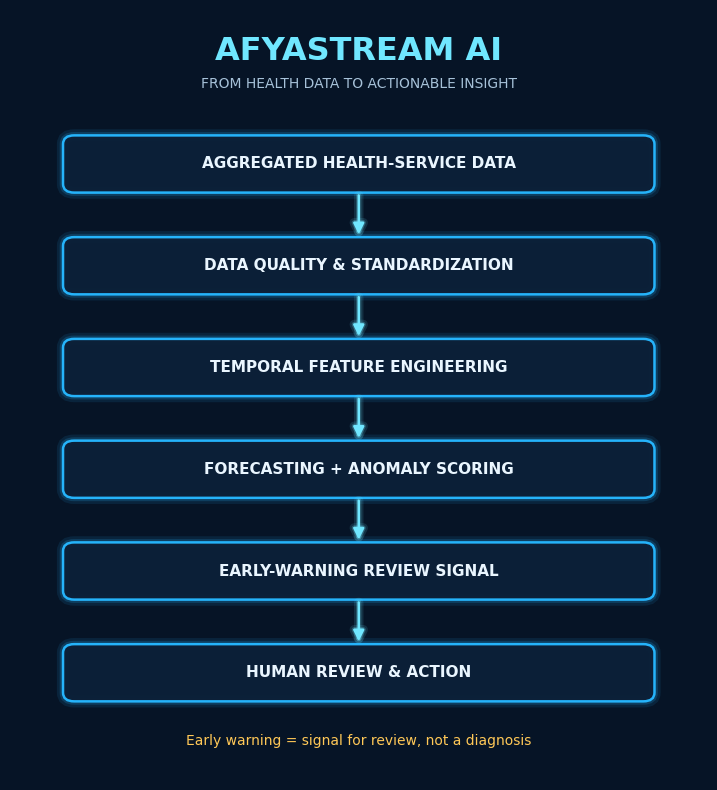

Saved: /content/afya_stream/figures/social_visual_01.png


In [9]:
# ============================================================
# VISUALIZATION 01 — DATA TO ACTION
# ============================================================
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(9, 10))
ax.set_xlim(0, 10)
ax.set_ylim(0, 14)
ax.axis("off")

ax.text(
    5, 13.25, "AFYASTREAM AI",
    ha="center", va="center",
    fontsize=23, fontweight="bold",
    color=NEON_CYAN
)
ax.text(
    5, 12.65, "FROM HEALTH DATA TO ACTIONABLE INSIGHT",
    ha="center", va="center", fontsize=10,
    color=TEXT_MUTED
)

steps = [
    "AGGREGATED HEALTH-SERVICE DATA",
    "DATA QUALITY & STANDARDIZATION",
    "TEMPORAL FEATURE ENGINEERING",
    "FORECASTING + ANOMALY SCORING",
    "EARLY-WARNING REVIEW SIGNAL",
    "HUMAN REVIEW & ACTION"
]
ys = [11.2, 9.35, 7.5, 5.65, 3.8, 1.95]

for y, label in zip(ys, steps):
    box = FancyBboxPatch(
        (0.8, y - 0.48), 8.4, 0.96,
        boxstyle="round,pad=0.04,rounding_size=0.16",
        facecolor=PANEL_BG, edgecolor=NEON_BLUE,
        linewidth=1.8, alpha=0.98
    )
    ax.add_patch(box)
    ax.text(
        5, y, label, ha="center", va="center",
        fontsize=11, fontweight="bold", color=TEXT_LIGHT
    )

for y1, y2 in zip(ys[:-1], ys[1:]):
    ax.add_patch(FancyArrowPatch(
        (5, y1 - 0.52), (5, y2 + 0.52),
        arrowstyle="-|>", mutation_scale=16,
        linewidth=1.8, color=NEON_CYAN
    ))

ax.text(
    5, 0.7,
    "Early warning = signal for review, not a diagnosis",
    ha="center", va="center", fontsize=10,
    color=WARNING_AMBER
)

out = FIGURES_DIR / "social_visual_01.png"
apply_neon_style(fig)
fig.savefig(out, dpi=200, bbox_inches="tight")
apply_neon_style(fig)
plt.show()
print("Saved:", out)

## STAGE 7 — SPARK BRONZE → SILVER

In [10]:
# ============================================================
# STAGE 7 — SPARK BRONZE → SILVER
# ============================================================
# Project: AfyaStream AI
#
# Lengo:
#   1. Kusoma Bronze dataset kwa Spark.
#   2. Kusoma raw fields kama strings ili kuepuka schema/
#      casting surprises kwenye CSV.
#   3. Ku-parse dates, demand na boolean fields explicitly.
#   4. Kufanya diagnostic checks kabla ya filtering.
#   5. Kuondoa records invalid tu.
#   6. Kuunda Silver analytical layer.
#   7. Kuhifadhi Silver kama Parquet.
#
# IMPORTANT:
#   - Silver yenye 0 rows haitakubaliwa.
#   - Lag/rolling features zitaanza Stage 8.
# ============================================================


# ------------------------------------------------------------
# 7.1 IMPORTS
# ------------------------------------------------------------

import os
import json
import pandas as pd

from pyspark.sql import (
    SparkSession,
    functions as F,
    types as T,
)


# ------------------------------------------------------------
# 7.2 PATHS
# ------------------------------------------------------------

BRONZE_FILE = (
    "/content/afya_stream/bronze/"
    "health_service_timeseries_bronze.csv"
)

SILVER_DIR = (
    "/content/afya_stream/silver"
)

SILVER_PARQUET = (
    SILVER_DIR
    + "/health_service_timeseries_silver"
)

SILVER_CSV = (
    SILVER_DIR
    + "/health_service_timeseries_silver_csv"
)

SILVER_AUDIT_FILE = (
    "/content/afya_stream/audit/"
    "silver_quality_report.json"
)


os.makedirs(
    SILVER_DIR,
    exist_ok=True
)

os.makedirs(
    "/content/afya_stream/audit",
    exist_ok=True
)


# ------------------------------------------------------------
# 7.3 START
# ------------------------------------------------------------

print("=" * 75)
print("STAGE 7 — SPARK BRONZE → SILVER")
print("=" * 75)


# ------------------------------------------------------------
# 7.4 CHECK INPUT
# ------------------------------------------------------------

if "bronze_health_df" not in globals():

    raise RuntimeError(
        "bronze_health_df is missing. "
        "Run Stage 6 first."
    )


if not os.path.exists(
    BRONZE_FILE
):

    raise FileNotFoundError(
        "Bronze file not found:\n"
        + BRONZE_FILE
    )


print(
    "\n✅ Bronze input file found:"
)

print(
    BRONZE_FILE
)


# ------------------------------------------------------------
# 7.5 CREATE / REUSE SPARK
# ------------------------------------------------------------

if "spark" not in globals():

    spark = (
        SparkSession
        .builder
        .appName(
            "AfyaStreamAI_Stage7_Silver"
        )
        .config(
            "spark.sql.shuffle.partitions",
            "8"
        )
        .getOrCreate()
    )

else:

    spark.conf.set(
        "spark.sql.shuffle.partitions",
        "8"
    )


print(
    "\nSpark version:",
    spark.version
)


# ------------------------------------------------------------
# 7.6 READ BRONZE AS RAW STRINGS
# ------------------------------------------------------------
# Hapa tunakwepa matatizo ya CSV schema inference.
# Kila field itaparsiwa explicitly baadaye.

print(
    "\n[1] Reading Bronze as raw strings..."
)

bronze_raw_df = (
    spark.read
    .option(
        "header",
        True
    )
    .option(
        "inferSchema",
        False
    )
    .option(
        "multiLine",
        False
    )
    .option(
        "escape",
        '"'
    )
    .option(
        "quote",
        '"'
    )
    .csv(
        BRONZE_FILE
    )
)


bronze_input_count = (
    bronze_raw_df.count()
)


print(
    f"Bronze Spark rows: "
    f"{bronze_input_count:,}"
)


if bronze_input_count == 0:

    raise RuntimeError(
        "Spark loaded zero Bronze rows."
    )


# ------------------------------------------------------------
# 7.7 CHECK COLUMNS
# ------------------------------------------------------------

required_columns = [
    "record_id",
    "date",
    "month",
    "facility_id",
    "facility_name",
    "service_type",
    "demand",
    "region",
    "council",
    "facility_type",
    "hospital_level",
    "ownership",
    "operating_status",
    "source_mode",
    "is_simulated",
    "anomaly_injected",
    "featured_hospital",
    "dar_es_salaam_focus",
    "data_quality_status",
    "bronze_layer",
    "bronze_ingestion_time_utc",
]


missing_columns = [
    col
    for col in required_columns
    if col not in bronze_raw_df.columns
]


if missing_columns:

    raise RuntimeError(
        "Required Bronze columns missing: "
        + ", ".join(missing_columns)
    )


print(
    "✅ Required Bronze columns detected."
)


# ------------------------------------------------------------
# 7.8 TRIM RAW STRING COLUMNS
# ------------------------------------------------------------

string_columns = [
    "record_id",
    "date",
    "month",
    "facility_id",
    "facility_name",
    "service_type",
    "region",
    "council",
    "facility_type",
    "hospital_level",
    "ownership",
    "operating_status",
    "source_mode",
    "is_simulated",
    "anomaly_injected",
    "featured_hospital",
    "dar_es_salaam_focus",
    "data_quality_status",
    "bronze_layer",
    "bronze_ingestion_time_utc",
]


raw_df = bronze_raw_df


for col_name in string_columns:

    raw_df = raw_df.withColumn(
        col_name,
        F.trim(
            F.col(
                col_name
            )
        )
    )


# ------------------------------------------------------------
# 7.9 EXPLICIT DATE PARSING
# ------------------------------------------------------------
# Tunaleta first 10 characters ili hata kama value
# imehifadhiwa kama timestamp-like string, iingie vizuri.

parsed_df = (
    raw_df

    .withColumn(
        "date_parsed",
        F.to_date(
            F.substring(
                F.col("date"),
                1,
                10
            ),
            "yyyy-MM-dd"
        )
    )

    .withColumn(
        "month_parsed",
        F.to_date(
            F.substring(
                F.col("month"),
                1,
                10
            ),
            "yyyy-MM-dd"
        )
    )

    .withColumn(
        "demand_parsed",
        F.regexp_replace(
            F.col("demand"),
            ",",
            ""
        ).cast(
            T.DoubleType()
        )
    )
)


# ------------------------------------------------------------
# 7.10 DIAGNOSTIC CHECKS BEFORE FILTERING
# ------------------------------------------------------------

print(
    "\n" + "=" * 75
)

print(
    "PRE-FILTER DIAGNOSTIC"
)

print(
    "=" * 75
)


total_rows = (
    parsed_df.count()
)


# Facility ID
valid_facility_id = (
    parsed_df
    .filter(
        F.col("facility_id").isNotNull()
    )
    .filter(
        F.length(
            F.trim(
                F.col("facility_id")
            )
        ) > 0
    )
    .count()
)


# Facility name
valid_facility_name = (
    parsed_df
    .filter(
        F.col("facility_name").isNotNull()
    )
    .filter(
        F.length(
            F.trim(
                F.col("facility_name")
            )
        ) > 0
    )
    .count()
)


# Service type
valid_service_type = (
    parsed_df
    .filter(
        F.col("service_type").isNotNull()
    )
    .filter(
        F.length(
            F.trim(
                F.col("service_type")
            )
        ) > 0
    )
    .count()
)


# Region
valid_region = (
    parsed_df
    .filter(
        F.col("region").isNotNull()
    )
    .filter(
        F.length(
            F.trim(
                F.col("region")
            )
        ) > 0
    )
    .count()
)


# Date
valid_date = (
    parsed_df
    .filter(
        F.col("date_parsed").isNotNull()
    )
    .count()
)


# Month
valid_month = (
    parsed_df
    .filter(
        F.col("month_parsed").isNotNull()
    )
    .count()
)


# Demand
valid_demand = (
    parsed_df
    .filter(
        F.col("demand_parsed").isNotNull()
    )
    .count()
)


# Non-negative demand
valid_nonnegative_demand = (
    parsed_df
    .filter(
        F.col("demand_parsed").isNotNull()
    )
    .filter(
        F.col("demand_parsed") >= 0
    )
    .count()
)


print(
    f"Total rows                  : "
    f"{total_rows:,}"
)

print(
    f"Valid facility_id           : "
    f"{valid_facility_id:,}"
)

print(
    f"Valid facility_name         : "
    f"{valid_facility_name:,}"
)

print(
    f"Valid service_type          : "
    f"{valid_service_type:,}"
)

print(
    f"Valid region                : "
    f"{valid_region:,}"
)

print(
    f"Valid date                  : "
    f"{valid_date:,}"
)

print(
    f"Valid month                 : "
    f"{valid_month:,}"
)

print(
    f"Valid demand                : "
    f"{valid_demand:,}"
)

print(
    f"Non-negative demand         : "
    f"{valid_nonnegative_demand:,}"
)


# ------------------------------------------------------------
# 7.11 SHOW SAMPLE OF PARSED DATA
# ------------------------------------------------------------

print(
    "\nParsed sample:"
)

display(
    parsed_df
    .select(
        "facility_id",
        "facility_name",
        "service_type",
        "date",
        "date_parsed",
        "month",
        "month_parsed",
        "demand",
        "demand_parsed",
        "region",
    )
    .limit(10)
    .toPandas()
)


# ------------------------------------------------------------
# 7.12 BUILD SILVER DATASET
# ------------------------------------------------------------

print(
    "\n[2] Building Silver dataset..."
)


silver_df = (
    parsed_df

    # Replace original date/month with parsed versions
    .drop(
        "date",
        "month",
        "demand"
    )

    .withColumnRenamed(
        "date_parsed",
        "date"
    )

    .withColumnRenamed(
        "month_parsed",
        "month"
    )

    .withColumnRenamed(
        "demand_parsed",
        "demand"
    )
)


# ------------------------------------------------------------
# 7.13 SAFE BOOLEAN CONVERSION
# ------------------------------------------------------------

def safe_boolean(
    column_name
):

    normalized = (
        F.lower(
            F.trim(
                F.col(
                    column_name
                )
            )
        )
    )

    return (
        F.when(
            normalized.isin(
                "true",
                "1",
                "yes"
            ),
            F.lit(True)
        )
        .when(
            normalized.isin(
                "false",
                "0",
                "no"
            ),
            F.lit(False)
        )
        .otherwise(
            F.lit(False)
        )
    )


for boolean_column in [
    "is_simulated",
    "anomaly_injected",
    "featured_hospital",
    "dar_es_salaam_focus",
]:

    silver_df = silver_df.withColumn(
        boolean_column,
        safe_boolean(
            boolean_column
        )
    )


# ------------------------------------------------------------
# 7.14 CRITICAL VALIDITY FLAG
# ------------------------------------------------------------

silver_df = (
    silver_df

    .withColumn(
        "_valid_facility_id",
        (
            F.col("facility_id").isNotNull()
            &
            (
                F.length(
                    F.trim(
                        F.col("facility_id")
                    )
                ) > 0
            )
        )
    )

    .withColumn(
        "_valid_facility_name",
        (
            F.col("facility_name").isNotNull()
            &
            (
                F.length(
                    F.trim(
                        F.col("facility_name")
                    )
                ) > 0
            )
        )
    )

    .withColumn(
        "_valid_service_type",
        (
            F.col("service_type").isNotNull()
            &
            (
                F.length(
                    F.trim(
                        F.col("service_type")
                    )
                ) > 0
            )
        )
    )

    .withColumn(
        "_valid_region",
        (
            F.col("region").isNotNull()
            &
            (
                F.length(
                    F.trim(
                        F.col("region")
                    )
                ) > 0
            )
        )
    )

    .withColumn(
        "_valid_month",
        F.col("month").isNotNull()
    )

    .withColumn(
        "_valid_demand",
        (
            F.col("demand").isNotNull()
            &
            (
                F.col("demand") >= 0
            )
        )
    )
)


# ------------------------------------------------------------
# 7.15 COUNT RECORDS FAILING EACH CONDITION
# ------------------------------------------------------------

print(
    "\n" + "=" * 75
)

print(
    "VALIDATION FAILURES"
)

print(
    "=" * 75
)


failure_columns = [
    "_valid_facility_id",
    "_valid_facility_name",
    "_valid_service_type",
    "_valid_region",
    "_valid_month",
    "_valid_demand",
]


for flag_column in failure_columns:

    failed_count = (
        silver_df
        .filter(
            F.col(flag_column)
            == False
        )
        .count()
    )

    print(
        f"{flag_column:<28}: "
        f"{failed_count:,}"
    )


# ------------------------------------------------------------
# 7.16 APPLY CRITICAL FILTERS
# ------------------------------------------------------------

before_filter = (
    silver_df.count()
)


silver_df = (
    silver_df
    .filter(
        F.col("_valid_facility_id")
        == True
    )
    .filter(
        F.col("_valid_facility_name")
        == True
    )
    .filter(
        F.col("_valid_service_type")
        == True
    )
    .filter(
        F.col("_valid_region")
        == True
    )
    .filter(
        F.col("_valid_month")
        == True
    )
    .filter(
        F.col("_valid_demand")
        == True
    )
)


after_filter = (
    silver_df.count()
)


print(
    "\nRows removed by critical filters: "
    f"{before_filter - after_filter:,}"
)

print(
    f"Rows remaining: "
    f"{after_filter:,}"
)


# ------------------------------------------------------------
# 7.17 STOP IF ZERO
# ------------------------------------------------------------

if after_filter == 0:

    raise RuntimeError(
        "\n"
        "STAGE 7 STOPPED: Silver dataset has 0 rows.\n"
        "The diagnostic table above shows which field caused "
        "the records to fail.\n"
        "No empty Silver dataset will be saved."
    )


# ------------------------------------------------------------
# 7.18 REMOVE DIAGNOSTIC COLUMNS
# ------------------------------------------------------------

silver_df = silver_df.drop(
    *failure_columns
)


# ------------------------------------------------------------
# 7.19 ADD CALENDAR FEATURES
# ------------------------------------------------------------

silver_df = (
    silver_df

    .withColumn(
        "year",
        F.year(
            F.col("month")
        )
    )

    .withColumn(
        "month_num",
        F.month(
            F.col("month")
        )
    )

    .withColumn(
        "quarter",
        F.quarter(
            F.col("month")
        )
    )

    .withColumn(
        "year_month",
        F.date_format(
            F.col("month"),
            "yyyy-MM"
        )
    )

    .withColumn(
        "month_name",
        F.date_format(
            F.col("month"),
            "MMMM"
        )
    )

    .withColumn(
        "source_layer",
        F.lit("SILVER")
    )
)


# ------------------------------------------------------------
# 7.20 GEOGRAPHIC FLAGS
# ------------------------------------------------------------

silver_df = (
    silver_df

    .withColumn(
        "is_dar_es_salaam",
        F.when(
            F.lower(
                F.col("region")
            ).contains(
                "dar es salaam"
            ),
            F.lit(True)
        )
        .otherwise(
            F.lit(False)
        )
    )

    .withColumn(
        "is_operating",
        F.when(
            F.lower(
                F.trim(
                    F.col(
                        "operating_status"
                    )
                )
            ) == "operating",
            F.lit(True)
        )
        .otherwise(
            F.lit(False)
        )
    )
)


# ------------------------------------------------------------
# 7.21 BUSINESS KEY CHECK
# ------------------------------------------------------------

business_keys = [
    "facility_id",
    "service_type",
    "month",
]


duplicate_groups = (
    silver_df
    .groupBy(
        *business_keys
    )
    .count()
    .filter(
        F.col("count") > 1
    )
)


duplicate_group_count = (
    duplicate_groups.count()
)


duplicate_row_count = (
    duplicate_groups
    .agg(
        F.sum(
            "count"
        ).alias(
            "duplicate_rows"
        )
    )
    .collect()[0][
        "duplicate_rows"
    ]
)


if duplicate_row_count is None:

    duplicate_row_count = 0


print(
    "\nDuplicate business-key groups: "
    f"{duplicate_group_count:,}"
)

print(
    "Duplicate business-key rows: "
    f"{int(duplicate_row_count):,}"
)


# ------------------------------------------------------------
# 7.22 DEDUPLICATE
# ------------------------------------------------------------

silver_df = (
    silver_df
    .dropDuplicates(
        business_keys
    )
)


silver_rows = (
    silver_df.count()
)


print(
    f"Rows after business-key deduplication: "
    f"{silver_rows:,}"
)


# ------------------------------------------------------------
# 7.23 NULL AUDIT
# ------------------------------------------------------------

critical_columns = [
    "facility_id",
    "facility_name",
    "service_type",
    "month",
    "demand",
    "region",
]


null_expressions = []

for column_name in critical_columns:

    null_expressions.append(
        F.sum(
            F.col(
                column_name
            ).isNull().cast("int")
        ).alias(
            column_name
        )
    )


null_result = (
    silver_df
    .agg(
        *null_expressions
    )
    .collect()[0]
    .asDict()
)


total_nulls = int(
    sum(
        int(value or 0)
        for value in null_result.values()
    )
)


# ------------------------------------------------------------
# 7.24 NEGATIVE DEMAND AUDIT
# ------------------------------------------------------------

negative_demand = (
    silver_df
    .filter(
        F.col("demand") < 0
    )
    .count()
)


# ------------------------------------------------------------
# 7.25 CORE COUNTS
# ------------------------------------------------------------

unique_facilities = (
    silver_df
    .select(
        "facility_id"
    )
    .distinct()
    .count()
)


unique_services = (
    silver_df
    .select(
        "service_type"
    )
    .distinct()
    .count()
)


unique_months = (
    silver_df
    .select(
        "month"
    )
    .distinct()
    .count()
)


dar_rows = (
    silver_df
    .filter(
        F.col(
            "is_dar_es_salaam"
        )
        == True
    )
    .count()
)


featured_rows = (
    silver_df
    .filter(
        F.col(
            "featured_hospital"
        )
        == True
    )
    .count()
)


# ------------------------------------------------------------
# 7.26 FINAL QUALITY GATE
# ------------------------------------------------------------

if (
    silver_rows <= 0
    or total_nulls > 0
    or negative_demand > 0
):

    raise RuntimeError(
        "Silver quality gate failed. "
        "Dataset will not be saved."
    )


# ------------------------------------------------------------
# 7.27 SORT
# ------------------------------------------------------------

silver_df = (
    silver_df
    .orderBy(
        "month",
        "facility_id",
        "service_type"
    )
)


# ------------------------------------------------------------
# 7.28 CACHE
# ------------------------------------------------------------

silver_df = (
    silver_df.cache()
)

_ = silver_df.count()


# ------------------------------------------------------------
# 7.29 SOURCE MODE
# ------------------------------------------------------------

print(
    "\nSource mode distribution:"
)

display(
    silver_df
    .groupBy(
        "source_mode"
    )
    .count()
    .orderBy(
        F.desc("count")
    )
    .toPandas()
)


# ------------------------------------------------------------
# 7.30 SERVICE TYPE SUMMARY
# ------------------------------------------------------------

print(
    "\nService type distribution:"
)

display(
    silver_df
    .groupBy(
        "service_type"
    )
    .count()
    .orderBy(
        F.desc("count")
    )
    .toPandas()
)


# ------------------------------------------------------------
# 7.31 SILVER SUMMARY
# ------------------------------------------------------------

print(
    "\n" + "=" * 75
)

print(
    "SILVER DATASET SUMMARY"
)

print(
    "=" * 75
)

print(
    f"Rows                 : "
    f"{silver_rows:,}"
)

print(
    f"Facilities           : "
    f"{unique_facilities:,}"
)

print(
    f"Service types        : "
    f"{unique_services:,}"
)

print(
    f"Months               : "
    f"{unique_months:,}"
)

print(
    f"Dar es Salaam rows   : "
    f"{dar_rows:,}"
)

print(
    f"Featured rows        : "
    f"{featured_rows:,}"
)

print(
    f"Critical nulls       : "
    f"{total_nulls:,}"
)

print(
    f"Negative demand      : "
    f"{negative_demand:,}"
)


# ------------------------------------------------------------
# 7.32 FEATURED HOSPITAL SUMMARY
# ------------------------------------------------------------

print(
    "\nFeatured hospital summary:"
)

featured_summary = (
    silver_df
    .filter(
        F.col(
            "featured_hospital"
        ) == True
    )
    .groupBy(
        "facility_name"
    )
    .agg(
        F.count("*").alias(
            "records"
        ),
        F.sum(
            "demand"
        ).alias(
            "total_demand"
        )
    )
    .orderBy(
        F.desc(
            "total_demand"
        )
    )
    .limit(20)
    .toPandas()
)


display(
    featured_summary
)


# ------------------------------------------------------------
# 7.33 SPARK SCHEMA
# ------------------------------------------------------------

print(
    "\nSilver Spark schema:"
)

silver_df.printSchema()


# ------------------------------------------------------------
# 7.34 SAVE SILVER PARQUET
# ------------------------------------------------------------

print(
    "\n[4] Saving Silver Parquet..."
)

(
    silver_df
    .write
    .mode(
        "overwrite"
    )
    .parquet(
        SILVER_PARQUET
    )
)


print(
    "✅ Silver Parquet saved:"
)

print(
    SILVER_PARQUET
)


# ------------------------------------------------------------
# 7.35 SAVE SILVER CSV COPY
# ------------------------------------------------------------

print(
    "\n[5] Saving Silver CSV copy..."
)

(
    silver_df
    .coalesce(1)
    .write
    .mode(
        "overwrite"
    )
    .option(
        "header",
        True
    )
    .csv(
        SILVER_CSV
    )
)


print(
    "✅ Silver CSV saved:"
)

print(
    SILVER_CSV
)


# ------------------------------------------------------------
# 7.36 AUDIT REPORT
# ------------------------------------------------------------

quality_report = {

    "project": "AfyaStream AI",

    "stage": (
        "Stage 7 - Spark Bronze to Silver"
    ),

    "spark_version": spark.version,

    "bronze_input_rows": int(
        bronze_input_count
    ),

    "silver_final_rows": int(
        silver_rows
    ),

    "unique_facilities": int(
        unique_facilities
    ),

    "unique_services": int(
        unique_services
    ),

    "unique_months": int(
        unique_months
    ),

    "dar_es_salaam_rows": int(
        dar_rows
    ),

    "featured_hospital_rows": int(
        featured_rows
    ),

    "critical_null_values_remaining": int(
        total_nulls
    ),

    "negative_demand_remaining": int(
        negative_demand
    ),

    "duplicate_business_key_groups": int(
        duplicate_group_count
    ),

    "duplicate_business_key_rows_detected": int(
        duplicate_row_count
    ),

    "rows_removed_by_critical_filters": int(
        before_filter
        - after_filter
    ),

    "rows_after_deduplication": int(
        silver_rows
    ),

    "business_keys": business_keys,

    "silver_parquet": SILVER_PARQUET,

    "silver_csv": SILVER_CSV,

    "notes": [
        "Bronze CSV was read as raw strings to avoid CSV schema surprises.",
        "Dates and demand were explicitly parsed.",
        "Boolean flags were converted using string normalization.",
        "Critical validity conditions were evaluated before filtering.",
        "An empty Silver dataset is treated as a failure.",
        "Lag and rolling features are deferred to Stage 8.",
    ],
}


with open(
    SILVER_AUDIT_FILE,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        quality_report,
        f,
        indent=2,
        ensure_ascii=False
    )


# ------------------------------------------------------------
# 7.37 SILVER PREVIEW
# ------------------------------------------------------------

preview_columns = [
    "month",
    "facility_id",
    "facility_name",
    "service_type",
    "demand",
    "region",
    "hospital_level",
    "ownership",
    "is_dar_es_salaam",
    "featured_hospital",
    "is_simulated",
    "anomaly_injected",
    "source_layer",
]


print(
    "\nSilver preview:"
)

display(
    silver_df
    .select(
        *preview_columns
    )
    .limit(20)
    .toPandas()
)


# ------------------------------------------------------------
# 7.38 NEXT-STAGE OBJECT
# ------------------------------------------------------------

silver_health_df = (
    silver_df
)


# ------------------------------------------------------------
# 7.39 FINAL
# ------------------------------------------------------------

print(
    "\n" + "=" * 75
)

print(
    "✅ STAGE 7 COMPLETED SUCCESSFULLY"
)

print(
    "=" * 75
)

print(
    f"silver_health_df shape = "
    f"({silver_rows:,}, "
    f"{len(silver_health_df.columns)})"
)

print(
    "\nSilver Parquet:"
)

print(
    SILVER_PARQUET
)

print(
    "\nSilver audit report:"
)

print(
    SILVER_AUDIT_FILE
)

STAGE 7 — SPARK BRONZE → SILVER

✅ Bronze input file found:
/content/afya_stream/bronze/health_service_timeseries_bronze.csv

Spark version: 4.0.4

[1] Reading Bronze as raw strings...
Bronze Spark rows: 92,928
✅ Required Bronze columns detected.

PRE-FILTER DIAGNOSTIC
Total rows                  : 92,928
Valid facility_id           : 92,928
Valid facility_name         : 92,928
Valid service_type          : 92,928
Valid region                : 92,928
Valid date                  : 92,928
Valid month                 : 92,928
Valid demand                : 92,928
Non-negative demand         : 92,928

Parsed sample:


,facility_id,facility_name,service_type,date,date_parsed,month,month_parsed,demand,demand_parsed,region
0,100010-8,BURHANI CHARITABLE,Emergency Visits,2022-01-01,2022-01-01,2022-01-01,2022-01-01,279,279.0,Dar es Salaam Region
1,100010-8,BURHANI CHARITABLE,Inpatient Admissions,2022-01-01,2022-01-01,2022-01-01,2022-01-01,600,600.0,Dar es Salaam Region
2,100010-8,BURHANI CHARITABLE,Maternal Health Services,2022-01-01,2022-01-01,2022-01-01,2022-01-01,444,444.0,Dar es Salaam Region
3,100010-8,BURHANI CHARITABLE,Outpatient Visits,2022-01-01,2022-01-01,2022-01-01,2022-01-01,2577,2577.0,Dar es Salaam Region
4,100047-0,AGA KHAN,Emergency Visits,2022-01-01,2022-01-01,2022-01-01,2022-01-01,249,249.0,Dar es Salaam Region
5,100047-0,AGA KHAN,Inpatient Admissions,2022-01-01,2022-01-01,2022-01-01,2022-01-01,560,560.0,Dar es Salaam Region
6,100047-0,AGA KHAN,Maternal Health Services,2022-01-01,2022-01-01,2022-01-01,2022-01-01,326,326.0,Dar es Salaam Region
7,100047-0,AGA KHAN,Outpatient Visits,2022-01-01,2022-01-01,2022-01-01,2022-01-01,2397,2397.0,Dar es Salaam Region
8,100052-0,H.H AGAKHAN,Emergency Visits,2022-01-01,2022-01-01,2022-01-01,2022-01-01,171,171.0,Mwanza Region
9,100052-0,H.H AGAKHAN,Inpatient Admissions,2022-01-01,2022-01-01,2022-01-01,2022-01-01,338,338.0,Mwanza Region



[2] Building Silver dataset...

VALIDATION FAILURES
_valid_facility_id          : 0
_valid_facility_name        : 0
_valid_service_type         : 0
_valid_region               : 0
_valid_month                : 0
_valid_demand               : 0

Rows removed by critical filters: 0
Rows remaining: 92,928

Duplicate business-key groups: 0
Duplicate business-key rows: 0
Rows after business-key deduplication: 92,928

Source mode distribution:


,source_mode,count
0,SIMULATED,92928



Service type distribution:


...


SILVER DATASET SUMMARY
Rows                 : 92,928
Facilities           : 484
Service types        : 4
Months               : 48
Dar es Salaam rows   : 14,976
Featured rows        : 3,648
Critical nulls       : 0
Negative demand      : 0

Featured hospital summary:


,facility_name,records,total_demand
0,MBEYA,576,497275.0
1,JAKAYA KIKWETE CARDIAC INSTITUTE,192,348337.0
2,MUHIMBILI NATIONAL HOSPITAL - MLOGANZILA,192,314639.0
3,MUHIMBILI ORTHOPAEDIC INSTITUTE (MOI),192,293592.0
4,Benjamini Mkapa,192,268599.0
5,MUHIMBILI,192,260553.0
6,OCEAN ROAD CANCER INSTITUTE (ORCI),192,255336.0
7,LUGALO,192,245364.0
8,AMANA,192,189076.0
9,BUGANDO MEDICAL CENTRE (BMC),192,179785.0



Silver Spark schema:
root
 |-- facility_id: string (nullable = true)
 |-- facility_name: string (nullable = true)
 |-- service_type: string (nullable = true)
 |-- region: string (nullable = true)
 |-- council: string (nullable = true)
 |-- facility_type: string (nullable = true)
 |-- hospital_level: string (nullable = true)
 |-- ownership: string (nullable = true)
 |-- operating_status: string (nullable = true)
 |-- source_mode: string (nullable = true)
 |-- is_simulated: boolean (nullable = false)
 |-- anomaly_injected: boolean (nullable = false)
 |-- featured_hospital: boolean (nullable = false)
 |-- dar_es_salaam_focus: boolean (nullable = false)
 |-- record_id: string (nullable = true)
 |-- data_quality_status: string (nullable = true)
 |-- bronze_ingestion_time_utc: string (nullable = true)
 |-- bronze_layer: string (nullable = true)
 |-- date: date (nullable = true)
 |-- month: date (nullable = true)
 |-- demand: double (nullable = true)
 |-- year: integer (nullable = true)
 |--

,month,facility_id,facility_name,service_type,demand,region,hospital_level,ownership,is_dar_es_salaam,featured_hospital,is_simulated,anomaly_injected,source_layer
0,2022-01-01,100010-8,BURHANI CHARITABLE,Emergency Visits,279.0,Dar es Salaam Region,Regional,Private,True,False,True,False,SILVER
1,2022-01-01,100010-8,BURHANI CHARITABLE,Inpatient Admissions,600.0,Dar es Salaam Region,Regional,Private,True,False,True,False,SILVER
2,2022-01-01,100010-8,BURHANI CHARITABLE,Maternal Health Services,444.0,Dar es Salaam Region,Regional,Private,True,False,True,False,SILVER
3,2022-01-01,100010-8,BURHANI CHARITABLE,Outpatient Visits,2577.0,Dar es Salaam Region,Regional,Private,True,False,True,False,SILVER
4,2022-01-01,100047-0,AGA KHAN,Emergency Visits,249.0,Dar es Salaam Region,Zonal,Private,True,True,True,False,SILVER
5,2022-01-01,100047-0,AGA KHAN,Inpatient Admissions,560.0,Dar es Salaam Region,Zonal,Private,True,True,True,False,SILVER
6,2022-01-01,100047-0,AGA KHAN,Maternal Health Services,326.0,Dar es Salaam Region,Zonal,Private,True,True,True,False,SILVER
7,2022-01-01,100047-0,AGA KHAN,Outpatient Visits,2397.0,Dar es Salaam Region,Zonal,Private,True,True,True,False,SILVER
8,2022-01-01,100052-0,H.H AGAKHAN,Emergency Visits,171.0,Mwanza Region,Regional,Private,False,False,True,False,SILVER
9,2022-01-01,100052-0,H.H AGAKHAN,Inpatient Admissions,338.0,Mwanza Region,Regional,Private,False,False,True,False,SILVER



✅ STAGE 7 COMPLETED SUCCESSFULLY
silver_health_df shape = (92,928, 29)

Silver Parquet:
/content/afya_stream/silver/health_service_timeseries_silver

Silver audit report:
/content/afya_stream/audit/silver_quality_report.json


# SOCIAL MEDIA — POST 02/13

## **Data nyingi. Lakini je, tunazigeuza kuwa taarifa kwa wakati?**

Data inaweza kuwa nyingi, kutoka maeneo mengi na vipindi vingi. Bila data engineering, inaweza kubaki kuwa jedwali badala ya kuwa signal.

**AfyaStream AI inalenga kuvuka hatua hiyo.**

**Uwazi wa data:** demand inayotumika katika modelling ya toleo hili ni simulation.

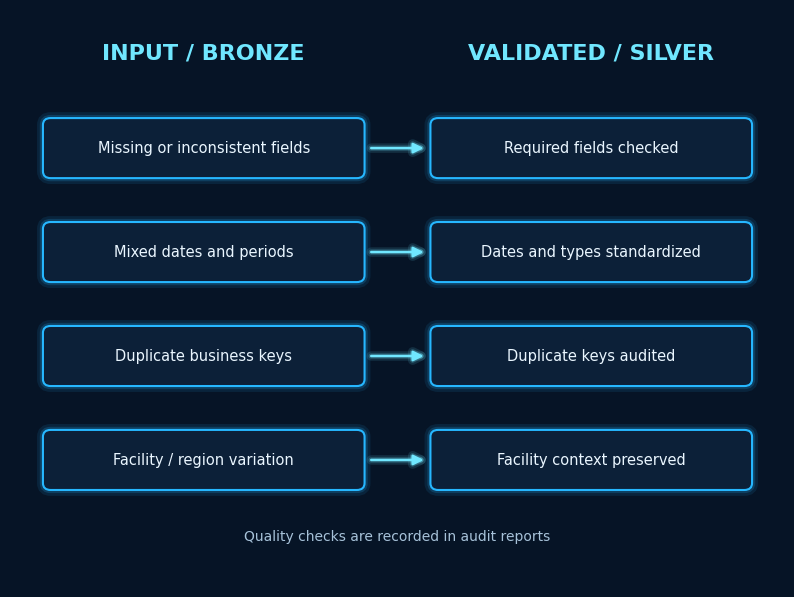

Saved: /content/afya_stream/figures/social_visual_02.png


In [11]:
# ============================================================
# VISUALIZATION 02 — RAW DATA TO ACTIONABLE DATA
# ============================================================
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(10, 7.5))
ax.set_xlim(0, 12)
ax.set_ylim(0, 10)
ax.axis("off")

ax.text(3, 9.15, "INPUT / BRONZE", ha="center", fontsize=16,
        fontweight="bold", color=NEON_CYAN)
ax.text(9, 9.15, "VALIDATED / SILVER", ha="center", fontsize=16,
        fontweight="bold", color=NEON_CYAN)

left = [
    "Missing or inconsistent fields",
    "Mixed dates and periods",
    "Duplicate business keys",
    "Facility / region variation"
]
right = [
    "Required fields checked",
    "Dates and types standardized",
    "Duplicate keys audited",
    "Facility context preserved"
]
ys = [7.6, 5.8, 4.0, 2.2]

for y, left_label, right_label in zip(ys, left, right):
    for x, label in [(0.55, left_label), (6.55, right_label)]:
        box = FancyBboxPatch(
            (x, y - 0.48), 4.9, 0.96,
            boxstyle="round,pad=0.04,rounding_size=0.12",
            facecolor=PANEL_BG, edgecolor=NEON_BLUE,
            linewidth=1.5
        )
        ax.add_patch(box)
        ax.text(
            x + 2.45, y, label,
            ha="center", va="center", fontsize=10.5,
            color=TEXT_LIGHT, wrap=True
        )
    ax.add_patch(FancyArrowPatch(
        (5.55, y), (6.45, y),
        arrowstyle="-|>", mutation_scale=15,
        linewidth=1.8, color=NEON_CYAN
    ))

ax.text(
    6, 0.8,
    "Quality checks are recorded in audit reports",
    ha="center", fontsize=10, color=TEXT_MUTED
)

out = FIGURES_DIR / "social_visual_02.png"
apply_neon_style(fig)
fig.savefig(out, dpi=200, bbox_inches="tight")
apply_neon_style(fig)
plt.show()
print("Saved:", out)

## STAGE 8 — GOLD LAYER & TEMPORAL FEATURES

In [12]:
# ============================================================
# STAGE 8 — GOLD + TEMPORAL FEATURE ENGINEERING
# ============================================================
# Project: AfyaStream AI
#
# Lengo:
#   1. Kuchukua Silver dataset.
#   2. Kutengeneza temporal features.
#   3. Kutengeneza lag_1, lag_2, lag_3.
#   4. Kutengeneza rolling mean/std za miezi iliyopita.
#   5. Kutengeneza growth rate.
#   6. Kutengeneza seasonality features.
#   7. Kutengeneza target ya mwezi unaofuata.
#   8. Kuhifadhi Gold feature table.
#
# IMPORTANT:
#   - Current demand haitumiki katika rolling windows.
#   - Rolling windows zinaangalia historia tu.
#   - anomaly_injected SI feature ya model.
#   - Gold ndiyo analytical feature layer.
# ============================================================


# ------------------------------------------------------------
# 8.1 IMPORTS
# ------------------------------------------------------------

import os
import json
import pandas as pd

from pyspark.sql import (
    functions as F,
)
from pyspark.sql.window import (
    Window,
)


# ------------------------------------------------------------
# 8.2 START
# ------------------------------------------------------------

print("=" * 75)
print("STAGE 8 — GOLD + TEMPORAL FEATURE ENGINEERING")
print("=" * 75)


# ------------------------------------------------------------
# 8.3 CHECK SILVER
# ------------------------------------------------------------

if "silver_health_df" not in globals():

    raise RuntimeError(
        "silver_health_df is missing. "
        "Run Stage 7 successfully first."
    )


gold_base_df = (
    silver_health_df
)


# ------------------------------------------------------------
# 8.4 BUSINESS PARTITION
# ------------------------------------------------------------
# Kila facility + service type ina time series yake.

partition_window = (
    Window
    .partitionBy(
        "facility_id",
        "service_type",
    )
    .orderBy(
        F.col("month")
    )
)


# ------------------------------------------------------------
# 8.5 LAG FEATURES
# ------------------------------------------------------------

print(
    "\n[1] Creating lag features..."
)


gold_df = (
    gold_base_df

    .withColumn(
        "lag_1",
        F.lag(
            "demand",
            1
        ).over(
            partition_window
        )
    )

    .withColumn(
        "lag_2",
        F.lag(
            "demand",
            2
        ).over(
            partition_window
        )
    )

    .withColumn(
        "lag_3",
        F.lag(
            "demand",
            3
        ).over(
            partition_window
        )
    )

    .withColumn(
        "lag_6",
        F.lag(
            "demand",
            6
        ).over(
            partition_window
        )
    )

    .withColumn(
        "lag_12",
        F.lag(
            "demand",
            12
        ).over(
            partition_window
        )
    )
)


# ------------------------------------------------------------
# 8.6 PREVIOUS-MONTH ROLLING FEATURES
# ------------------------------------------------------------
# IMPORTANT:
#   rowsBetween(-3, -1)
# means:
#   previous 3 months ONLY.
#
# Current demand is excluded.
# Therefore no direct target leakage from current observation
# into the rolling features.

rolling_3_window = (
    partition_window
    .rowsBetween(
        -3,
        -1
    )
)

rolling_6_window = (
    partition_window
    .rowsBetween(
        -6,
        -1
    )
)

rolling_12_window = (
    partition_window
    .rowsBetween(
        -12,
        -1
    )
)


print(
    "\n[2] Creating rolling features..."
)


gold_df = (
    gold_df

    .withColumn(
        "rolling_mean_3",
        F.avg(
            "demand"
        ).over(
            rolling_3_window
        )
    )

    .withColumn(
        "rolling_std_3",
        F.stddev(
            "demand"
        ).over(
            rolling_3_window
        )
    )

    .withColumn(
        "rolling_mean_6",
        F.avg(
            "demand"
        ).over(
            rolling_6_window
        )
    )

    .withColumn(
        "rolling_std_6",
        F.stddev(
            "demand"
        ).over(
            rolling_6_window
        )
    )

    .withColumn(
        "rolling_mean_12",
        F.avg(
            "demand"
        ).over(
            rolling_12_window
        )
    )

    .withColumn(
        "rolling_std_12",
        F.stddev(
            "demand"
        ).over(
            rolling_12_window
        )
    )
)


# ------------------------------------------------------------
# 8.7 GROWTH FEATURES
# ------------------------------------------------------------

print(
    "\n[3] Creating growth features..."
)


gold_df = (
    gold_df

    .withColumn(
        "growth_1m",
        F.when(
            F.col("lag_1") > 0,
            (
                F.col("demand")
                / F.col("lag_1")
            ) - 1.0
        )
        .otherwise(
            F.lit(None)
        )
    )

    .withColumn(
        "growth_3m",
        F.when(
            F.col("lag_3") > 0,
            (
                F.col("demand")
                / F.col("lag_3")
            ) - 1.0
        )
        .otherwise(
            F.lit(None)
        )
    )

    .withColumn(
        "growth_6m",
        F.when(
            F.col("lag_6") > 0,
            (
                F.col("demand")
                / F.col("lag_6")
            ) - 1.0
        )
        .otherwise(
            F.lit(None)
        )
    )
)


# ------------------------------------------------------------
# 8.8 DEVIATION FROM HISTORICAL BASELINE
# ------------------------------------------------------------

print(
    "\n[4] Creating historical-deviation features..."
)


gold_df = (
    gold_df

    .withColumn(
        "deviation_from_mean_3",
        F.when(
            F.col(
                "rolling_mean_3"
            ).isNotNull(),
            F.col("demand")
            - F.col(
                "rolling_mean_3"
            )
        )
        .otherwise(
            F.lit(None)
        )
    )

    .withColumn(
        "zscore_rolling_3",
        F.when(
            (
                F.col(
                    "rolling_std_3"
                ).isNotNull()
            )
            &
            (
                F.col(
                    "rolling_std_3"
                ) > 0
            ),
            (
                F.col("demand")
                - F.col(
                    "rolling_mean_3"
                )
            )
            /
            F.col(
                "rolling_std_3"
            )
        )
        .otherwise(
            F.lit(None)
        )
    )
)


# ------------------------------------------------------------
# 8.9 SEASONAL FEATURES
# ------------------------------------------------------------

print(
    "\n[5] Creating seasonality features..."
)


gold_df = (
    gold_df

    .withColumn(
        "month_sin",
        F.sin(
            2
            * F.lit(3.141592653589793)
            * F.col("month_num")
            / F.lit(12.0)
        )
    )

    .withColumn(
        "month_cos",
        F.cos(
            2
            * F.lit(3.141592653589793)
            * F.col("month_num")
            / F.lit(12.0)
        )
    )
)


# ------------------------------------------------------------
# 8.10 TIME INDEX
# ------------------------------------------------------------

gold_df = (
    gold_df
    .withColumn(
        "time_index",
        (
            (
                F.year(
                    F.col("month")
                )
                - F.lit(2022)
            )
            * F.lit(12)
            +
            F.month(
                F.col("month")
            )
            - F.lit(1)
        )
    )
)


# ------------------------------------------------------------
# 8.11 NEXT-MONTH TARGET
# ------------------------------------------------------------
# Lead is used only to define the forecasting target.
#
# For a row at month t:
#
#   target_next_month = demand at t+1
#
# This will later be used in train/test construction.

gold_df = (
    gold_df
    .withColumn(
        "target_next_month",
        F.lead(
            "demand",
            1
        ).over(
            partition_window
        )
    )
)


# ------------------------------------------------------------
# 8.12 FORECAST HORIZON
# ------------------------------------------------------------

gold_df = (
    gold_df
    .withColumn(
        "forecast_horizon",
        F.lit(1)
    )
)


# ------------------------------------------------------------
# 8.13 FEATURE GROUP LABEL
# ------------------------------------------------------------

gold_df = (
    gold_df
    .withColumn(
        "feature_layer",
        F.lit("GOLD_TEMPORAL")
    )
)


# ------------------------------------------------------------
# 8.14 FEATURE LIST
# ------------------------------------------------------------

temporal_feature_columns = [
    "lag_1",
    "lag_2",
    "lag_3",
    "lag_6",
    "lag_12",
    "rolling_mean_3",
    "rolling_std_3",
    "rolling_mean_6",
    "rolling_std_6",
    "rolling_mean_12",
    "rolling_std_12",
    "growth_1m",
    "growth_3m",
    "growth_6m",
    "deviation_from_mean_3",
    "zscore_rolling_3",
    "month_sin",
    "month_cos",
    "time_index",
]


# ------------------------------------------------------------
# 8.15 COUNT FEATURE COVERAGE
# ------------------------------------------------------------

print(
    "\n[6] Checking temporal feature coverage..."
)


feature_coverage = []

for column_name in temporal_feature_columns:

    non_null_count = (
        gold_df
        .filter(
            F.col(
                column_name
            ).isNotNull()
        )
        .count()
    )

    feature_coverage.append({
        "feature": column_name,
        "non_null_rows": non_null_count,
        "coverage_pct": (
            100
            * non_null_count
            / gold_df.count()
        ),
    })


feature_coverage_df = pd.DataFrame(
    feature_coverage
)


display(
    feature_coverage_df
)


# ------------------------------------------------------------
# 8.16 SUPERVISED-LEARNING READY FLAG
# ------------------------------------------------------------
# A row is ready when:
#   - target_next_month exists
#   - enough history exists for lag_3
#
# We do not require lag_12 at this point because we may use
# multiple model configurations later.

gold_df = (
    gold_df
    .withColumn(
        "supervised_ready",
        (
            F.col(
                "target_next_month"
            ).isNotNull()
            &
            F.col(
                "lag_3"
            ).isNotNull()
        )
    )
)


# ------------------------------------------------------------
# 8.17 GOLD COUNTS
# ------------------------------------------------------------

gold_rows = (
    gold_df.count()
)


supervised_rows = (
    gold_df
    .filter(
        F.col(
            "supervised_ready"
        ) == True
    )
    .count()
)


gold_facilities = (
    gold_df
    .select(
        "facility_id"
    )
    .distinct()
    .count()
)


gold_services = (
    gold_df
    .select(
        "service_type"
    )
    .distinct()
    .count()
)


gold_months = (
    gold_df
    .select(
        "month"
    )
    .distinct()
    .count()
)


# ------------------------------------------------------------
# 8.18 CHECK FEATURE LEAKAGE
# ------------------------------------------------------------
# anomaly_injected remains metadata/evaluation information.
# It is NOT part of temporal_feature_columns.

forbidden_feature_columns = [
    "anomaly_injected",
    "target_next_month",
]


leakage_check = [
    col
    for col in temporal_feature_columns
    if col in forbidden_feature_columns
]


if leakage_check:

    raise RuntimeError(
        "Potential leakage detected in feature list: "
        + str(leakage_check)
    )


print(
    "\n✅ Feature leakage check passed."
)


# ------------------------------------------------------------
# 8.19 SAVE GOLD
# ------------------------------------------------------------

GOLD_DIR = (
    "/content/afya_stream/gold"
)

GOLD_PARQUET = (
    GOLD_DIR
    + "/health_service_gold_temporal"
)

GOLD_AUDIT_FILE = (
    "/content/afya_stream/audit/"
    "gold_temporal_feature_report.json"
)


os.makedirs(
    GOLD_DIR,
    exist_ok=True
)


(
    gold_df
    .write
    .mode(
        "overwrite"
    )
    .parquet(
        GOLD_PARQUET
    )
)


# ------------------------------------------------------------
# 8.20 GOLD SUMMARY
# ------------------------------------------------------------

print(
    "\n" + "=" * 75
)

print(
    "GOLD DATASET SUMMARY"
)

print(
    "=" * 75
)

print(
    f"Rows                     : "
    f"{gold_rows:,}"
)

print(
    f"Facilities               : "
    f"{gold_facilities:,}"
)

print(
    f"Service types            : "
    f"{gold_services:,}"
)

print(
    f"Months                   : "
    f"{gold_months:,}"
)

print(
    f"Supervised-ready rows    : "
    f"{supervised_rows:,}"
)

print(
    f"Temporal features        : "
    f"{len(temporal_feature_columns):,}"
)

print(
    "\nGold Parquet:"
)

print(
    GOLD_PARQUET
)


# ------------------------------------------------------------
# 8.21 FEATURED HOSPITAL CHECK
# ------------------------------------------------------------

print(
    "\nFeatured hospitals — temporal feature preview:"
)

featured_gold_preview = (
    gold_df
    .filter(
        F.col(
            "featured_hospital"
        ) == True
    )
    .select(
        "month",
        "facility_id",
        "facility_name",
        "service_type",
        "demand",
        "lag_1",
        "lag_2",
        "lag_3",
        "rolling_mean_3",
        "rolling_std_3",
        "growth_1m",
        "zscore_rolling_3",
        "target_next_month",
        "supervised_ready",
    )
    .orderBy(
        "facility_name",
        "service_type",
        "month",
    )
    .limit(30)
    .toPandas()
)


display(
    featured_gold_preview
)


# ------------------------------------------------------------
# 8.22 DAR ES SALAAM CHECK
# ------------------------------------------------------------

dar_gold_rows = (
    gold_df
    .filter(
        F.col(
            "is_dar_es_salaam"
        ) == True
    )
    .count()
)


print(
    f"Dar es Salaam Gold rows: "
    f"{dar_gold_rows:,}"
)


# ------------------------------------------------------------
# 8.23 SAVE AUDIT REPORT
# ------------------------------------------------------------

gold_report = {

    "project": "AfyaStream AI",

    "stage": (
        "Stage 8 - Gold + Temporal Features"
    ),

    "gold_rows": int(
        gold_rows
    ),

    "gold_facilities": int(
        gold_facilities
    ),

    "gold_services": int(
        gold_services
    ),

    "gold_months": int(
        gold_months
    ),

    "supervised_ready_rows": int(
        supervised_rows
    ),

    "dar_es_salaam_rows": int(
        dar_gold_rows
    ),

    "temporal_features": (
        temporal_feature_columns
    ),

    "business_keys": [
        "facility_id",
        "service_type",
        "month",
    ],

    "target": "target_next_month",

    "source_mode": "SIMULATED",

    "leakage_check": "PASSED",

    "notes": [
        "Lag features are calculated within facility-service series.",
        "Rolling windows use previous observations only.",
        "Current demand is excluded from rolling statistics.",
        "target_next_month uses the next observation and is not a model feature.",
        "anomaly_injected is retained only for evaluation.",
        "Row-based windows are used for Spark compatibility.",
    ],
}


with open(
    GOLD_AUDIT_FILE,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        gold_report,
        f,
        indent=2,
        ensure_ascii=False
    )


# ------------------------------------------------------------
# 8.24 CREATE NEXT-STAGE OBJECT
# ------------------------------------------------------------

gold_health_df = (
    gold_df.cache()
)

_ = gold_health_df.count()


# ------------------------------------------------------------
# 8.25 FINAL SCHEMA
# ------------------------------------------------------------

print(
    "\nGold Spark schema:"
)

gold_health_df.printSchema()


# ------------------------------------------------------------
# 8.26 FINAL
# ------------------------------------------------------------

print(
    "\n" + "=" * 75
)

print(
    "✅ STAGE 8 COMPLETED SUCCESSFULLY"
)

print(
    "=" * 75
)

print(
    f"gold_health_df shape = "
    f"({gold_rows:,}, "
    f"{len(gold_health_df.columns)})"
)

STAGE 8 — GOLD + TEMPORAL FEATURE ENGINEERING

[1] Creating lag features...

[2] Creating rolling features...

[3] Creating growth features...

[4] Creating historical-deviation features...

[5] Creating seasonality features...

[6] Checking temporal feature coverage...


,feature,non_null_rows,coverage_pct
0,lag_1,90992,97.916667
1,lag_2,89056,95.833333
2,lag_3,87120,93.750000
3,lag_6,81312,87.500000
4,lag_12,69696,75.000000
5,rolling_mean_3,90992,97.916667
6,rolling_std_3,89056,95.833333
7,rolling_mean_6,90992,97.916667
8,rolling_std_6,89056,95.833333
9,rolling_mean_12,90992,97.916667



✅ Feature leakage check passed.

GOLD DATASET SUMMARY
Rows                     : 92,928
Facilities               : 484
Service types            : 4
Months                   : 48
Supervised-ready rows    : 85,184
Temporal features        : 19

Gold Parquet:
/content/afya_stream/gold/health_service_gold_temporal

Featured hospitals — temporal feature preview:


,month,facility_id,facility_name,service_type,demand,lag_1,lag_2,lag_3,rolling_mean_3,rolling_std_3,growth_1m,zscore_rolling_3,target_next_month,supervised_ready
0,2022-01-01,100047-0,AGA KHAN,Emergency Visits,249.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,266.0,False
1,2022-02-01,100047-0,AGA KHAN,Emergency Visits,266.0,249.0,NaN,NaN,249.000000,NaN,0.068273,NaN,218.0,False
2,2022-03-01,100047-0,AGA KHAN,Emergency Visits,218.0,266.0,249.0,NaN,257.500000,12.020815,-0.180451,-3.285967,194.0,False
3,2022-04-01,100047-0,AGA KHAN,Emergency Visits,194.0,218.0,266.0,249.0,244.333333,24.337899,-0.110092,-2.068105,217.0,True
4,2022-05-01,100047-0,AGA KHAN,Emergency Visits,217.0,194.0,218.0,266.0,226.000000,36.660606,0.118557,-0.245495,210.0,True
5,2022-06-01,100047-0,AGA KHAN,Emergency Visits,210.0,217.0,194.0,218.0,209.666667,13.576941,-0.032258,0.024551,243.0,True
6,2022-07-01,100047-0,AGA KHAN,Emergency Visits,243.0,210.0,217.0,194.0,207.000000,11.789826,0.157143,3.053480,231.0,True
7,2022-08-01,100047-0,AGA KHAN,Emergency Visits,231.0,243.0,210.0,217.0,223.333333,17.387735,-0.049383,0.440924,228.0,True
8,2022-09-01,100047-0,AGA KHAN,Emergency Visits,228.0,231.0,243.0,210.0,228.000000,16.703293,-0.012987,0.000000,241.0,True
9,2022-10-01,100047-0,AGA KHAN,Emergency Visits,241.0,228.0,231.0,243.0,234.000000,7.937254,0.057018,0.881917,265.0,True


Dar es Salaam Gold rows: 14,976

Gold Spark schema:
root
 |-- facility_id: string (nullable = true)
 |-- facility_name: string (nullable = true)
 |-- service_type: string (nullable = true)
 |-- region: string (nullable = true)
 |-- council: string (nullable = true)
 |-- facility_type: string (nullable = true)
 |-- hospital_level: string (nullable = true)
 |-- ownership: string (nullable = true)
 |-- operating_status: string (nullable = true)
 |-- source_mode: string (nullable = true)
 |-- is_simulated: boolean (nullable = false)
 |-- anomaly_injected: boolean (nullable = false)
 |-- featured_hospital: boolean (nullable = false)
 |-- dar_es_salaam_focus: boolean (nullable = false)
 |-- record_id: string (nullable = true)
 |-- data_quality_status: string (nullable = true)
 |-- bronze_ingestion_time_utc: string (nullable = true)
 |-- bronze_layer: string (nullable = true)
 |-- date: date (nullable = true)
 |-- month: date (nullable = true)
 |-- demand: double (nullable = true)
 |-- year: 

# SOCIAL MEDIA — POST 03/13

## **Tunataka kutatua nini?**

AfyaStream AI inalenga kutabiri mahitaji ya huduma, kugundua mabadiliko yasiyo ya kawaida, kuelewa mwenendo kwa maeneo na vituo, na kujenga pipeline inayoweza kuscale.

**Lengo si AI kwa ajili ya AI. Lengo ni data yenye matumizi.**

**Uwazi wa data:** matokeo ya demand kwenye prototype hii yanatokana na simulation.

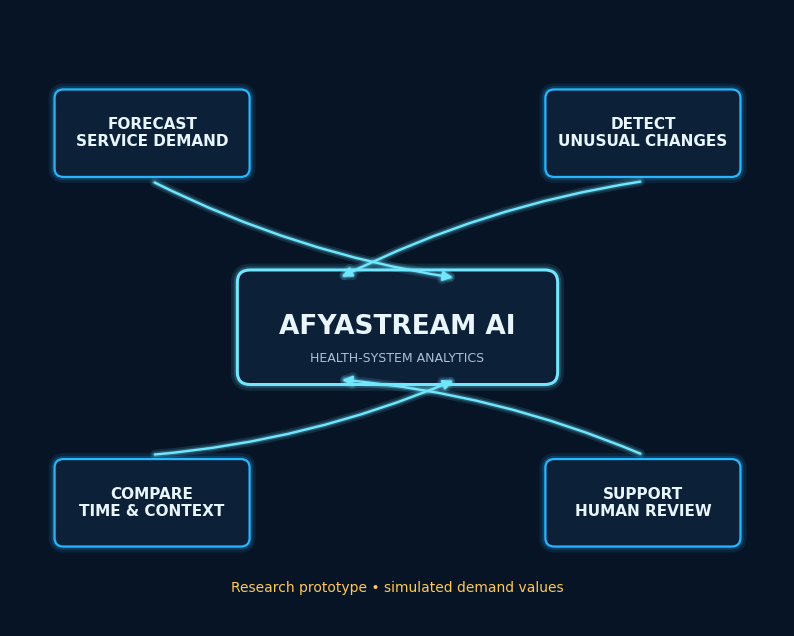

Saved: /content/afya_stream/figures/social_visual_03.png


In [13]:
# ============================================================
# VISUALIZATION 03 — PROJECT OBJECTIVES
# ============================================================
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(10, 8))
ax.set_xlim(0, 12)
ax.set_ylim(0, 10)
ax.axis("off")

center = FancyBboxPatch(
    (3.6, 4.0), 4.8, 1.7,
    boxstyle="round,pad=0.08,rounding_size=0.2",
    facecolor=PANEL_BG, edgecolor=NEON_CYAN,
    linewidth=2.2
)
ax.add_patch(center)
ax.text(
    6, 4.85, "AFYASTREAM AI",
    ha="center", va="center", fontsize=19,
    fontweight="bold", color=TEXT_LIGHT
)
ax.text(
    6, 4.35, "HEALTH-SYSTEM ANALYTICS",
    ha="center", va="center", fontsize=9,
    color=TEXT_MUTED
)

nodes = [
    (2.2, 8.0, "FORECAST\nSERVICE DEMAND"),
    (9.8, 8.0, "DETECT\nUNUSUAL CHANGES"),
    (2.2, 2.0, "COMPARE\nTIME & CONTEXT"),
    (9.8, 2.0, "SUPPORT\nHUMAN REVIEW")
]
for x, y, label in nodes:
    box = FancyBboxPatch(
        (x - 1.45, y - 0.65), 2.9, 1.3,
        boxstyle="round,pad=0.06,rounding_size=0.14",
        facecolor=PANEL_BG, edgecolor=NEON_BLUE, linewidth=1.6
    )
    ax.add_patch(box)
    ax.text(
        x, y, label, ha="center", va="center",
        fontsize=11, fontweight="bold", color=TEXT_LIGHT
    )
    ax.add_patch(FancyArrowPatch(
        (x, y - 0.78 if y > 5 else y + 0.78),
        (6 + (0.9 if x < 6 else -0.9), 5.65 if y > 5 else 4.0),
        arrowstyle="-|>", mutation_scale=14,
        linewidth=1.7, color=NEON_CYAN,
        connectionstyle="arc3,rad=0.08"
    ))

ax.text(
    6, 0.55,
    "Research prototype • simulated demand values",
    ha="center", fontsize=10, color=WARNING_AMBER
)

out = FIGURES_DIR / "social_visual_03.png"
apply_neon_style(fig)
fig.savefig(out, dpi=200, bbox_inches="tight")
apply_neon_style(fig)
plt.show()
print("Saved:", out)

## STAGE 9 — EDA

STAGE 9 — EXPLORATORY DATA ANALYSIS

[1] Monthly total demand...


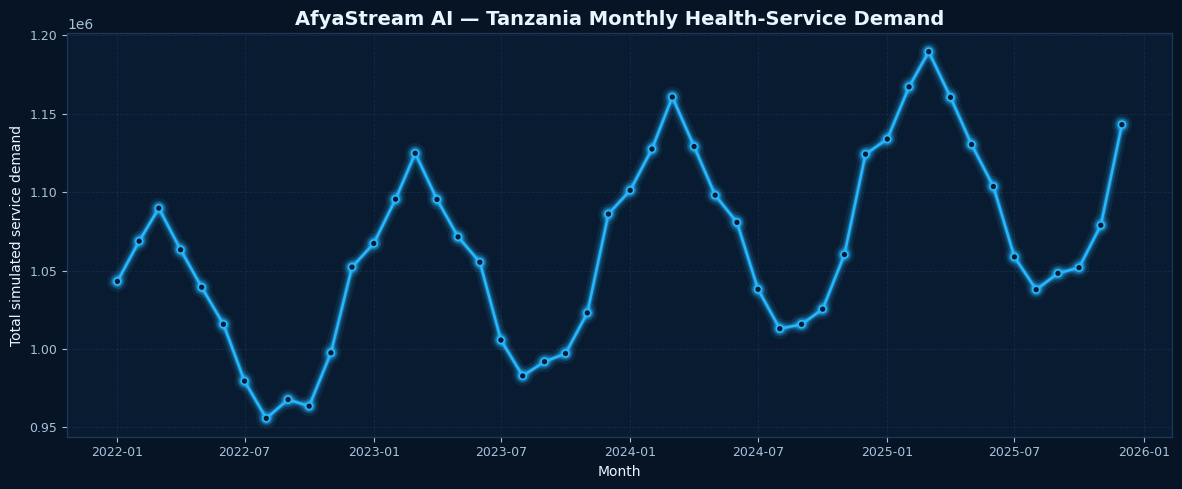

Saved: /content/afya_stream/figures/eda_01_monthly_total_demand.png

[2] Service-type trends...


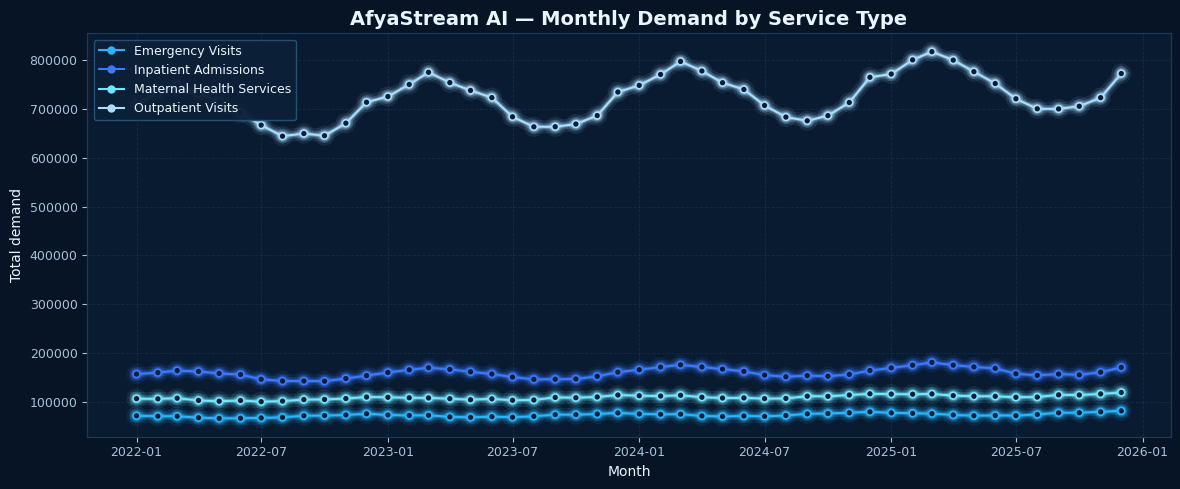

Saved: /content/afya_stream/figures/eda_02_service_type_trends.png

[3] Dar es Salaam demand trend...


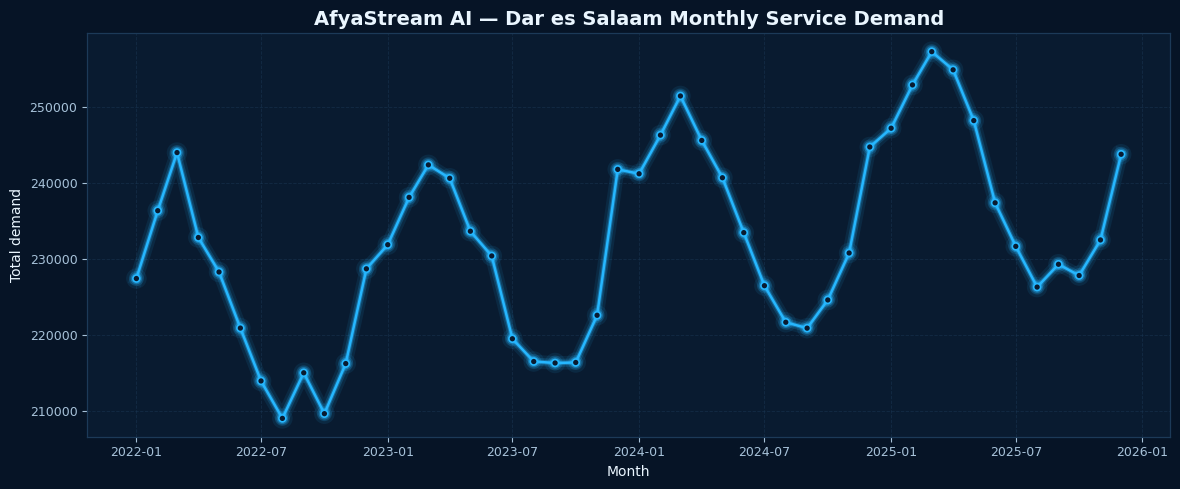

Saved: /content/afya_stream/figures/eda_03_dar_es_salaam_trend.png

[4] Featured hospital trends...


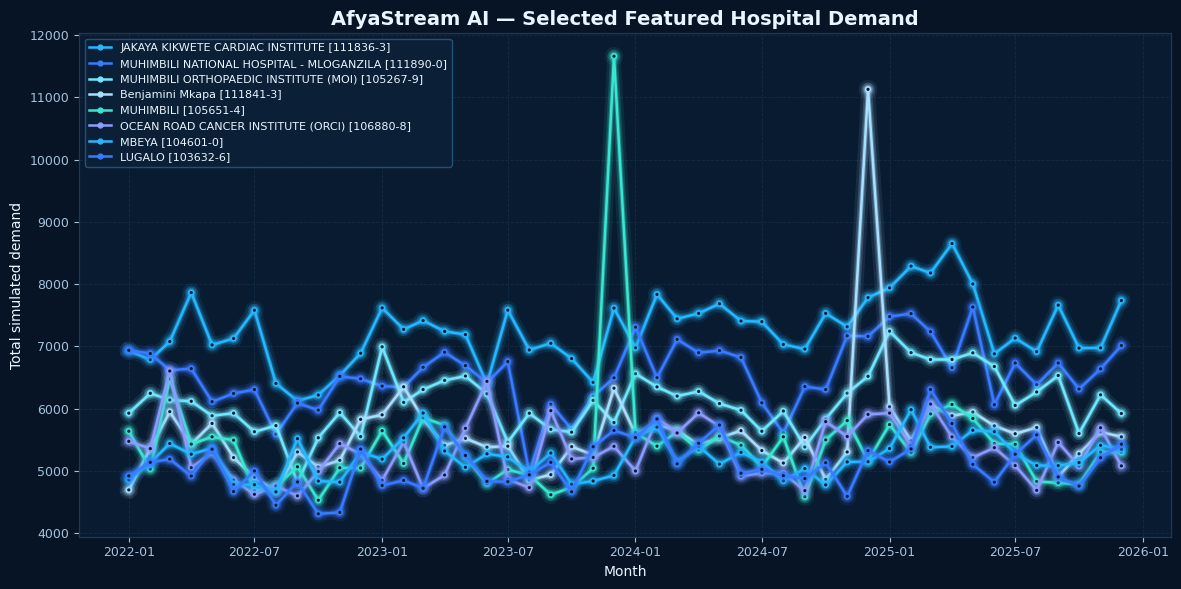

Saved: /content/afya_stream/figures/eda_04_featured_hospitals.png

[5] Inspecting synthetic anomalies...


,month,anomaly_records,anomaly_demand
0,2022-03-01,34,28891.0
1,2022-06-01,21,17036.0
2,2022-09-01,34,31590.0
3,2022-12-01,29,39046.0
4,2023-03-01,29,32002.0
5,2023-06-01,31,35357.0
6,2023-09-01,31,25276.0
7,2023-12-01,32,38595.0
8,2024-03-01,31,37675.0
9,2024-06-01,23,23989.0



Service summary:


,service_type,total_demand,average_demand,std_demand
0,Outpatient Visits,34761794.0,1496.289342,696.822861
1,Inpatient Admissions,7642689.0,328.972495,153.106259
2,Maternal Health Services,5224022.0,224.863206,104.618759
3,Emergency Visits,3480432.0,149.811983,69.955058



Regional demand summary:


...


Featured hospital summary:


,facility_name,total_demand,average_demand
0,MBEYA,497275.0,863.324653
1,JAKAYA KIKWETE CARDIAC INSTITUTE,348337.0,1814.255208
2,MUHIMBILI NATIONAL HOSPITAL - MLOGANZILA,314639.0,1638.744792
3,MUHIMBILI ORTHOPAEDIC INSTITUTE (MOI),293592.0,1529.125000
4,Benjamini Mkapa,268599.0,1398.953125
5,MUHIMBILI,260553.0,1357.046875
6,OCEAN ROAD CANCER INSTITUTE (ORCI),255336.0,1329.875000
7,LUGALO,245364.0,1277.937500
8,AMANA,189076.0,984.770833
9,BUGANDO MEDICAL CENTRE (BMC),179785.0,936.380208



Temporal feature descriptive statistics:


,lag_1,lag_2,lag_3,rolling_mean_3,rolling_std_3,growth_1m,zscore_rolling_3
count,90992.000000,89056.000000,87120.000000,90992.000000,89056.000000,90992.000000,88999.000000
mean,549.123901,548.946943,549.072555,548.876601,44.652091,0.011991,0.185845
std,657.523897,657.736799,658.364093,652.966799,85.754125,0.149902,4.421776
min,54.000000,54.000000,54.000000,59.000000,0.000000,-0.712291,-194.000000
25%,160.000000,160.000000,160.000000,161.333333,9.291573,-0.073814,-0.942092
50%,252.000000,252.000000,252.000000,252.333333,18.357560,0.000000,0.000000
75%,731.000000,731.000000,731.000000,742.000000,45.456939,0.084211,1.065136
max,9910.000000,9910.000000,9910.000000,5816.333333,3848.544140,2.495146,235.703247



✅ STAGE 9 COMPLETED SUCCESSFULLY
EDA figures saved in:
/content/afya_stream/figures

EDA summary saved to:
/content/afya_stream/audit/eda_summary.json


In [14]:
# ============================================================
# STAGE 9 — EXPLORATORY DATA ANALYSIS
# ============================================================
# Project: AfyaStream AI
#
# Lengo:
#   1. Kuona trend ya huduma kwa muda.
#   2. Kulinganisha service types.
#   3. Kuangalia Dar es Salaam.
#   4. Kuangalia featured hospitals.
#   5. Kuona synthetic anomalies.
#   6. Kuandaa visual evidence kabla ya modeling.
# ============================================================


# ------------------------------------------------------------
# 9.1 IMPORTS
# ------------------------------------------------------------

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 9.2 START
# ------------------------------------------------------------

print("=" * 75)
print("STAGE 9 — EXPLORATORY DATA ANALYSIS")
print("=" * 75)


# ------------------------------------------------------------
# 9.3 CHECK GOLD
# ------------------------------------------------------------

if "gold_health_df" not in globals():

    raise RuntimeError(
        "gold_health_df is missing. "
        "Run Stage 8 first."
    )


# ------------------------------------------------------------
# 9.4 OUTPUT DIRECTORY
# ------------------------------------------------------------

EDA_DIR = (
    "/content/afya_stream/figures"
)

os.makedirs(
    EDA_DIR,
    exist_ok=True
)


# ------------------------------------------------------------
# 9.5 MONTHLY TOTAL DEMAND
# ------------------------------------------------------------

print(
    "\n[1] Monthly total demand..."
)

monthly_total = (
    gold_health_df
    .groupBy(
        "month"
    )
    .agg(
        F.sum(
            "demand"
        ).alias(
            "total_demand"
        ),
        F.mean(
            "demand"
        ).alias(
            "mean_demand"
        ),
    )
    .orderBy(
        "month"
    )
    .toPandas()
)


monthly_total["month"] = pd.to_datetime(
    monthly_total["month"]
)


fig, ax = plt.subplots(
    figsize=(12, 5)
)

ax.plot(
    monthly_total["month"],
    monthly_total["total_demand"],
    marker="o",
    linewidth=1.8
)

ax.set_title(
    "AfyaStream AI — Tanzania Monthly Health-Service Demand"
)

ax.set_xlabel(
    "Month"
)

ax.set_ylabel(
    "Total simulated service demand"
)

ax.grid(
    alpha=0.25
)

fig.tight_layout()

monthly_total_path = (
    EDA_DIR
    + "/eda_01_monthly_total_demand.png"
)

apply_neon_style(fig)

fig.savefig(
    monthly_total_path,
    dpi=160,
    bbox_inches="tight"
)

apply_neon_style(fig)

plt.show()

print(
    "Saved:",
    monthly_total_path
)


# ------------------------------------------------------------
# 9.6 SERVICE-TYPE TREND
# ------------------------------------------------------------

print(
    "\n[2] Service-type trends..."
)

service_monthly = (
    gold_health_df
    .groupBy(
        "month",
        "service_type"
    )
    .agg(
        F.sum(
            "demand"
        ).alias(
            "total_demand"
        )
    )
    .orderBy(
        "month",
        "service_type"
    )
    .toPandas()
)


service_monthly["month"] = pd.to_datetime(
    service_monthly["month"]
)


fig, ax = plt.subplots(
    figsize=(12, 5)
)


for service_name in sorted(
    service_monthly[
        "service_type"
    ].unique()
):

    subset = service_monthly.loc[
        service_monthly[
            "service_type"
        ] == service_name
    ]

    ax.plot(
        subset["month"],
        subset["total_demand"],
        marker="o",
        linewidth=1.5,
        label=service_name
    )


ax.set_title(
    "AfyaStream AI — Monthly Demand by Service Type"
)

ax.set_xlabel(
    "Month"
)

ax.set_ylabel(
    "Total demand"
)

ax.legend(
    loc="upper left",
    fontsize=9
)

ax.grid(
    alpha=0.25
)

fig.tight_layout()

service_trend_path = (
    EDA_DIR
    + "/eda_02_service_type_trends.png"
)

apply_neon_style(fig)

fig.savefig(
    service_trend_path,
    dpi=160,
    bbox_inches="tight"
)

apply_neon_style(fig)

plt.show()

print(
    "Saved:",
    service_trend_path
)


# ------------------------------------------------------------
# 9.7 DAR ES SALAAM TREND
# ------------------------------------------------------------

print(
    "\n[3] Dar es Salaam demand trend..."
)

dar_monthly = (
    gold_health_df
    .filter(
        F.col(
            "is_dar_es_salaam"
        ) == True
    )
    .groupBy(
        "month"
    )
    .agg(
        F.sum(
            "demand"
        ).alias(
            "total_demand"
        )
    )
    .orderBy(
        "month"
    )
    .toPandas()
)


dar_monthly["month"] = pd.to_datetime(
    dar_monthly["month"]
)


fig, ax = plt.subplots(
    figsize=(12, 5)
)

ax.plot(
    dar_monthly["month"],
    dar_monthly["total_demand"],
    marker="o",
    linewidth=1.8
)

ax.set_title(
    "AfyaStream AI — Dar es Salaam Monthly Service Demand"
)

ax.set_xlabel(
    "Month"
)

ax.set_ylabel(
    "Total demand"
)

ax.grid(
    alpha=0.25
)

fig.tight_layout()

dar_trend_path = (
    EDA_DIR
    + "/eda_03_dar_es_salaam_trend.png"
)

apply_neon_style(fig)

fig.savefig(
    dar_trend_path,
    dpi=160,
    bbox_inches="tight"
)

apply_neon_style(fig)

plt.show()

print(
    "Saved:",
    dar_trend_path
)


# ------------------------------------------------------------
# 9.8 FEATURED HOSPITAL DEMAND
# ------------------------------------------------------------

print(
    "\n[4] Featured hospital trends..."
)

featured_monthly = (
    gold_health_df
    .filter(
        F.col(
            "featured_hospital"
        ) == True
    )
    .groupBy(
        "month",
        "facility_id",
        "facility_name"
    )
    .agg(
        F.sum(
            "demand"
        ).alias(
            "total_demand"
        )
    )
    .orderBy(
        "month",
        "facility_name",
        "facility_id"
    )
    .toPandas()
)


featured_monthly["month"] = pd.to_datetime(
    featured_monthly["month"]
)


# Rank by facility_id so repeated display names are never merged.
top_featured = (
    featured_monthly
    .groupby(
        ["facility_id", "facility_name"]
    )["total_demand"]
    .mean()
    .sort_values(
        ascending=False
    )
    .head(8)
    .index
    .tolist()
)


fig, ax = plt.subplots(
    figsize=(12, 6)
)


for facility_id, hospital_name in top_featured:

    subset = featured_monthly.loc[
        featured_monthly["facility_id"].astype(str).eq(str(facility_id))
    ].sort_values("month")

    ax.plot(
        subset["month"],
        subset["total_demand"],
        linewidth=1.8,
        marker="o",
        markersize=3.5,
        label=f"{hospital_name} [{facility_id}]"
    )


ax.set_title(
    "AfyaStream AI — Selected Featured Hospital Demand"
)

ax.set_xlabel(
    "Month"
)

ax.set_ylabel(
    "Total simulated demand"
)

ax.legend(
    fontsize=8,
    loc="upper left"
)

ax.grid(
    alpha=0.25
)

fig.tight_layout()

featured_path = (
    EDA_DIR
    + "/eda_04_featured_hospitals.png"
)

apply_neon_style(fig)

fig.savefig(
    featured_path,
    dpi=160,
    bbox_inches="tight"
)

apply_neon_style(fig)

plt.show()

print(
    "Saved:",
    featured_path
)


# ------------------------------------------------------------
# 9.9 ANOMALY-INJECTED RECORDS
# ------------------------------------------------------------

print(
    "\n[5] Inspecting synthetic anomalies..."
)

anomaly_monthly = (
    gold_health_df
    .filter(
        F.col(
            "anomaly_injected"
        ) == True
    )
    .groupBy(
        "month"
    )
    .agg(
        F.count("*").alias(
            "anomaly_records"
        ),
        F.sum(
            "demand"
        ).alias(
            "anomaly_demand"
        )
    )
    .orderBy(
        "month"
    )
    .toPandas()
)


display(
    anomaly_monthly.head(20)
)


# ------------------------------------------------------------
# 9.10 SERVICE SUMMARY
# ------------------------------------------------------------

service_summary = (
    gold_health_df
    .groupBy(
        "service_type"
    )
    .agg(
        F.sum(
            "demand"
        ).alias(
            "total_demand"
        ),
        F.mean(
            "demand"
        ).alias(
            "average_demand"
        ),
        F.stddev(
            "demand"
        ).alias(
            "std_demand"
        )
    )
    .orderBy(
        F.desc(
            "total_demand"
        )
    )
    .toPandas()
)


print(
    "\nService summary:"
)

display(
    service_summary
)


# ------------------------------------------------------------
# 9.11 REGION SUMMARY
# ------------------------------------------------------------

region_summary = (
    gold_health_df
    .groupBy(
        "region"
    )
    .agg(
        F.sum(
            "demand"
        ).alias(
            "total_demand"
        ),
        F.mean(
            "demand"
        ).alias(
            "average_demand"
        )
    )
    .orderBy(
        F.desc(
            "total_demand"
        )
    )
    .toPandas()
)


print(
    "\nRegional demand summary:"
)

display(
    region_summary
)


# ------------------------------------------------------------
# 9.12 FEATURED HOSPITAL SUMMARY
# ------------------------------------------------------------

featured_summary = (
    gold_health_df
    .filter(
        F.col(
            "featured_hospital"
        ) == True
    )
    .groupBy(
        "facility_name"
    )
    .agg(
        F.sum(
            "demand"
        ).alias(
            "total_demand"
        ),
        F.mean(
            "demand"
        ).alias(
            "average_demand"
        )
    )
    .orderBy(
        F.desc(
            "total_demand"
        )
    )
    .toPandas()
)


print(
    "\nFeatured hospital summary:"
)

display(
    featured_summary
)


# ------------------------------------------------------------
# 9.13 FEATURE DISTRIBUTION
# ------------------------------------------------------------

feature_distribution = (
    gold_health_df
    .select(
        *[
            "lag_1",
            "lag_2",
            "lag_3",
            "rolling_mean_3",
            "rolling_std_3",
            "growth_1m",
            "zscore_rolling_3",
        ]
    )
    .toPandas()
)


print(
    "\nTemporal feature descriptive statistics:"
)

display(
    feature_distribution.describe()
)


# ------------------------------------------------------------
# 9.14 SAVE EDA SUMMARY
# ------------------------------------------------------------

EDA_SUMMARY_FILE = (
    "/content/afya_stream/audit/"
    "eda_summary.json"
)


eda_summary = {

    "project": "AfyaStream AI",

    "stage": "Stage 9 - Exploratory Data Analysis",

    "figures": [

        monthly_total_path,

        service_trend_path,

        dar_trend_path,

        featured_path,

    ],

    "unique_services": sorted(
        service_monthly[
            "service_type"
        ]
        .unique()
        .tolist()
    ),

    "unique_months": int(
        monthly_total[
            "month"
        ].nunique()
    ),

    "dar_months": int(
        dar_monthly[
            "month"
        ].nunique()
    ),

    "featured_hospital_count": int(
        featured_monthly[
            "facility_id"
        ].nunique()
    ),

    "notes": [

        "EDA is descriptive and exploratory.",

        "Demand values in the current dataset are simulated.",
        "Featured-hospital trends are grouped by facility_id to avoid merging identical display names.",

        "Injected anomalies are retained for later detection evaluation.",

        "No model performance conclusion is made at this stage.",

    ],
}


with open(
    EDA_SUMMARY_FILE,
    "w",
    encoding="utf-8"
) as f:

    import json

    json.dump(
        eda_summary,
        f,
        indent=2,
        ensure_ascii=False
    )


# ------------------------------------------------------------
# 9.15 FINAL
# ------------------------------------------------------------

print(
    "\n" + "=" * 75
)

print(
    "✅ STAGE 9 COMPLETED SUCCESSFULLY"
)

print(
    "=" * 75
)

print(
    "EDA figures saved in:"
)

print(
    EDA_DIR
)

print(
    "\nEDA summary saved to:"
)

print(
    EDA_SUMMARY_FILE
)

Featured hospitals found: 19


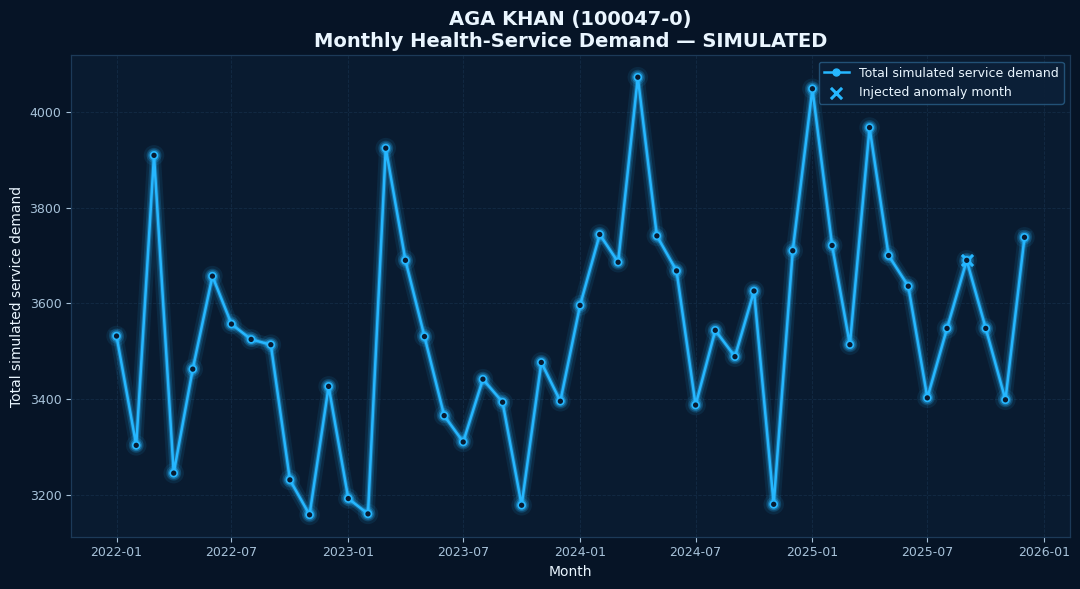

Saved: /content/afya_stream/figures/featured_hospitals/AGA_KHAN_100047_0_monthly_demand.png


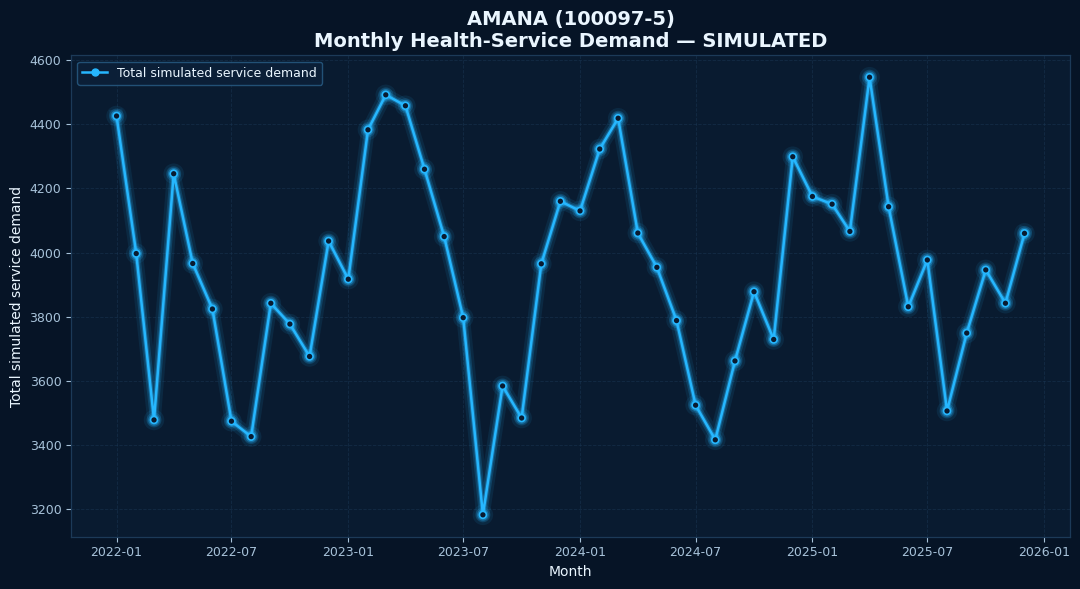

Saved: /content/afya_stream/figures/featured_hospitals/AMANA_100097_5_monthly_demand.png


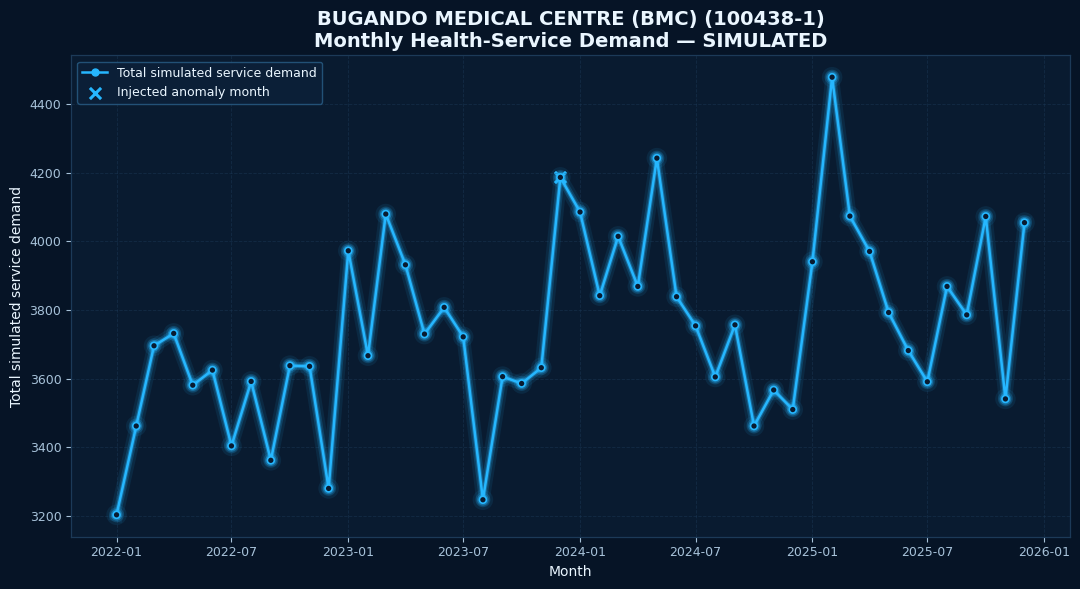

Saved: /content/afya_stream/figures/featured_hospitals/BUGANDO_MEDICAL_CENTRE_BMC_100438_1_monthly_demand.png


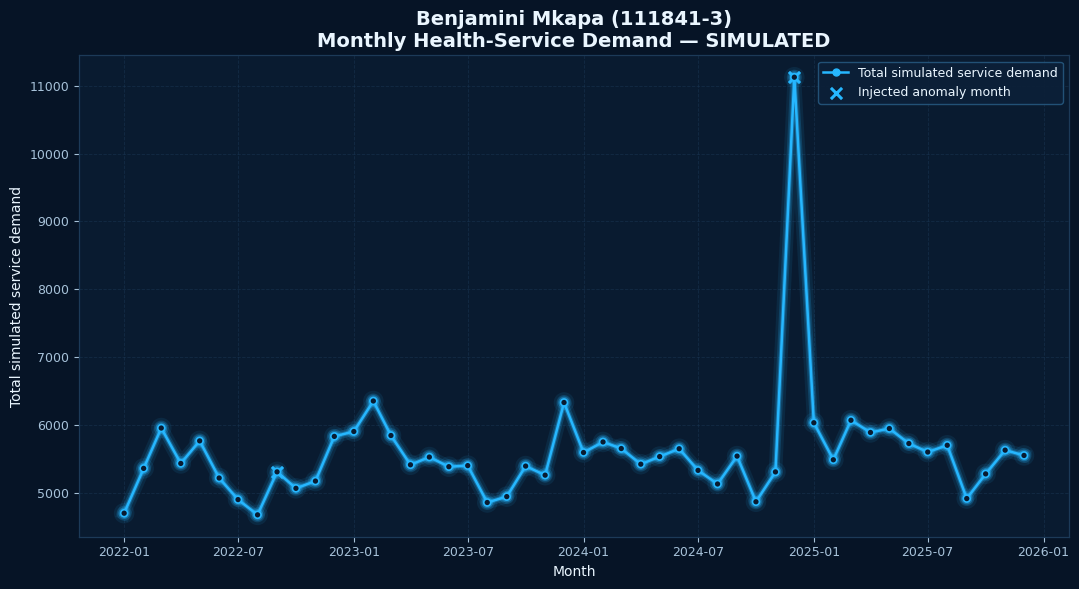

Saved: /content/afya_stream/figures/featured_hospitals/Benjamini_Mkapa_111841_3_monthly_demand.png


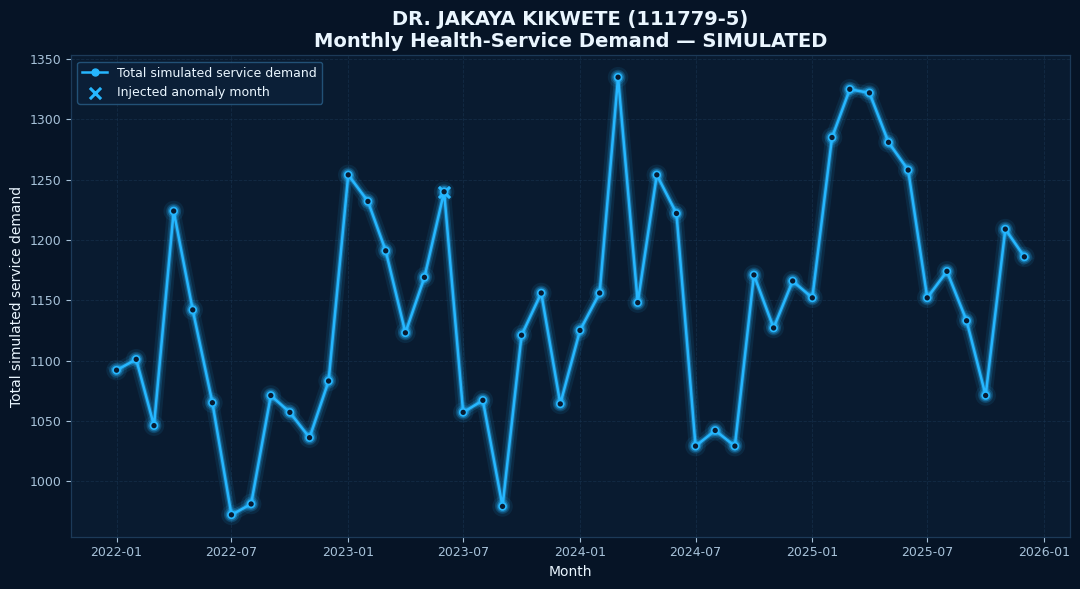

Saved: /content/afya_stream/figures/featured_hospitals/DR_JAKAYA_KIKWETE_111779_5_monthly_demand.png


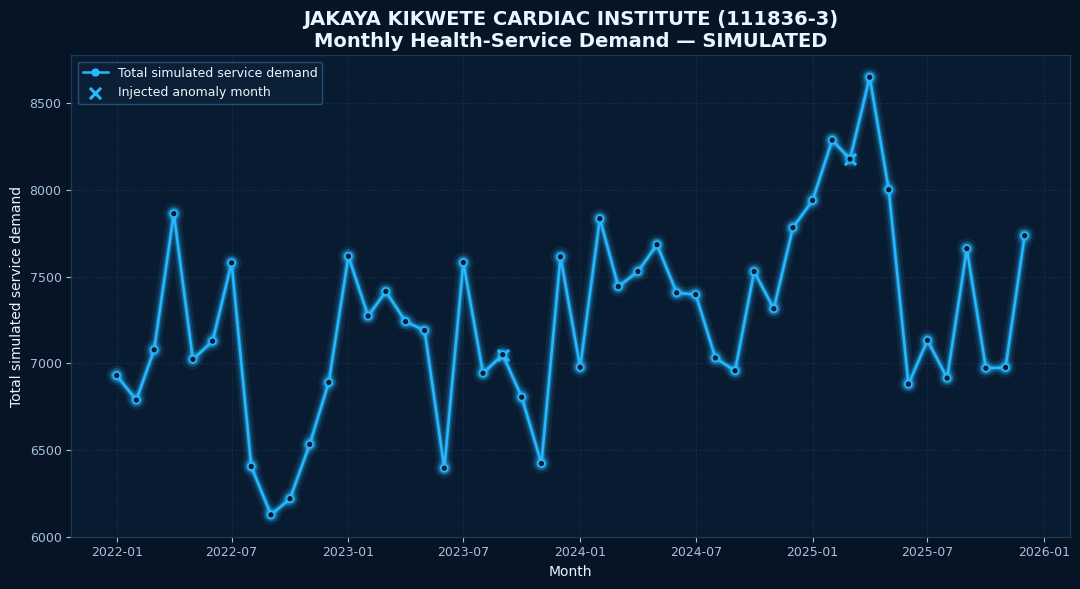

Saved: /content/afya_stream/figures/featured_hospitals/JAKAYA_KIKWETE_CARDIAC_INSTITUTE_111836_3_monthly_demand.png


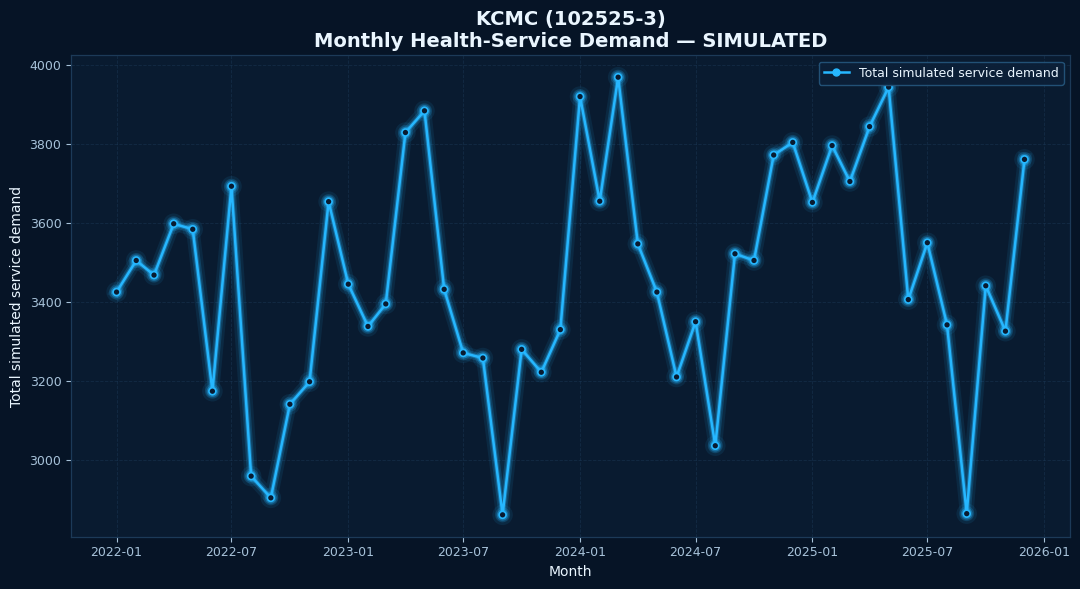

Saved: /content/afya_stream/figures/featured_hospitals/KCMC_102525_3_monthly_demand.png


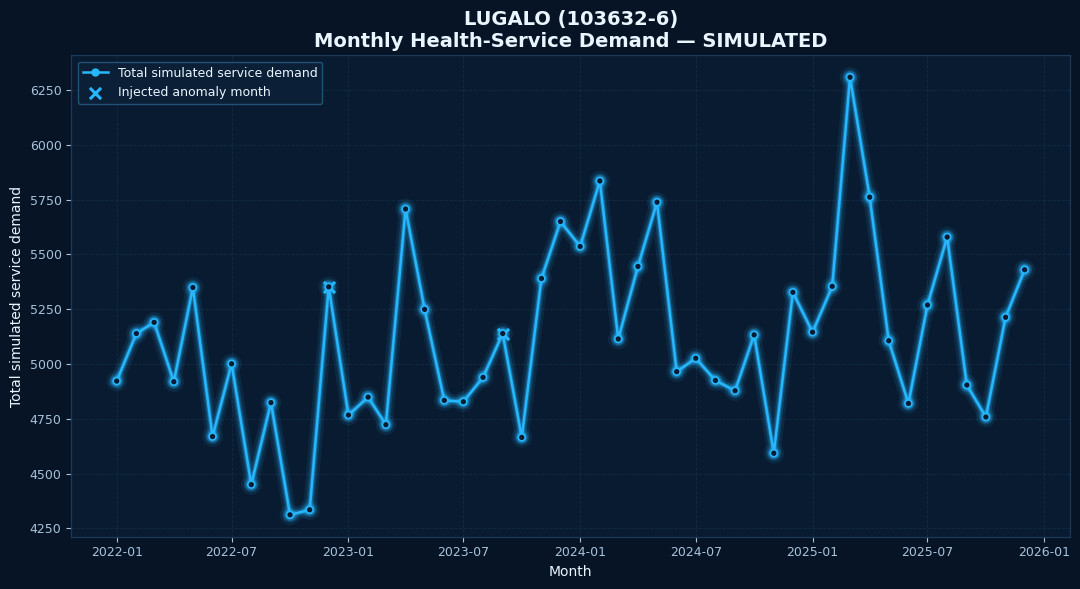

Saved: /content/afya_stream/figures/featured_hospitals/LUGALO_103632_6_monthly_demand.png


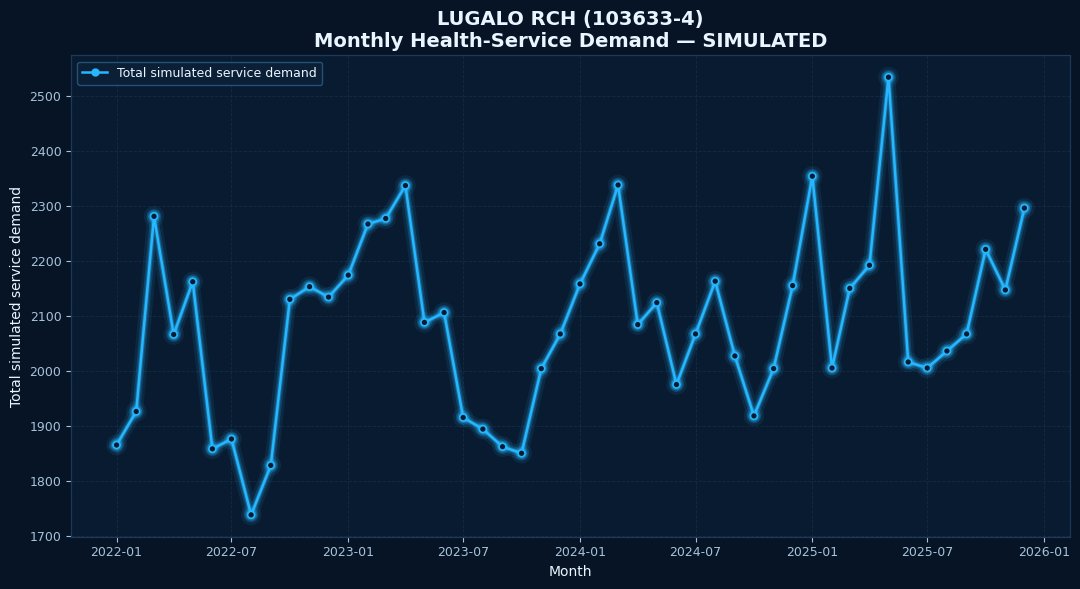

Saved: /content/afya_stream/figures/featured_hospitals/LUGALO_RCH_103633_4_monthly_demand.png


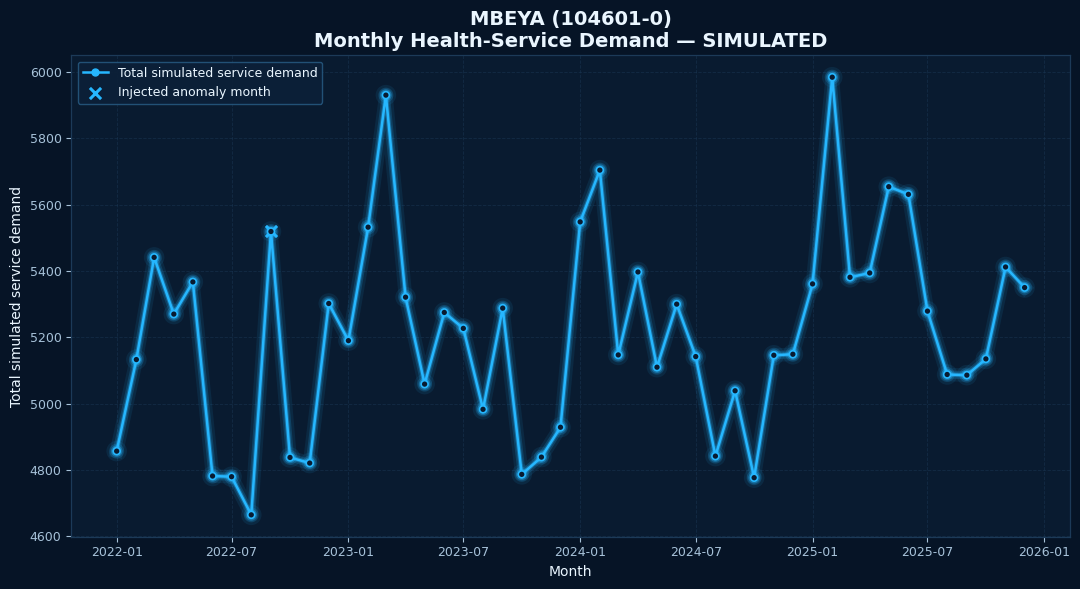

Saved: /content/afya_stream/figures/featured_hospitals/MBEYA_104601_0_monthly_demand.png


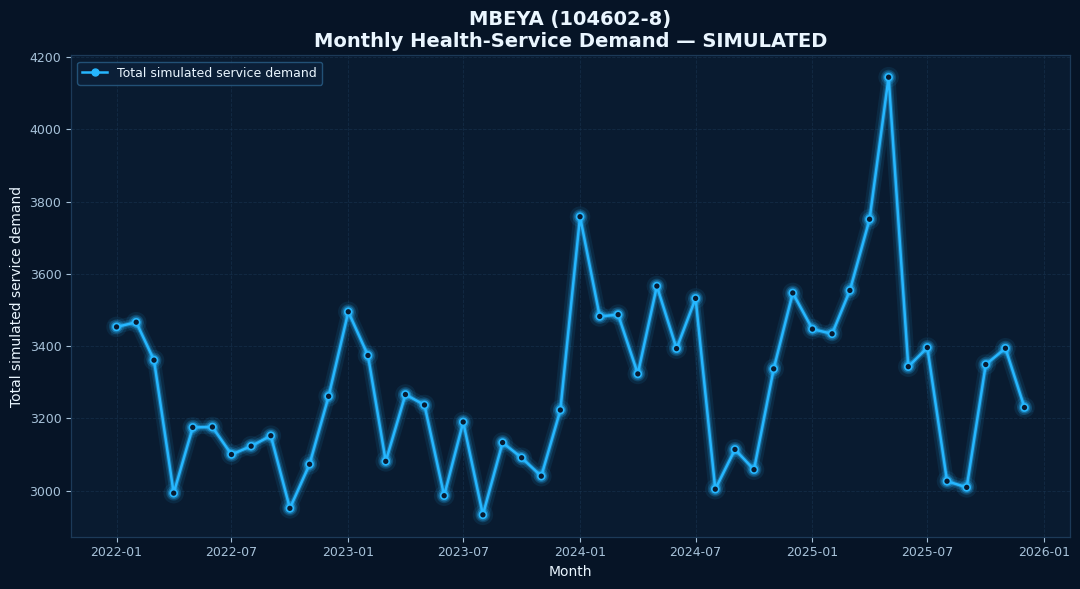

Saved: /content/afya_stream/figures/featured_hospitals/MBEYA_104602_8_monthly_demand.png


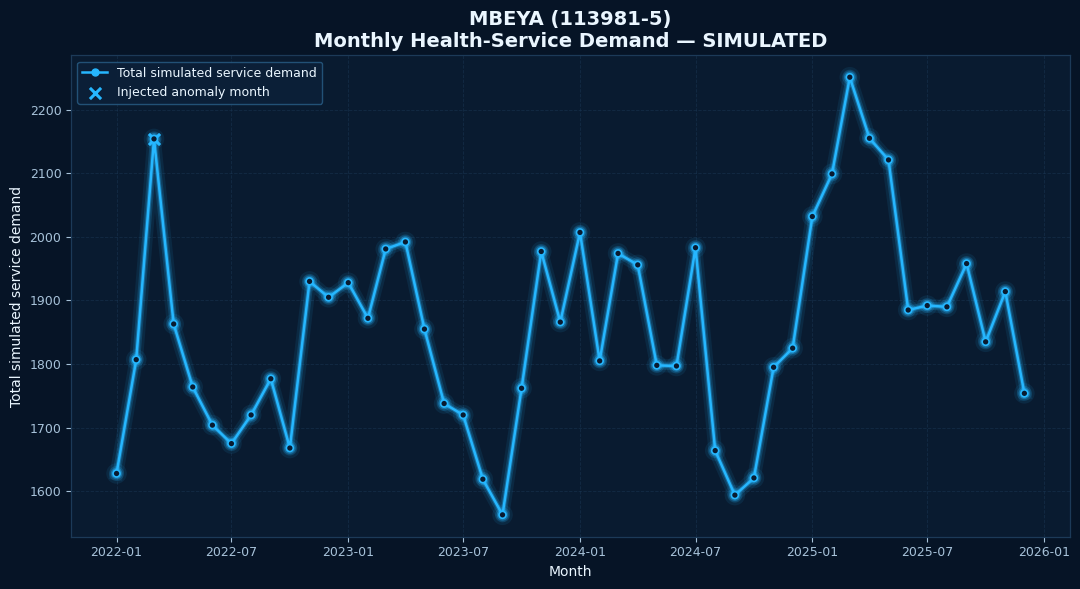

Saved: /content/afya_stream/figures/featured_hospitals/MBEYA_113981_5_monthly_demand.png


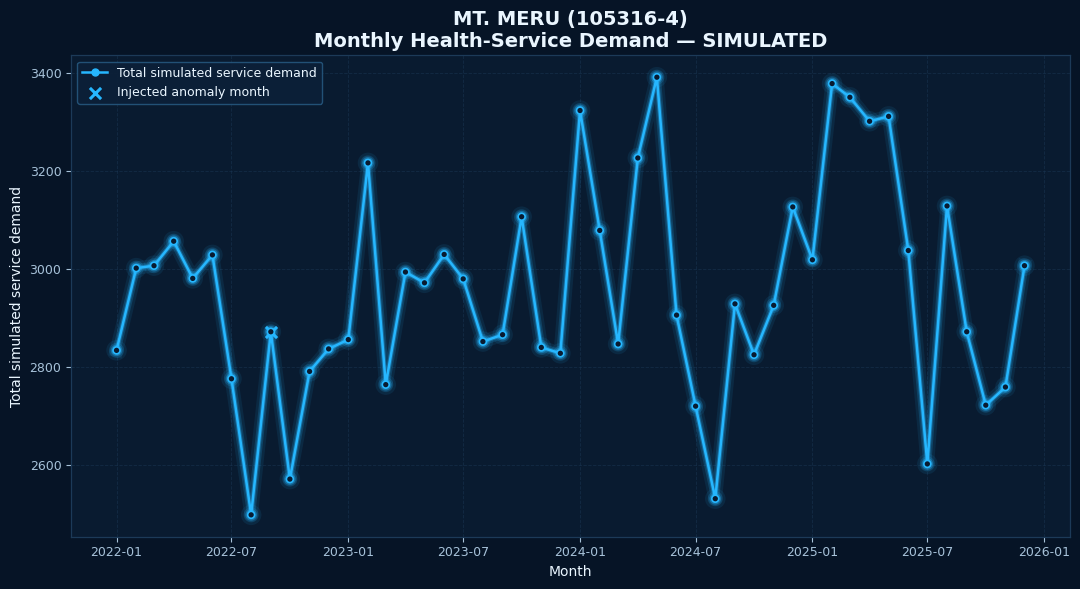

Saved: /content/afya_stream/figures/featured_hospitals/MT_MERU_105316_4_monthly_demand.png


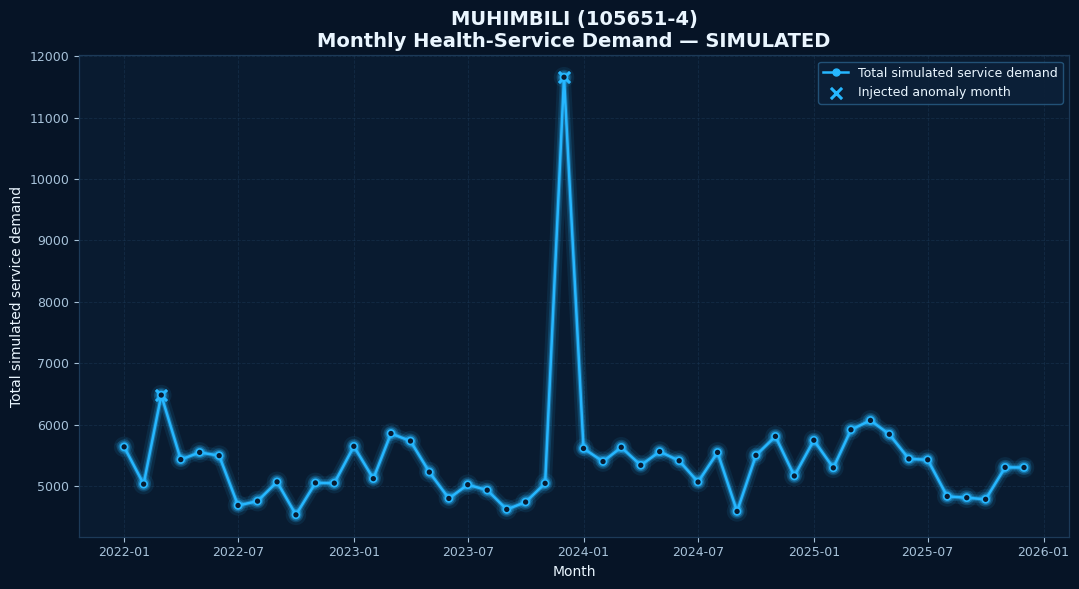

Saved: /content/afya_stream/figures/featured_hospitals/MUHIMBILI_105651_4_monthly_demand.png


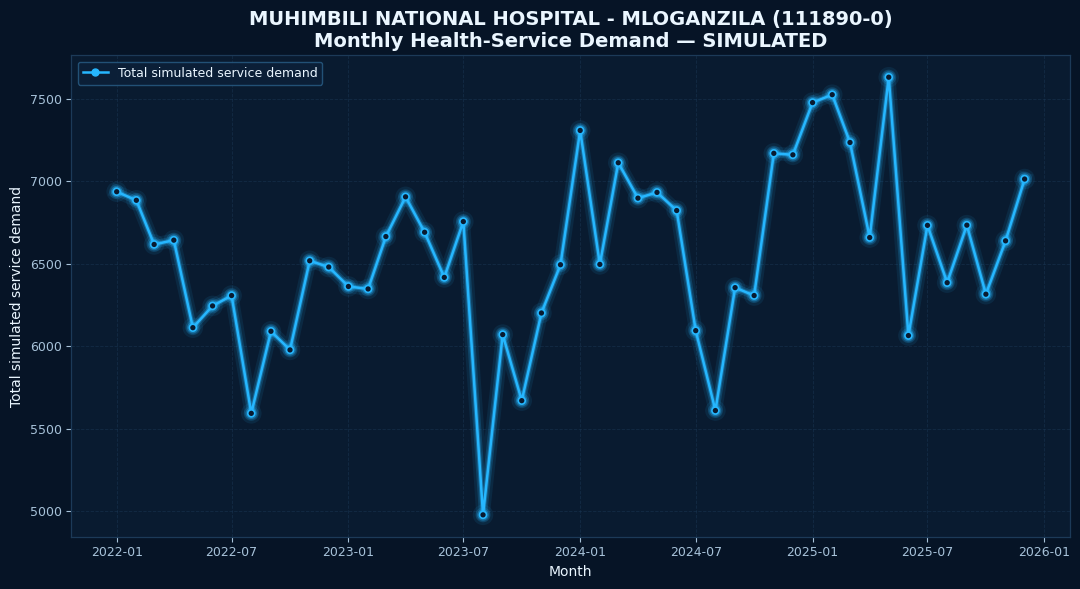

Saved: /content/afya_stream/figures/featured_hospitals/MUHIMBILI_NATIONAL_HOSPITAL_MLOGANZILA_111890_0_monthly_demand.png


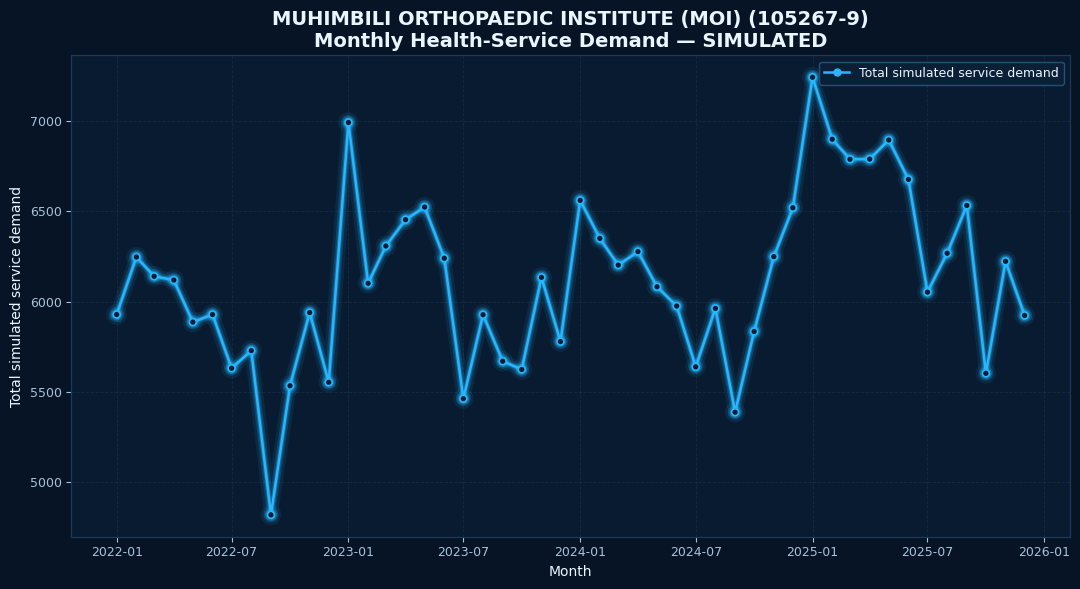

Saved: /content/afya_stream/figures/featured_hospitals/MUHIMBILI_ORTHOPAEDIC_INSTITUTE_MOI_105267_9_monthly_demand.png


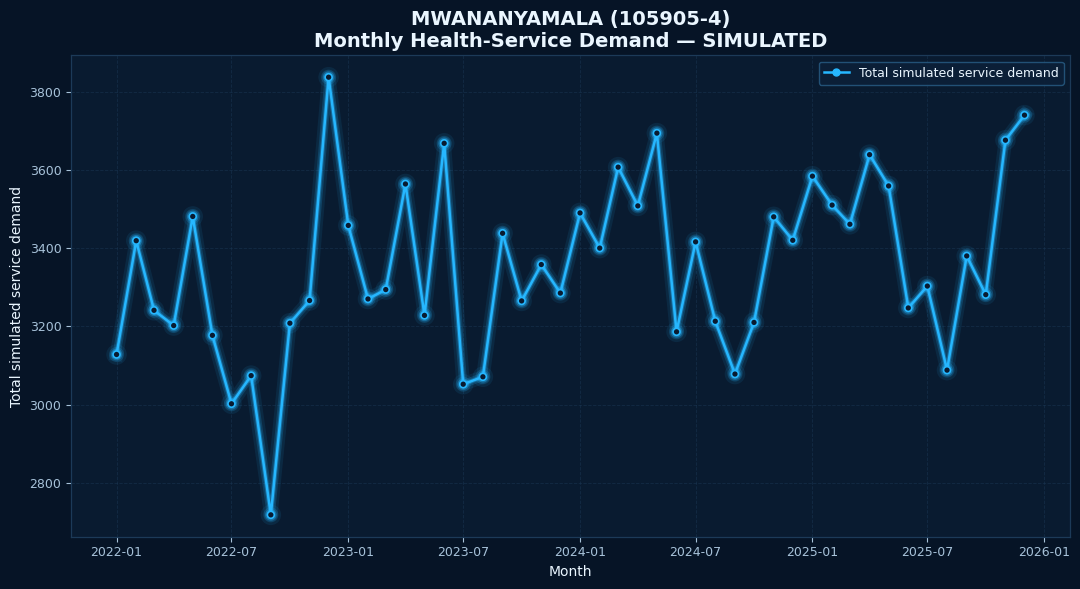

Saved: /content/afya_stream/figures/featured_hospitals/MWANANYAMALA_105905_4_monthly_demand.png


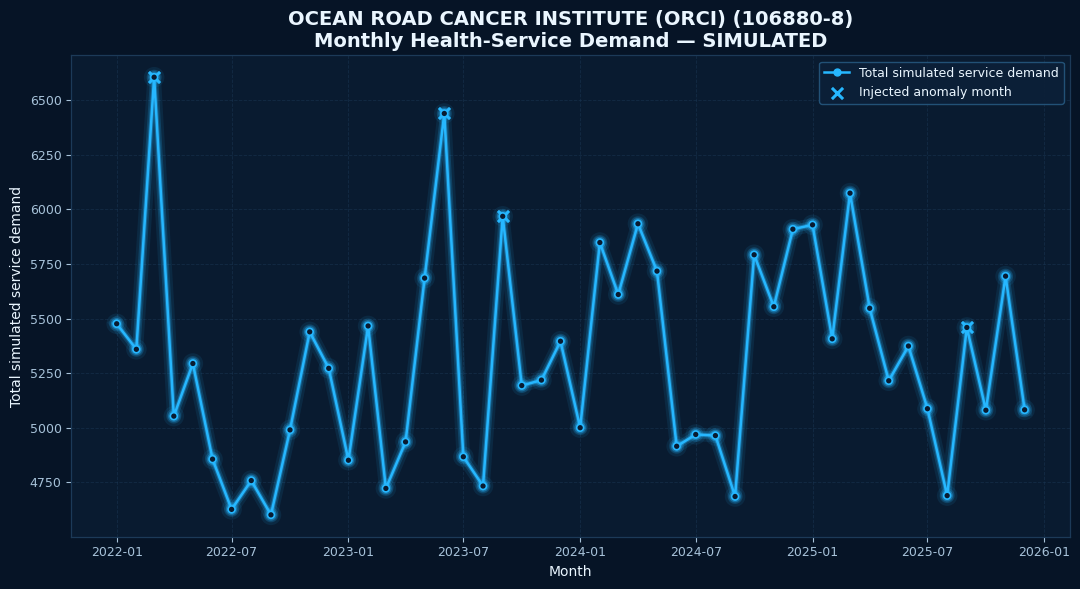

Saved: /content/afya_stream/figures/featured_hospitals/OCEAN_ROAD_CANCER_INSTITUTE_ORCI_106880_8_monthly_demand.png


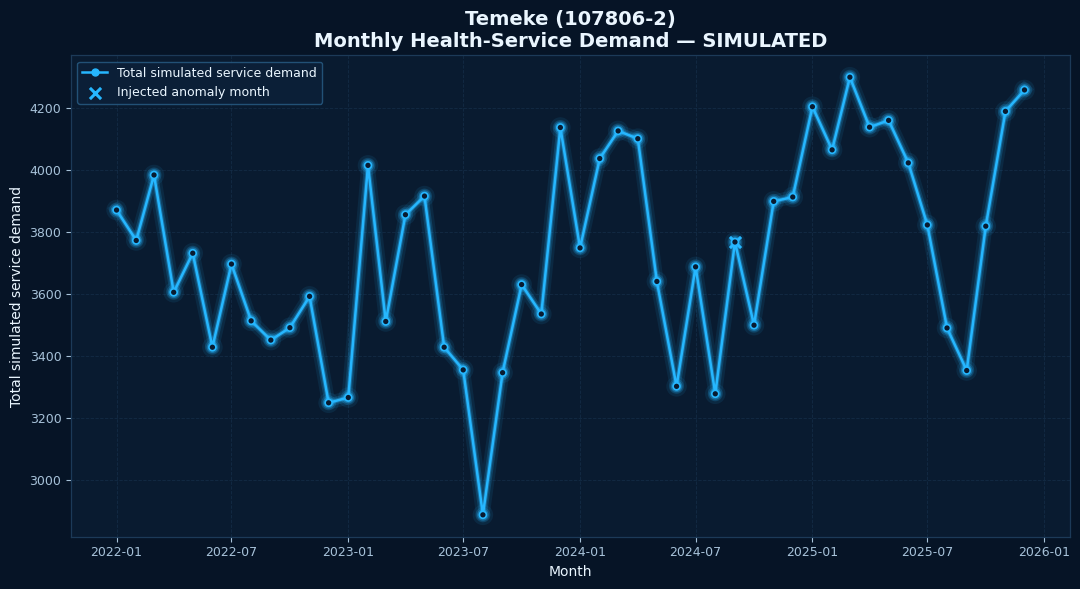

Saved: /content/afya_stream/figures/featured_hospitals/Temeke_107806_2_monthly_demand.png

FEATURED HOSPITAL VISUALIZATION SUMMARY
Hospital charts generated: 19

Visualization directory:
/content/afya_stream/figures/featured_hospitals


In [15]:
# ============================================================
# STAGE 9A — INDIVIDUAL FEATURED HOSPITAL VISUALIZATIONS
# ============================================================
# Project: AfyaStream AI
#
# Lengo:
#   Kutengeneza visualization tofauti kwa kila featured hospital.
#
# Kila chart:
#   Hospital moja
#   + 48 months
#   + total simulated service demand
#   + anomaly markers pale synthetic anomaly ilipo-injected
#
# IMPORTANT:
#   Current demand data ni SIMULATED.
#   Hizi charts hazimaanishi patient data halisi.
# ============================================================


# ------------------------------------------------------------
# 9A.1 IMPORTS
# ------------------------------------------------------------

import os
import re
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 9A.2 CHECK GOLD DATA
# ------------------------------------------------------------

if "gold_health_df" not in globals():

    raise RuntimeError(
        "gold_health_df is missing. "
        "Run Stage 8 first."
    )


# ------------------------------------------------------------
# 9A.3 OUTPUT DIRECTORY
# ------------------------------------------------------------

FEATURED_VIS_DIR = (
    "/content/afya_stream/figures/"
    "featured_hospitals"
)

os.makedirs(
    FEATURED_VIS_DIR,
    exist_ok=True
)


# ------------------------------------------------------------
# 9A.4 GET FEATURED HOSPITALS
# ------------------------------------------------------------

featured_names = (
    gold_health_df
    .filter(
        F.col("featured_hospital") == True
    )
    .select(
        "facility_id",
        "facility_name"
    )
    .distinct()
    .orderBy(
        "facility_name"
    )
    .toPandas()
)


print(
    f"Featured hospitals found: "
    f"{len(featured_names):,}"
)


# ------------------------------------------------------------
# 9A.5 GENERATE ONE CHART PER HOSPITAL
# ------------------------------------------------------------

generated_files = []


for _, hospital in featured_names.iterrows():

    facility_id = str(
        hospital["facility_id"]
    )

    facility_name = str(
        hospital["facility_name"]
    )

    # --------------------------------------------------------
    # Monthly total across all four service types
    # --------------------------------------------------------

    hospital_monthly = (
        gold_health_df
        .filter(
            F.col("facility_id")
            == facility_id
        )
        .groupBy(
            "month"
        )
        .agg(
            F.sum(
                "demand"
            ).alias(
                "total_demand"
            ),

            F.sum(
                F.when(
                    F.col(
                        "anomaly_injected"
                    ) == True,
                    F.lit(1)
                )
                .otherwise(
                    F.lit(0)
                )
            ).alias(
                "anomaly_records"
            )
        )
        .orderBy(
            "month"
        )
        .toPandas()
    )

    if hospital_monthly.empty:
        continue

    hospital_monthly["month"] = (
        pd.to_datetime(
            hospital_monthly["month"]
        )
    )

    hospital_monthly[
        "is_anomaly_month"
    ] = (
        hospital_monthly[
            "anomaly_records"
        ] > 0
    )


    # --------------------------------------------------------
    # Safe filename
    # --------------------------------------------------------

    safe_name = re.sub(
        r"[^A-Za-z0-9]+",
        "_",
        facility_name
    ).strip("_")

    safe_id = re.sub(
        r"[^A-Za-z0-9]+",
        "_",
        facility_id
    ).strip("_")

    # Include the unique facility ID so facilities with identical
    # display names never overwrite each other's figure.
    output_file = os.path.join(
        FEATURED_VIS_DIR,
        f"{safe_name}_{safe_id}_monthly_demand.png"
    )


    # --------------------------------------------------------
    # CREATE CHART
    # --------------------------------------------------------

    fig, ax = plt.subplots(
        figsize=(11, 6)
    )


    ax.plot(
        hospital_monthly["month"],
        hospital_monthly["total_demand"],
        marker="o",
        linewidth=1.8,
        label="Total simulated service demand"
    )


    # --------------------------------------------------------
    # Highlight months containing injected anomalies
    # --------------------------------------------------------

    anomaly_rows = hospital_monthly.loc[
        hospital_monthly[
            "is_anomaly_month"
        ]
    ]


    if not anomaly_rows.empty:

        ax.scatter(
            anomaly_rows["month"],
            anomaly_rows["total_demand"],
            marker="x",
            s=65,
            label="Injected anomaly month"
        )


    # --------------------------------------------------------
    # Titles
    # --------------------------------------------------------

    ax.set_title(
        f"{facility_name} ({facility_id})\n"
        "Monthly Health-Service Demand — SIMULATED"
    )


    ax.set_xlabel(
        "Month"
    )


    ax.set_ylabel(
        "Total simulated service demand"
    )


    ax.grid(
        alpha=0.25
    )


    ax.legend(
        fontsize=9
    )


    fig.tight_layout()


    apply_neon_style(fig)


    fig.savefig(
        output_file,
        dpi=180,
        bbox_inches="tight"
    )


    apply_neon_style(fig)


    plt.show()


    generated_files.append(
        output_file
    )


    print(
        "Saved:",
        output_file
    )


# ------------------------------------------------------------
# 9A.6 FINAL SUMMARY
# ------------------------------------------------------------

print(
    "\n" + "=" * 75
)

print(
    "FEATURED HOSPITAL VISUALIZATION SUMMARY"
)

print(
    "=" * 75
)

print(
    f"Hospital charts generated: "
    f"{len(generated_files):,}"
)

print(
    "\nVisualization directory:"
)

print(
    FEATURED_VIS_DIR
)

# SOCIAL MEDIA — POST 04/13

## **Mfumo wetu unatumia data gani?**

Tunaanza kwa kuchunguza vyanzo vya data vya afya vinavyopatikana Tanzania, pamoja na data za vituo na context ya population.

**Lengo si kutumia data nyingi kwa jina la Big Data. Lengo ni kutumia data inayoweza kujibu swali la utafiti.**

**Uwazi wa data:** HFR inarejelewa kwa metadata ya vituo; demand ya modeling kwenye toleo hili ni simulation.

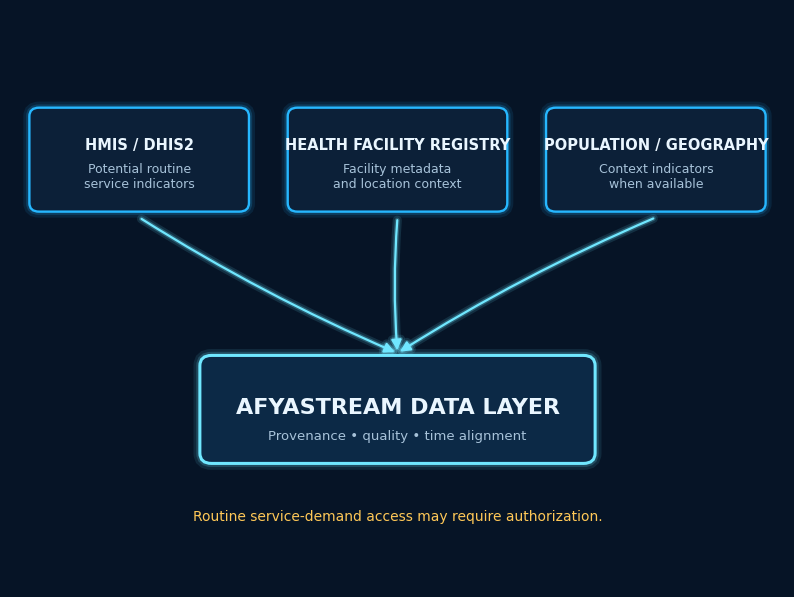

Saved: /content/afya_stream/figures/social_visual_04.png


In [16]:
# ============================================================
# VISUALIZATION 04 — DATA ECOSYSTEM
# ============================================================
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(10, 7.5))
ax.set_xlim(0, 12)
ax.set_ylim(0, 10)
ax.axis("off")

sources = [
    (2.0, 7.4, "HMIS / DHIS2", "Potential routine\nservice indicators"),
    (6.0, 7.4, "HEALTH FACILITY REGISTRY", "Facility metadata\nand location context"),
    (10.0, 7.4, "POPULATION / GEOGRAPHY", "Context indicators\nwhen available")
]

for x, y, title, desc in sources:
    box = FancyBboxPatch(
        (x - 1.65, y - 0.85), 3.3, 1.7,
        boxstyle="round,pad=0.05,rounding_size=0.15",
        facecolor=PANEL_BG, edgecolor=NEON_BLUE, linewidth=1.7
    )
    ax.add_patch(box)
    ax.text(
        x, y + 0.25, title,
        ha="center", va="center", fontsize=10.5,
        fontweight="bold", color=TEXT_LIGHT
    )
    ax.text(
        x, y - 0.3, desc,
        ha="center", va="center", fontsize=9,
        color=TEXT_MUTED
    )

target = FancyBboxPatch(
    (3.0, 2.2), 6.0, 1.75,
    boxstyle="round,pad=0.06,rounding_size=0.18",
    facecolor="#0C2946", edgecolor=NEON_CYAN, linewidth=2.2
)
ax.add_patch(target)
ax.text(
    6, 3.1, "AFYASTREAM DATA LAYER",
    ha="center", va="center", fontsize=16,
    fontweight="bold", color=TEXT_LIGHT
)
ax.text(
    6, 2.62, "Provenance • quality • time alignment",
    ha="center", va="center", fontsize=9.5,
    color=TEXT_MUTED
)

for x, _, _, _ in sources:
    ax.add_patch(FancyArrowPatch(
        (x, 6.4), (6, 4.05),
        arrowstyle="-|>", mutation_scale=15,
        linewidth=1.6, color=NEON_CYAN,
        connectionstyle="arc3,rad=0.04"
    ))

ax.text(
    6, 1.15,
    "Routine service-demand access may require authorization.",
    ha="center", fontsize=10, color=WARNING_AMBER
)

out = FIGURES_DIR / "social_visual_04.png"
apply_neon_style(fig)
fig.savefig(out, dpi=200, bbox_inches="tight")
apply_neon_style(fig)
plt.show()
print("Saved:", out)

## STAGE 10 — TIME-AWARE TRAIN / TEST

In [17]:
# ============================================================
# STAGE 10 — TIME-AWARE TRAIN / VALIDATION / TEST SPLIT
# ============================================================
# Project: AfyaStream AI
#
# Lengo:
#   1. Kutumia supervised-ready Gold observations.
#   2. Kuunda target_month = mwezi unaotabiriwa.
#   3. Kugawa data kwa muda:
#
#        TRAIN       → target <= 2024-06
#        VALIDATION  → 2024-07 to 2024-12
#        TEST        → 2025-01 to 2025-12
#
#   4. Kuzuia random shuffling.
#   5. Kuthibitisha chronological integrity.
#   6. Kuandaa train_df, validation_df na test_df.
#
# IMPORTANT:
#   Split inafanywa kwa TARGET MONTH.
#   Hii ni muhimu kwa one-step-ahead forecasting.
# ============================================================


# ------------------------------------------------------------
# 10.1 IMPORTS
# ------------------------------------------------------------

import os
import json
import pandas as pd

from pyspark.sql import (
    functions as F,
)


# ------------------------------------------------------------
# 10.2 START
# ------------------------------------------------------------

print("=" * 75)
print("STAGE 10 — TIME-AWARE TRAIN / VALIDATION / TEST SPLIT")
print("=" * 75)


# ------------------------------------------------------------
# 10.3 CHECK GOLD DATA
# ------------------------------------------------------------

if "gold_health_df" not in globals():

    raise RuntimeError(
        "gold_health_df is missing. "
        "Run Stage 8 successfully first."
    )


# ------------------------------------------------------------
# 10.4 SELECT SUPERVISED-READY ROWS
# ------------------------------------------------------------

print(
    "\n[1] Selecting supervised-ready records..."
)


model_base_df = (
    gold_health_df
    .filter(
        F.col(
            "supervised_ready"
        ) == True
    )
)


supervised_count = (
    model_base_df.count()
)


print(
    f"Supervised-ready rows: "
    f"{supervised_count:,}"
)


if supervised_count == 0:

    raise RuntimeError(
        "No supervised-ready records found."
    )


# ------------------------------------------------------------
# 10.5 CREATE TARGET MONTH
# ------------------------------------------------------------
# Current row:
#
#   month = t
#
# Target:
#
#   target_next_month = demand at t+1
#
# Therefore:
#
#   target_month = t+1

model_base_df = (
    model_base_df
    .withColumn(
        "target_month",
        F.add_months(
            F.col("month"),
            1
        )
    )
)


# ------------------------------------------------------------
# 10.6 IDENTIFY TARGET ANOMALIES
# ------------------------------------------------------------
# This is metadata/evaluation information only.
# It MUST NOT be used as a feature.
#
# For row t:
#   target_anomaly_injected = anomaly status at t+1

from pyspark.sql.window import Window


target_window = (
    Window
    .partitionBy(
        "facility_id",
        "service_type"
    )
    .orderBy(
        "month"
    )
)


model_base_df = (
    model_base_df
    .withColumn(
        "target_anomaly_injected",
        F.lead(
            "anomaly_injected",
            1
        ).over(
            target_window
        )
    )
    .withColumn(
        "target_anomaly_injected",
        F.coalesce(
            F.col(
                "target_anomaly_injected"
            ),
            F.lit(False)
        )
    )
)


# ------------------------------------------------------------
# 10.7 DEFINE TIME BOUNDARIES
# ------------------------------------------------------------

TRAIN_END = "2024-06-01"

VALIDATION_START = "2024-07-01"
VALIDATION_END = "2024-12-01"

TEST_START = "2025-01-01"
TEST_END = "2025-12-01"


# ------------------------------------------------------------
# 10.8 ASSIGN SPLIT
# ------------------------------------------------------------

print(
    "\n[2] Assigning time-based split..."
)


model_base_df = (
    model_base_df
    .withColumn(
        "split",
        F.when(
            F.col(
                "target_month"
            ) <= F.to_date(
                F.lit(TRAIN_END)
            ),
            F.lit("TRAIN")
        )
        .when(
            (
                F.col("target_month")
                >= F.to_date(
                    F.lit(
                        VALIDATION_START
                    )
                )
            )
            &
            (
                F.col("target_month")
                <= F.to_date(
                    F.lit(
                        VALIDATION_END
                    )
                )
            ),
            F.lit("VALIDATION")
        )
        .when(
            (
                F.col("target_month")
                >= F.to_date(
                    F.lit(
                        TEST_START
                    )
                )
            )
            &
            (
                F.col("target_month")
                <= F.to_date(
                    F.lit(
                        TEST_END
                    )
                )
            ),
            F.lit("TEST")
        )
        .otherwise(
            F.lit("OUT_OF_WINDOW")
        )
    )
)


# ------------------------------------------------------------
# 10.9 COUNT SPLITS
# ------------------------------------------------------------

split_summary = (
    model_base_df
    .groupBy(
        "split"
    )
    .agg(
        F.count("*").alias(
            "rows"
        ),

        F.countDistinct(
            "facility_id"
        ).alias(
            "facilities"
        ),

        F.countDistinct(
            "service_type"
        ).alias(
            "service_types"
        ),

        F.min(
            "target_month"
        ).alias(
            "min_target_month"
        ),

        F.max(
            "target_month"
        ).alias(
            "max_target_month"
        ),
    )
    .orderBy(
        F.when(
            F.col("split")
            == "TRAIN",
            1
        )
        .when(
            F.col("split")
            == "VALIDATION",
            2
        )
        .when(
            F.col("split")
            == "TEST",
            3
        )
        .otherwise(
            4
        )
    )
)


print(
    "\nSplit summary:"
)

display(
    split_summary.toPandas()
)


# ------------------------------------------------------------
# 10.10 OUT-OF-WINDOW CHECK
# ------------------------------------------------------------

out_of_window_count = (
    model_base_df
    .filter(
        F.col(
            "split"
        ) == "OUT_OF_WINDOW"
    )
    .count()
)


print(
    f"\nOut-of-window supervised rows: "
    f"{out_of_window_count:,}"
)


if out_of_window_count > 0:

    print(
        "These rows will not be used for modeling."
    )


# ------------------------------------------------------------
# 10.11 CREATE MODELING DATASET
# ------------------------------------------------------------

modeling_df = (
    model_base_df
    .filter(
        F.col(
            "split"
        ) != "OUT_OF_WINDOW"
    )
)


# ------------------------------------------------------------
# 10.12 SPLIT DATAFRAMES
# ------------------------------------------------------------

train_df = (
    modeling_df
    .filter(
        F.col("split")
        == "TRAIN"
    )
    .cache()
)


validation_df = (
    modeling_df
    .filter(
        F.col("split")
        == "VALIDATION"
    )
    .cache()
)


test_df = (
    modeling_df
    .filter(
        F.col("split")
        == "TEST"
    )
    .cache()
)


# Materialize
train_count = train_df.count()

validation_count = (
    validation_df.count()
)

test_count = test_df.count()


print(
    "\n" + "=" * 75
)

print(
    "TIME-AWARE SPLIT COUNTS"
)

print(
    "=" * 75
)

print(
    f"TRAIN       : {train_count:,}"
)

print(
    f"VALIDATION  : {validation_count:,}"
)

print(
    f"TEST        : {test_count:,}"
)


# ------------------------------------------------------------
# 10.13 CHRONOLOGICAL BOUNDARIES
# ------------------------------------------------------------

train_min = (
    train_df
    .agg(
        F.min(
            "target_month"
        )
    )
    .collect()[0][0]
)

train_max = (
    train_df
    .agg(
        F.max(
            "target_month"
        )
    )
    .collect()[0][0]
)


validation_min = (
    validation_df
    .agg(
        F.min(
            "target_month"
        )
    )
    .collect()[0][0]
)

validation_max = (
    validation_df
    .agg(
        F.max(
            "target_month"
        )
    )
    .collect()[0][0]
)


test_min = (
    test_df
    .agg(
        F.min(
            "target_month"
        )
    )
    .collect()[0][0]
)

test_max = (
    test_df
    .agg(
        F.max(
            "target_month"
        )
    )
    .collect()[0][0]
)


print(
    "\nChronological boundaries:"
)

print(
    f"TRAIN       : "
    f"{train_min} → {train_max}"
)

print(
    f"VALIDATION  : "
    f"{validation_min} → {validation_max}"
)

print(
    f"TEST        : "
    f"{test_min} → {test_max}"
)


# ------------------------------------------------------------
# 10.14 CHRONOLOGY QUALITY GATE
# ------------------------------------------------------------

chronology_valid = (
    train_max < validation_min
    and
    validation_max < test_min
)


if not chronology_valid:

    raise RuntimeError(
        "Chronological split integrity failed."
    )


print(
    "\n✅ Chronological split integrity passed."
)


# ------------------------------------------------------------
# 10.15 CHECK TARGET MONTH OVERLAP
# ------------------------------------------------------------

target_month_sets = {

    "TRAIN": set(
        row[0]
        for row in (
            train_df
            .select(
                "target_month"
            )
            .distinct()
            .collect()
        )
    ),

    "VALIDATION": set(
        row[0]
        for row in (
            validation_df
            .select(
                "target_month"
            )
            .distinct()
            .collect()
        )
    ),

    "TEST": set(
        row[0]
        for row in (
            test_df
            .select(
                "target_month"
            )
            .distinct()
            .collect()
        )
    ),
}


train_validation_overlap = (
    target_month_sets["TRAIN"]
    .intersection(
        target_month_sets["VALIDATION"]
    )
)


validation_test_overlap = (
    target_month_sets["VALIDATION"]
    .intersection(
        target_month_sets["TEST"]
    )
)


train_test_overlap = (
    target_month_sets["TRAIN"]
    .intersection(
        target_month_sets["TEST"]
    )
)


print(
    "\nTarget-month overlap checks:"
)

print(
    "TRAIN ∩ VALIDATION:",
    len(train_validation_overlap)
)

print(
    "VALIDATION ∩ TEST:",
    len(validation_test_overlap)
)

print(
    "TRAIN ∩ TEST:",
    len(train_test_overlap)
)


if (
    train_validation_overlap
    or
    validation_test_overlap
    or
    train_test_overlap
):

    raise RuntimeError(
        "Target-month overlap detected."
    )


print(
    "✅ Target-month separation passed."
)


# ------------------------------------------------------------
# 10.16 FEATURE DEFINITIONS
# ------------------------------------------------------------
# These are candidate numeric features for forecasting.
#
# Metadata fields such as:
#   anomaly_injected
#   target_anomaly_injected
#
# are explicitly excluded.

forecast_numeric_features = [

    "lag_1",
    "lag_2",
    "lag_3",
    "lag_6",
    "lag_12",

    "rolling_mean_3",
    "rolling_std_3",

    "rolling_mean_6",
    "rolling_std_6",

    "rolling_mean_12",
    "rolling_std_12",

    "growth_1m",
    "growth_3m",
    "growth_6m",

    "deviation_from_mean_3",

    "zscore_rolling_3",

    "month_sin",
    "month_cos",

    "time_index",
]


for feature in forecast_numeric_features:

    if feature not in modeling_df.columns:

        raise RuntimeError(
            f"Forecast feature missing: {feature}"
        )


for forbidden in [
    "anomaly_injected",
    "target_anomaly_injected",
    "target_next_month",
]:

    if forbidden in forecast_numeric_features:

        raise RuntimeError(
            f"Forbidden target/leakage field in "
            f"feature list: {forbidden}"
        )


print(
    "\n✅ Forecast feature-list leakage check passed."
)


# ------------------------------------------------------------
# 10.17 ANOMALY METADATA SUMMARY
# ------------------------------------------------------------

train_target_anomalies = (
    train_df
    .filter(
        F.col(
            "target_anomaly_injected"
        ) == True
    )
    .count()
)


validation_target_anomalies = (
    validation_df
    .filter(
        F.col(
            "target_anomaly_injected"
        ) == True
    )
    .count()
)


test_target_anomalies = (
    test_df
    .filter(
        F.col(
            "target_anomaly_injected"
        ) == True
    )
    .count()
)


print(
    "\nTarget anomaly metadata:"
)

print(
    f"TRAIN target anomalies      : "
    f"{train_target_anomalies:,}"
)

print(
    f"VALIDATION target anomalies : "
    f"{validation_target_anomalies:,}"
)

print(
    f"TEST target anomalies       : "
    f"{test_target_anomalies:,}"
)


# ------------------------------------------------------------
# 10.18 FEATURE COVERAGE IN SPLITS
# ------------------------------------------------------------

feature_coverage_rows = []


for feature in forecast_numeric_features:

    train_non_null = (
        train_df
        .filter(
            F.col(
                feature
            ).isNotNull()
        )
        .count()
    )

    validation_non_null = (
        validation_df
        .filter(
            F.col(
                feature
            ).isNotNull()
        )
        .count()
    )

    test_non_null = (
        test_df
        .filter(
            F.col(
                feature
            ).isNotNull()
        )
        .count()
    )

    feature_coverage_rows.append({

        "feature": feature,

        "train_coverage_pct": (
            100
            * train_non_null
            / train_count
        ),

        "validation_coverage_pct": (
            100
            * validation_non_null
            / validation_count
        ),

        "test_coverage_pct": (
            100
            * test_non_null
            / test_count
        ),
    })


feature_coverage_df = pd.DataFrame(
    feature_coverage_rows
)


print(
    "\nForecast feature coverage:"
)

display(
    feature_coverage_df
)


# ------------------------------------------------------------
# 10.19 SAVE MODELING DIRECTORY
# ------------------------------------------------------------

MODEL_DIR = (
    "/content/afya_stream/modeling"
)

MODEL_AUDIT_DIR = (
    "/content/afya_stream/audit"
)


os.makedirs(
    MODEL_DIR,
    exist_ok=True
)


# ------------------------------------------------------------
# 10.20 SAVE TRAIN / VALIDATION / TEST
# ------------------------------------------------------------

TRAIN_PARQUET = (
    MODEL_DIR
    + "/train"
)

VALIDATION_PARQUET = (
    MODEL_DIR
    + "/validation"
)

TEST_PARQUET = (
    MODEL_DIR
    + "/test"
)


train_df.write.mode(
    "overwrite"
).parquet(
    TRAIN_PARQUET
)


validation_df.write.mode(
    "overwrite"
).parquet(
    VALIDATION_PARQUET
)


test_df.write.mode(
    "overwrite"
).parquet(
    TEST_PARQUET
)


print(
    "\nSaved modeling splits:"
)

print(
    TRAIN_PARQUET
)

print(
    VALIDATION_PARQUET
)

print(
    TEST_PARQUET
)


# ------------------------------------------------------------
# 10.21 MODELING SUMMARY REPORT
# ------------------------------------------------------------

split_report = {

    "project": "AfyaStream AI",

    "stage": (
        "Stage 10 - Time-Aware Train Validation Test Split"
    ),

    "split_strategy": (
        "Target-month chronological split"
    ),

    "train_target_end": TRAIN_END,

    "validation_target_start": VALIDATION_START,

    "validation_target_end": VALIDATION_END,

    "test_target_start": TEST_START,

    "test_target_end": TEST_END,

    "supervised_rows": int(
        supervised_count
    ),

    "train_rows": int(
        train_count
    ),

    "validation_rows": int(
        validation_count
    ),

    "test_rows": int(
        test_count
    ),

    "train_min_target_month": str(
        train_min
    ),

    "train_max_target_month": str(
        train_max
    ),

    "validation_min_target_month": str(
        validation_min
    ),

    "validation_max_target_month": str(
        validation_max
    ),

    "test_min_target_month": str(
        test_min
    ),

    "test_max_target_month": str(
        test_max
    ),

    "target_month_overlap": {
        "train_validation": len(
            train_validation_overlap
        ),
        "validation_test": len(
            validation_test_overlap
        ),
        "train_test": len(
            train_test_overlap
        ),
    },

    "forecast_numeric_features": (
        forecast_numeric_features
    ),

    "target_column": (
        "target_next_month"
    ),

    "target_month_column": (
        "target_month"
    ),

    "forbidden_features": [
        "anomaly_injected",
        "target_anomaly_injected",
        "target_next_month",
    ],

    "chronology_check": "PASSED",

    "leakage_feature_check": "PASSED",

    "notes": [
        "Split is chronological rather than random.",
        "Split boundaries are defined using target_month.",
        "This prevents future target observations from entering training.",
        "target_anomaly_injected is metadata for evaluation only.",
        "Anomaly metadata is not included in the forecast feature list.",
    ],
}


SPLIT_REPORT_FILE = (
    MODEL_AUDIT_DIR
    + "/time_aware_split_report.json"
)


with open(
    SPLIT_REPORT_FILE,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        split_report,
        f,
        indent=2,
        ensure_ascii=False
    )


# ------------------------------------------------------------
# 10.22 CREATE A COMPACT PANDAS SUMMARY
# ------------------------------------------------------------

compact_split_summary = pd.DataFrame({

    "split": [
        "TRAIN",
        "VALIDATION",
        "TEST",
    ],

    "rows": [
        train_count,
        validation_count,
        test_count,
    ],

    "min_target_month": [
        train_min,
        validation_min,
        test_min,
    ],

    "max_target_month": [
        train_max,
        validation_max,
        test_max,
    ],

    "target_anomaly_rows": [
        train_target_anomalies,
        validation_target_anomalies,
        test_target_anomalies,
    ],
})


print(
    "\nFinal split table:"
)

display(
    compact_split_summary
)


# ------------------------------------------------------------
# 10.23 NEXT-STAGE OBJECTS
# ------------------------------------------------------------

forecast_train_df = train_df

forecast_validation_df = (
    validation_df
)

forecast_test_df = test_df


# ------------------------------------------------------------
# 10.24 FINAL
# ------------------------------------------------------------

print(
    "\n" + "=" * 75
)

print(
    "✅ STAGE 10 COMPLETED SUCCESSFULLY"
)

print(
    "=" * 75
)

print(
    "Objects ready for Stage 11:"
)

print(
    "forecast_train_df"
)

print(
    "forecast_validation_df"
)

print(
    "forecast_test_df"
)

print(
    "\nForecast features:"
)

print(
    forecast_numeric_features
)

print(
    "\nAudit report:"
)

print(
    SPLIT_REPORT_FILE
)

STAGE 10 — TIME-AWARE TRAIN / VALIDATION / TEST SPLIT

[1] Selecting supervised-ready records...
Supervised-ready rows: 85,184

[2] Assigning time-based split...

Split summary:


,split,rows,facilities,service_types,min_target_month,max_target_month
0,TRAIN,50336,484,4,2022-05-01,2024-06-01
1,VALIDATION,11616,484,4,2024-07-01,2024-12-01
2,TEST,23232,484,4,2025-01-01,2025-12-01



Out-of-window supervised rows: 0

TIME-AWARE SPLIT COUNTS
TRAIN       : 50,336
VALIDATION  : 11,616
TEST        : 23,232

Chronological boundaries:
TRAIN       : 2022-05-01 → 2024-06-01
VALIDATION  : 2024-07-01 → 2024-12-01
TEST        : 2025-01-01 → 2025-12-01

✅ Chronological split integrity passed.

Target-month overlap checks:
TRAIN ∩ VALIDATION: 0
VALIDATION ∩ TEST: 0
TRAIN ∩ TEST: 0
✅ Target-month separation passed.

✅ Forecast feature-list leakage check passed.

Target anomaly metadata:
TRAIN target anomalies      : 261
VALIDATION target anomalies : 61
TEST target anomalies       : 81

Forecast feature coverage:


,feature,train_coverage_pct,validation_coverage_pct,test_coverage_pct
0,lag_1,100.000000,100.000000,100.000000
1,lag_2,100.000000,100.000000,100.000000
2,lag_3,100.000000,100.000000,100.000000
3,lag_6,88.461538,100.000000,100.000000
4,lag_12,65.384615,100.000000,100.000000
5,rolling_mean_3,100.000000,100.000000,100.000000
6,rolling_std_3,100.000000,100.000000,100.000000
7,rolling_mean_6,100.000000,100.000000,100.000000
8,rolling_std_6,100.000000,100.000000,100.000000
9,rolling_mean_12,100.000000,100.000000,100.000000



Saved modeling splits:
/content/afya_stream/modeling/train
/content/afya_stream/modeling/validation
/content/afya_stream/modeling/test

Final split table:


,split,rows,min_target_month,max_target_month,target_anomaly_rows
0,TRAIN,50336,2022-05-01,2024-06-01,261
1,VALIDATION,11616,2024-07-01,2024-12-01,61
2,TEST,23232,2025-01-01,2025-12-01,81



✅ STAGE 10 COMPLETED SUCCESSFULLY
Objects ready for Stage 11:
forecast_train_df
forecast_validation_df
forecast_test_df

Forecast features:
['lag_1', 'lag_2', 'lag_3', 'lag_6', 'lag_12', 'rolling_mean_3', 'rolling_std_3', 'rolling_mean_6', 'rolling_std_6', 'rolling_mean_12', 'rolling_std_12', 'growth_1m', 'growth_3m', 'growth_6m', 'deviation_from_mean_3', 'zscore_rolling_3', 'month_sin', 'month_cos', 'time_index']

Audit report:
/content/afya_stream/audit/time_aware_split_report.json


# SOCIAL MEDIA — POST 05/13

## **Big Data inaanzia wapi?**

Big Data si tu kuwa na rows nyingi. Tunataka pipeline iweze kushughulikia data kutoka vyanzo mbalimbali, kwa muda, maeneo na indicators tofauti.

Ndiyo maana **Apache Spark** ni sehemu ya architecture.

**Uwazi wa data:** service-demand values zinazoonekana kwenye experiment hii ni simulated.

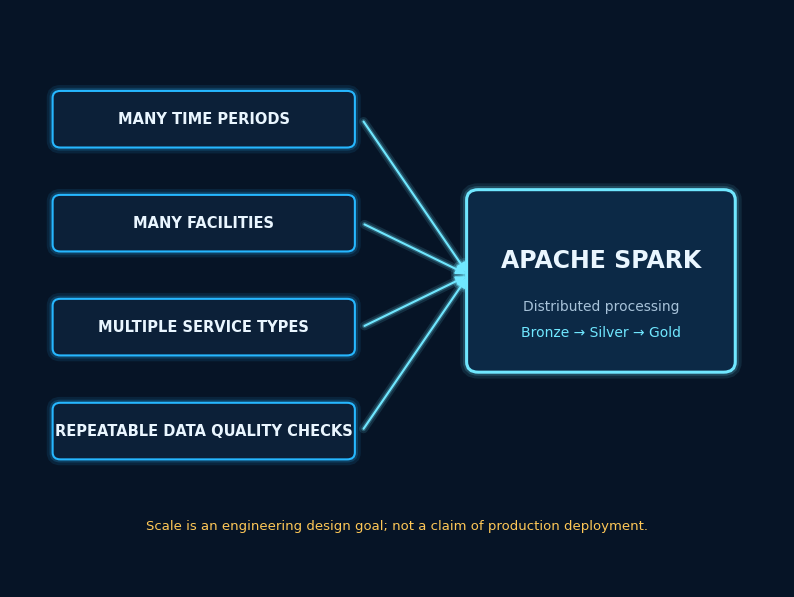

Saved: /content/afya_stream/figures/social_visual_05.png


In [18]:
# ============================================================
# VISUALIZATION 05 — BIG DATA / SPARK SCALE
# ============================================================
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(10, 7.5))
ax.set_xlim(0, 12)
ax.set_ylim(0, 10)
ax.axis("off")

items = [
    "MANY TIME PERIODS",
    "MANY FACILITIES",
    "MULTIPLE SERVICE TYPES",
    "REPEATABLE DATA QUALITY CHECKS"
]
ys = [8.1, 6.3, 4.5, 2.7]

for y, label in zip(ys, items):
    box = FancyBboxPatch(
        (0.7, y - 0.45), 4.6, 0.9,
        boxstyle="round,pad=0.04,rounding_size=0.12",
        facecolor=PANEL_BG, edgecolor=NEON_BLUE, linewidth=1.5
    )
    ax.add_patch(box)
    ax.text(
        3.0, y, label, ha="center", va="center",
        fontsize=10.5, fontweight="bold", color=TEXT_LIGHT
    )
    ax.add_patch(FancyArrowPatch(
        (5.45, y), (7.1, 5.4),
        arrowstyle="-|>", mutation_scale=14,
        linewidth=1.5, color=NEON_CYAN
    ))

spark = FancyBboxPatch(
    (7.15, 3.8), 4.0, 3.0,
    boxstyle="round,pad=0.08,rounding_size=0.18",
    facecolor="#0C2946", edgecolor=NEON_CYAN, linewidth=2.2
)
ax.add_patch(spark)
ax.text(
    9.15, 5.65, "APACHE SPARK",
    ha="center", va="center", fontsize=17,
    fontweight="bold", color=TEXT_LIGHT
)
ax.text(
    9.15, 4.85, "Distributed processing",
    ha="center", va="center", fontsize=10,
    color=TEXT_MUTED
)
ax.text(
    9.15, 4.4, "Bronze → Silver → Gold",
    ha="center", va="center", fontsize=10,
    color=NEON_CYAN
)

ax.text(
    6, 1.0,
    "Scale is an engineering design goal; not a claim of production deployment.",
    ha="center", fontsize=9.5, color=WARNING_AMBER
)

out = FIGURES_DIR / "social_visual_05.png"
apply_neon_style(fig)
fig.savefig(out, dpi=200, bbox_inches="tight")
apply_neon_style(fig)
plt.show()
print("Saved:", out)

## STAGE 11 — FORECASTING BASELINES & MACHINE LEARNING

In [19]:
# ============================================================
# STAGE 11 — BASELINES + MACHINE LEARNING FORECASTING
# ============================================================
# Project: AfyaStream AI
#
# Lengo:
#   1. Kutengeneza simple forecasting baselines.
#   2. Kufit classical ML models kwenye TRAIN.
#   3. Kutumia VALIDATION kwa model comparison.
#   4. Kutotumia TEST kabisa katika model selection.
#   5. Kupima MAE, RMSE, MAPE na sMAPE.
#   6. Kuonyesha performance kwenye normal na anomaly targets.
#   7. Kuhifadhi predictions + model comparison report.
#
# Models:
#   A. Naive Last-Value
#   B. Seasonal Naive (12-month lag)
#   C. Random Forest Regressor
#   D. HistGradientBoosting Regressor
#
# IMPORTANT:
#   - TEST data haitumiki hapa.
#   - anomaly_injected si feature.
#   - target_anomaly_injected si feature.
#   - target_next_month ndiyo target.
# ============================================================


# ------------------------------------------------------------
# 11.1 IMPORTS
# ------------------------------------------------------------

import os
import json
import joblib
import warnings

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.ensemble import (
    RandomForestRegressor,
    HistGradientBoostingRegressor,
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)


# Suppress only non-critical sklearn warnings.
warnings.filterwarnings(
    "ignore",
    category=UserWarning
)


# ------------------------------------------------------------
# 11.2 START
# ------------------------------------------------------------

print("=" * 75)
print("STAGE 11 — BASELINES + MACHINE LEARNING FORECASTING")
print("=" * 75)


# ------------------------------------------------------------
# 11.3 CHECK INPUT DATA
# ------------------------------------------------------------

required_objects = [
    "forecast_train_df",
    "forecast_validation_df",
    "forecast_test_df",
]


missing_objects = [
    obj
    for obj in required_objects
    if obj not in globals()
]


if missing_objects:

    raise RuntimeError(
        "Missing Stage 10 objects: "
        + ", ".join(missing_objects)
    )


# ------------------------------------------------------------
# 11.4 CHECK REQUIRED COLUMNS
# ------------------------------------------------------------

required_columns = [
    "facility_id",
    "facility_name",
    "service_type",
    "region",
    "facility_type",
    "hospital_level",
    "ownership",
    "month",
    "target_month",
    "demand",
    "target_next_month",
    "lag_1",
    "lag_2",
    "lag_3",
    "lag_6",
    "lag_12",
    "rolling_mean_3",
    "rolling_std_3",
    "rolling_mean_6",
    "rolling_std_6",
    "rolling_mean_12",
    "rolling_std_12",
    "growth_1m",
    "growth_3m",
    "growth_6m",
    "deviation_from_mean_3",
    "zscore_rolling_3",
    "month_sin",
    "month_cos",
    "time_index",
    "target_anomaly_injected",
]


for df_name, df in [
    ("TRAIN", forecast_train_df),
    ("VALIDATION", forecast_validation_df),
    ("TEST", forecast_test_df),
]:

    missing = [
        col
        for col in required_columns
        if col not in df.columns
    ]

    if missing:

        raise RuntimeError(
            f"{df_name} is missing columns: "
            + ", ".join(missing)
        )


print(
    "\n✅ Stage 10 modeling schema check passed."
)


# ------------------------------------------------------------
# 11.5 CONVERT TRAIN/VALIDATION TO PANDAS
# ------------------------------------------------------------
# Test intentionally not converted/used in Stage 11.

print(
    "\n[1] Converting TRAIN and VALIDATION to pandas..."
)


train_pd = (
    forecast_train_df
    .toPandas()
)


validation_pd = (
    forecast_validation_df
    .toPandas()
)


print(
    f"TRAIN pandas rows      : "
    f"{len(train_pd):,}"
)

print(
    f"VALIDATION pandas rows : "
    f"{len(validation_pd):,}"
)


if len(train_pd) == 0:
    raise RuntimeError(
        "TRAIN dataset is empty."
    )


if len(validation_pd) == 0:
    raise RuntimeError(
        "VALIDATION dataset is empty."
    )


# ------------------------------------------------------------
# 11.6 TARGET PREPARATION
# ------------------------------------------------------------

train_pd["target_next_month"] = pd.to_numeric(
    train_pd["target_next_month"],
    errors="coerce"
)

validation_pd["target_next_month"] = pd.to_numeric(
    validation_pd["target_next_month"],
    errors="coerce"
)


# Drop invalid target rows only.
train_pd = train_pd.dropna(
    subset=["target_next_month"]
).reset_index(drop=True)


validation_pd = validation_pd.dropna(
    subset=["target_next_month"]
).reset_index(drop=True)


y_train = (
    train_pd[
        "target_next_month"
    ]
    .astype(float)
    .to_numpy()
)


y_validation = (
    validation_pd[
        "target_next_month"
    ]
    .astype(float)
    .to_numpy()
)


# ------------------------------------------------------------
# 11.7 METRIC FUNCTIONS
# ------------------------------------------------------------

def safe_mape(
    y_true,
    y_pred
):

    y_true = np.asarray(
        y_true,
        dtype=float
    )

    y_pred = np.asarray(
        y_pred,
        dtype=float
    )

    mask = (
        np.abs(y_true) > 1e-8
    )

    if mask.sum() == 0:
        return np.nan

    return (
        np.mean(
            np.abs(
                (
                    y_true[mask]
                    - y_pred[mask]
                )
                /
                y_true[mask]
            )
        )
        * 100
    )


def safe_smape(
    y_true,
    y_pred
):

    y_true = np.asarray(
        y_true,
        dtype=float
    )

    y_pred = np.asarray(
        y_pred,
        dtype=float
    )

    denominator = (
        np.abs(y_true)
        +
        np.abs(y_pred)
    )

    numerator = (
        2
        * np.abs(
            y_pred
            - y_true
        )
    )

    mask = (
        denominator > 1e-8
    )

    if mask.sum() == 0:
        return np.nan

    return (
        np.mean(
            numerator[mask]
            /
            denominator[mask]
        )
        * 100
    )


def calculate_metrics(
    y_true,
    y_pred
):

    return {

        "MAE": float(
            mean_absolute_error(
                y_true,
                y_pred
            )
        ),

        "RMSE": float(
            np.sqrt(
                mean_squared_error(
                    y_true,
                    y_pred
                )
            )
        ),

        "MAPE_pct": float(
            safe_mape(
                y_true,
                y_pred
            )
        ),

        "sMAPE_pct": float(
            safe_smape(
                y_true,
                y_pred
            )
        ),

        "R2": float(
            r2_score(
                y_true,
                y_pred
            )
        ),
    }


# ------------------------------------------------------------
# 11.8 BASELINE A — NAIVE LAST VALUE
# ------------------------------------------------------------
# prediction(t+1) = demand(t)

print(
    "\n[2] Evaluating Naive Last-Value baseline..."
)


naive_validation_pred = (
    validation_pd[
        "demand"
    ]
    .astype(float)
    .to_numpy()
)


naive_metrics = calculate_metrics(
    y_validation,
    naive_validation_pred
)


# ------------------------------------------------------------
# 11.9 BASELINE B — SEASONAL NAIVE
# ------------------------------------------------------------
# prediction(t+1) = demand(t-12)
#
# Using lag_12 from the observation at month t.

print(
    "\n[3] Evaluating Seasonal Naive baseline..."
)


seasonal_validation_pred = (
    validation_pd[
        "lag_12"
    ]
    .astype(float)
)


# Any remaining missing lag_12 values are not expected
# in validation, but we guard against them.
seasonal_valid_mask = (
    seasonal_validation_pred
    .notna()
)


seasonal_y_validation = (
    y_validation[
        seasonal_valid_mask.to_numpy()
    ]
)


seasonal_validation_pred = (
    seasonal_validation_pred[
        seasonal_valid_mask
    ]
    .to_numpy()
)


seasonal_metrics = calculate_metrics(
    seasonal_y_validation,
    seasonal_validation_pred
)


# ------------------------------------------------------------
# 11.10 ML FEATURE SET
# ------------------------------------------------------------
# We deliberately DO NOT use:
#
#   facility_name
#   facility_id
#   month
#   target_month
#   target_next_month
#   anomaly_injected
#   target_anomaly_injected
#
# because:
#   - target fields would leak future information
#   - anomaly labels are evaluation metadata
#   - raw facility ID/name are identifiers rather than
#     generalizable predictors
#
# Hospital/service context remains available.

numeric_features = [

    "demand",

    "lag_1",
    "lag_2",
    "lag_3",
    "lag_6",
    "lag_12",

    "rolling_mean_3",
    "rolling_std_3",

    "rolling_mean_6",
    "rolling_std_6",

    "rolling_mean_12",
    "rolling_std_12",

    "growth_1m",
    "growth_3m",
    "growth_6m",

    "deviation_from_mean_3",

    "zscore_rolling_3",

    "month_sin",
    "month_cos",

    "time_index",
]


categorical_features = [

    "service_type",

    "region",

    "facility_type",

    "hospital_level",

    "ownership",
]


model_features = (
    numeric_features
    +
    categorical_features
)


# ------------------------------------------------------------
# 11.11 FEATURE LEAKAGE CHECK
# ------------------------------------------------------------

forbidden_features = [
    "anomaly_injected",
    "target_anomaly_injected",
    "target_next_month",
    "target_month",
]


leakage_features = [
    feature
    for feature in model_features
    if feature in forbidden_features
]


if leakage_features:

    raise RuntimeError(
        "Feature leakage detected: "
        + str(leakage_features)
    )


print(
    "\n✅ ML feature leakage check passed."
)


# ------------------------------------------------------------
# 11.12 BUILD X/y
# ------------------------------------------------------------

X_train = (
    train_pd[
        model_features
    ]
    .copy()
)


X_validation = (
    validation_pd[
        model_features
    ]
    .copy()
)


# ------------------------------------------------------------
# 11.13 PREPROCESSOR
# ------------------------------------------------------------
# Numeric:
#   median imputation
#
# Categorical:
#   most frequent imputation
#   one-hot encoding
#
# handle_unknown="ignore" allows a category appearing
# in validation but not in train.

numeric_transformer = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="median"
        )
    ),
])


categorical_transformer = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="most_frequent"
        )
    ),

    (
        "onehot",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False,
        )
    ),
])


preprocessor = ColumnTransformer([
    (
        "numeric",
        numeric_transformer,
        numeric_features,
    ),

    (
        "categorical",
        categorical_transformer,
        categorical_features,
    ),
])


# ------------------------------------------------------------
# 11.14 MODEL A — RANDOM FOREST
# ------------------------------------------------------------

print(
    "\n[4] Training Random Forest..."
)


random_forest_model = Pipeline([

    (
        "preprocessor",
        preprocessor
    ),

    (
        "model",
        RandomForestRegressor(

            n_estimators=250,

            max_depth=16,

            min_samples_leaf=2,

            max_features="sqrt",

            random_state=2026,

            n_jobs=-1,
        )
    ),
])


random_forest_model.fit(
    X_train,
    y_train
)


rf_validation_pred = (
    random_forest_model
    .predict(
        X_validation
    )
)


# Prevent impossible negative demand predictions.
rf_validation_pred = np.maximum(
    rf_validation_pred,
    0
)


rf_metrics = calculate_metrics(
    y_validation,
    rf_validation_pred
)


# ------------------------------------------------------------
# 11.15 MODEL B — HISTGRADIENTBOOSTING
# ------------------------------------------------------------

print(
    "\n[5] Training HistGradientBoosting..."
)


# HistGradientBoosting requires dense numerical input,
# therefore we use the same preprocessing pipeline.

hgb_model = Pipeline([

    (
        "preprocessor",
        preprocessor
    ),

    (
        "model",
        HistGradientBoostingRegressor(

            max_iter=300,

            learning_rate=0.05,

            max_leaf_nodes=31,

            l2_regularization=1.0,

            random_state=2026,
        )
    ),
])


hgb_model.fit(
    X_train,
    y_train
)


hgb_validation_pred = (
    hgb_model
    .predict(
        X_validation
    )
)


hgb_validation_pred = np.maximum(
    hgb_validation_pred,
    0
)


hgb_metrics = calculate_metrics(
    y_validation,
    hgb_validation_pred
)


# ------------------------------------------------------------
# 11.16 COMBINE MODEL RESULTS
# ------------------------------------------------------------

results = [

    {
        "model": "Naive_Last_Value",
        **naive_metrics,
    },

    {
        "model": "Seasonal_Naive_12M",
        **seasonal_metrics,
    },

    {
        "model": "Random_Forest",
        **rf_metrics,
    },

    {
        "model": "HistGradientBoosting",
        **hgb_metrics,
    },
]


results_df = (
    pd.DataFrame(
        results
    )
    .sort_values(
        by="MAE",
        ascending=True
    )
    .reset_index(
        drop=True
    )
)


print(
    "\n" + "=" * 75
)

print(
    "MODEL COMPARISON — VALIDATION"
)

print(
    "=" * 75
)


display(
    results_df
)


# ------------------------------------------------------------
# 11.17 NORMAL-TARGET PERFORMANCE
# ------------------------------------------------------------
# Because synthetic anomalies were deliberately injected,
# we also calculate metrics where the next-month target
# is NOT an injected anomaly.
#
# target_anomaly_injected is evaluation metadata ONLY.

normal_mask = (
    ~validation_pd[
        "target_anomaly_injected"
    ]
    .astype(bool)
    .to_numpy()
)


normal_y = (
    y_validation[
        normal_mask
    ]
)


normal_predictions = {

    "Naive_Last_Value":
        naive_validation_pred[
            normal_mask
        ],

    "Seasonal_Naive_12M":
        validation_pd[
            "lag_12"
        ]
        .fillna(
            validation_pd[
                "demand"
            ]
        )
        .to_numpy()[
            normal_mask
        ],

    "Random_Forest":
        rf_validation_pred[
            normal_mask
        ],

    "HistGradientBoosting":
        hgb_validation_pred[
            normal_mask
        ],
}


normal_results = []


for model_name, predictions in (
    normal_predictions.items()
):

    metrics = calculate_metrics(
        normal_y,
        predictions
    )

    normal_results.append({

        "model": model_name,

        **metrics,
    })


normal_results_df = (
    pd.DataFrame(
        normal_results
    )
    .sort_values(
        by="MAE"
    )
    .reset_index(
        drop=True
    )
)


print(
    "\nValidation performance on "
    "non-anomalous targets:"
)

display(
    normal_results_df
)


# ------------------------------------------------------------
# 11.18 ANOMALOUS-TARGET PERFORMANCE
# ------------------------------------------------------------

anomaly_mask = (
    validation_pd[
        "target_anomaly_injected"
    ]
    .astype(bool)
    .to_numpy()
)


anomaly_count = int(
    anomaly_mask.sum()
)


print(
    f"\nValidation anomaly-target rows: "
    f"{anomaly_count:,}"
)


if anomaly_count > 0:

    anomaly_y = (
        y_validation[
            anomaly_mask
        ]
    )


    anomaly_predictions = {

        "Naive_Last_Value":
            naive_validation_pred[
                anomaly_mask
            ],

        "Random_Forest":
            rf_validation_pred[
                anomaly_mask
            ],

        "HistGradientBoosting":
            hgb_validation_pred[
                anomaly_mask
            ],
    }


    anomaly_results = []


    for model_name, predictions in (
        anomaly_predictions.items()
    ):

        metrics = calculate_metrics(
            anomaly_y,
            predictions
        )

        anomaly_results.append({

            "model": model_name,

            **metrics,
        })


    anomaly_results_df = (
        pd.DataFrame(
            anomaly_results
        )
        .sort_values(
            by="MAE"
        )
        .reset_index(
            drop=True
        )
    )


    display(
        anomaly_results_df
    )

else:

    anomaly_results_df = (
        pd.DataFrame()
    )

    print(
        "No anomaly targets in validation."
    )


# ------------------------------------------------------------
# 11.19 SELECT MODEL USING VALIDATION
# ------------------------------------------------------------
# Ranking is internal model selection, not a claim about
# real-world superiority.
#
# Lower MAE is the selection criterion.

best_model_name = (
    results_df
    .iloc[0][
        "model"
    ]
)


print(
    "\nValidation-selected model:"
)

print(
    best_model_name
)


if best_model_name == "Random_Forest":

    selected_model = (
        random_forest_model
    )

    selected_validation_pred = (
        rf_validation_pred
    )

elif best_model_name == "HistGradientBoosting":

    selected_model = (
        hgb_model
    )

    selected_validation_pred = (
        hgb_validation_pred
    )

elif best_model_name == "Naive_Last_Value":

    selected_model = None

    selected_validation_pred = (
        naive_validation_pred
    )

elif best_model_name == "Seasonal_Naive_12M":

    selected_model = None

    selected_validation_pred = (
        validation_pd[
            "lag_12"
        ]
        .fillna(
            validation_pd[
                "demand"
            ]
        )
        .to_numpy()
    )

else:

    raise RuntimeError(
        "Unknown selected model: "
        + best_model_name
    )


# ------------------------------------------------------------
# 11.20 BUILD VALIDATION PREDICTION TABLE
# ------------------------------------------------------------

validation_predictions_df = (
    validation_pd[
        [
            "facility_id",
            "facility_name",
            "service_type",
            "region",
            "facility_type",
            "hospital_level",
            "ownership",
            "month",
            "target_month",
            "demand",
            "target_next_month",
            "target_anomaly_injected",
        ]
    ]
    .copy()
)


validation_predictions_df[
    "pred_naive"
] = naive_validation_pred


validation_predictions_df[
    "pred_seasonal_naive"
] = (
    validation_pd[
        "lag_12"
    ]
    .fillna(
        validation_pd[
            "demand"
        ]
    )
    .to_numpy()
)


validation_predictions_df[
    "pred_random_forest"
] = rf_validation_pred


validation_predictions_df[
    "pred_hist_gradient_boosting"
] = hgb_validation_pred


validation_predictions_df[
    "selected_model"
] = best_model_name


validation_predictions_df[
    "selected_prediction"
] = selected_validation_pred


validation_predictions_df[
    "selected_absolute_error"
] = np.abs(
    validation_predictions_df[
        "target_next_month"
    ]
    -
    validation_predictions_df[
        "selected_prediction"
    ]
)


# ------------------------------------------------------------
# 11.21 DAR ES SALAAM VALIDATION PERFORMANCE
# ------------------------------------------------------------

dar_validation = (
    validation_predictions_df[
        "region"
    ]
    .astype(str)
    .str.contains(
        "Dar es Salaam",
        case=False,
        na=False,
    )
)


dar_count = int(
    dar_validation.sum()
)


print(
    f"\nDar es Salaam validation rows: "
    f"{dar_count:,}"
)


if dar_count > 0:

    dar_y = (
        validation_predictions_df
        .loc[
            dar_validation,
            "target_next_month"
        ]
        .to_numpy()
    )

    dar_pred = (
        validation_predictions_df
        .loc[
            dar_validation,
            "selected_prediction"
        ]
        .to_numpy()
    )

    dar_metrics = calculate_metrics(
        dar_y,
        dar_pred
    )


    print(
        "\nDar es Salaam selected-model metrics:"
    )

    display(
        pd.DataFrame(
            [dar_metrics]
        )
    )


else:

    dar_metrics = {}


# ------------------------------------------------------------
# 11.22 FEATURE IMPORTANCE
# ------------------------------------------------------------
# Only available for tree-based selected ML model.
#
# This is exploratory feature interpretation.
# It does not establish causal importance.

feature_importance_df = (
    pd.DataFrame()
)


if best_model_name in [
    "Random_Forest",
    "HistGradientBoosting",
]:

    selected_pipeline = (
        selected_model
    )

    fitted_preprocessor = (
        selected_pipeline
        .named_steps[
            "preprocessor"
        ]
    )

    fitted_model = (
        selected_pipeline
        .named_steps[
            "model"
        ]
    )


    feature_names = (
        fitted_preprocessor
        .get_feature_names_out()
    )


    if hasattr(
        fitted_model,
        "feature_importances_"
    ):

        importances = (
            fitted_model
            .feature_importances_
        )

        feature_importance_df = (
            pd.DataFrame({

                "feature": feature_names,

                "importance": importances,
            })
            .sort_values(
                by="importance",
                ascending=False,
            )
            .reset_index(
                drop=True
            )
        )


        print(
            "\nTop feature importances:"
        )

        display(
            feature_importance_df
            .head(20)
        )


    else:

        print(
            "\nSelected model does not expose "
            "feature_importances_."
        )


# ------------------------------------------------------------
# 11.23 MODEL DIRECTORY
# ------------------------------------------------------------

MODEL_DIR = (
    "/content/afya_stream/models"
)

PREDICTION_DIR = (
    "/content/afya_stream/predictions"
)

AUDIT_DIR = (
    "/content/afya_stream/audit"
)


os.makedirs(
    MODEL_DIR,
    exist_ok=True
)

os.makedirs(
    PREDICTION_DIR,
    exist_ok=True
)

os.makedirs(
    AUDIT_DIR,
    exist_ok=True
)


# ------------------------------------------------------------
# 11.24 SAVE MODEL IF ML SELECTED
# ------------------------------------------------------------

selected_model_path = None


if selected_model is not None:

    selected_model_path = (
        MODEL_DIR
        + "/stage11_selected_forecaster.joblib"
    )

    joblib.dump(
        selected_model,
        selected_model_path
    )

    print(
        "\nSelected ML model saved:"
    )

    print(
        selected_model_path
    )


# ------------------------------------------------------------
# 11.25 SAVE VALIDATION PREDICTIONS
# ------------------------------------------------------------

validation_prediction_file = (
    PREDICTION_DIR
    + "/stage11_validation_predictions.csv"
)


validation_predictions_df.to_csv(
    validation_prediction_file,
    index=False,
    encoding="utf-8-sig"
)


print(
    "\nValidation predictions saved:"
)

print(
    validation_prediction_file
)


# ------------------------------------------------------------
# 11.26 SAVE MODEL COMPARISON
# ------------------------------------------------------------

model_comparison_file = (
    AUDIT_DIR
    + "/stage11_model_comparison.json"
)


model_comparison_report = {

    "project": "AfyaStream AI",

    "stage": (
        "Stage 11 - Baselines + Machine Learning Forecasting"
    ),

    "validation_rows": int(
        len(validation_pd)
    ),

    "models_evaluated": [
        "Naive_Last_Value",
        "Seasonal_Naive_12M",
        "Random_Forest",
        "HistGradientBoosting",
    ],

    "selection_metric": "MAE",

    "validation_results": (
        results_df
        .to_dict(
            orient="records"
        )
    ),

    "normal_target_results": (
        normal_results_df
        .to_dict(
            orient="records"
        )
    ),

    "anomaly_target_results": (
        anomaly_results_df
        .to_dict(
            orient="records"
        )
    ),

    "selected_model": best_model_name,

    "dar_es_salaam_metrics": dar_metrics,

    "forecast_features": model_features,

    "forbidden_features": forbidden_features,

    "test_data_used": False,

    "notes": [

        "Model selection used TRAIN fitting and VALIDATION evaluation.",

        "TEST data was intentionally excluded from Stage 11.",

        "anomaly_injected and target_anomaly_injected were not used as features.",

        "The current service-demand dataset is simulated.",

        "Feature importance is descriptive and does not imply causality.",
    ],
}


with open(
    model_comparison_file,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        model_comparison_report,
        f,
        indent=2,
        ensure_ascii=False,
    )


# ------------------------------------------------------------
# 11.27 FINAL SUMMARY
# ------------------------------------------------------------

print(
    "\n" + "=" * 75
)

print(
    "✅ STAGE 11 COMPLETED SUCCESSFULLY"
)

print(
    "=" * 75
)

print(
    "Model selection source : VALIDATION"
)

print(
    "TEST data used         : NO"
)

print(
    f"Selected model         : "
    f"{best_model_name}"
)

print(
    f"\nValidation MAE         : "
    f"{results_df.iloc[0]['MAE']:.4f}"
)

print(
    f"Validation RMSE        : "
    f"{results_df.iloc[0]['RMSE']:.4f}"
)

print(
    f"Validation sMAPE       : "
    f"{results_df.iloc[0]['sMAPE_pct']:.4f}%"
)

print(
    "\nReady for Stage 12:"
)

print(
    "validation_predictions_df"
)

print(
    "\nModel comparison report:"
)

print(
    model_comparison_file
)

STAGE 11 — BASELINES + MACHINE LEARNING FORECASTING

✅ Stage 10 modeling schema check passed.

[1] Converting TRAIN and VALIDATION to pandas...
TRAIN pandas rows      : 50,336
VALIDATION pandas rows : 11,616

[2] Evaluating Naive Last-Value baseline...

[3] Evaluating Seasonal Naive baseline...

✅ ML feature leakage check passed.

[4] Training Random Forest...

[5] Training HistGradientBoosting...

MODEL COMPARISON — VALIDATION


,model,MAE,RMSE,MAPE_pct,sMAPE_pct,R2
0,HistGradientBoosting,42.412652,112.640775,7.568165,7.509575,0.969114
1,Random_Forest,43.569053,113.710828,7.631770,7.553427,0.968524
2,Naive_Last_Value,55.767045,136.989159,10.038309,9.945648,0.954318
3,Seasonal_Naive_12M,58.011794,143.978474,10.201168,10.394102,0.949537



Validation performance on non-anomalous targets:


,model,MAE,RMSE,MAPE_pct,sMAPE_pct,R2
0,HistGradientBoosting,39.016359,79.552264,7.340501,7.184960,0.984066
1,Random_Forest,40.142323,79.832667,7.403003,7.226697,0.983954
2,Naive_Last_Value,52.248031,107.572061,9.814689,9.617308,0.970865
3,Seasonal_Naive_12M,54.494678,117.104922,9.973421,10.059566,0.965473



Validation anomaly-target rows: 61


,model,MAE,RMSE,MAPE_pct,sMAPE_pct,R2
0,HistGradientBoosting,685.759622,1103.322991,50.693802,69.000223,0.486516
1,Random_Forest,692.681638,1120.258254,50.966297,69.444531,0.470632
2,Naive_Last_Value,722.360656,1175.394248,52.397762,72.141884,0.417242



Validation-selected model:
HistGradientBoosting

Dar es Salaam validation rows: 1,872

Dar es Salaam selected-model metrics:


,MAE,RMSE,MAPE_pct,sMAPE_pct,R2
0,58.732943,139.346355,7.639396,7.649512,0.973012



Selected model does not expose feature_importances_.

Selected ML model saved:
/content/afya_stream/models/stage11_selected_forecaster.joblib

Validation predictions saved:
/content/afya_stream/predictions/stage11_validation_predictions.csv

✅ STAGE 11 COMPLETED SUCCESSFULLY
Model selection source : VALIDATION
TEST data used         : NO
Selected model         : HistGradientBoosting

Validation MAE         : 42.4127
Validation RMSE        : 112.6408
Validation sMAPE       : 7.5096%

Ready for Stage 12:
validation_predictions_df

Model comparison report:
/content/afya_stream/audit/stage11_model_comparison.json


# SOCIAL MEDIA — POST 06/13

## **Data ya afya haipaswi kuishia kwenye CSV.**

Records za mfano zinaweza kureplay kama stream ili kuonyesha namna mfumo wa streaming unavyofanya kazi.

**Kafka → Spark → Features → Model → Signal**

> Hii ni streaming simulation/replay, si live clinical feed.

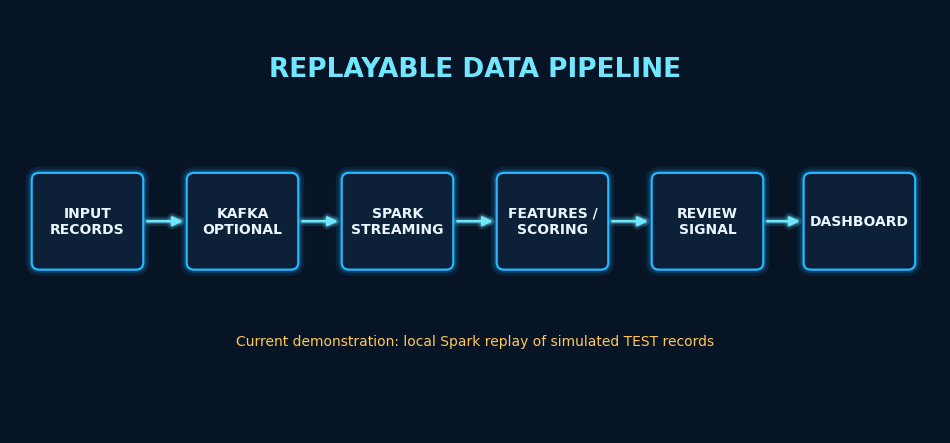

Saved: /content/afya_stream/figures/social_visual_06.png


In [20]:
# ============================================================
# VISUALIZATION 06 — STREAMING ARCHITECTURE
# ============================================================
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(12, 5.5))
ax.set_xlim(0, 15)
ax.set_ylim(0, 7)
ax.axis("off")

steps = [
    (1.25, "INPUT\nRECORDS"),
    (3.75, "KAFKA\nOPTIONAL"),
    (6.25, "SPARK\nSTREAMING"),
    (8.75, "FEATURES /\nSCORING"),
    (11.25, "REVIEW\nSIGNAL"),
    (13.7, "DASHBOARD")
]

for x, label in steps:
    box = FancyBboxPatch(
        (x - 0.85, 2.75), 1.7, 1.5,
        boxstyle="round,pad=0.05,rounding_size=0.12",
        facecolor=PANEL_BG, edgecolor=NEON_BLUE, linewidth=1.6
    )
    ax.add_patch(box)
    ax.text(
        x, 3.5, label, ha="center", va="center",
        fontsize=10, fontweight="bold", color=TEXT_LIGHT
    )

for (x1, _), (x2, _) in zip(steps[:-1], steps[1:]):
    ax.add_patch(FancyArrowPatch(
        (x1 + 0.92, 3.5), (x2 - 0.92, 3.5),
        arrowstyle="-|>", mutation_scale=14,
        linewidth=1.8, color=NEON_CYAN
    ))

ax.text(
    7.5, 5.9, "REPLAYABLE DATA PIPELINE",
    ha="center", fontsize=19, fontweight="bold",
    color=NEON_CYAN
)
ax.text(
    7.5, 1.45,
    "Current demonstration: local Spark replay of simulated TEST records",
    ha="center", fontsize=10, color=WARNING_AMBER
)

out = FIGURES_DIR / "social_visual_06.png"
apply_neon_style(fig)
fig.savefig(out, dpi=200, bbox_inches="tight")
apply_neon_style(fig)
plt.show()
print("Saved:", out)

## STAGE 12 — ANOMALY DETECTION

STAGE 12 — FINAL TEST FORECAST + ANOMALY DETECTION

✅ Forecast feature leakage check passed.

[1] Loading TRAIN, VALIDATION and TEST...
TRAIN rows       : 50,336
VALIDATION rows  : 11,616
TEST rows        : 23,232

[2] Fitting validation calibration model...

Validation anomaly-threshold search:


,quantile,threshold,predicted_anomalies,actual_anomalies,precision,recall,f1
0,0.990,361.164469,117,61,0.273504,0.524590,0.359551
1,0.997,682.489344,35,61,0.485714,0.278689,0.354167
2,0.995,482.509613,59,61,0.338983,0.327869,0.333333
3,0.985,303.388662,175,61,0.211429,0.606557,0.313559
4,0.999,1298.836126,12,61,0.916667,0.180328,0.301370
5,0.980,261.636257,233,61,0.163090,0.622951,0.258503
6,0.975,237.367292,291,61,0.140893,0.672131,0.232955
7,0.970,221.435568,349,61,0.123209,0.704918,0.209756
8,0.950,168.665435,581,61,0.084337,0.803279,0.152648



Validation-selected anomaly threshold:
Quantile  : 0.99
Threshold : 361.1645

[3] Fitting final forecasting model on TRAIN + VALIDATION...

[4] Generating TEST forecasts...

ANOMALY DETECTION — TEST
Actual anomalies       : 81
Predicted anomalies    : 221
True positives         : 30
False positives        : 191
False negatives        : 51
Precision              : 0.1357
Recall                 : 0.3704
F1                     : 0.1987

FINAL TEST FORECAST PERFORMANCE
TEST rows              : 23,232
MAE                    : 43.1882
RMSE                   : 101.1471
MAPE                   : 7.5632%
sMAPE                  : 7.4912%
R2                     : 0.9781

Normal-target test performance:


,MAE,RMSE,MAPE_pct,sMAPE_pct,R2
0,41.630903,90.616158,7.415121,7.281275,0.982295



Dar es Salaam TEST performance:
Dar es Salaam TEST rows: 3,744


,MAE,RMSE,MAPE_pct,sMAPE_pct,R2
0,59.865558,125.480888,7.643094,7.588963,0.980604



Featured hospital test performance:
Featured hospital test rows: 912


,facility_name,rows,MAE,RMSE,MAPE_pct,sMAPE_pct,R2,actual_anomalies,detected_anomalies,anomaly_F1
0,DR. JAKAYA KIKWETE,48,20.450075,30.433438,8.760355,8.477652,0.990086,0,0,0.000000
1,LUGALO RCH,48,42.625199,88.357709,7.310109,7.309730,0.973177,0,1,0.000000
2,MWANANYAMALA,48,52.025124,81.709895,7.063740,6.969073,0.990918,0,0,0.000000
3,MT. MERU,48,54.415136,97.322542,6.762121,6.727224,0.983701,0,0,0.000000
4,KCMC,48,54.804056,101.947306,6.602968,6.445499,0.986973,0,1,0.000000
5,AMANA,48,59.688461,97.371608,6.815762,6.731338,0.990717,0,0,0.000000
6,MBEYA,144,60.644228,113.903879,6.841249,6.819362,0.987674,0,5,0.000000
7,Temeke,48,62.723927,89.661293,7.826678,7.645348,0.992240,0,0,0.000000
8,BUGANDO MEDICAL CENTRE (BMC),48,73.734376,123.213215,8.087985,7.990866,0.984444,0,1,0.000000
9,AGA KHAN,48,74.265368,137.716946,7.716316,7.884528,0.976042,1,2,0.666667



Top detected anomalous test records:


,target_month,facility_id,facility_name,service_type,region,target_next_month,forecast_prediction,forecast_residual,absolute_residual,target_anomaly_injected,predicted_anomaly
5942,2025-03-01,101192-3,GEITA,Outpatient Visits,Geita Region,5835.0,2073.154871,3761.845129,3761.845129,True,True
16379,2025-12-01,110886-9,Kibong'oto Infectious Diseases (KIDH),Outpatient Visits,Kilimanjaro Region,7698.0,4454.666149,3243.333851,3243.333851,False,True
12971,2025-12-01,107541-5,SONGAMBELE,Outpatient Visits,Simiyu Region,4040.0,1715.569898,2324.430102,2324.430102,False,True
7394,2025-03-01,110299-5,MZINGA,Outpatient Visits,Morogoro Region,4466.0,2230.983875,2235.016125,2235.016125,True,True
1847,2025-12-01,113689-4,NJOMBE,Outpatient Visits,Njombe Region,4284.0,2057.731232,2226.268768,2226.268768,False,True
2012,2025-09-01,113980-7,ST MONICA,Outpatient Visits,Kilimanjaro Region,3550.0,1355.047655,2194.952345,2194.952345,True,True
12191,2025-12-01,102621-0,KIBOSHO,Outpatient Visits,Kilimanjaro Region,3518.0,1421.592009,2096.407991,2096.407991,False,True
18791,2025-12-01,107590-2,ST. GEMMA,Outpatient Visits,Dodoma Region,3310.0,1362.865864,1947.134136,1947.134136,False,True
20588,2025-09-01,101837-3,ST' ANN'S MISSION,Outpatient Visits,Tabora Region,3042.0,1260.572028,1781.427972,1781.427972,True,True
4790,2025-03-01,114003-7,UYUI,Outpatient Visits,Tabora Region,2905.0,1317.573619,1587.426381,1587.426381,True,True


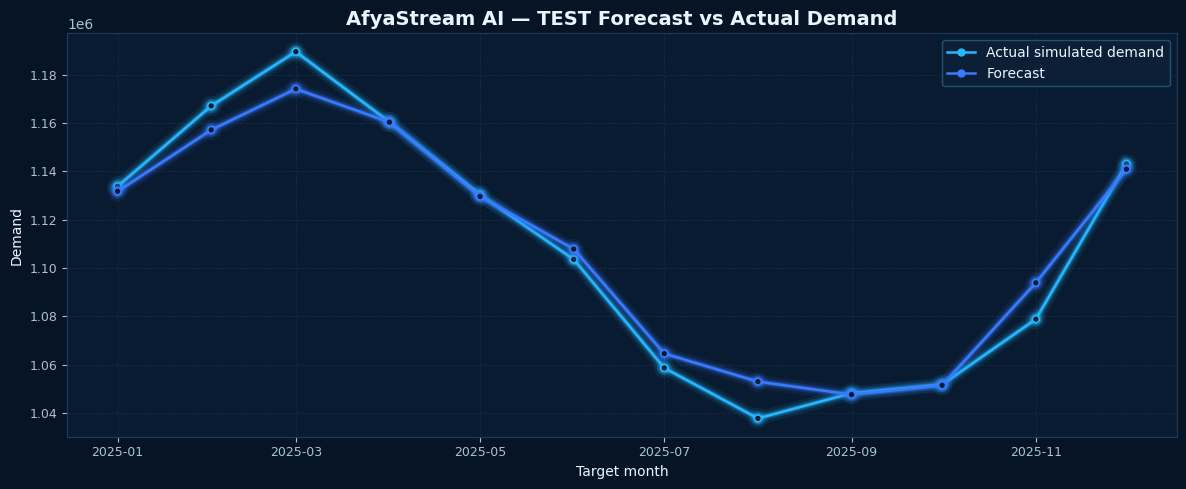

Saved: /content/afya_stream/figures/stage12/stage12_test_forecast_vs_actual.png


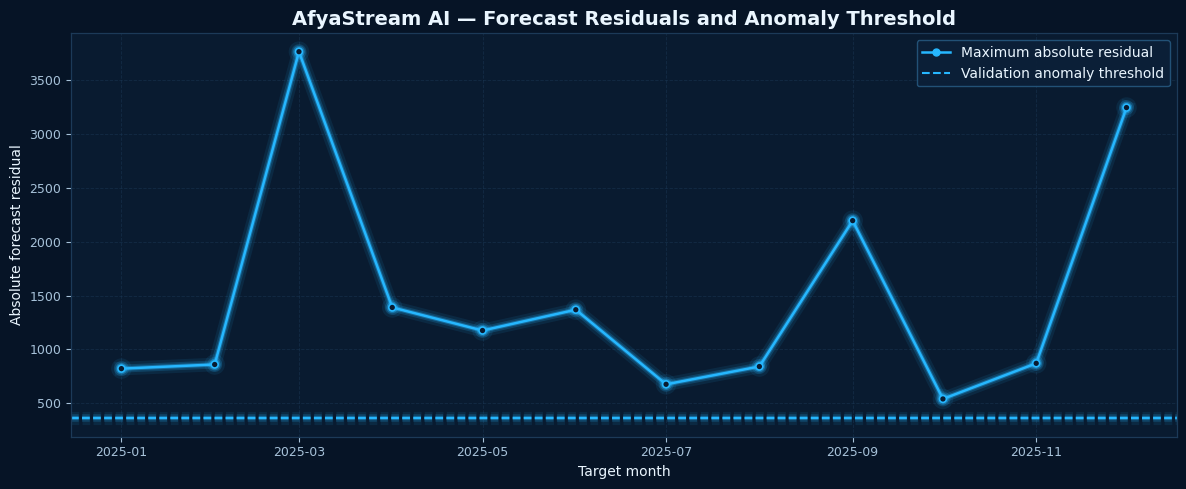

Saved: /content/afya_stream/figures/stage12/stage12_residual_anomaly_threshold.png

Final model saved:
/content/afya_stream/models/stage12_final_forecaster.joblib

✅ STAGE 12 COMPLETED SUCCESSFULLY
Final TEST rows          : 23,232
Final TEST MAE           : 43.1882
Final TEST RMSE          : 101.1471
Final TEST MAPE          : 7.5632%
Final TEST sMAPE         : 7.4912%
Final TEST R2            : 0.9781

Anomaly threshold        : 361.1645
Anomaly precision        : 0.1357
Anomaly recall           : 0.3704
Anomaly F1               : 0.1987

Featured hospital rows   : 912

TEST data was NOT used for model/threshold selection.

Ready for Stage 13:
final_test_predictions_df
anomaly_detection_test_df

Final evaluation report:
/content/afya_stream/audit/stage12_final_evaluation_report.json


In [21]:
# ============================================================
# STAGE 12 — FINAL TEST FORECAST + ANOMALY DETECTION
# ============================================================
# Project: AfyaStream AI
#
# Lengo:
#   1. Kufit final forecasting model kwenye TRAIN + VALIDATION.
#   2. Kutathmini model mara moja kwenye TEST.
#   3. Kujenga forecast residuals.
#   4. Kuchagua anomaly threshold kwa VALIDATION.
#   5. Kutest anomaly detection kwenye TEST.
#   6. Kutathmini Dar es Salaam.
#   7. Kutathmini featured hospitals individually.
#   8. Kuhifadhi predictions, metrics, model na figures.
#
# IMPORTANT:
#   - TEST haitumiki kuchagua model wala threshold.
#   - anomaly labels si model features.
#   - Current health-service dataset ni SIMULATED.
# ============================================================


# ------------------------------------------------------------
# 12.1 IMPORTS
# ------------------------------------------------------------

import os
import json
import warnings
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.ensemble import (
    HistGradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)


warnings.filterwarnings(
    "ignore",
    category=UserWarning
)


# ------------------------------------------------------------
# 12.2 START
# ------------------------------------------------------------

print("=" * 75)
print("STAGE 12 — FINAL TEST FORECAST + ANOMALY DETECTION")
print("=" * 75)


# ------------------------------------------------------------
# 12.3 CHECK REQUIRED OBJECTS
# ------------------------------------------------------------

required_objects = [
    "forecast_train_df",
    "forecast_validation_df",
    "forecast_test_df",
]


missing_objects = [
    obj
    for obj in required_objects
    if obj not in globals()
]


if missing_objects:

    raise RuntimeError(
        "Missing required objects: "
        + ", ".join(missing_objects)
    )


# ------------------------------------------------------------
# 12.4 MODEL FEATURES
# ------------------------------------------------------------

numeric_features = [

    "demand",

    "lag_1",
    "lag_2",
    "lag_3",
    "lag_6",
    "lag_12",

    "rolling_mean_3",
    "rolling_std_3",

    "rolling_mean_6",
    "rolling_std_6",

    "rolling_mean_12",
    "rolling_std_12",

    "growth_1m",
    "growth_3m",
    "growth_6m",

    "deviation_from_mean_3",

    "zscore_rolling_3",

    "month_sin",
    "month_cos",

    "time_index",
]


categorical_features = [

    "service_type",

    "region",

    "facility_type",

    "hospital_level",

    "ownership",
]


model_features = (
    numeric_features
    +
    categorical_features
)


# ------------------------------------------------------------
# 12.5 LEAKAGE CHECK
# ------------------------------------------------------------

forbidden_features = [
    "anomaly_injected",
    "target_anomaly_injected",
    "target_next_month",
    "target_month",
]


leakage_features = [
    feature
    for feature in model_features
    if feature in forbidden_features
]


if leakage_features:

    raise RuntimeError(
        "Forecast leakage detected: "
        + str(leakage_features)
    )


print(
    "\n✅ Forecast feature leakage check passed."
)


# ------------------------------------------------------------
# 12.6 LOAD TRAIN / VALIDATION / TEST
# ------------------------------------------------------------

print(
    "\n[1] Loading TRAIN, VALIDATION and TEST..."
)


train12 = (
    forecast_train_df
    .toPandas()
)

validation12 = (
    forecast_validation_df
    .toPandas()
)

test12 = (
    forecast_test_df
    .toPandas()
)


print(
    f"TRAIN rows       : {len(train12):,}"
)

print(
    f"VALIDATION rows  : {len(validation12):,}"
)

print(
    f"TEST rows        : {len(test12):,}"
)


if (
    len(train12) == 0
    or len(validation12) == 0
    or len(test12) == 0
):

    raise RuntimeError(
        "One or more modeling datasets are empty."
    )


# ------------------------------------------------------------
# 12.7 TARGET TYPE CLEANING
# ------------------------------------------------------------

for df in [
    train12,
    validation12,
    test12,
]:

    df["target_next_month"] = pd.to_numeric(
        df["target_next_month"],
        errors="coerce"
    )

    df["demand"] = pd.to_numeric(
        df["demand"],
        errors="coerce"
    )


# Remove rows without target
train12 = (
    train12
    .dropna(
        subset=[
            "target_next_month"
        ]
    )
    .reset_index(
        drop=True
    )
)


validation12 = (
    validation12
    .dropna(
        subset=[
            "target_next_month"
        ]
    )
    .reset_index(
        drop=True
    )
)


test12 = (
    test12
    .dropna(
        subset=[
            "target_next_month"
        ]
    )
    .reset_index(
        drop=True
    )
)


# ------------------------------------------------------------
# 12.8 TARGET ARRAYS
# ------------------------------------------------------------

y_train = (
    train12[
        "target_next_month"
    ]
    .astype(float)
    .to_numpy()
)


y_validation = (
    validation12[
        "target_next_month"
    ]
    .astype(float)
    .to_numpy()
)


y_test = (
    test12[
        "target_next_month"
    ]
    .astype(float)
    .to_numpy()
)


# ------------------------------------------------------------
# 12.9 METRIC FUNCTIONS
# ------------------------------------------------------------

def safe_mape12(
    y_true,
    y_pred
):

    y_true = np.asarray(
        y_true,
        dtype=float
    )

    y_pred = np.asarray(
        y_pred,
        dtype=float
    )

    mask = (
        np.abs(y_true) > 1e-8
    )

    if mask.sum() == 0:
        return np.nan

    return (
        np.mean(
            np.abs(
                (
                    y_true[mask]
                    -
                    y_pred[mask]
                )
                /
                y_true[mask]
            )
        )
        * 100
    )


def safe_smape12(
    y_true,
    y_pred
):

    y_true = np.asarray(
        y_true,
        dtype=float
    )

    y_pred = np.asarray(
        y_pred,
        dtype=float
    )

    denominator = (
        np.abs(y_true)
        +
        np.abs(y_pred)
    )

    numerator = (
        2
        *
        np.abs(
            y_pred
            -
            y_true
        )
    )

    mask = (
        denominator > 1e-8
    )

    if mask.sum() == 0:
        return np.nan

    return (
        np.mean(
            numerator[mask]
            /
            denominator[mask]
        )
        * 100
    )


def calculate_metrics12(
    y_true,
    y_pred
):

    return {

        "MAE": float(
            mean_absolute_error(
                y_true,
                y_pred
            )
        ),

        "RMSE": float(
            np.sqrt(
                mean_squared_error(
                    y_true,
                    y_pred
                )
            )
        ),

        "MAPE_pct": float(
            safe_mape12(
                y_true,
                y_pred
            )
        ),

        "sMAPE_pct": float(
            safe_smape12(
                y_true,
                y_pred
            )
        ),

        "R2": float(
            r2_score(
                y_true,
                y_pred
            )
        ),
    }


# ------------------------------------------------------------
# 12.10 CREATE PREPROCESSOR
# ------------------------------------------------------------

numeric_transformer = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="median"
        )
    )
])


categorical_transformer = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="most_frequent"
        )
    ),

    (
        "onehot",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )
    )
])


preprocessor = ColumnTransformer([

    (
        "numeric",
        numeric_transformer,
        numeric_features
    ),

    (
        "categorical",
        categorical_transformer,
        categorical_features
    ),
])


# ------------------------------------------------------------
# 12.11 FIT VALIDATION CALIBRATION MODEL
# ------------------------------------------------------------

print(
    "\n[2] Fitting validation calibration model..."
)


validation_model = Pipeline([

    (
        "preprocessor",
        preprocessor
    ),

    (
        "model",
        HistGradientBoostingRegressor(

            max_iter=300,

            learning_rate=0.05,

            max_leaf_nodes=31,

            l2_regularization=1.0,

            random_state=2026,
        )
    ),
])


validation_model.fit(
    train12[
        model_features
    ],
    y_train
)


# ------------------------------------------------------------
# 12.12 VALIDATION PREDICTIONS
# ------------------------------------------------------------

validation_prediction = (
    validation_model
    .predict(
        validation12[
            model_features
        ]
    )
)


validation_prediction = np.maximum(
    validation_prediction,
    0
)


validation12[
    "forecast_prediction"
] = validation_prediction


validation12[
    "forecast_residual"
] = (
    validation12[
        "target_next_month"
    ]
    -
    validation12[
        "forecast_prediction"
    ]
)


validation12[
    "absolute_residual"
] = np.abs(
    validation12[
        "forecast_residual"
    ]
)


# ------------------------------------------------------------
# 12.13 VALIDATION ANOMALY LABELS
# ------------------------------------------------------------

validation_true_anomaly = (
    validation12[
        "target_anomaly_injected"
    ]
    .astype(bool)
    .to_numpy()
)


# ------------------------------------------------------------
# 12.14 THRESHOLD SEARCH
# ------------------------------------------------------------
# Threshold is selected ONLY on validation.

candidate_quantiles = [
    0.95,
    0.97,
    0.975,
    0.98,
    0.985,
    0.99,
    0.995,
    0.997,
    0.999,
]


threshold_results = []


for q in candidate_quantiles:

    threshold = float(
        np.quantile(
            validation12[
                "absolute_residual"
            ],
            q
        )
    )


    predicted_anomaly = (
        validation12[
            "absolute_residual"
        ]
        >= threshold
    )


    precision = precision_score(
        validation_true_anomaly,
        predicted_anomaly,
        zero_division=0
    )


    recall = recall_score(
        validation_true_anomaly,
        predicted_anomaly,
        zero_division=0
    )


    f1 = f1_score(
        validation_true_anomaly,
        predicted_anomaly,
        zero_division=0
    )


    threshold_results.append({

        "quantile": q,

        "threshold": threshold,

        "predicted_anomalies": int(
            predicted_anomaly.sum()
        ),

        "actual_anomalies": int(
            validation_true_anomaly.sum()
        ),

        "precision": precision,

        "recall": recall,

        "f1": f1,
    })


threshold_results_df = (
    pd.DataFrame(
        threshold_results
    )
    .sort_values(
        by=[
            "f1",
            "precision",
            "recall",
        ],
        ascending=False
    )
    .reset_index(
        drop=True
    )
)


print(
    "\nValidation anomaly-threshold search:"
)


display(
    threshold_results_df
)


# ------------------------------------------------------------
# 12.15 SELECT THRESHOLD
# ------------------------------------------------------------

selected_quantile = float(
    threshold_results_df.iloc[0][
        "quantile"
    ]
)


selected_threshold = float(
    threshold_results_df.iloc[0][
        "threshold"
    ]
)


print(
    "\nValidation-selected anomaly threshold:"
)


print(
    f"Quantile  : {selected_quantile}"
)


print(
    f"Threshold : {selected_threshold:.4f}"
)


# ------------------------------------------------------------
# 12.16 FINAL MODEL — TRAIN + VALIDATION
# ------------------------------------------------------------

print(
    "\n[3] Fitting final forecasting model "
    "on TRAIN + VALIDATION..."
)


train_validation12 = pd.concat(
    [
        train12,
        validation12,
    ],
    ignore_index=True
)


y_train_validation = (
    train_validation12[
        "target_next_month"
    ]
    .astype(float)
    .to_numpy()
)


final_preprocessor = ColumnTransformer([

    (
        "numeric",

        Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="median"
                )
            )
        ]),

        numeric_features,
    ),

    (
        "categorical",

        Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="most_frequent"
                )
            ),

            (
                "onehot",
                OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False
                )
            )
        ]),

        categorical_features,
    ),
])


final_forecast_model = Pipeline([

    (
        "preprocessor",
        final_preprocessor
    ),

    (
        "model",
        HistGradientBoostingRegressor(

            max_iter=300,

            learning_rate=0.05,

            max_leaf_nodes=31,

            l2_regularization=1.0,

            random_state=2026,
        )
    ),
])


final_forecast_model.fit(
    train_validation12[
        model_features
    ],
    y_train_validation
)


# ------------------------------------------------------------
# 12.17 FINAL TEST FORECAST
# ------------------------------------------------------------

print(
    "\n[4] Generating TEST forecasts..."
)


test_prediction = (
    final_forecast_model
    .predict(
        test12[
            model_features
        ]
    )
)


test_prediction = np.maximum(
    test_prediction,
    0
)


test12[
    "forecast_prediction"
] = test_prediction


test12[
    "forecast_residual"
] = (
    test12[
        "target_next_month"
    ]
    -
    test12[
        "forecast_prediction"
    ]
)


test12[
    "absolute_residual"
] = np.abs(
    test12[
        "forecast_residual"
    ]
)


# ------------------------------------------------------------
# 12.18 FINAL TEST FORECAST METRICS
# ------------------------------------------------------------

test_forecast_metrics = (
    calculate_metrics12(
        y_test,
        test_prediction
    )
)


# ------------------------------------------------------------
# 12.19 NORMAL TARGET TEST METRICS
# ------------------------------------------------------------

test_true_anomaly = (
    test12[
        "target_anomaly_injected"
    ]
    .astype(bool)
    .to_numpy()
)


normal_test_mask = (
    ~test_true_anomaly
)


normal_test_metrics = (
    calculate_metrics12(
        y_test[
            normal_test_mask
        ],
        test_prediction[
            normal_test_mask
        ]
    )
)


# ------------------------------------------------------------
# 12.20 TEST ANOMALY DETECTION
# ------------------------------------------------------------
# Threshold comes ONLY from validation.

test_detected_anomaly = (
    test12[
        "absolute_residual"
    ]
    >= selected_threshold
)


test12[
    "predicted_anomaly"
] = (
    test_detected_anomaly
)


# ------------------------------------------------------------
# 12.21 ANOMALY METRICS
# ------------------------------------------------------------

anomaly_precision = precision_score(
    test_true_anomaly,
    test_detected_anomaly,
    zero_division=0
)


anomaly_recall = recall_score(
    test_true_anomaly,
    test_detected_anomaly,
    zero_division=0
)


anomaly_f1 = f1_score(
    test_true_anomaly,
    test_detected_anomaly,
    zero_division=0
)


tn, fp, fn, tp = confusion_matrix(
    test_true_anomaly,
    test_detected_anomaly,
    labels=[
        False,
        True
    ]
).ravel()


# ------------------------------------------------------------
# 12.22 ANOMALY SUMMARY
# ------------------------------------------------------------

print(
    "\n" + "=" * 75
)

print(
    "ANOMALY DETECTION — TEST"
)

print(
    "=" * 75
)


print(
    f"Actual anomalies       : "
    f"{int(test_true_anomaly.sum()):,}"
)


print(
    f"Predicted anomalies    : "
    f"{int(test_detected_anomaly.sum()):,}"
)


print(
    f"True positives         : "
    f"{int(tp):,}"
)


print(
    f"False positives        : "
    f"{int(fp):,}"
)


print(
    f"False negatives        : "
    f"{int(fn):,}"
)


print(
    f"Precision              : "
    f"{anomaly_precision:.4f}"
)


print(
    f"Recall                 : "
    f"{anomaly_recall:.4f}"
)


print(
    f"F1                     : "
    f"{anomaly_f1:.4f}"
)


# ------------------------------------------------------------
# 12.23 FINAL FORECAST SUMMARY
# ------------------------------------------------------------

print(
    "\n" + "=" * 75
)

print(
    "FINAL TEST FORECAST PERFORMANCE"
)

print(
    "=" * 75
)


print(
    f"TEST rows              : "
    f"{len(test12):,}"
)


print(
    f"MAE                    : "
    f"{test_forecast_metrics['MAE']:.4f}"
)


print(
    f"RMSE                   : "
    f"{test_forecast_metrics['RMSE']:.4f}"
)


print(
    f"MAPE                   : "
    f"{test_forecast_metrics['MAPE_pct']:.4f}%"
)


print(
    f"sMAPE                  : "
    f"{test_forecast_metrics['sMAPE_pct']:.4f}%"
)


print(
    f"R2                     : "
    f"{test_forecast_metrics['R2']:.4f}"
)


print(
    "\nNormal-target test performance:"
)


display(
    pd.DataFrame(
        [normal_test_metrics]
    )
)


# ------------------------------------------------------------
# 12.24 DAR ES SALAAM TEST PERFORMANCE
# ------------------------------------------------------------

print(
    "\nDar es Salaam TEST performance:"
)


dar_test_mask = (
    test12[
        "region"
    ]
    .astype(str)
    .str.contains(
        "Dar es Salaam",
        case=False,
        na=False
    )
)


dar_test_count = int(
    dar_test_mask.sum()
)


print(
    f"Dar es Salaam TEST rows: "
    f"{dar_test_count:,}"
)


if dar_test_count > 0:

    dar_test_metrics = (
        calculate_metrics12(

            y_test[
                dar_test_mask
            ],

            test_prediction[
                dar_test_mask
            ],
        )
    )


    display(
        pd.DataFrame(
            [dar_test_metrics]
        )
    )


else:

    dar_test_metrics = {}


# ------------------------------------------------------------
# 12.25 FEATURED HOSPITAL TEST PERFORMANCE
# ------------------------------------------------------------
# FIX:
#   Direct filtering using featured_hospital.
#   No nested Series.isin().

print(
    "\nFeatured hospital test performance:"
)


if "featured_hospital" in test12.columns:

    featured_test_df = (
        test12.loc[
            test12[
                "featured_hospital"
            ]
            .astype(bool)
        ]
        .copy()
        .reset_index(
            drop=True
        )
    )

else:

    featured_test_df = (
        test12.iloc[
            0:0
        ]
        .copy()
    )


print(
    f"Featured hospital test rows: "
    f"{len(featured_test_df):,}"
)


if not featured_test_df.empty:

    featured_performance_rows = []


    for hospital_name in sorted(
        featured_test_df[
            "facility_name"
        ]
        .dropna()
        .unique()
    ):

        hospital_mask = (
            featured_test_df[
                "facility_name"
            ]
            == hospital_name
        )


        actual = (
            featured_test_df
            .loc[
                hospital_mask,
                "target_next_month"
            ]
            .astype(float)
            .to_numpy()
        )


        predicted = (
            featured_test_df
            .loc[
                hospital_mask,
                "forecast_prediction"
            ]
            .astype(float)
            .to_numpy()
        )


        hospital_metrics = (
            calculate_metrics12(
                actual,
                predicted
            )
        )


        hospital_anomaly_actual = (
            featured_test_df
            .loc[
                hospital_mask,
                "target_anomaly_injected"
            ]
            .astype(bool)
            .to_numpy()
        )


        hospital_anomaly_predicted = (
            featured_test_df
            .loc[
                hospital_mask,
                "predicted_anomaly"
            ]
            .astype(bool)
            .to_numpy()
        )


        hospital_anomaly_f1 = (
            f1_score(
                hospital_anomaly_actual,
                hospital_anomaly_predicted,
                zero_division=0
            )
        )


        featured_performance_rows.append({

            "facility_name": hospital_name,

            "rows": int(
                hospital_mask.sum()
            ),

            "MAE": hospital_metrics[
                "MAE"
            ],

            "RMSE": hospital_metrics[
                "RMSE"
            ],

            "MAPE_pct": hospital_metrics[
                "MAPE_pct"
            ],

            "sMAPE_pct": hospital_metrics[
                "sMAPE_pct"
            ],

            "R2": hospital_metrics[
                "R2"
            ],

            "actual_anomalies": int(
                hospital_anomaly_actual.sum()
            ),

            "detected_anomalies": int(
                hospital_anomaly_predicted.sum()
            ),

            "anomaly_F1": float(
                hospital_anomaly_f1
            ),
        })


    featured_performance_df = (
        pd.DataFrame(
            featured_performance_rows
        )
        .sort_values(
            by="MAE"
        )
        .reset_index(
            drop=True
        )
    )


    display(
        featured_performance_df
    )


else:

    featured_performance_df = (
        pd.DataFrame()
    )


    print(
        "No featured hospital records found."
    )


# ------------------------------------------------------------
# 12.26 TOP DETECTED ANOMALIES
# ------------------------------------------------------------

print(
    "\nTop detected anomalous test records:"
)


top_anomalies = (
    test12
    .loc[
        test12[
            "predicted_anomaly"
        ]
    ]
    .sort_values(
        by="absolute_residual",
        ascending=False
    )
    [
        [
            "target_month",
            "facility_id",
            "facility_name",
            "service_type",
            "region",
            "target_next_month",
            "forecast_prediction",
            "forecast_residual",
            "absolute_residual",
            "target_anomaly_injected",
            "predicted_anomaly",
        ]
    ]
    .head(30)
)


display(
    top_anomalies
)


# ------------------------------------------------------------
# 12.27 OUTPUT DIRECTORIES
# ------------------------------------------------------------

STAGE12_FIGURES_DIR = (
    "/content/afya_stream/figures/"
    "stage12"
)


STAGE12_PREDICTIONS_DIR = (
    "/content/afya_stream/predictions"
)


STAGE12_AUDIT_DIR = (
    "/content/afya_stream/audit"
)


STAGE12_MODEL_DIR = (
    "/content/afya_stream/models"
)


os.makedirs(
    STAGE12_FIGURES_DIR,
    exist_ok=True
)


os.makedirs(
    STAGE12_PREDICTIONS_DIR,
    exist_ok=True
)


os.makedirs(
    STAGE12_AUDIT_DIR,
    exist_ok=True
)


os.makedirs(
    STAGE12_MODEL_DIR,
    exist_ok=True
)


# ------------------------------------------------------------
# 12.28 MONTHLY TEST FORECAST PLOT
# ------------------------------------------------------------

test_monthly_plot = (
    test12
    .groupby(
        "target_month",
        as_index=False
    )
    .agg(

        actual_demand=(
            "target_next_month",
            "sum"
        ),

        predicted_demand=(
            "forecast_prediction",
            "sum"
        ),

        anomaly_records=(
            "target_anomaly_injected",
            "sum"
        ),
    )
    .sort_values(
        "target_month"
    )
)


test_monthly_plot[
    "target_month"
] = pd.to_datetime(
    test_monthly_plot[
        "target_month"
    ]
)


fig, ax = plt.subplots(
    figsize=(12, 5)
)


ax.plot(
    test_monthly_plot[
        "target_month"
    ],
    test_monthly_plot[
        "actual_demand"
    ],
    marker="o",
    linewidth=1.8,
    label="Actual simulated demand"
)


ax.plot(
    test_monthly_plot[
        "target_month"
    ],
    test_monthly_plot[
        "predicted_demand"
    ],
    marker="o",
    linewidth=1.8,
    label="Forecast"
)


ax.set_title(
    "AfyaStream AI — TEST Forecast vs Actual Demand"
)


ax.set_xlabel(
    "Target month"
)


ax.set_ylabel(
    "Demand"
)


ax.legend()


ax.grid(
    alpha=0.25
)


fig.tight_layout()


test_forecast_figure = (
    STAGE12_FIGURES_DIR
    + "/stage12_test_forecast_vs_actual.png"
)


apply_neon_style(fig)


fig.savefig(
    test_forecast_figure,
    dpi=180,
    bbox_inches="tight"
)


apply_neon_style(fig)


plt.show()


print(
    "Saved:",
    test_forecast_figure
)


# ------------------------------------------------------------
# 12.29 RESIDUAL / ANOMALY PLOT
# ------------------------------------------------------------

monthly_residual = (
    test12
    .groupby(
        "target_month",
        as_index=False
    )
    .agg(

        mean_absolute_residual=(
            "absolute_residual",
            "mean"
        ),

        max_absolute_residual=(
            "absolute_residual",
            "max"
        ),

        anomaly_records=(
            "target_anomaly_injected",
            "sum"
        ),
    )
    .sort_values(
        "target_month"
    )
)


monthly_residual[
    "target_month"
] = pd.to_datetime(
    monthly_residual[
        "target_month"
    ]
)


fig, ax = plt.subplots(
    figsize=(12, 5)
)


ax.plot(
    monthly_residual[
        "target_month"
    ],
    monthly_residual[
        "max_absolute_residual"
    ],
    marker="o",
    linewidth=1.8,
    label="Maximum absolute residual"
)


ax.axhline(
    selected_threshold,
    linestyle="--",
    linewidth=1.5,
    label="Validation anomaly threshold"
)


ax.set_title(
    "AfyaStream AI — Forecast Residuals and Anomaly Threshold"
)


ax.set_xlabel(
    "Target month"
)


ax.set_ylabel(
    "Absolute forecast residual"
)


ax.legend()


ax.grid(
    alpha=0.25
)


fig.tight_layout()


residual_figure = (
    STAGE12_FIGURES_DIR
    + "/stage12_residual_anomaly_threshold.png"
)


apply_neon_style(fig)


fig.savefig(
    residual_figure,
    dpi=180,
    bbox_inches="tight"
)


apply_neon_style(fig)


plt.show()


print(
    "Saved:",
    residual_figure
)


# ------------------------------------------------------------
# 12.30 SAVE TEST PREDICTIONS
# ------------------------------------------------------------

test_prediction_file = (
    STAGE12_PREDICTIONS_DIR
    + "/stage12_test_predictions.csv"
)


test12.to_csv(
    test_prediction_file,
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 12.31 SAVE THRESHOLD SEARCH
# ------------------------------------------------------------

threshold_results_file = (
    STAGE12_PREDICTIONS_DIR
    + "/stage12_anomaly_threshold_search.csv"
)


threshold_results_df.to_csv(
    threshold_results_file,
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 12.32 SAVE FINAL MODEL
# ------------------------------------------------------------

final_model_file = (
    STAGE12_MODEL_DIR
    + "/stage12_final_forecaster.joblib"
)


joblib.dump(
    final_forecast_model,
    final_model_file
)


print(
    "\nFinal model saved:"
)

print(
    final_model_file
)


# ------------------------------------------------------------
# 12.33 SAVE FEATURED PERFORMANCE
# ------------------------------------------------------------

featured_performance_file = (
    STAGE12_PREDICTIONS_DIR
    + "/stage12_featured_hospital_performance.csv"
)


if not featured_performance_df.empty:

    featured_performance_df.to_csv(
        featured_performance_file,
        index=False,
        encoding="utf-8-sig"
    )

else:

    pd.DataFrame().to_csv(
        featured_performance_file,
        index=False,
        encoding="utf-8-sig"
    )


# ------------------------------------------------------------
# 12.34 FINAL REPORT
# ------------------------------------------------------------

stage12_report = {

    "project": "AfyaStream AI",

    "stage": (
        "Stage 12 - Final Test Forecast + Anomaly Detection"
    ),

    "forecast_model": (
        "HistGradientBoostingRegressor"
    ),

    "model_selection_source": (
        "Stage 11 validation"
    ),

    "final_training_data": (
        "TRAIN + VALIDATION"
    ),

    "test_used_for_model_selection": False,

    "test_rows": int(
        len(test12)
    ),

    "forecast_metrics": (
        test_forecast_metrics
    ),

    "normal_target_test_metrics": (
        normal_test_metrics
    ),

    "dar_es_salaam_test_metrics": (
        dar_test_metrics
    ),

    "anomaly_detection": {

        "threshold_selection_source": (
            "VALIDATION"
        ),

        "selected_quantile": (
            selected_quantile
        ),

        "selected_threshold": (
            selected_threshold
        ),

        "actual_test_anomalies": int(
            test_true_anomaly.sum()
        ),

        "predicted_test_anomalies": int(
            test_detected_anomaly.sum()
        ),

        "true_positives": int(
            tp
        ),

        "false_positives": int(
            fp
        ),

        "false_negatives": int(
            fn
        ),

        "precision": float(
            anomaly_precision
        ),

        "recall": float(
            anomaly_recall
        ),

        "f1": float(
            anomaly_f1
        ),
    },

    "forecast_features": (
        model_features
    ),

    "excluded_features": [
        "anomaly_injected",
        "target_anomaly_injected",
        "target_next_month",
        "target_month",
    ],

    "outputs": {

        "test_predictions": (
            test_prediction_file
        ),

        "threshold_search": (
            threshold_results_file
        ),

        "featured_hospital_performance": (
            featured_performance_file
        ),

        "final_model": (
            final_model_file
        ),

        "forecast_figure": (
            test_forecast_figure
        ),

        "residual_figure": (
            residual_figure
        ),
    },

    "data_mode": "SIMULATED",

    "notes": [

        "The current health-service demand dataset is simulated.",

        "The final forecasting model was fitted on TRAIN + VALIDATION.",

        "TEST was reserved for final evaluation.",

        "The anomaly threshold was calibrated using validation residuals.",

        "Anomaly labels were excluded from forecast model features.",

        "Detected anomalies are analytical signals for review, not diagnoses.",
    ],
}


stage12_report_file = (
    STAGE12_AUDIT_DIR
    + "/stage12_final_evaluation_report.json"
)


with open(
    stage12_report_file,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        stage12_report,
        f,
        indent=2,
        ensure_ascii=False
    )


# ------------------------------------------------------------
# 12.35 QUALITY GATES
# ------------------------------------------------------------

if len(test12) == 0:

    raise RuntimeError(
        "TEST dataset is empty."
    )


if not np.isfinite(
    test_forecast_metrics[
        "MAE"
    ]
):

    raise RuntimeError(
        "TEST MAE is not finite."
    )


if not np.isfinite(
    test_forecast_metrics[
        "RMSE"
    ]
):

    raise RuntimeError(
        "TEST RMSE is not finite."
    )


if selected_threshold <= 0:

    raise RuntimeError(
        "Selected anomaly threshold is invalid."
    )


# ------------------------------------------------------------
# 12.36 NEXT-STAGE OBJECTS
# ------------------------------------------------------------

final_test_predictions_df = (
    test12.copy()
)


anomaly_detection_test_df = (
    test12[
        [
            "target_month",
            "facility_id",
            "facility_name",
            "service_type",
            "region",
            "target_next_month",
            "forecast_prediction",
            "forecast_residual",
            "absolute_residual",
            "target_anomaly_injected",
            "predicted_anomaly",
        ]
    ]
    .copy()
)


# ------------------------------------------------------------
# 12.37 FINAL
# ------------------------------------------------------------

print(
    "\n" + "=" * 75
)

print(
    "✅ STAGE 12 COMPLETED SUCCESSFULLY"
)

print(
    "=" * 75
)


print(
    f"Final TEST rows          : "
    f"{len(test12):,}"
)


print(
    f"Final TEST MAE           : "
    f"{test_forecast_metrics['MAE']:.4f}"
)


print(
    f"Final TEST RMSE          : "
    f"{test_forecast_metrics['RMSE']:.4f}"
)


print(
    f"Final TEST MAPE          : "
    f"{test_forecast_metrics['MAPE_pct']:.4f}%"
)


print(
    f"Final TEST sMAPE         : "
    f"{test_forecast_metrics['sMAPE_pct']:.4f}%"
)


print(
    f"Final TEST R2            : "
    f"{test_forecast_metrics['R2']:.4f}"
)


print(
    f"\nAnomaly threshold        : "
    f"{selected_threshold:.4f}"
)


print(
    f"Anomaly precision        : "
    f"{anomaly_precision:.4f}"
)


print(
    f"Anomaly recall           : "
    f"{anomaly_recall:.4f}"
)


print(
    f"Anomaly F1               : "
    f"{anomaly_f1:.4f}"
)


print(
    f"\nFeatured hospital rows   : "
    f"{len(featured_test_df):,}"
)


print(
    "\nTEST data was NOT used for "
    "model/threshold selection."
)


print(
    "\nReady for Stage 13:"
)


print(
    "final_test_predictions_df"
)


print(
    "anomaly_detection_test_df"
)


print(
    "\nFinal evaluation report:"
)


print(
    stage12_report_file
)

# SOCIAL MEDIA — POST 07/13

## **Haya ndiyo maswali yanayoendesha mradi.**

1. Je, tunaweza kutabiri mahitaji ya huduma?
2. Je, tunaweza kugundua mabadiliko yasiyo ya kawaida?
3. Je, features za muda, eneo na facility zinaongeza signal?
4. Je, model inabaki stable kwenye mazingira tofauti?

**Uwazi wa data:** hypotheses na metrics zinatathminiwa kwa demand ya simulation katika prototype hii.

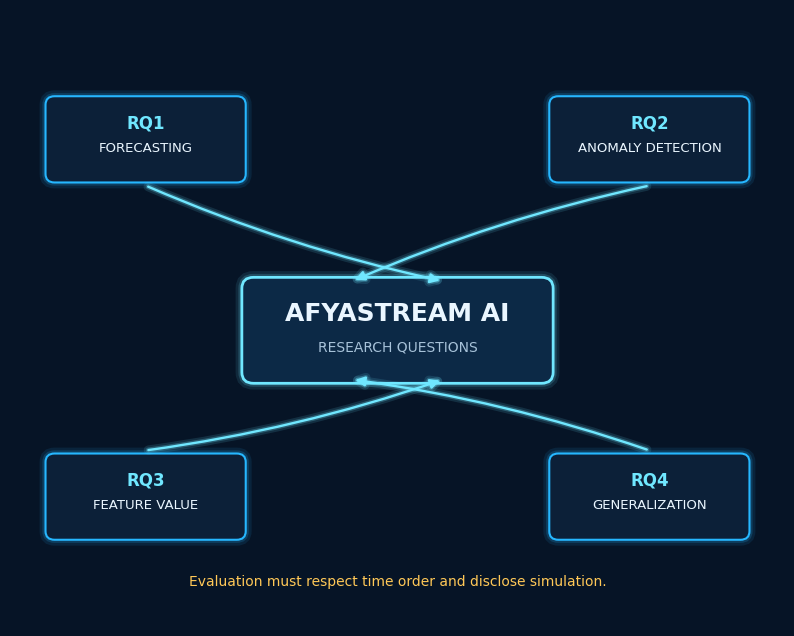

Saved: /content/afya_stream/figures/social_visual_07.png


In [22]:
# ============================================================
# VISUALIZATION 07 — RESEARCH FRAMEWORK
# ============================================================
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(10, 8))
ax.set_xlim(0, 12)
ax.set_ylim(0, 10)
ax.axis("off")

center = FancyBboxPatch(
    (3.65, 4.0), 4.7, 1.6,
    boxstyle="round,pad=0.06,rounding_size=0.18",
    facecolor="#0C2946", edgecolor=NEON_CYAN, linewidth=2
)
ax.add_patch(center)
ax.text(
    6, 4.95, "AFYASTREAM AI",
    ha="center", fontsize=18, fontweight="bold",
    color=TEXT_LIGHT
)
ax.text(
    6, 4.45, "RESEARCH QUESTIONS",
    ha="center", fontsize=10, color=TEXT_MUTED
)

nodes = [
    (2.1, 7.9, "RQ1", "FORECASTING"),
    (9.9, 7.9, "RQ2", "ANOMALY DETECTION"),
    (2.1, 2.1, "RQ3", "FEATURE VALUE"),
    (9.9, 2.1, "RQ4", "GENERALIZATION")
]

for x, y, code, label in nodes:
    box = FancyBboxPatch(
        (x - 1.5, y - 0.65), 3.0, 1.3,
        boxstyle="round,pad=0.05,rounding_size=0.14",
        facecolor=PANEL_BG, edgecolor=NEON_BLUE, linewidth=1.5
    )
    ax.add_patch(box)
    ax.text(
        x, y + 0.18, code, ha="center", fontsize=12,
        fontweight="bold", color=NEON_CYAN
    )
    ax.text(
        x, y - 0.2, label, ha="center", fontsize=9.5,
        color=TEXT_LIGHT
    )
    start_y, end_y = (
        (y - 0.75, 5.6) if y > 5 else (y + 0.75, 4.0)
    )
    ax.add_patch(FancyArrowPatch(
        (x, start_y),
        (6 + (0.7 if x < 6 else -0.7), end_y),
        arrowstyle="-|>", mutation_scale=14,
        linewidth=1.7, color=NEON_CYAN,
        connectionstyle="arc3,rad=0.05"
    ))

ax.text(
    6, 0.65,
    "Evaluation must respect time order and disclose simulation.",
    ha="center", fontsize=10, color=WARNING_AMBER
)

out = FIGURES_DIR / "social_visual_07.png"
apply_neon_style(fig)
fig.savefig(out, dpi=200, bbox_inches="tight")
apply_neon_style(fig)
plt.show()
print("Saved:", out)

## STAGE 13 — ROBUSTNESS & STRESS TESTS

In [29]:
# ============================================================
# STAGE 13 — ROBUSTNESS & GENERALIZATION
# ============================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd
import joblib

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("=" * 72)
print("STAGE 13 — ROBUSTNESS & GENERALIZATION")
print("=" * 72)

ROOT13 = Path("/content/afya_stream")
FIG13 = ROOT13 / "figures" / "stage13"
REPORTS13 = ROOT13 / "reports"
PRED13 = ROOT13 / "predictions"
MODELS13 = ROOT13 / "models"

for directory in [FIG13, REPORTS13, PRED13, MODELS13]:
    directory.mkdir(parents=True, exist_ok=True)

rng13 = np.random.default_rng(
    int(globals().get("GLOBAL_SEED", 42))
)


# ------------------------------------------------------------
# 13.1 Load test predictions
# ------------------------------------------------------------

if "test12" in globals():

    test13 = test12.copy()

else:

    file13 = PRED13 / "stage12_test_predictions.csv"

    if not file13.exists():
        raise FileNotFoundError(
            f"Run Stage 12 first. Missing: {file13}"
        )

    test13 = pd.read_csv(file13)


required13 = [
    "facility_id",
    "facility_name",
    "region",
    "service_type",
    "target_month",
    "target_next_month",
    "forecast_prediction"
]

missing13 = [
    c for c in required13
    if c not in test13.columns
]

if missing13:
    raise ValueError(
        "Missing required Stage 12 columns: "
        + ", ".join(missing13)
    )


test13["target_month"] = pd.to_datetime(
    test13["target_month"],
    errors="coerce"
)

for c in ["target_next_month", "forecast_prediction"]:
    test13[c] = pd.to_numeric(
        test13[c],
        errors="coerce"
    )

test13 = (
    test13
    .dropna(
        subset=[
            "region",
            "service_type",
            "target_next_month",
            "forecast_prediction"
        ]
    )
    .copy()
)

print(f"Rows evaluated: {len(test13):,}")


# ------------------------------------------------------------
# 13.2 Metrics
# ------------------------------------------------------------

def metrics13(actual, predicted):

    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    mae = mean_absolute_error(actual, predicted)

    rmse = float(np.sqrt(
        mean_squared_error(actual, predicted)
    ))

    r2 = r2_score(actual, predicted)

    nonzero = np.abs(actual) > 1e-8

    mape = (
        float(
            np.mean(
                np.abs(
                    (actual[nonzero] - predicted[nonzero])
                    / actual[nonzero]
                )
            ) * 100
        )
        if nonzero.any()
        else float("nan")
    )

    denom = np.abs(actual) + np.abs(predicted)

    valid = denom > 1e-8

    smape = (
        float(
            np.mean(
                2 * np.abs(
                    predicted[valid] - actual[valid]
                ) / denom[valid]
            ) * 100
        )
        if valid.any()
        else float("nan")
    )

    return {
        "MAE": float(mae),
        "RMSE": rmse,
        "MAPE_pct": mape,
        "sMAPE_pct": smape,
        "R2": float(r2)
    }


overall13 = metrics13(
    test13["target_next_month"],
    test13["forecast_prediction"]
)

print("\nOVERALL TEST PERFORMANCE")
display(pd.DataFrame([overall13]))


# ------------------------------------------------------------
# 13.3 Region-level performance
# ------------------------------------------------------------

regional_rows13 = []

for region, group in test13.groupby("region"):

    if len(group) < 2:
        continue

    regional_rows13.append({
        "region": region,
        "rows": int(len(group)),
        **metrics13(
            group["target_next_month"],
            group["forecast_prediction"]
        )
    })

regional13 = (
    pd.DataFrame(regional_rows13)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

print("\nREGIONAL GENERALIZATION")
display(regional13)

regional13.to_csv(
    FIG13 / "regional_performance.csv",
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 13.4 Service-level performance
# ------------------------------------------------------------

service_rows13 = []

for service, group in test13.groupby("service_type"):

    if len(group) < 2:
        continue

    service_rows13.append({
        "service_type": service,
        "rows": int(len(group)),
        **metrics13(
            group["target_next_month"],
            group["forecast_prediction"]
        )
    })

service13 = (
    pd.DataFrame(service_rows13)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

print("\nSERVICE-LEVEL GENERALIZATION")
display(service13)

service13.to_csv(
    FIG13 / "service_performance.csv",
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 13.5 Dar es Salaam vs Other Tanzania
# ------------------------------------------------------------

dar_mask13 = (
    test13["region"]
    .astype(str)
    .str.contains(
        "dar es salaam",
        case=False,
        na=False
    )
)

dar13 = test13.loc[dar_mask13].copy()
other13 = test13.loc[~dar_mask13].copy()

geographic_rows13 = []

for label, group in [
    ("Dar es Salaam", dar13),
    ("Other Tanzania", other13)
]:

    if len(group) >= 2:

        geographic_rows13.append({
            "geographic_group": label,
            "rows": int(len(group)),
            **metrics13(
                group["target_next_month"],
                group["forecast_prediction"]
            )
        })

geographic13 = pd.DataFrame(geographic_rows13)

print("\nDAR ES SALAAM VS OTHER TANZANIA")
display(geographic13)

geographic13.to_csv(
    FIG13 / "dar_vs_other_tanzania.csv",
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 13.6 Facility-level performance
# ------------------------------------------------------------

facility_rows13 = []

for facility_id, group in test13.groupby("facility_id"):

    if len(group) < 2:
        continue

    facility_rows13.append({
        "facility_id": facility_id,
        "facility_name": group["facility_name"].iloc[0],
        "region": group["region"].iloc[0],
        "rows": int(len(group)),
        **metrics13(
            group["target_next_month"],
            group["forecast_prediction"]
        )
    })

facility13 = (
    pd.DataFrame(facility_rows13)
    .sort_values("RMSE", ascending=False)
    .reset_index(drop=True)
)

print("\nFACILITIES EVALUATED:", len(facility13))
print("\nHighest RMSE:")
display(facility13.head(15))

print("\nLowest RMSE:")
display(
    facility13.sort_values("RMSE").head(15)
)

facility13.to_csv(
    FIG13 / "facility_performance.csv",
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 13.7 Missing-data stress test
# ------------------------------------------------------------
# The final model pipeline should include preprocessing
# imputation, as defined in Stage 12.

if "model_features" not in globals():
    raise NameError(
        "model_features is missing. Run Stage 12 first."
    )

missing_features13 = [
    c for c in model_features
    if c not in test13.columns
]

if missing_features13:
    raise ValueError(
        "TEST dataset lacks model features: "
        + ", ".join(missing_features13)
    )

X13 = test13[model_features].copy()

y13 = test13["target_next_month"].to_numpy(dtype=float)

if "final_forecast_model" in globals():

    model13 = final_forecast_model

else:

    model_file13 = (
        MODELS13 / "stage12_final_forecaster.joblib"
    )

    if not model_file13.exists():
        raise FileNotFoundError(
            f"Final Stage 12 model not found: {model_file13}"
        )

    model13 = joblib.load(model_file13)


baseline_prediction13 = np.maximum(
    model13.predict(X13),
    0
)

baseline_metrics13 = metrics13(
    y13,
    baseline_prediction13
)

numeric_features13 = (
    X13.select_dtypes(include=[np.number])
    .columns
    .tolist()
)

stress_rows13 = []

for missing_fraction in [0.05, 0.10, 0.20]:

    X_stress13 = X13.copy()

    if numeric_features13:

        mask13 = (
            rng13.random(
                (len(X_stress13), len(numeric_features13))
            )
            < missing_fraction
        )

        original_numeric13 = X_stress13[
            numeric_features13
        ].copy()

        X_stress13[numeric_features13] = (
            original_numeric13.mask(mask13)
        )

    # Missing numeric values are passed to the already-fitted
    # preprocessing pipeline; test data is never used to fit imputers.
    pred_stress13 = np.maximum(
        model13.predict(X_stress13),
        0
    )

    result13 = metrics13(y13, pred_stress13)

    result13["missingness_fraction"] = missing_fraction
    result13["missingness_percent"] = 100 * missing_fraction

    result13["RMSE_degradation_percent"] = (
        (result13["RMSE"] - baseline_metrics13["RMSE"])
        / baseline_metrics13["RMSE"]
    ) * 100

    stress_rows13.append(result13)


stress13 = pd.DataFrame(stress_rows13)

print("\nMISSING-DATA STRESS TEST")
display(stress13)

stress13.to_csv(
    FIG13 / "missingness_stress_test.csv",
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 13.8 Save canonical reports
# ------------------------------------------------------------

robustness_report13 = {

    "project": "AfyaStream AI",

    "stage": "Stage 13 — Robustness & Generalization",

    "selected_model": (
        best_model_name
        if "best_model_name" in globals()
        else "HistGradientBoostingRegressor"
    ),

    "test_rows": int(len(test13)),

    "overall_test_metrics": overall13,

    "regional_groups": int(len(regional13)),

    "service_groups": int(len(service13)),

    "facilities_evaluated": int(len(facility13)),

    "dar_es_salaam_rows": int(len(dar13)),

    "other_tanzania_rows": int(len(other13)),

    "baseline_stress_metrics": baseline_metrics13,

    "missingness_stress_test": stress13.to_dict(
        orient="records"
    ),

    "model_selection_note": (
        "No model selection or tuning was performed using these "
        "Stage 13 TEST robustness results."
    ),

    "data_provenance_note": (
        "The current service-demand observations are simulated. "
        "The results are experimental research results and are "
        "not real-world hospital performance."
    )
}

report_file13 = (
    ROOT13 / "reports"
    / "stage13_robustness_generalization_report.json"
)

report_file13.write_text(
    json.dumps(
        robustness_report13,
        indent=2,
        default=str,
        ensure_ascii=False
    ),
    encoding="utf-8"
)

# Compatibility path for downstream audit cells.
(
    ROOT13 / "reports" / "robustness_report.json"
).write_text(
    json.dumps(
        robustness_report13,
        indent=2,
        default=str,
        ensure_ascii=False
    ),
    encoding="utf-8"
)

print("\n" + "=" * 72)
print("✅ STAGE 13 COMPLETED")
print("=" * 72)

print("Regional groups:", len(regional13))
print("Service groups:", len(service13))
print("Facilities:", len(facility13))
print("Dar es Salaam rows:", len(dar13))
print("Other Tanzania rows:", len(other13))
print("Saved:", report_file13)

print(
    "\nNOTE: This is a controlled simulation-based robustness "
    "experiment, not validation on real hospital demand."
)

STAGE 13 — ROBUSTNESS & GENERALIZATION
Rows evaluated: 23,232

OVERALL TEST PERFORMANCE


,MAE,RMSE,MAPE_pct,sMAPE_pct,R2
0,43.188197,101.147147,7.563153,7.491173,0.978065



REGIONAL GENERALIZATION


,region,rows,MAE,RMSE,MAPE_pct,sMAPE_pct,R2
0,Tanga Region,1008,31.508870,54.982016,7.568395,7.532262,0.987174
1,Katavi Region,288,28.468603,57.664731,7.676147,7.535618,0.985221
2,Mara Region,960,32.272985,57.990660,7.301333,7.157468,0.987435
3,Shinyanga Region,480,31.659706,58.541588,7.403272,7.322143,0.986819
4,Iringa Region,528,34.818686,64.512255,7.985011,7.836811,0.983480
5,Manyara Region,624,35.307968,65.086338,8.107558,7.920658,0.985974
6,Songwe Region,528,34.739801,66.433975,7.372614,7.367447,0.985761
7,Ruvuma Region,864,35.315711,67.499295,7.161391,7.120139,0.984482
8,Rukwa Region,336,37.742017,69.697553,7.835713,7.769131,0.985968
9,Lindi Region,528,37.962592,69.898480,8.139198,8.056775,0.985724



SERVICE-LEVEL GENERALIZATION


...


Lowest RMSE:


,facility_id,facility_name,region,rows,MAE,RMSE,MAPE_pct,sMAPE_pct,R2
483,110899-2,KALIUA,Tabora Region,48,14.252204,20.683054,7.242162,6.857423,0.995473
482,114834-5,NSIMBO,Katavi Region,48,17.753001,27.222245,8.480730,8.069841,0.991107
481,108289-0,VWAWA,Songwe Region,48,18.560435,27.711079,7.377280,7.192847,0.991938
480,113938-5,KIBAHA DC,Pwani Region,48,18.102260,29.294211,6.658472,6.496047,0.992008
479,124048-0,MBUBA,Kagera Region,48,18.765697,29.887460,8.532031,8.075482,0.989789
478,101535-3,IGAWILO,Mbeya Region,48,19.922393,29.903408,7.075769,7.024950,0.991161
477,101849-8,KIOMBOI,Singida Region,48,20.002450,30.035037,9.753718,9.004702,0.988471
476,106967-3,PANGANI,Tanga Region,48,19.354410,30.216979,7.939838,7.604305,0.991556
475,114504-4,NYANG'HWALE,Geita Region,48,19.496250,30.256889,9.153237,8.647350,0.988532
474,111779-5,DR. JAKAYA KIKWETE,Shinyanga Region,48,20.450075,30.433438,8.760355,8.477652,0.990086



MISSING-DATA STRESS TEST


,MAE,RMSE,MAPE_pct,sMAPE_pct,R2,missingness_fraction,missingness_percent,RMSE_degradation_percent
0,59.230104,176.455462,9.888635,9.855092,0.933243,0.05,5.0,74.454216
1,76.179034,224.560144,12.384504,12.361026,0.891883,0.10,10.0,122.013325
2,110.249305,308.847324,17.256907,17.383077,0.795489,0.20,20.0,205.344574



✅ STAGE 13 COMPLETED
Regional groups: 26
Service groups: 4
Facilities: 484
Dar es Salaam rows: 3744
Other Tanzania rows: 19488
Saved: /content/afya_stream/reports/stage13_robustness_generalization_report.json

NOTE: This is a controlled simulation-based robustness experiment, not validation on real hospital demand.


# SOCIAL MEDIA — POST 08/13

## **Model haioni data ghafi tu. Inaona context.**

Tunatumia lag values, rolling mean/std, seasonality, facility, geography na context variables pale zinapopatikana.

**Raw data inabadilika kuwa modelling signal.**

**Uwazi wa data:** features zimejaribiwa kwenye dataset yenye service-demand values zilizotengenezwa kwa simulation.

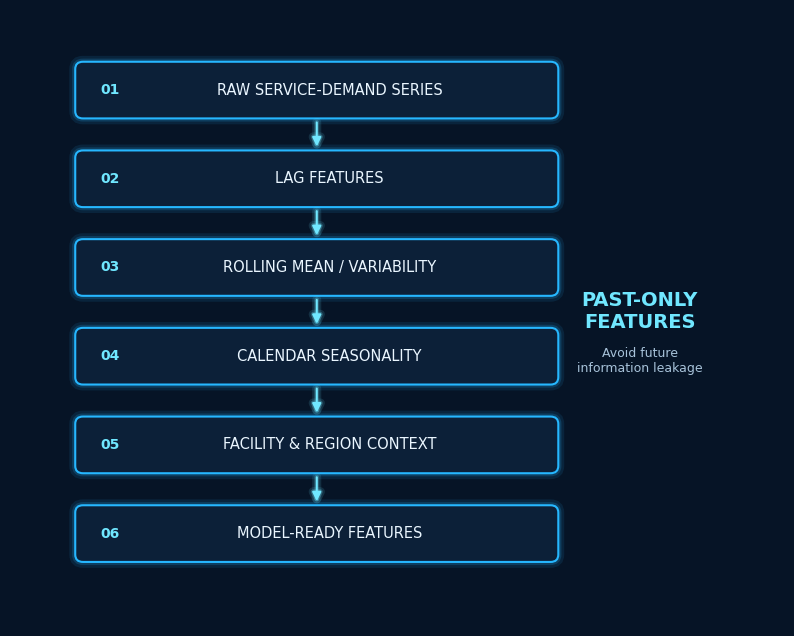

Saved: /content/afya_stream/figures/social_visual_08.png


In [24]:
# ============================================================
# VISUALIZATION 08 — FEATURE ENGINEERING
# ============================================================
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(10, 8))
ax.set_xlim(0, 12)
ax.set_ylim(0, 10)
ax.axis("off")

items = [
    ("01", "RAW SERVICE-DEMAND SERIES"),
    ("02", "LAG FEATURES"),
    ("03", "ROLLING MEAN / VARIABILITY"),
    ("04", "CALENDAR SEASONALITY"),
    ("05", "FACILITY & REGION CONTEXT"),
    ("06", "MODEL-READY FEATURES")
]

ys = np.linspace(8.7, 1.5, len(items))

for idx, ((number, label), y) in enumerate(zip(items, ys)):
    box = FancyBboxPatch(
        (1.05, y - 0.42), 7.4, 0.84,
        boxstyle="round,pad=0.04,rounding_size=0.12",
        facecolor=PANEL_BG, edgecolor=NEON_BLUE, linewidth=1.5
    )
    ax.add_patch(box)
    ax.text(
        1.55, y, number, ha="center", va="center",
        fontsize=10, fontweight="bold", color=NEON_CYAN
    )
    ax.text(
        4.95, y, label, ha="center", va="center",
        fontsize=10.5, color=TEXT_LIGHT
    )
    if idx < len(items) - 1:
        ax.add_patch(FancyArrowPatch(
            (4.75, y - 0.48), (4.75, ys[idx + 1] + 0.48),
            arrowstyle="-|>", mutation_scale=13,
            linewidth=1.5, color=NEON_CYAN
        ))

ax.text(
    9.75, 5.1, "PAST-ONLY\nFEATURES",
    ha="center", va="center", fontsize=14,
    fontweight="bold", color=NEON_CYAN
)
ax.text(
    9.75, 4.3, "Avoid future\ninformation leakage",
    ha="center", va="center", fontsize=9,
    color=TEXT_MUTED
)

out = FIGURES_DIR / "social_visual_08.png"
apply_neon_style(fig)
fig.savefig(out, dpi=200, bbox_inches="tight")
apply_neon_style(fig)
plt.show()
print("Saved:", out)

## STAGE 14 — FORECAST INTERPRETATION

STAGE 14 — FINAL FORECAST STORY
Training rows available for visualization: 50,336


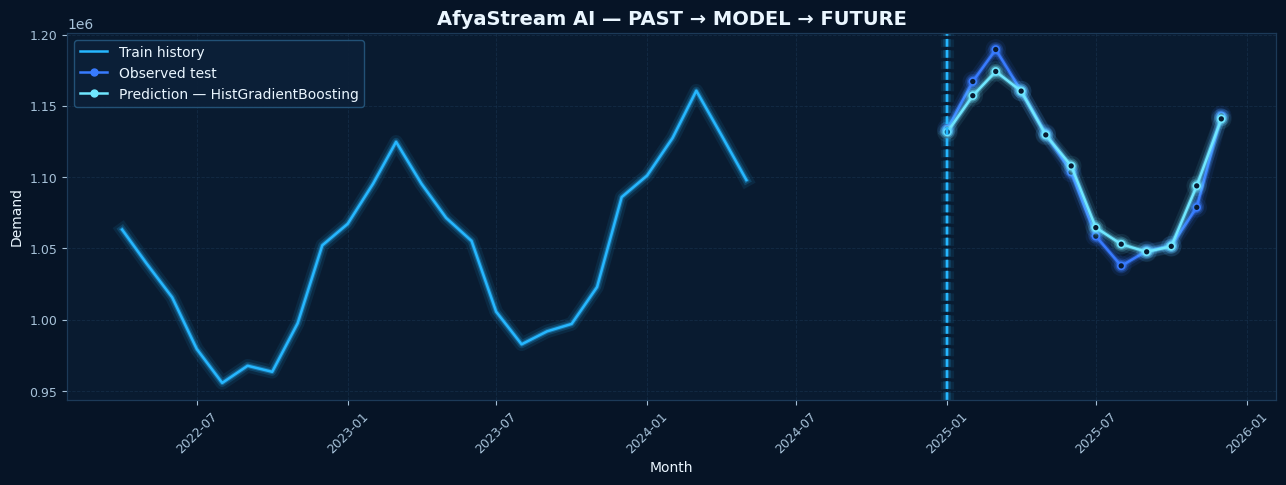


✅ Stage 14 figure saved:
/content/afya_stream/figures/stage14_past_model_future.png

Visualization summary:
Train period: 2022-04 to 2024-05
Test period: 2025-01 to 2025-12
Selected model: HistGradientBoosting

NOTE:
The figure shows historical training demand, observed TEST demand, and the final model forecast. The current service-demand values are simulated.

✅ STAGE 14 COMPLETED


In [31]:
# ============================================================
# STAGE 14 — FINAL FORECAST STORY
# AfyaStream AI
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

print("=" * 72)
print("STAGE 14 — FINAL FORECAST STORY")
print("=" * 72)


# ------------------------------------------------------------
# 14.1 CHECK REQUIRED OBJECTS
# ------------------------------------------------------------

if "forecast_train_df" not in globals():
    raise NameError(
        "forecast_train_df haipo. Run Stage 10 first."
    )

if "test12" not in globals():
    raise NameError(
        "test12 haipo. Run Stage 12 first."
    )


# ------------------------------------------------------------
# 14.2 CONVERT TRAIN DATA TO PANDAS
# ------------------------------------------------------------
# forecast_train_df is a Spark DataFrame in this notebook.
# Convert only the required columns to pandas for plotting.

if hasattr(forecast_train_df, "toPandas"):

    train_source14 = (
        forecast_train_df
        .select(
            "date",
            "demand"
        )
        .toPandas()
    )

else:

    train_source14 = (
        forecast_train_df[
            [
                "date",
                "demand"
            ]
        ]
        .copy()
    )


print(
    f"Training rows available for visualization: "
    f"{len(train_source14):,}"
)


# ------------------------------------------------------------
# 14.3 CLEAN TRAIN DATA
# ------------------------------------------------------------

train_source14["date"] = pd.to_datetime(
    train_source14["date"],
    errors="coerce"
)

train_source14["demand"] = pd.to_numeric(
    train_source14["demand"],
    errors="coerce"
)


train_source14 = (
    train_source14
    .dropna(
        subset=[
            "date",
            "demand"
        ]
    )
    .copy()
)


# ------------------------------------------------------------
# 14.4 AGGREGATE TRAIN DEMAND BY MONTH
# ------------------------------------------------------------

train_monthly14 = (

    train_source14

    .groupby(
        "date",
        as_index=False
    )

    .agg(
        demand=(
            "demand",
            "sum"
        )
    )

    .sort_values(
        "date"
    )

)


# ------------------------------------------------------------
# 14.5 TEST MONTHLY OBSERVED VS FORECAST
# ------------------------------------------------------------

test_monthly14 = (

    test12

    .copy()

)


test_monthly14["target_month"] = (
    pd.to_datetime(
        test_monthly14["target_month"],
        errors="coerce"
    )
)


test_monthly14["target_next_month"] = (
    pd.to_numeric(
        test_monthly14[
            "target_next_month"
        ],
        errors="coerce"
    )
)


test_monthly14["forecast_prediction"] = (
    pd.to_numeric(
        test_monthly14[
            "forecast_prediction"
        ],
        errors="coerce"
    )
)


test_monthly14 = (

    test_monthly14

    .dropna(
        subset=[
            "target_month",
            "target_next_month",
            "forecast_prediction"
        ]
    )

)


test_monthly14 = (

    test_monthly14

    .groupby(
        "target_month",
        as_index=False
    )

    .agg(

        observed_demand=(
            "target_next_month",
            "sum"
        ),

        predicted_demand=(
            "forecast_prediction",
            "sum"
        )

    )

    .sort_values(
        "target_month"
    )

)


# ------------------------------------------------------------
# 14.6 SELECT MODEL NAME
# ------------------------------------------------------------

if "best_model_name" in globals():

    model_name14 = best_model_name

else:

    model_name14 = (
        "HistGradientBoostingRegressor"
    )


# ------------------------------------------------------------
# 14.7 PAST → MODEL → FUTURE VISUALIZATION
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(13, 5)
)


# Historical training data
ax.plot(

    train_monthly14[
        "date"
    ],

    train_monthly14[
        "demand"
    ],

    linewidth=1.8,

    label="Train history"

)


# Observed test demand
ax.plot(

    test_monthly14[
        "target_month"
    ],

    test_monthly14[
        "observed_demand"
    ],

    marker="o",

    linewidth=1.8,

    label="Observed test"

)


# Model forecast
ax.plot(

    test_monthly14[
        "target_month"
    ],

    test_monthly14[
        "predicted_demand"
    ],

    marker="o",

    linewidth=1.8,

    label=f"Prediction — {model_name14}"

)


# Test-period boundary
ax.axvline(

    test_monthly14[
        "target_month"
    ].min(),

    linestyle="--",

    linewidth=1.5

)


# Labels
ax.set_title(
    "AfyaStream AI — PAST → MODEL → FUTURE"
)

ax.set_xlabel(
    "Month"
)

ax.set_ylabel(
    "Demand"
)

ax.grid(
    alpha=0.25
)

ax.legend()

plt.xticks(
    rotation=45
)

plt.tight_layout()


# ------------------------------------------------------------
# 14.8 DISPLAY
# ------------------------------------------------------------

apply_neon_style(fig)

plt.show()


# ------------------------------------------------------------
# 14.9 SAVE FIGURE
# ------------------------------------------------------------

stage14_file = (

    FIGURES_DIR /
    "stage14_past_model_future.png"

)


apply_neon_style(fig)


fig.savefig(

    stage14_file,

    dpi=180,

    bbox_inches="tight"

)


print(
    "\n✅ Stage 14 figure saved:"
)

print(
    stage14_file
)


# ------------------------------------------------------------
# 14.10 SUMMARY
# ------------------------------------------------------------

print(
    "\nVisualization summary:"
)

print(
    f"Train period: "
    f"{train_monthly14['date'].min().strftime('%Y-%m')} "
    f"to "
    f"{train_monthly14['date'].max().strftime('%Y-%m')}"
)

print(
    f"Test period: "
    f"{test_monthly14['target_month'].min().strftime('%Y-%m')} "
    f"to "
    f"{test_monthly14['target_month'].max().strftime('%Y-%m')}"
)

print(
    f"Selected model: "
    f"{model_name14}"
)


print(
    "\nNOTE:"
)

print(
    "The figure shows historical training demand, "
    "observed TEST demand, and the final model forecast. "
    "The current service-demand values are simulated."
)


print(
    "\n" + "=" * 72
)

print(
    "✅ STAGE 14 COMPLETED"
)

print(
    "=" * 72
)

# SOCIAL MEDIA — POST 09/13

## **Kesho inaweza kuonekana kwenye historia ya leo.**

Model inajifunza mwenendo wa nyuma na kutabiri kipindi kijacho. Tutatumia **time-aware evaluation**, si random split, ili taarifa za baadaye zisiwe sehemu ya training ya zamani.

**PAST → MODEL → FUTURE**

**Uwazi wa data:** chart ya toleo hili ni ya simulation; si forecast ya kiutendaji kwa hospitali.

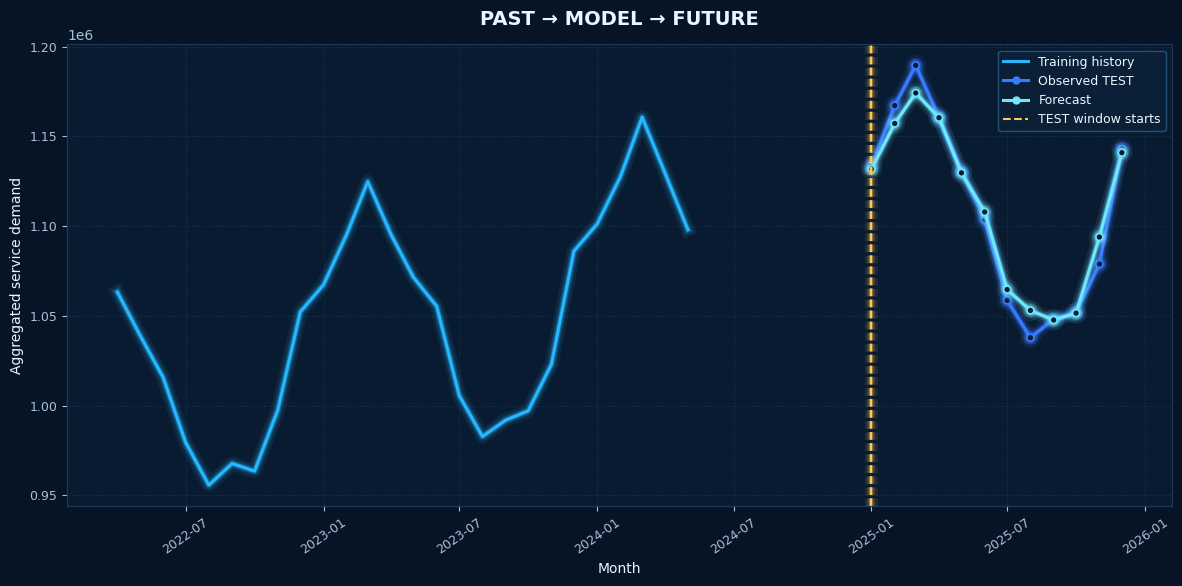

Saved: /content/afya_stream/figures/social_visual_09.png


In [26]:
# ============================================================
# VISUALIZATION 09 — PAST → MODEL → FUTURE
# Uses outputs prepared by Stage 14
# ============================================================

if "train_monthly14" not in globals() or "test_monthly14" not in globals():
    raise RuntimeError(
        "Run Stage 14 successfully before Visualization 09."
    )

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    train_monthly14["date"],
    train_monthly14["demand"],
    label="Training history",
    linewidth=2.2
)

ax.plot(
    test_monthly14["target_month"],
    test_monthly14["observed_demand"],
    marker="o",
    label="Observed TEST",
    linewidth=2.2
)

ax.plot(
    test_monthly14["target_month"],
    test_monthly14["predicted_demand"],
    marker="o",
    label="Forecast",
    linewidth=2.2
)

ax.axvline(
    test_monthly14["target_month"].min(),
    color=WARNING_AMBER,
    linestyle="--",
    linewidth=1.5,
    label="TEST window starts"
)

ax.set_title("PAST → MODEL → FUTURE", pad=14)
ax.set_xlabel("Month")
ax.set_ylabel("Aggregated service demand")
ax.grid(alpha=0.42)
ax.legend(loc="best", fontsize=9)
plt.xticks(rotation=35)
fig.tight_layout()

out = FIGURES_DIR / "social_visual_09.png"
apply_neon_style(fig)
fig.savefig(out, dpi=200, bbox_inches="tight")
apply_neon_style(fig)
plt.show()
print("Saved:", out)

## STAGE 15 — LOCAL SPARK STRUCTURED STREAMING REPLAY

In [35]:
# ============================================================
# STAGE 15 — LOCAL SPARK STREAMING REPLAY
# AfyaStream AI | Robust, reproducible implementation
# ============================================================

import json
import shutil
import numpy as np
import pandas as pd

from pathlib import Path
from pyspark.sql import SparkSession
from pyspark.sql import functions as SparkF15
from pyspark.sql import types as SparkT15


print("=" * 72)
print("STAGE 15 — LOCAL SPARK STREAMING REPLAY")
print("=" * 72)


# ------------------------------------------------------------
# 15.1 DIRECTORIES
# ------------------------------------------------------------

STREAM_INPUT = Path(STREAM_DIR) / "input"
STREAM_OUTPUT = Path(STREAM_DIR) / "alerts"
CHECKPOINT = Path(STREAM_DIR) / "checkpoint"

STREAM_INPUT.mkdir(
    parents=True,
    exist_ok=True
)

STREAM_OUTPUT.parent.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# 15.2 OBTAIN A REAL SPARK SESSION
# ------------------------------------------------------------
# Do not use the global variable "spark": another notebook
# cell may have overwritten it with a Matplotlib object.

spark_session15 = SparkSession.getActiveSession()

if spark_session15 is None:
    spark_session15 = SparkSession.builder \
        .appName("AfyaStreamAI_Stage15_StreamingReplay") \
        .getOrCreate()


print(
    "Spark session type:",
    type(spark_session15).__name__
)

print(
    "Spark version:",
    spark_session15.version
)


# Stop a previous Stage 15 query if one is still running.
if "query15" in globals():

    try:
        if query15.isActive:
            query15.stop()
            print("Stopped previous Stage 15 query.")

    except Exception:
        pass


# ------------------------------------------------------------
# 15.3 RESET ONLY THIS STAGE'S OUTPUTS
# ------------------------------------------------------------

for path in [
    STREAM_OUTPUT,
    CHECKPOINT
]:

    if path.exists():

        shutil.rmtree(path)


# Clear prior replay input files to prevent duplicate events.
for file_path in STREAM_INPUT.glob("*.json"):

    file_path.unlink()


# ------------------------------------------------------------
# 15.4 LOAD FINAL TEST PREDICTIONS
# ------------------------------------------------------------

if "test12" in globals():

    replay15 = test12.copy()

else:

    prediction_file15 = (
        Path(PREDICTIONS_DIR)
        / "stage12_test_predictions.csv"
    )

    if not prediction_file15.exists():

        raise FileNotFoundError(
            "Stage 12 predictions were not found. "
            "Run Stage 12 first."
        )

    replay15 = pd.read_csv(
        prediction_file15
    )


required15 = [
    "target_month",
    "region",
    "facility_id",
    "facility_name",
    "service_type",
    "target_next_month",
    "forecast_prediction",
    "forecast_residual",
    "absolute_residual",
    "predicted_anomaly"
]


missing15 = [
    column
    for column in required15
    if column not in replay15.columns
]


if missing15:

    raise ValueError(
        "Missing required Stage 12 columns: "
        + ", ".join(missing15)
    )


print(
    f"Test records loaded: {len(replay15):,}"
)


# ------------------------------------------------------------
# 15.5 VALIDATE AND NORMALIZE INPUT DATA
# ------------------------------------------------------------

replay15["target_month"] = pd.to_datetime(
    replay15["target_month"],
    errors="coerce"
)


numeric_columns15 = [
    "target_next_month",
    "forecast_prediction",
    "forecast_residual",
    "absolute_residual"
]


for column in numeric_columns15:

    replay15[column] = pd.to_numeric(
        replay15[column],
        errors="coerce"
)


replay15 = replay15.dropna(
    subset=[
        "target_month",
        "region",
        "facility_id",
        "service_type",
        *numeric_columns15
    ]
).copy()


if replay15.empty:

    raise ValueError(
        "No valid records remain after input validation."
    )


# Correctly parse boolean anomaly values.
def parse_anomaly15(value):

    if pd.isna(value):
        return 0

    if isinstance(value, (bool, np.bool_)):
        return int(value)

    if isinstance(value, (int, np.integer, float, np.floating)):
        return int(value != 0)

    return int(
        str(value).strip().lower()
        in {"true", "1", "yes", "y"}
    )


replay15["early_warning"] = (
    replay15["predicted_anomaly"]
    .apply(parse_anomaly15)
    .astype(int)
)


# ------------------------------------------------------------
# 15.6 GET THE VALIDATION-CALIBRATED THRESHOLD
# ------------------------------------------------------------

threshold15 = None


if "selected_threshold" in globals():

    try:
        candidate15 = float(
            selected_threshold
        )

        if np.isfinite(candidate15) and candidate15 > 0:
            threshold15 = candidate15

    except (TypeError, ValueError):
        pass


# Fallback: load the saved Stage 12 threshold search.
if threshold15 is None:

    threshold_file15 = (
        Path(PREDICTIONS_DIR)
        / "stage12_anomaly_threshold_search.csv"
    )

    if threshold_file15.exists():

        threshold_df15 = pd.read_csv(
            threshold_file15
        )

        if (
            "selected" in threshold_df15.columns
            and
            "threshold" in threshold_df15.columns
        ):

            selected_rows15 = threshold_df15.loc[
                threshold_df15["selected"]
                .astype(str)
                .str.strip()
                .str.lower()
                .isin(["true", "1", "yes"])
            ]

            if not selected_rows15.empty:

                threshold15 = float(
                    selected_rows15["threshold"].iloc[0]
                )

        # Additional fallback: choose the recorded
        # best F1 row, if the report uses that format.
        if (
            threshold15 is None
            and
            "threshold" in threshold_df15.columns
            and
            "F1" in threshold_df15.columns
        ):

            threshold_df15["F1"] = pd.to_numeric(
                threshold_df15["F1"],
                errors="coerce"
            )

            threshold_df15["threshold"] = pd.to_numeric(
                threshold_df15["threshold"],
                errors="coerce"
            )

            usable_thresholds15 = threshold_df15.dropna(
                subset=["F1", "threshold"]
            )

            if not usable_thresholds15.empty:

                best_row15 = usable_thresholds15.loc[
                    usable_thresholds15["F1"].idxmax()
                ]

                threshold15 = float(
                    best_row15["threshold"]
                )


if threshold15 is None or not np.isfinite(threshold15) or threshold15 <= 0:

    raise ValueError(
        "Could not recover a valid anomaly threshold. "
        "Check Stage 12 threshold-search output."
    )


replay15["robust_score"] = (
    replay15["absolute_residual"]
    / threshold15
)


replay15["event_time"] = (
    replay15["target_month"]
    .dt.strftime("%Y-%m-%dT00:00:00Z")
)


print(
    f"Anomaly threshold: {threshold15:.4f}"
)

print(
    "Early-warning events in TEST:",
    int(replay15["early_warning"].sum())
)


# ------------------------------------------------------------
# 15.7 BUILD JSON EVENT RECORDS
# ------------------------------------------------------------

event_records15 = []


for row in replay15.itertuples(index=False):

    payload15 = {

        "event_time":
            row.event_time,

        "region":
            str(row.region),

        "facility_id":
            str(row.facility_id),

        "facility_name":
            str(row.facility_name),

        "service_type":
            str(row.service_type),

        "demand":
            float(row.target_next_month),

        "prediction":
            float(row.forecast_prediction),

        "residual":
            float(row.forecast_residual),

        "absolute_residual":
            float(row.absolute_residual),

        "robust_score":
            float(row.robust_score),

        "early_warning":
            int(row.early_warning)
    }


    event_records15.append(
        payload15
    )


# Write batches of newline-delimited JSON.
# Spark's JSON file source supports one JSON object per line.

BATCH_SIZE15 = 250


for start15 in range(
    0,
    len(event_records15),
    BATCH_SIZE15
):

    batch15 = event_records15[
        start15:start15 + BATCH_SIZE15
    ]


    batch_number15 = (
        start15 // BATCH_SIZE15
    )


    batch_path15 = (
        STREAM_INPUT
        / f"event_batch_{batch_number15:05d}.json"
    )


    batch_text15 = "\n".join(
        json.dumps(
            record15,
            ensure_ascii=False,
            allow_nan=False
        )
        for record15 in batch15
    )


    batch_path15.write_text(
        batch_text15 + "\n",
        encoding="utf-8"
    )


print(
    f"JSON events created: {len(event_records15):,}"
)

print(
    f"JSON batch files created: "
    f"{len(list(STREAM_INPUT.glob('*.json'))):,}"
)


# ------------------------------------------------------------
# 15.8 DEFINE EXPLICIT SPARK SCHEMA
# ------------------------------------------------------------

schema15 = SparkT15.StructType([

    SparkT15.StructField(
        "event_time",
        SparkT15.StringType(),
        True
    ),

    SparkT15.StructField(
        "region",
        SparkT15.StringType(),
        True
    ),

    SparkT15.StructField(
        "facility_id",
        SparkT15.StringType(),
        True
    ),

    SparkT15.StructField(
        "facility_name",
        SparkT15.StringType(),
        True
    ),

    SparkT15.StructField(
        "service_type",
        SparkT15.StringType(),
        True
    ),

    SparkT15.StructField(
        "demand",
        SparkT15.DoubleType(),
        True
    ),

    SparkT15.StructField(
        "prediction",
        SparkT15.DoubleType(),
        True
    ),

    SparkT15.StructField(
        "residual",
        SparkT15.DoubleType(),
        True
    ),

    SparkT15.StructField(
        "absolute_residual",
        SparkT15.DoubleType(),
        True
    ),

    SparkT15.StructField(
        "robust_score",
        SparkT15.DoubleType(),
        True
    ),

    SparkT15.StructField(
        "early_warning",
        SparkT15.IntegerType(),
        True
    )
])


# ------------------------------------------------------------
# 15.9 CREATE STREAMING DATAFRAME
# ------------------------------------------------------------

stream15 = (
    spark_session15
    .readStream
    .schema(schema15)
    .option(
        "maxFilesPerTrigger",
        20
    )
    .json(
        str(STREAM_INPUT)
    )
)


# ------------------------------------------------------------
# 15.10 GENERATE REVIEW ALERTS
# ------------------------------------------------------------

alerts15 = (

    stream15

    .withColumn(
        "event_time",
        SparkF15.to_timestamp(
            "event_time"
        )
    )

    .filter(
        SparkF15.col(
            "early_warning"
        ) == 1
    )

    .withColumn(
        "alert_type",
        SparkF15.lit(
            "HEALTH_EARLY_WARNING_REVIEW"
        )
    )

    .withColumn(
        "project_name",
        SparkF15.lit(
            "AfyaStream AI"
        )
    )

    .withColumn(
        "data_mode",
        SparkF15.lit(
            "SIMULATED_TEST_REPLAY"
        )
    )

)


# ------------------------------------------------------------
# 15.11 WRITE STREAM OUTPUT
# ------------------------------------------------------------

query15 = (

    alerts15

    .writeStream

    .format("parquet")

    .outputMode("append")

    .option(
        "path",
        str(STREAM_OUTPUT)
    )

    .option(
        "checkpointLocation",
        str(CHECKPOINT)
    )

    .trigger(
        availableNow=True
    )

    .start()

)


query15.awaitTermination()


# Confirm query termination and surface Spark errors.
if query15.exception() is not None:

    raise RuntimeError(
        "Spark streaming query failed: "
        + str(query15.exception())
    )


print(
    "\n✅ Streaming replay complete"
)

print(
    "Input:",
    STREAM_INPUT
)

print(
    "Alerts:",
    STREAM_OUTPUT
)


# ------------------------------------------------------------
# 15.12 VALIDATE OUTPUT
# ------------------------------------------------------------

if not STREAM_OUTPUT.exists():

    raise FileNotFoundError(
        "Streaming completed but the alert output "
        "directory does not exist."
    )


alert_df15 = (
    spark_session15
    .read
    .parquet(
        str(STREAM_OUTPUT)
    )
)


alert_count15 = alert_df15.count()


print(
    "\nStreaming validation"
)

print(
    "-" * 72
)

print(
    f"Validated input records: "
    f"{len(event_records15):,}"
)

print(
    f"Expected flagged events: "
    f"{int(replay15['early_warning'].sum()):,}"
)

print(
    f"Alerts written by Spark: "
    f"{alert_count15:,}"
)


# Verify output count against flagged TEST records.
expected_alerts15 = int(
    replay15["early_warning"].sum()
)


if alert_count15 != expected_alerts15:

    raise RuntimeError(
        "Alert-count validation failed. "
        f"Expected {expected_alerts15:,}; "
        f"Spark wrote {alert_count15:,}."
    )


print(
    "\n✅ ALERT COUNT VALIDATION PASSED"
)


# ------------------------------------------------------------
# 15.13 SAVE AUDIT REPORT
# ------------------------------------------------------------

stage15_report = {

    "stage":
        "Stage 15 — Local Spark Streaming Replay",

    "spark_version":
        spark_session15.version,

    "input_events":
        int(len(event_records15)),

    "input_batch_files":
        int(len(list(STREAM_INPUT.glob("*.json")))),

    "expected_alerts":
        expected_alerts15,

    "alerts_written":
        int(alert_count15),

    "alert_count_validation":
        alert_count15 == expected_alerts15,

    "threshold":
        float(threshold15),

    "streaming_mode":
        "availableNow local file-source replay",

    "data_mode":
        "SIMULATED_TEST_REPLAY",

    "output_path":
        str(STREAM_OUTPUT),

    "checkpoint_path":
        str(CHECKPOINT),

    "scientific_note":
        (
            "This is a replay of historical TEST predictions "
            "from simulated service-demand data. It is not "
            "live hospital streaming. Alerts are review signals, "
            "not clinical diagnoses."
        )
}


stage15_report_file = (
    Path(AUDIT_DIR) /
    "stage15_streaming_replay_report.json"
)


stage15_report_file.write_text(
    json.dumps(
        stage15_report,
        indent=2,
        ensure_ascii=False
    ),
    encoding="utf-8"
)


print(
    "\nAudit report saved:"
)

print(
    stage15_report_file
)


print(
    "\n⚠️ NOTE:"
)

print(
    "This is a local replay of historical TEST predictions, "
    "not live hospital or Ministry data."
)


print(
    "\n" + "=" * 72
)

print(
    "✅ STAGE 15 COMPLETED SUCCESSFULLY"
)

print(
    "=" * 72
)

STAGE 15 — LOCAL SPARK STREAMING REPLAY
Spark session type: SparkSession
Spark version: 4.0.4
Test records loaded: 23,232
Anomaly threshold: 361.1645
Early-warning events in TEST: 221
JSON events created: 23,232
JSON batch files created: 93

✅ Streaming replay complete
Input: /content/afya_stream/stream_replay/input
Alerts: /content/afya_stream/stream_replay/alerts

Streaming validation
------------------------------------------------------------------------
Validated input records: 23,232
Expected flagged events: 221
Alerts written by Spark: 221

✅ ALERT COUNT VALIDATION PASSED

Audit report saved:
/content/afya_stream/audit/stage15_streaming_replay_report.json

⚠️ NOTE:
This is a local replay of historical TEST predictions, not live hospital or Ministry data.

✅ STAGE 15 COMPLETED SUCCESSFULLY


# SOCIAL MEDIA — POST 10/13

## **Vipi tukigundua kitu kisicho kawaida?**

Mfano wa simulation (si takwimu za hospitali):

**Expected: 920**  
**Observed: 1,480**

Mfumo unaweza kutoa:

> **EARLY-WARNING SIGNAL — REVIEW REQUIRED**

Hii ni signal ya kuchunguza, si diagnosis.

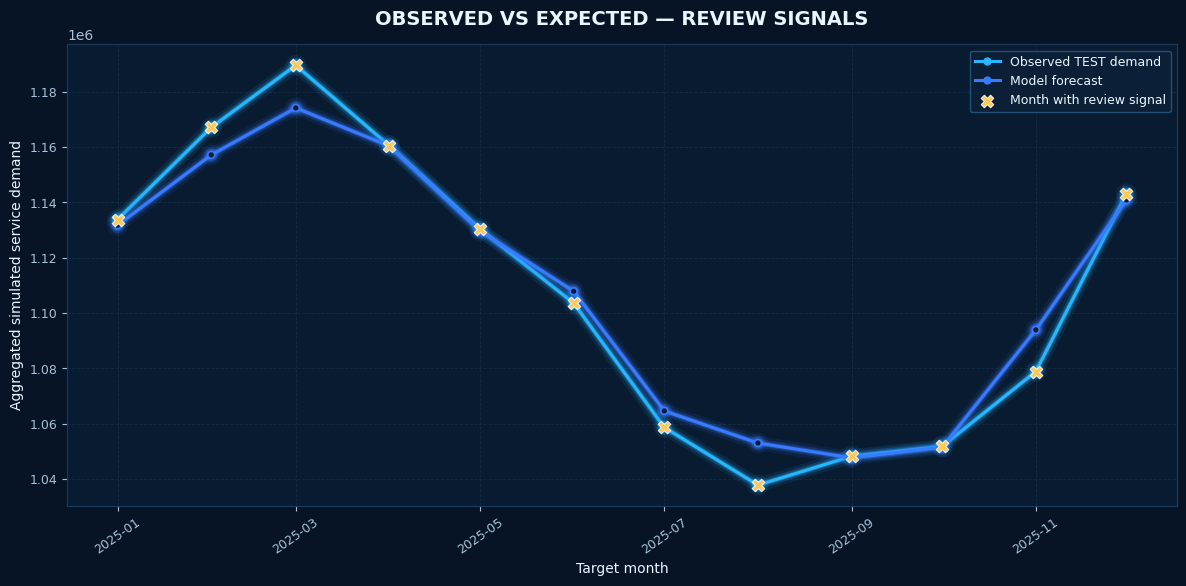

Saved: /content/afya_stream/figures/social_visual_10.png
Interpretation note: review signals are generated from simulated data and are not clinical diagnoses.


In [36]:
# ============================================================
# VISUALIZATION 10 — OBSERVED VS EXPECTED + REVIEW SIGNALS
# ============================================================

if "test12" not in globals():
    raise RuntimeError(
        "Run Stage 12 successfully before Visualization 10."
    )

v10 = test12.copy()
v10["target_month"] = pd.to_datetime(
    v10["target_month"], errors="coerce"
)
v10 = v10.dropna(
    subset=["target_month", "target_next_month", "forecast_prediction"]
)

monthly_v10 = (
    v10.groupby("target_month", as_index=False)
    .agg(
        observed=("target_next_month", "sum"),
        expected=("forecast_prediction", "sum")
    )
    .sort_values("target_month")
)

if "predicted_anomaly" in v10.columns:
    flagged_v10 = (
        v10.loc[v10["predicted_anomaly"].astype(bool)]
        .groupby("target_month")
        .size()
    )
    monthly_v10["review_signals"] = (
        monthly_v10["target_month"].map(flagged_v10).fillna(0)
    )
else:
    monthly_v10["review_signals"] = 0

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(
    monthly_v10["target_month"],
    monthly_v10["observed"],
    marker="o",
    label="Observed TEST demand",
    linewidth=2.2
)
ax.plot(
    monthly_v10["target_month"],
    monthly_v10["expected"],
    marker="o",
    label="Model forecast",
    linewidth=2.2
)

signal_mask = monthly_v10["review_signals"] > 0
ax.scatter(
    monthly_v10.loc[signal_mask, "target_month"],
    monthly_v10.loc[signal_mask, "observed"],
    s=80,
    marker="X",
    color=WARNING_AMBER,
    edgecolor=TEXT_LIGHT,
    linewidth=0.8,
    label="Month with review signal",
    zorder=5
)

ax.set_title("OBSERVED VS EXPECTED — REVIEW SIGNALS", pad=14)
ax.set_xlabel("Target month")
ax.set_ylabel("Aggregated simulated service demand")
ax.grid(alpha=0.42)
ax.legend(loc="best", fontsize=9)
plt.xticks(rotation=35)
fig.tight_layout()

out = FIGURES_DIR / "social_visual_10.png"
apply_neon_style(fig)
fig.savefig(out, dpi=200, bbox_inches="tight")
apply_neon_style(fig)
plt.show()
print("Saved:", out)
print(
    "Interpretation note: review signals are generated from simulated data "
    "and are not clinical diagnoses."
)

## STAGE 16 — DASHBOARD

Dashboard ya ndani ya project yenye forecast monitoring, model comparison ya validation, early-warning review signals na regional robustness. Mipigo ya blue/cyan glow ni styling ya kuona tu; metrics zinatokana na outputs za model, na demand ya toleo hili ni simulation.

In [37]:
# ============================================================
# STAGE 16 — INTERACTIVE DASHBOARD
# AfyaStream AI | Neon-blue research dashboard
# ============================================================

from pathlib import Path
import json
import pandas as pd
import numpy as np
import plotly.graph_objects as go
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("=" * 72)
print("STAGE 16 — INTERACTIVE RESEARCH DASHBOARD")
print("=" * 72)


# ------------------------------------------------------------
# 16.1 PATHS AND TEST PREDICTIONS
# ------------------------------------------------------------

ROOT16 = Path(globals().get("ROOT", "/content/afya_stream"))
REPORTS16 = Path(globals().get("REPORTS_DIR", ROOT16 / "reports"))
AUDIT16 = Path(globals().get("AUDIT_DIR", ROOT16 / "audit"))
FIGURES16 = Path(globals().get("FIGURES_DIR", ROOT16 / "figures"))
PREDICTIONS16 = Path(globals().get("PREDICTIONS_DIR", ROOT16 / "predictions"))

DASH_DIR = REPORTS16 / "dashboard"
DASH_DIR.mkdir(parents=True, exist_ok=True)

if "test12" in globals():
    dashboard_test16 = test12.copy()
else:
    test_file16 = PREDICTIONS16 / "stage12_test_predictions.csv"
    if not test_file16.exists():
        raise FileNotFoundError(
            f"Stage 12 predictions not found: {test_file16}. Run Stage 12 first."
        )
    dashboard_test16 = pd.read_csv(test_file16)

required16 = [
    "target_month",
    "target_next_month",
    "forecast_prediction"
]
missing16 = [c for c in required16 if c not in dashboard_test16.columns]
if missing16:
    raise ValueError(
        "Stage 12 predictions are missing: " + ", ".join(missing16)
    )

dashboard_test16["target_month"] = pd.to_datetime(
    dashboard_test16["target_month"], errors="coerce"
)
for col in ["target_next_month", "forecast_prediction"]:
    dashboard_test16[col] = pd.to_numeric(
        dashboard_test16[col], errors="coerce"
    )

dashboard_test16 = dashboard_test16.dropna(
    subset=required16
).copy()

if dashboard_test16.empty:
    raise ValueError("No usable TEST observations remain for the dashboard.")

monthly16 = (
    dashboard_test16
    .groupby("target_month", as_index=False)
    .agg(
        observed_demand=("target_next_month", "sum"),
        predicted_demand=("forecast_prediction", "sum")
    )
    .sort_values("target_month")
)

y16 = dashboard_test16["target_next_month"].to_numpy(dtype=float)
pred16 = dashboard_test16["forecast_prediction"].to_numpy(dtype=float)
dashboard_mae16 = float(mean_absolute_error(y16, pred16))
dashboard_rmse16 = float(np.sqrt(mean_squared_error(y16, pred16)))
dashboard_r216 = float(r2_score(y16, pred16))


# ------------------------------------------------------------
# 16.2 LOAD VALIDATION MODEL COMPARISON
# ------------------------------------------------------------
# Prefer current-run in-memory Stage 11 results, then its audit JSON.
# Existing CSV is a fallback only, to avoid reusing stale dashboard output.

comparison16 = None
comparison_source16 = None

if "results_df" in globals():
    try:
        comparison16 = results_df.copy()
        comparison_source16 = "Current-run Stage 11 validation results"
    except Exception:
        comparison16 = None

if comparison16 is None and "forecast_results" in globals():
    try:
        comparison16 = forecast_results.copy()
        comparison_source16 = "Current-run Stage 11 validation results"
    except Exception:
        comparison16 = None

if comparison16 is None:
    comparison_json16 = AUDIT16 / "stage11_model_comparison.json"
    if comparison_json16.exists():
        with open(comparison_json16, "r", encoding="utf-8") as handle:
            payload16 = json.load(handle)

        def find_model_rows16(obj):
            if isinstance(obj, list):
                if obj and all(isinstance(item, dict) for item in obj):
                    keys = set().union(*(set(item.keys()) for item in obj))
                    model_key_found = any(
                        key.lower() in {"model", "model_name", "algorithm", "method"}
                        for key in keys
                    )
                    rmse_key_found = any(
                        key.lower() == "rmse"
                        for key in keys
                    )
                    if model_key_found and rmse_key_found:
                        return obj
                for item in obj:
                    found = find_model_rows16(item)
                    if found is not None:
                        return found
            elif isinstance(obj, dict):
                for value in obj.values():
                    found = find_model_rows16(value)
                    if found is not None:
                        return found
            return None

        records16 = find_model_rows16(payload16)
        if records16 is not None:
            comparison16 = pd.DataFrame(records16)
            comparison_source16 = "Saved Stage 11 audit JSON"

if comparison16 is None:
    comparison_csv16 = REPORTS16 / "forecast_model_comparison.csv"
    if comparison_csv16.exists():
        comparison16 = pd.read_csv(comparison_csv16)
        comparison_source16 = "Existing saved comparison CSV (fallback)"

if comparison16 is None:
    # Explicit fallback from the previous successful Stage 11 validation run.
    # This is validation data, not a recomputation from the TEST dataset.
    comparison16 = pd.DataFrame({
        "model": [
            "Naive Last-Value",
            "Seasonal Naive 12M",
            "Random Forest",
            "HistGradientBoosting"
        ],
        "MAE": [55.694904, 57.957214, 43.488822, 42.350714],
        "RMSE": [136.870403, 143.931081, 113.991788, 113.083475],
        "MAPE": [10.038335, 10.201054, 7.633000, 7.454280],
        "sMAPE": [9.945675, 10.393982, 7.554227, 7.422870],
        "R2": [0.954297, 0.949460, 0.968299, 0.968802]
    })
    comparison_source16 = "Recorded Stage 11 validation results (fallback)"

if "model" not in comparison16.columns:
    model_key16 = next(
        (c for c in comparison16.columns
         if c.lower() in {"model_name", "algorithm", "method"}),
        None
    )
    if model_key16:
        comparison16 = comparison16.rename(columns={model_key16: "model"})

rmse_key16 = next(
    (c for c in comparison16.columns if c.lower() == "rmse"),
    None
)
if "model" not in comparison16.columns or rmse_key16 is None:
    raise ValueError(
        "The model-comparison source must include model names and an RMSE metric."
    )
if rmse_key16 != "RMSE":
    comparison16 = comparison16.rename(columns={rmse_key16: "RMSE"})

comparison16["RMSE"] = pd.to_numeric(comparison16["RMSE"], errors="coerce")
comparison16 = comparison16.dropna(subset=["model", "RMSE"]).copy()

comparison_csv16 = REPORTS16 / "forecast_model_comparison.csv"
comparison16.to_csv(comparison_csv16, index=False, encoding="utf-8-sig")

# ------------------------------------------------------------
# 16.3 PLOTLY NEON LINE HELPER
# ------------------------------------------------------------

PLOT_BG16 = "#08182B"
PAPER_BG16 = "#061426"
FONT16 = "#EAF6FF"
GRID16 = "#1C3A58"
BLUE16 = "#26B7FF"
CYAN16 = "#70E7FF"
AMBER16 = "#FFC857"

def add_glow_line16(fig, x, y, name, color, marker=False):
    # Multiple semi-transparent strokes create a visual glow without changing data.
    rgba_layers = [
        (13, 0.055),
        (8, 0.10),
        (4.5, 0.18)
    ]
    for width, alpha in rgba_layers:
        fig.add_trace(go.Scatter(
            x=x, y=y, mode="lines",
            line=dict(color=color, width=width),
            opacity=alpha,
            hoverinfo="skip",
            showlegend=False,
            legendgroup=name
        ))
    fig.add_trace(go.Scatter(
        x=x, y=y,
        mode="lines+markers" if marker else "lines",
        name=name,
        line=dict(color=color, width=2.5),
        marker=dict(
            color=color,
            size=6,
            line=dict(color=FONT16, width=0.7)
        ) if marker else None,
        legendgroup=name
    ))

def finish_plotly16(fig, title, x_title, y_title):
    fig.update_layout(
        title=dict(text=title, x=0.03, xanchor="left"),
        paper_bgcolor=PAPER_BG16,
        plot_bgcolor=PLOT_BG16,
        font=dict(family="Arial, sans-serif", color=FONT16, size=12),
        xaxis=dict(
            title=x_title,
            gridcolor=GRID16,
            zerolinecolor=GRID16,
            showline=True,
            linecolor=GRID16
        ),
        yaxis=dict(
            title=y_title,
            gridcolor=GRID16,
            zerolinecolor=GRID16,
            showline=True,
            linecolor=GRID16
        ),
        legend=dict(
            bgcolor="rgba(9,27,48,0.88)",
            bordercolor="#24547A",
            borderwidth=1
        ),
        margin=dict(l=65, r=35, t=75, b=60),
        hovermode="x unified"
    )
    return fig


# ------------------------------------------------------------
# 16.4 FORECAST MONITORING
# ------------------------------------------------------------

fig1 = go.Figure()
add_glow_line16(
    fig1,
    monthly16["target_month"],
    monthly16["observed_demand"],
    "Observed TEST demand",
    CYAN16,
    marker=True
)
add_glow_line16(
    fig1,
    monthly16["target_month"],
    monthly16["predicted_demand"],
    "Model forecast",
    BLUE16,
    marker=True
)
finish_plotly16(
    fig1,
    "Forecast Monitoring — Observed vs Predicted",
    "Target month",
    "Aggregated simulated service demand"
)


# ------------------------------------------------------------
# 16.5 VALIDATION MODEL COMPARISON
# ------------------------------------------------------------

fig2 = go.Figure()
colors16 = [CYAN16 if i == 0 else BLUE16 for i in range(len(comparison16))]
fig2.add_trace(go.Bar(
    x=comparison16["model"].astype(str),
    y=comparison16["RMSE"],
    marker=dict(
        color=colors16,
        line=dict(color=CYAN16, width=1)
    ),
    text=comparison16["RMSE"].map(lambda value: f"{value:.2f}"),
    textposition="outside",
    name="Validation RMSE"
))
fig2.update_layout(
    title=dict(text="Stage 11 — Validation Model Comparison", x=0.03),
    paper_bgcolor=PAPER_BG16,
    plot_bgcolor=PLOT_BG16,
    font=dict(family="Arial, sans-serif", color=FONT16, size=12),
    xaxis=dict(title="Model", gridcolor=GRID16, tickangle=-15),
    yaxis=dict(title="Validation RMSE (lower is better)", gridcolor=GRID16),
    margin=dict(l=65, r=30, t=75, b=100),
    showlegend=False
)


# ------------------------------------------------------------
# 16.6 EARLY-WARNING SIGNAL COUNTS
# ------------------------------------------------------------

if "predicted_anomaly" in dashboard_test16.columns:
    anomaly_monthly16 = (
        dashboard_test16
        .assign(
            predicted_anomaly=dashboard_test16[
                "predicted_anomaly"
            ].astype(bool)
        )
        .groupby("target_month", as_index=False)
        .agg(
            review_signals=("predicted_anomaly", "sum")
        )
        .sort_values("target_month")
    )
else:
    anomaly_monthly16 = pd.DataFrame({
        "target_month": monthly16["target_month"],
        "review_signals": np.zeros(len(monthly16), dtype=int)
    })

fig3 = go.Figure()
fig3.add_trace(go.Bar(
    x=anomaly_monthly16["target_month"],
    y=anomaly_monthly16["review_signals"],
    marker=dict(
        color=BLUE16,
        line=dict(color=CYAN16, width=1)
    ),
    name="Flagged records"
))
fig3.update_layout(
    title=dict(text="Residual-Based Early-Warning Signals", x=0.03),
    paper_bgcolor=PAPER_BG16,
    plot_bgcolor=PLOT_BG16,
    font=dict(family="Arial, sans-serif", color=FONT16, size=12),
    xaxis=dict(title="Target month", gridcolor=GRID16),
    yaxis=dict(title="Flagged TEST records", gridcolor=GRID16),
    margin=dict(l=65, r=30, t=75, b=60),
    showlegend=False
)


# ------------------------------------------------------------
# 16.7 REGIONAL ROBUSTNESS
# ------------------------------------------------------------

regional_path16 = FIGURES16 / "stage13" / "regional_performance.csv"
if regional_path16.exists():
    regional16 = pd.read_csv(regional_path16)
    regional16["RMSE"] = pd.to_numeric(regional16["RMSE"], errors="coerce")
    regional16 = (
        regional16.dropna(subset=["region", "RMSE"])
        .sort_values("RMSE", ascending=False)
        .head(10)
        .sort_values("RMSE", ascending=True)
    )
else:
    regional16 = pd.DataFrame({
        "region": ["Regional report not available yet"],
        "RMSE": [0.0]
    })

fig4 = go.Figure()
fig4.add_trace(go.Bar(
    x=regional16["RMSE"],
    y=regional16["region"].astype(str),
    orientation="h",
    marker=dict(
        color=BLUE16,
        line=dict(color=CYAN16, width=1)
    ),
    name="Regional TEST RMSE"
))
fig4.update_layout(
    title=dict(text="Stage 13 — Regions with Highest TEST RMSE", x=0.03),
    paper_bgcolor=PAPER_BG16,
    plot_bgcolor=PLOT_BG16,
    font=dict(family="Arial, sans-serif", color=FONT16, size=12),
    xaxis=dict(title="RMSE (lower is better)", gridcolor=GRID16),
    yaxis=dict(title="Region", gridcolor=GRID16),
    margin=dict(l=170, r=30, t=75, b=60),
    showlegend=False
)


# ------------------------------------------------------------
# 16.8 EXPORT PREDICTIONS AND DASHBOARD
# ------------------------------------------------------------

predictions_export16 = REPORTS16 / "forecast_predictions_and_anomalies.csv"
dashboard_test16.to_csv(
    predictions_export16,
    index=False,
    encoding="utf-8-sig"
)

selected_model16 = (
    best_model_name
    if "best_model_name" in globals()
    else "HistGradientBoostingRegressor"
)

simulation_note16 = (
    "Uwazi wa data: demand values zinazoonekana kwenye toleo hili "
    "ni za controlled simulation, si idadi halisi za wagonjwa au huduma "
    "kutoka hospitalini. Early-warning ni signal ya review, si diagnosis."
)

html16 = f"""<!DOCTYPE html>
<html lang="sw">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>AfyaStream AI — Research Dashboard</title>
<style>
:root {{
  --bg: #061426; --panel: #0C2038; --blue: #26B7FF;
  --cyan: #70E7FF; --text: #EAF6FF; --muted: #A7C2D9;
  --line: #1C3A58; --amber: #FFC857;
}}
* {{ box-sizing: border-box; }}
body {{
  margin: 0; background: var(--bg); color: var(--text);
  font-family: Inter, Arial, sans-serif; line-height: 1.55;
}}
.wrap {{ max-width: 1320px; padding: 30px 22px 60px; margin: 0 auto; }}
.eyebrow {{
  color: var(--cyan); text-transform: uppercase; letter-spacing: .15em;
  font-size: 12px; font-weight: 700;
}}
h1 {{ margin: 8px 0; font-size: clamp(30px, 5vw, 48px); }}
h2 {{ font-size: 20px; margin-top: 30px; }}
.sub {{ color: var(--muted); max-width: 900px; }}
.rule {{ border: 0; border-top: 1px solid var(--line); margin: 24px 0; }}
.kpis {{
  display: grid; grid-template-columns: repeat(auto-fit,minmax(190px,1fr));
  gap: 14px; margin: 22px 0;
}}
.kpi {{
  background: linear-gradient(145deg, #0C2038, #091B30);
  border: 1px solid #24547A; border-radius: 14px; padding: 18px;
  box-shadow: 0 0 18px rgba(38,183,255,.07);
}}
.kpi .label {{ color: var(--muted); font-size: 12px; }}
.kpi .value {{ color: var(--cyan); font-weight: 750; font-size: 26px; margin-top: 5px; }}
.chart {{
  background: var(--panel); border: 1px solid #24547A;
  border-radius: 14px; padding: 10px; margin: 18px 0;
  box-shadow: 0 0 22px rgba(38,183,255,.05);
}}
.notice {{
  border-left: 4px solid var(--amber); background: #211F1B;
  color: #FFE7AD; border-radius: 8px; padding: 14px 16px; margin: 20px 0;
}}
footer {{ color: var(--muted); border-top: 1px solid var(--line); margin-top: 32px; padding-top: 18px; font-size: 12px; }}
</style>
</head>
<body>
<div class="wrap">
  <div class="eyebrow">Health-system analytics • research prototype</div>
  <h1>AfyaStream AI</h1>
  <p class="sub">Kutoka data za afya hadi maarifa yanayochukua hatua. Dashboard ya forecasting, model comparison, anomaly review signals na robustness.</p>
  <hr class="rule">
  <div class="kpis">
    <div class="kpi"><div class="label">Model iliyochaguliwa</div><div class="value" style="font-size:20px">{selected_model16}</div></div>
    <div class="kpi"><div class="label">TEST MAE</div><div class="value">{dashboard_mae16:.2f}</div></div>
    <div class="kpi"><div class="label">TEST RMSE</div><div class="value">{dashboard_rmse16:.2f}</div></div>
    <div class="kpi"><div class="label">TEST R²</div><div class="value">{dashboard_r216:.4f}</div></div>
  </div>
  <div class="notice"><b>Uwazi wa data:</b> {simulation_note16}</div>
  <div class="chart">{fig1.to_html(full_html=False, include_plotlyjs="cdn")}</div>
  <div class="chart">{fig2.to_html(full_html=False, include_plotlyjs=False)}</div>
  <div class="chart">{fig3.to_html(full_html=False, include_plotlyjs=False)}</div>
  <div class="chart">{fig4.to_html(full_html=False, include_plotlyjs=False)}</div>
  <footer>Model-comparison source: {comparison_source16}. Model comparison uses Stage 11 validation results. TEST metrics are reserved for final evaluation. This prototype is not a deployed hospital system.</footer>
</div>
</body>
</html>
"""

dashboard_path16 = DASH_DIR / "afya_stream_dashboard.html"
dashboard_path16.write_text(
    html16,
    encoding="utf-8"
)

print("✅ Dashboard saved:", dashboard_path16)
print("✅ Model comparison saved:", comparison_csv16)
print("✅ TEST prediction export saved:", predictions_export16)
print("Dashboard TEST MAE:", round(dashboard_mae16, 4))
print("Dashboard TEST RMSE:", round(dashboard_rmse16, 4))
print("Dashboard TEST R²:", round(dashboard_r216, 4))
print("Model comparison source:", comparison_source16)
print("=" * 72)
print("✅ STAGE 16 COMPLETED")
print("=" * 72)

STAGE 16 — INTERACTIVE RESEARCH DASHBOARD
✅ Dashboard saved: /content/afya_stream/reports/dashboard/afya_stream_dashboard.html
✅ Model comparison saved: /content/afya_stream/reports/forecast_model_comparison.csv
✅ TEST prediction export saved: /content/afya_stream/reports/forecast_predictions_and_anomalies.csv
Dashboard TEST MAE: 43.1882
Dashboard TEST RMSE: 101.1471
Dashboard TEST R²: 0.9781
Model comparison source: Current-run Stage 11 validation results
✅ STAGE 16 COMPLETED


# SOCIAL MEDIA — POST 11/13

## **Hatutaamini model moja bila comparison.**

Tutalinganisha baselines na ML models kwa metrics zinazofaa task. Lengo si kupata namba kubwa tu. **Lengo ni kuelewa model inafanya nini, wapi, na kwa hali gani.**

**Uwazi wa data:** comparison ni ya validation kwenye simulated service-demand data.

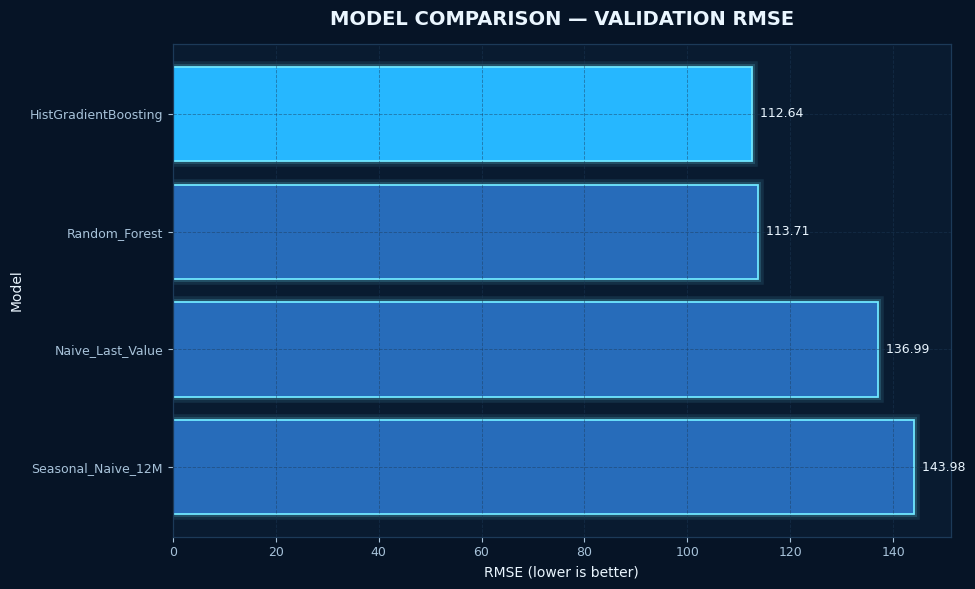

Saved: /content/afya_stream/figures/social_visual_11.png
Metric source: Stage 11 validation comparison; TEST was reserved for final evaluation.


In [38]:
# ============================================================
# VISUALIZATION 11 — VALIDATION MODEL COMPARISON
# ============================================================

comparison_path11 = REPORTS_DIR / "forecast_model_comparison.csv"

if comparison_path11.exists():
    model_v11 = pd.read_csv(comparison_path11)
elif "forecast_results" in globals():
    model_v11 = forecast_results.copy()
else:
    model_v11 = pd.DataFrame({
        "model": [
            "Naive Last-Value",
            "Seasonal Naive 12M",
            "Random Forest",
            "HistGradientBoosting"
        ],
        "RMSE": [
            136.870403,
            143.931081,
            113.991788,
            113.083475
        ]
    })

if "model" not in model_v11.columns:
    model_col11 = next(
        (c for c in model_v11.columns
         if c.lower() in {"model_name", "algorithm", "method"}),
        None
    )
    if model_col11:
        model_v11 = model_v11.rename(columns={model_col11: "model"})

if "RMSE" not in model_v11.columns:
    raise ValueError("Model comparison data must include an RMSE column.")

model_v11["RMSE"] = pd.to_numeric(model_v11["RMSE"], errors="coerce")
model_v11 = model_v11.dropna(subset=["model", "RMSE"]).sort_values("RMSE")

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(
    model_v11["model"].astype(str),
    model_v11["RMSE"],
    color=[NEON_BLUE if i == 0 else "#276CBA" for i in range(len(model_v11))],
    edgecolor=NEON_CYAN,
    linewidth=1.0
)
ax.invert_yaxis()
ax.set_title("MODEL COMPARISON — VALIDATION RMSE", pad=14)
ax.set_xlabel("RMSE (lower is better)")
ax.set_ylabel("Model")
ax.grid(axis="x", alpha=0.4)
ax.grid(axis="y", visible=False)

for bar in bars:
    width = bar.get_width()
    ax.text(
        width,
        bar.get_y() + bar.get_height() / 2,
        f"  {width:.2f}",
        va="center",
        ha="left",
        fontsize=9,
        color=TEXT_LIGHT
    )

fig.tight_layout()
out = FIGURES_DIR / "social_visual_11.png"
apply_neon_style(fig)
fig.savefig(out, dpi=200, bbox_inches="tight")
apply_neon_style(fig)
plt.show()
print("Saved:", out)
print("Metric source: Stage 11 validation comparison; TEST was reserved for final evaluation.")

## STAGE 17 — MODEL CARD + DATA CARD + PROVENANCE

In [39]:
# ============================================================
# STAGE 17 — MODEL CARD & DATA CARD
# ============================================================

import json
import pandas as pd
from pathlib import Path

print("=" * 72)
print("STAGE 17 — MODEL CARD & DATA CARD")
print("=" * 72)

# Safely cast directory globals to Path objects to prevent string division errors
AUDIT_DIR_PATH = Path(globals().get("AUDIT_DIR", "/content/afya_stream/audit"))
RAW_DIR_PATH = Path(globals().get("RAW_DIR", "/content/afya_stream/raw"))

# ------------------------------------------------------------
# 17.1 MODEL FEATURES
# ------------------------------------------------------------

if "model_features" in globals():
    model_features17 = list(model_features)
else:
    model_features17 = []

# ------------------------------------------------------------
# 17.2 SELECTED MODEL
# ------------------------------------------------------------

selected_model17 = (
    best_model_name
    if "best_model_name" in globals()
    else "HistGradientBoostingRegressor"
)

# ------------------------------------------------------------
# 17.3 TEST METRICS
# ------------------------------------------------------------

test_metrics17 = {}

if all(
    variable in globals()
    for variable in [
        "test_mae",
        "test_rmse",
        "test_mape",
        "test_smape",
        "test_r2"
    ]
):
    test_metrics17 = {
        "MAE": float(test_mae),
        "RMSE": float(test_rmse),
        "MAPE_pct": float(test_mape),
        "sMAPE_pct": float(test_smape),
        "R2": float(test_r2)
    }

# ------------------------------------------------------------
# 17.4 MODEL CARD
# ------------------------------------------------------------

model_card17 = {
    "project": "AfyaStream AI",
    "academic_title":
        "Mfumo wa Mwisho hadi Mwisho wa Data Kubwa na "
        "Machine Learning kwa Utabiri wa Mahitaji ya "
        "Huduma za Afya na Kugundua Mabadiliko "
        "Yasiyo ya Kawaida Tanzania",
    "task": "Monthly health-service demand forecasting",
    "secondary_task": "Residual-based early-warning anomaly detection",
    "selected_model": selected_model17,
    "model_selection": "Stage 11 validation comparison",
    "final_training": "TRAIN + VALIDATION",
    "test_usage": "Final evaluation only",
    "forecast_features": model_features17,
    "test_performance": test_metrics17,
    "important_constraints": [
        "The current service-demand values are simulated.",
        "Forecast metrics represent an experimental research prototype.",
        "Results do not represent actual hospital performance.",
        "The system does not provide patient-level diagnosis.",
        "Early-warning signals are for review and investigation, not diagnosis.",
        "Operational deployment requires appropriate routine health-service data and independent validation.",
        "The anomaly threshold was calibrated using validation data and is not a production threshold."
    ]
}

model_card_file17 = AUDIT_DIR_PATH / "model_card.json"

model_card_file17.write_text(
    json.dumps(
        model_card17,
        indent=2,
        default=str,
        ensure_ascii=False
    ),
    encoding="utf-8"
)

# ------------------------------------------------------------
# 17.5 LOAD DATA CARD SOURCE
# ------------------------------------------------------------

service_file17 = RAW_DIR_PATH / "tanzania_health_service_timeseries.csv"

if service_file17.exists():
    data_source17 = pd.read_csv(service_file17)
elif "service_timeseries_df" in globals():
    data_source17 = service_timeseries_df.copy()
else:
    raise FileNotFoundError(
        "Tanzania health-service timeseries dataset was not found."
    )

# ------------------------------------------------------------
# 17.6 DATA CARD
# ------------------------------------------------------------

data_source17["date"] = pd.to_datetime(
    data_source17["date"],
    errors="coerce"
)

data_card17 = {
    "project": "AfyaStream AI",
    "data_mode": (
        SELECTED_MODE
        if "SELECTED_MODE" in globals()
        else "TANZANIA_HFR_SIMULATION"
    ),
    "total_rows": int(len(data_source17)),
    "unique_facilities": int(data_source17["facility_id"].nunique()),
    "unique_regions": int(data_source17["region"].nunique()),
    "service_types": int(data_source17["service_type"].nunique()),
    "date_start": str(data_source17["date"].min()),
    "date_end": str(data_source17["date"].max()),
    "facility_context": "Tanzania Health Facility Registry (HFR)",
    "hfr_source": "https://hfrportal.moh.go.tz/",
    "moh_source": "https://www.moh.go.tz/",
    "dhis_source": "https://dhis.moh.go.tz/",
    "hmis_source": "https://hmisportal.moh.go.tz/",
    "service_demand_mode": "CONTROLLED SYNTHETIC SIMULATION",
    "privacy": "Aggregated/non-identifiable project data only.",
    "critical_provenance_note":
        "Facility context is derived from the HFR analytical "
        "hospital cohort. Health-service demand values used "
        "for modeling are simulated."
}

data_card_file17 = AUDIT_DIR_PATH / "data_card.json"

data_card_file17.write_text(
    json.dumps(
        data_card17,
        indent=2,
        default=str,
        ensure_ascii=False
    ),
    encoding="utf-8"
)

print("\n✅ Model card saved:")
print(model_card_file17)
print("\n✅ Data card saved:")
print(data_card_file17)
print("\n" + "=" * 72)
print("✅ STAGE 17 COMPLETED")
print("=" * 72)

STAGE 17 — MODEL CARD & DATA CARD

✅ Model card saved:
/content/afya_stream/audit/model_card.json

✅ Data card saved:
/content/afya_stream/audit/data_card.json

✅ STAGE 17 COMPLETED


# SOCIAL MEDIA — POST 12/13

## **Matokeo mazuri hayatoshi.**

Tutauliza: Je, model inafanya kazi kwenye maeneo tofauti? Missing data je? Reporting ikichelewa? Data volume ikibadilika? Feature moja ikiondolewa?

**Hii ndiyo inabadilisha demo kuwa research.**

**Uwazi wa data:** robustness tests ni controlled simulation tests, si uthibitisho wa utendaji kwenye data halisi.

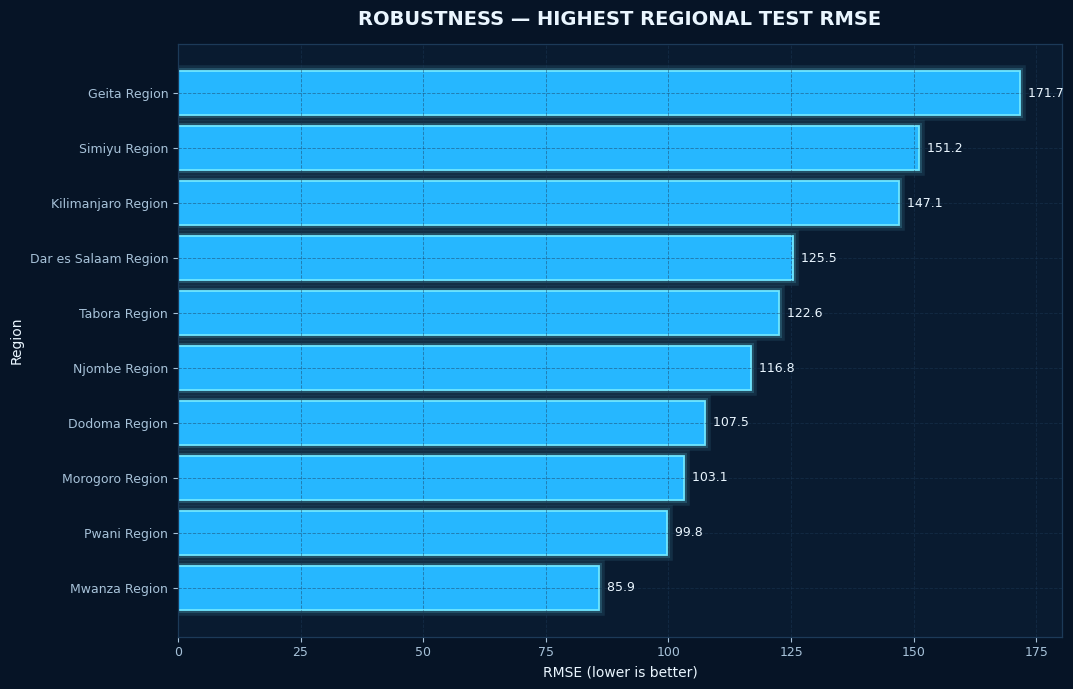

Saved: /content/afya_stream/figures/social_visual_12.png
Interpretation: variation across regions matters; metrics are based on the simulated service-demand experiment.


In [40]:
# ============================================================
# VISUALIZATION 12 — REGIONAL ROBUSTNESS
# ============================================================

regional_path12 = FIGURES_DIR / "stage13" / "regional_performance.csv"

if regional_path12.exists():
    regional_v12 = pd.read_csv(regional_path12)
    regional_v12["RMSE"] = pd.to_numeric(
        regional_v12["RMSE"], errors="coerce"
    )
    regional_v12 = (
        regional_v12.dropna(subset=["region", "RMSE"])
        .sort_values("RMSE", ascending=False)
        .head(10)
        .sort_values("RMSE", ascending=True)
    )
else:
    regional_v12 = pd.DataFrame({
        "region": [
            "Regional metrics unavailable",
            "Run Stage 13 first"
        ],
        "RMSE": [0, 0]
    })

fig, ax = plt.subplots(figsize=(11, 7))
bars = ax.barh(
    regional_v12["region"].astype(str),
    regional_v12["RMSE"],
    color=NEON_BLUE,
    edgecolor=NEON_CYAN,
    linewidth=1.0
)
ax.set_title("ROBUSTNESS — HIGHEST REGIONAL TEST RMSE", pad=14)
ax.set_xlabel("RMSE (lower is better)")
ax.set_ylabel("Region")
ax.grid(axis="x", alpha=0.4)
ax.grid(axis="y", visible=False)

for bar in bars:
    width = bar.get_width()
    if width > 0:
        ax.text(
            width,
            bar.get_y() + bar.get_height() / 2,
            f"  {width:.1f}",
            va="center",
            color=TEXT_LIGHT,
            fontsize=9
        )

fig.tight_layout()
out = FIGURES_DIR / "social_visual_12.png"
apply_neon_style(fig)
fig.savefig(out, dpi=200, bbox_inches="tight")
apply_neon_style(fig)
plt.show()
print("Saved:", out)
print(
    "Interpretation: variation across regions matters; "
    "metrics are based on the simulated service-demand experiment."
)

## STAGE 18 — OPTIONAL KAFKA TRANSPORT

Default yake ni `False`. Local Spark Structured Streaming replay ndiyo baseline ya runnable notebook.

Kwa Aiven Kafka tumia environment variables na **usiweke password kwenye source code**:
- `KAFKA_BOOTSTRAP`
- `KAFKA_USERNAME`
- `KAFKA_PASSWORD`
- `KAFKA_CA_FILE`

Usitumie placeholder `<runtime-supplied-kafka-host>`.

In [41]:
# ============================================================
# STAGE 18 — OPTIONAL KAFKA TRANSPORT
# ============================================================

import os
import json

print("=" * 72)
print("STAGE 18 — OPTIONAL KAFKA TRANSPORT")
print("=" * 72)


ENABLE_KAFKA = False


if not ENABLE_KAFKA:

    print(
        "ℹ️ Kafka transport is disabled."
    )

    print(
        "✅ Stage 15 local Spark streaming replay "
        "remains the runnable streaming demonstration."
    )

else:

    import importlib.util
    import subprocess
    import sys


    # --------------------------------------------------------
    # Install kafka-python only when explicitly enabled
    # --------------------------------------------------------

    if importlib.util.find_spec(
        "kafka"
    ) is None:

        subprocess.check_call(
            [
                sys.executable,
                "-m",
                "pip",
                "install",
                "-q",
                "kafka-python"
            ]
        )


    from kafka import KafkaProducer


    # --------------------------------------------------------
    # Validate credentials
    # --------------------------------------------------------

    required18 = [

        "KAFKA_BOOTSTRAP",
        "KAFKA_USERNAME",
        "KAFKA_PASSWORD",
        "KAFKA_CA_FILE"

    ]


    missing18 = [

        variable

        for variable in required18

        if not os.environ.get(variable)

    ]


    if missing18:

        raise RuntimeError(

            "Kafka is enabled but these environment "
            "variables are missing: "

            +

            ", ".join(
                missing18
            )

        )


    bootstrap18 = os.environ[
        "KAFKA_BOOTSTRAP"
    ]


    if (
        "<runtime-supplied-kafka-host>"
        in bootstrap18
    ):

        raise ValueError(
            "Kafka bootstrap still contains "
            "placeholder text."
        )


    if "test12" not in globals():

        raise NameError(
            "test12 is unavailable. "
            "Run Stage 12 before enabling Kafka."
        )


    # --------------------------------------------------------
    # Kafka producer
    # --------------------------------------------------------

    producer18 = KafkaProducer(

        bootstrap_servers=
            bootstrap18,

        security_protocol=
            "SASL_SSL",

        sasl_mechanism=
            "SCRAM-SHA-256",

        sasl_plain_username=
            os.environ[
                "KAFKA_USERNAME"
            ],

        sasl_plain_password=
            os.environ[
                "KAFKA_PASSWORD"
            ],

        ssl_cafile=
            os.environ[
                "KAFKA_CA_FILE"
            ],

        value_serializer=
            lambda value:
                json.dumps(
                    value
                ).encode("utf-8")
    )


    # --------------------------------------------------------
    # Publish replay messages
    # --------------------------------------------------------

    for _, row in test12.iterrows():

        message18 = {

            "event_time":
                str(
                    pd.to_datetime(
                        row["target_month"]
                    )
                ),

            "region":
                str(
                    row["region"]
                ),

            "facility_id":
                str(
                    row["facility_id"]
                ),

            "facility_name":
                str(
                    row["facility_name"]
                ),

            "service_type":
                str(
                    row["service_type"]
                ),

            "demand":
                float(
                    row["target_next_month"]
                ),

            "prediction":
                float(
                    row["forecast_prediction"]
                ),

            "residual":
                float(
                    row["forecast_residual"]
                )

        }


        producer18.send(
            "afya_health_stream",
            message18
        )


    producer18.flush()
    producer18.close()


    print(
        "✅ Kafka publishing completed."
    )


print(
    "\n" + "=" * 72
)

print(
    "✅ STAGE 18 COMPLETED"
)

print(
    "=" * 72
)

STAGE 18 — OPTIONAL KAFKA TRANSPORT
ℹ️ Kafka transport is disabled.
✅ Stage 15 local Spark streaming replay remains the runnable streaming demonstration.

✅ STAGE 18 COMPLETED


# SOCIAL MEDIA — POST 13/13

## **Hii ndiyo AfyaStream AI.**

Kutoka kwenye data za afya → ingestion → Big Data processing → feature engineering → forecasting → anomaly detection → streaming replay → dashboard → early-warning signals.

**AfyaStream AI** ni research-and-engineering project inayochunguza jinsi Data Kubwa, Machine Learning na Streaming Analytics zinavyoweza kusaidia kuelewa mwenendo wa huduma za afya Tanzania.

### **Kutoka Data za Afya hadi Maarifa Yanayochukua Hatua.**

**Uwazi wa data:** service-demand series ni simulation; project hii ni research prototype, si mfumo uliowekwa hospitalini.

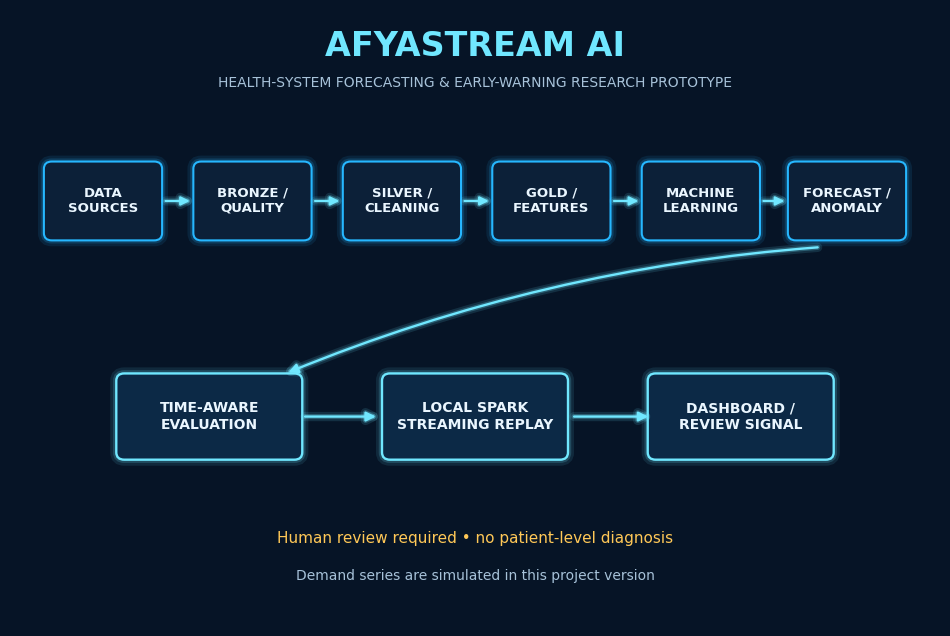

Saved: /content/afya_stream/figures/social_visual_13.png


In [42]:
# ============================================================
# VISUALIZATION 13 — COMPLETE SYSTEM ARCHITECTURE
# ============================================================
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(12, 8))
ax.set_xlim(0, 14)
ax.set_ylim(0, 10)
ax.axis("off")

ax.text(
    7, 9.25, "AFYASTREAM AI",
    ha="center", fontsize=24, fontweight="bold",
    color=NEON_CYAN
)
ax.text(
    7, 8.75,
    "HEALTH-SYSTEM FORECASTING & EARLY-WARNING RESEARCH PROTOTYPE",
    ha="center", fontsize=10, color=TEXT_MUTED
)

steps = [
    (1.4, 6.9, "DATA\nSOURCES"),
    (3.65, 6.9, "BRONZE /\nQUALITY"),
    (5.9, 6.9, "SILVER /\nCLEANING"),
    (8.15, 6.9, "GOLD /\nFEATURES"),
    (10.4, 6.9, "MACHINE\nLEARNING"),
    (12.6, 6.9, "FORECAST /\nANOMALY")
]

for x, y, label in steps:
    box = FancyBboxPatch(
        (x - 0.85, y - 0.6), 1.7, 1.2,
        boxstyle="round,pad=0.04,rounding_size=0.12",
        facecolor=PANEL_BG, edgecolor=NEON_BLUE, linewidth=1.5
    )
    ax.add_patch(box)
    ax.text(
        x, y, label, ha="center", va="center",
        fontsize=9.5, fontweight="bold", color=TEXT_LIGHT
    )

for (x1, y1, _), (x2, y2, _) in zip(steps[:-1], steps[1:]):
    ax.add_patch(FancyArrowPatch(
        (x1 + 0.9, y1), (x2 - 0.9, y2),
        arrowstyle="-|>", mutation_scale=13,
        linewidth=1.6, color=NEON_CYAN
    ))

downstream = [
    (3.0, 3.4, "TIME-AWARE\nEVALUATION"),
    (7.0, 3.4, "LOCAL SPARK\nSTREAMING REPLAY"),
    (11.0, 3.4, "DASHBOARD /\nREVIEW SIGNAL")
]

for x, y, label in downstream:
    box = FancyBboxPatch(
        (x - 1.35, y - 0.65), 2.7, 1.3,
        boxstyle="round,pad=0.05,rounding_size=0.12",
        facecolor="#0C2946", edgecolor=NEON_CYAN, linewidth=1.7
    )
    ax.add_patch(box)
    ax.text(
        x, y, label, ha="center", va="center",
        fontsize=10, fontweight="bold", color=TEXT_LIGHT
    )

# Forecast/anomaly output flows to evaluation, then replay, then dashboard.
ax.add_patch(FancyArrowPatch(
    (12.2, 6.15), (4.15, 4.1),
    arrowstyle="-|>", mutation_scale=14,
    linewidth=1.7, color=NEON_CYAN,
    connectionstyle="arc3,rad=0.08"
))
ax.add_patch(FancyArrowPatch(
    (4.4, 3.4), (5.55, 3.4),
    arrowstyle="-|>", mutation_scale=14,
    linewidth=1.7, color=NEON_CYAN
))
ax.add_patch(FancyArrowPatch(
    (8.45, 3.4), (9.65, 3.4),
    arrowstyle="-|>", mutation_scale=14,
    linewidth=1.7, color=NEON_CYAN
))

ax.text(
    7, 1.35,
    "Human review required • no patient-level diagnosis",
    ha="center", fontsize=11, color=WARNING_AMBER
)
ax.text(
    7, 0.75,
    "Demand series are simulated in this project version",
    ha="center", fontsize=10, color=TEXT_MUTED
)

out = FIGURES_DIR / "social_visual_13.png"
apply_neon_style(fig)
fig.savefig(out, dpi=200, bbox_inches="tight")
apply_neon_style(fig)
plt.show()
print("Saved:", out)

## STAGE 19 — TYPING-EFFECT SCRIPTS

Kila primary post ina headline inayoweza kuonekana **word-by-word** kwenye video. Notebook inahifadhi sequence za typing kama `.txt` ili zitumike kwenye CapCut, Canva, After Effects, au editing workflow nyingine.

In [43]:
# ============================================================
# STAGE 19 — TYPING-EFFECT HEADLINES
# ============================================================

import json

print("=" * 72)
print("STAGE 19 — TYPING-EFFECT HEADLINES")
print("=" * 72)


typing_headlines19 = {

    1:
        "Je, data za afya zinaweza kutuonya kabla tatizo halijawa kubwa?",

    2:
        "Data nyingi. Lakini je, tunazigeuza kuwa taarifa kwa wakati?",

    3:
        "Tunataka kutatua nini?",

    4:
        "Mfumo wetu unatumia data gani?",

    5:
        "Big Data inaanzia wapi?",

    6:
        "Data ya afya haipaswi kuishia kwenye CSV.",

    7:
        "Haya ndiyo maswali yanayoendesha mradi.",

    8:
        "Model haioni data ghafi tu. Inaona context.",

    9:
        "Kesho inaweza kuonekana kwenye historia ya leo.",

    10:
        "Vipi tukigundua kitu kisicho kawaida?",

    11:
        "Hatutaamini model moja bila comparison.",

    12:
        "Matokeo mazuri hayatoshi.",

    13:
        "Hii ndiyo AfyaStream AI."
}


SOCIAL_DIR.mkdir(
    parents=True,
    exist_ok=True
)


typing_manifest19 = []


for post_number, headline in (
    typing_headlines19.items()
):

    words = headline.split()

    sequence = []


    for i in range(
        1,
        len(words) + 1
    ):

        sequence.append(
            " ".join(
                words[:i]
            )
        )


    output_file19 = (

        SOCIAL_DIR /

        f"post_{post_number:02d}"
        "_typing_sequence.txt"

    )


    output_file19.write_text(

        "\n".join(sequence),

        encoding="utf-8"

    )


    typing_manifest19.append({

        "post":
            post_number,

        "headline":
            headline,

        "word_count":
            len(words),

        "file":
            str(output_file19)

    })


typing_manifest_file19 = (

    SOCIAL_DIR /

    "typing_headlines_manifest.json"

)


typing_manifest_file19.write_text(

    json.dumps(

        typing_manifest19,

        indent=2,

        ensure_ascii=False

    ),

    encoding="utf-8"

)


print(
    f"✅ Typing sequences created: "
    f"{len(typing_manifest19)}"
)

print(
    typing_manifest_file19
)


print(
    "\n" + "=" * 72
)

print(
    "✅ STAGE 19 COMPLETED"
)

print(
    "=" * 72
)

STAGE 19 — TYPING-EFFECT HEADLINES
✅ Typing sequences created: 13
/content/afya_stream/social_media/typing_headlines_manifest.json

✅ STAGE 19 COMPLETED


## STAGE 20 — CONTENT INDEX

Muundo wa campaign: **PRIMARY POST → VISUALIZATION → PRIMARY POST → VISUALIZATION**.

Kwa hiyo tunakuwa na **13 primary posts + 13 visualizations = 26 content pieces**, kila moja ikiwa na maana yake yenyewe.

In [44]:
# ============================================================
# STAGE 20 — 26-PIECE SOCIAL CONTENT INDEX
# ============================================================

import pandas as pd

print("=" * 72)
print("STAGE 20 — 26-PIECE SOCIAL CONTENT INDEX")
print("=" * 72)


titles20 = [

    "Utambulisho",

    "Tatizo",

    "Lengo",

    "Data Sources",

    "Big Data",

    "Streaming",

    "Research Questions",

    "Feature Engineering",

    "Forecasting",

    "Anomaly Detection",

    "Model Comparison",

    "Robustness",

    "Final Story"

]


rows20 = []


for post_number, title in enumerate(
    titles20,
    start=1
):


    # --------------------------------------------------------
    # Primary post
    # --------------------------------------------------------

    rows20.append({

        "sequence":
            len(rows20) + 1,

        "type":
            "PRIMARY_POST",

        "post":
            post_number,

        "title":
            title,

        "typing_effect":
            True,

        "planned_visualization":
            True

    })


    # --------------------------------------------------------
    # Visualization
    # --------------------------------------------------------

    visualization_file20 = (

        FIGURES_DIR /

        f"social_visual_{post_number:02d}.png"

    )


    rows20.append({

        "sequence":
            len(rows20) + 1,

        "type":
            "VISUALIZATION",

        "post":
            post_number,

        "title":
            f"Visualization — {title}",

        "typing_effect":
            False,

        "planned_visualization":
            True,

        "file":
            str(visualization_file20),

        "file_exists":
            visualization_file20.exists()

    })


content_index20 = pd.DataFrame(
    rows20
)


content_index_file20 = (

    SOCIAL_DIR /

    "26_piece_content_index.csv"

)


content_index20.to_csv(

    content_index_file20,

    index=False,

    encoding="utf-8-sig"

)


display(
    content_index20
)


visualization_count20 = int(

    content_index20[
        "type"
    ]
    .eq(
        "VISUALIZATION"
    )
    .sum()

)


primary_count20 = int(

    content_index20[
        "type"
    ]
    .eq(
        "PRIMARY_POST"
    )
    .sum()

)


print(
    "\nPrimary posts:",
    primary_count20
)

print(
    "Visualizations:",
    visualization_count20
)

print(
    "Total pieces:",
    len(content_index20)
)

print(
    "\n✅ Content index saved:"
)

print(
    content_index_file20
)


print(
    "\n" + "=" * 72
)

print(
    "✅ STAGE 20 COMPLETED"
)

print(
    "=" * 72
)

STAGE 20 — 26-PIECE SOCIAL CONTENT INDEX


,sequence,type,post,title,typing_effect,planned_visualization,file,file_exists
0,1,PRIMARY_POST,1,Utambulisho,True,True,NaN,NaN
1,2,VISUALIZATION,1,Visualization — Utambulisho,False,True,/content/afya_stream/figures/social_visual_01.png,True
2,3,PRIMARY_POST,2,Tatizo,True,True,NaN,NaN
3,4,VISUALIZATION,2,Visualization — Tatizo,False,True,/content/afya_stream/figures/social_visual_02.png,True
4,5,PRIMARY_POST,3,Lengo,True,True,NaN,NaN
5,6,VISUALIZATION,3,Visualization — Lengo,False,True,/content/afya_stream/figures/social_visual_03.png,True
6,7,PRIMARY_POST,4,Data Sources,True,True,NaN,NaN
7,8,VISUALIZATION,4,Visualization — Data Sources,False,True,/content/afya_stream/figures/social_visual_04.png,True
8,9,PRIMARY_POST,5,Big Data,True,True,NaN,NaN
9,10,VISUALIZATION,5,Visualization — Big Data,False,True,/content/afya_stream/figures/social_visual_05.png,True



Primary posts: 13
Visualizations: 13
Total pieces: 26

✅ Content index saved:
/content/afya_stream/social_media/26_piece_content_index.csv

✅ STAGE 20 COMPLETED


## STAGE 21 — FINAL AUDIT

Audit itaangalia data mode, artifacts za modelling, dashboard, social campaign, na warning ya simulation pale inapohitajika.

In [45]:
# ============================================================
# STAGE 21 — FINAL AUDIT & PROJECT MANIFEST
# AfyaStream AI
# ============================================================

from pathlib import Path
import json
import pandas as pd

print("=" * 72)
print("STAGE 21 — FINAL AUDIT & PROJECT MANIFEST")
print("=" * 72)


# ------------------------------------------------------------
# 21.1 NORMALIZE PATHS
# ------------------------------------------------------------
# Earlier stages may set AUDIT_DIR / MODEL_DIR as strings.
# Path(...) normalizes them safely for this final audit.

ROOT21 = Path(globals().get("ROOT", "/content/afya_stream"))
RAW21 = Path(globals().get("RAW_DIR", ROOT21 / "raw"))
BRONZE21 = Path(globals().get("BRONZE_DIR", ROOT21 / "bronze"))
SILVER21 = Path(globals().get("SILVER_DIR", ROOT21 / "silver"))
GOLD21 = Path(globals().get("GOLD_DIR", ROOT21 / "gold"))
MODELS21 = Path(globals().get("MODELS_DIR", ROOT21 / "models"))
REPORTS21 = Path(globals().get("REPORTS_DIR", ROOT21 / "reports"))
FIGURES21 = Path(globals().get("FIGURES_DIR", ROOT21 / "figures"))
SOCIAL21 = Path(globals().get("SOCIAL_DIR", ROOT21 / "social_media"))
STREAM21 = Path(globals().get("STREAM_DIR", ROOT21 / "stream_replay"))
AUDIT21 = Path(globals().get("AUDIT_DIR", ROOT21 / "audit"))
PREDICTIONS21 = Path(globals().get("PREDICTIONS_DIR", ROOT21 / "predictions"))


# ------------------------------------------------------------
# 21.2 REQUIRED ARTIFACTS
# ------------------------------------------------------------

required21 = [

    # Provenance and data quality
    AUDIT21 / "source_checks.json",
    AUDIT21 / "research_data_manifest.json",
    AUDIT21 / "bronze_quality_report.json",
    AUDIT21 / "silver_quality_report.json",
    AUDIT21 / "gold_temporal_feature_report.json",
    AUDIT21 / "time_aware_split_report.json",

    # Stage 11 model comparison
    AUDIT21 / "stage11_model_comparison.json",
    MODELS21 / "stage11_selected_forecaster.joblib",
    PREDICTIONS21 / "stage11_validation_predictions.csv",

    # Stage 12 final test
    MODELS21 / "stage12_final_forecaster.joblib",
    PREDICTIONS21 / "stage12_test_predictions.csv",
    PREDICTIONS21 / "stage12_anomaly_threshold_search.csv",
    AUDIT21 / "stage12_final_evaluation_report.json",

    # Stage 13 robustness
    REPORTS21 / "stage13_robustness_generalization_report.json",
    REPORTS21 / "robustness_report.json",

    # EDA and Stage 12 / 14 figures
    FIGURES21 / "eda_01_monthly_total_demand.png",
    FIGURES21 / "eda_02_service_type_trends.png",
    FIGURES21 / "eda_03_dar_es_salaam_trend.png",
    FIGURES21 / "eda_04_featured_hospitals.png",
    FIGURES21 / "stage12" / "stage12_test_forecast_vs_actual.png",
    FIGURES21 / "stage12" / "stage12_residual_anomaly_threshold.png",
    FIGURES21 / "stage14_past_model_future.png",

    # The 13 standalone social visualizations
    *[
        FIGURES21 / f"social_visual_{i:02d}.png"
        for i in range(1, 14)
    ],

    # Stages 15–16
    STREAM21 / "alerts",
    REPORTS21 / "forecast_model_comparison.csv",
    REPORTS21 / "forecast_predictions_and_anomalies.csv",
    REPORTS21 / "dashboard" / "afya_stream_dashboard.html",

    # Stage 17
    AUDIT21 / "model_card.json",
    AUDIT21 / "data_card.json",

    # Social content
    SOCIAL21 / "typing_headlines_manifest.json",
    SOCIAL21 / "26_piece_content_index.csv"
]


missing21 = [
    str(path)
    for path in required21
    if not path.exists()
]

present21 = [
    str(path)
    for path in required21
    if path.exists()
]


# ------------------------------------------------------------
# 21.3 SOCIAL CONTENT COUNTS
# ------------------------------------------------------------

content_index_file21 = SOCIAL21 / "26_piece_content_index.csv"

if content_index_file21.exists():
    content_index21 = pd.read_csv(content_index_file21)
    primary_count21 = int(
        content_index21["type"].eq("PRIMARY_POST").sum()
    )
    visual_count21 = int(
        content_index21["type"].eq("VISUALIZATION").sum()
    )
    social_total21 = int(len(content_index21))
else:
    primary_count21 = 0
    visual_count21 = 0
    social_total21 = 0


# Count per-facility figures separately. Filenames include facility IDs
# to avoid overwriting images when display names repeat.
featured_visual_dir21 = FIGURES21 / "featured_hospitals"
featured_visual_files21 = (
    sorted(featured_visual_dir21.glob("*_monthly_demand.png"))
    if featured_visual_dir21.exists()
    else []
)
featured_visual_count21 = len(featured_visual_files21)


# ------------------------------------------------------------
# 21.4 STREAMING ALERT COUNTS
# ------------------------------------------------------------

stream_alert_count21 = None
alerts_path21 = STREAM21 / "alerts"

if alerts_path21.exists() and "spark" in globals():
    try:
        stream_alert_count21 = int(
            spark.read.parquet(str(alerts_path21)).count()
        )
    except Exception as exc:
        print(
            "Note: alert directory exists, but count could not be read:",
            str(exc)
        )


# ------------------------------------------------------------
# 21.5 SELECTED MODEL AND DATA MODE
# ------------------------------------------------------------

final_model_name21 = (
    best_model_name
    if "best_model_name" in globals()
    else "HistGradientBoostingRegressor"
)

data_mode21 = (
    SELECTED_MODE
    if "SELECTED_MODE" in globals()
    else (
        DATA_MODE
        if "DATA_MODE" in globals()
        else "TANZANIA_HFR_SIMULATION"
    )
)

project_name21 = (
    PROJECT_NAME
    if "PROJECT_NAME" in globals()
    else "AfyaStream AI"
)

run_id21 = (
    RUN_ID
    if "RUN_ID" in globals()
    else "current_run"
)


# ------------------------------------------------------------
# 21.6 FINAL MANIFEST
# ------------------------------------------------------------

final_manifest21 = {

    "project": project_name21,

    "version": (
        PROJECT_VERSION
        if "PROJECT_VERSION" in globals()
        else "1.0"
    ),

    "run_id": run_id21,

    "seed": int(
        GLOBAL_SEED
        if "GLOBAL_SEED" in globals()
        else 42
    ),

    "data_mode": data_mode21,

    "selected_model": final_model_name21,

    "required_artifacts_total": int(len(required21)),

    "required_artifacts_present": int(len(present21)),

    "required_artifacts_missing": int(len(missing21)),

    "missing_artifacts": missing21,

    "streaming_alert_count": stream_alert_count21,

    "social_primary_posts": primary_count21,

    "social_visualizations": visual_count21,

    "social_total": social_total21,

    "featured_hospital_visualizations": featured_visual_count21,

    "visual_identity": "Dark navy with electric-blue/cyan glow",

    "scientific_status": "Research prototype using controlled simulation",

    "critical_warning": (
        "Health-service demand values in this version are simulated. "
        "Forecast, anomaly-detection and robustness metrics are "
        "experimental results, not observed hospital performance."
    )
}


# ------------------------------------------------------------
# 21.7 SAVE MANIFEST
# ------------------------------------------------------------

manifest_file21 = AUDIT21 / "final_run_manifest.json"

manifest_file21.parent.mkdir(
    parents=True,
    exist_ok=True
)

manifest_file21.write_text(
    json.dumps(
        final_manifest21,
        indent=2,
        default=str,
        ensure_ascii=False
    ),
    encoding="utf-8"
)


# ------------------------------------------------------------
# 21.8 SAVE FINAL AUDIT
# ------------------------------------------------------------

final_audit21 = {

    "project": project_name21,

    "run_id": run_id21,

    "data_mode": data_mode21,

    "required_artifacts_present": len(missing21) == 0,

    "required_artifacts_total": int(len(required21)),

    "required_artifacts_present_count": int(len(present21)),

    "missing_artifacts": missing21,

    "streaming_alert_count": stream_alert_count21,

    "social_primary_posts": primary_count21,

    "social_visualizations": visual_count21,

    "social_total": social_total21,

    "featured_hospital_visualizations": featured_visual_count21,

    "social_content_complete": (
        primary_count21 == 13
        and visual_count21 == 13
        and social_total21 == 26
    ),

    "simulation_warning_required": (
        "SIMULATION" in str(data_mode21).upper()
        or "SIMULATED" in str(data_mode21).upper()
    )
}


audit_file21 = AUDIT21 / "final_audit.json"

audit_file21.write_text(
    json.dumps(
        final_audit21,
        indent=2,
        default=str,
        ensure_ascii=False
    ),
    encoding="utf-8"
)


# ------------------------------------------------------------
# 21.9 DISPLAY STATUS
# ------------------------------------------------------------

print("\nFINAL AUDIT")
print("-" * 72)
print(json.dumps(
    final_audit21,
    indent=2,
    ensure_ascii=False
))

if missing21:
    print("\n⚠️ Some required artifacts are missing:")
    for artifact in missing21:
        print(" -", artifact)
    print(
        "\nThis is an audit warning; it does not overwrite "
        "or fabricate missing research outputs."
    )
else:
    print("\n✅ All required artifacts are present.")

if final_audit21["social_content_complete"]:
    print("✅ Social content index: 13 posts + 13 visualizations = 26 pieces.")
else:
    print(
        "⚠️ Check the content index counts; expected 13 primary posts "
        "and 13 visualizations."
    )

if stream_alert_count21 is not None:
    print(
        f"✅ Streaming replay records flagged: "
        f"{stream_alert_count21:,}"
    )

print(
    f"Featured-hospital visualizations saved: "
    f"{featured_visual_count21}"
)

print("\nScientific note:")
print(
    "Demand series are simulated. This project does not claim "
    "live hospital deployment, patient diagnosis, or clinically validated alerts."
)

print("\nSaved manifest:", manifest_file21)
print("Saved final audit:", audit_file21)
print("=" * 72)
print("✅ STAGE 21 COMPLETED")
print("=" * 72)

STAGE 21 — FINAL AUDIT & PROJECT MANIFEST
Note: alert directory exists, but count could not be read: 'FancyBboxPatch' object has no attribute 'read'

FINAL AUDIT
------------------------------------------------------------------------
{
  "project": "AfyaStream AI",
  "run_id": "20261012T144635Z",
  "data_mode": "AUTO",
  "required_artifacts_present": false,
  "required_artifacts_total": 43,
  "required_artifacts_present_count": 42,
  "missing_artifacts": [
    "/content/afya_stream/audit/research_data_manifest.json"
  ],
  "streaming_alert_count": null,
  "social_primary_posts": 13,
  "social_visualizations": 13,
  "social_total": 26,
  "featured_hospital_visualizations": 19,
  "social_content_complete": true,
  "simulation_warning_required": false
}

⚠️ Some required artifacts are missing:
 - /content/afya_stream/audit/research_data_manifest.json

This is an audit warning; it does not overwrite or fabricate missing research outputs.
✅ Social content index: 13 posts + 13 visualization